# LSTM Time Series - Stock Price Prediction
## Part 3 - Model Training
In this notebook, we import the scaled dataset files, prepare them in a format suitable for LSTM modeling, and proceed to train the LSTM model.

> **INPUT**: Scaled dataset files for training, validation, and testing periods, as processed in the preceding phase. <br/>
> **OUTPUT**: Trained LSTM model and analysis of its performance.

### 1. INITIALIZATION

In [1]:
import sys
import optuna
optuna.__version__

sys.path.append('/Users/rifatordulu/Developer/lstm-stock-price-prediction/custom_objects')
%run "../helpers/data_manipulator.py"
%run "../helpers/yfinance_data_fetcher.py"
%run "../custom_objects/custom_objects.py"

from custom_objects import register_custom_objects, precision_with_threshold, recall_with_threshold, focal_loss, true_positives, all_positives, recall_mul_prediction, f1_score_metric, cubic_loss

# Register globally
register_custom_objects()

In [2]:
modes = ["simple", "medium", "complex"]
target_options = ["Next-Day-Close-To-Next-Day-Open-Ratio", "Next-Day-High-To-Next-Day-Open-Ratio"]

def SEQUENCE_SIZE(mode):
    if mode == "simple":
        return 17
    elif mode == "medium":
        return 33
    elif mode == "complex":
        return 65
    else:
        print(f"UNKNOWN MODE, pick either simple, medium or complex")
        return 0

NUM_EPOCH = 400
# SEQUENCE_SIZE = 65
# SEQUENCE_SIZE = 53
# SEQUENCE_SIZE = 21
REDUCE_LR_PATIENCE = 10
STOP_L_PATIENCE = 40
BATCH_SIZE = 128
RELOAD_FROM_NUMPY_FILE = False
NORMALIZE_Y = True
use_pre_calc_sigma = True
use_extra_dense_layers = False
do_stock_by_stock = True
do_shuffle_for_train = False
clip_by_3_sigma = True


def L2_RATE(mode):
    default_rate = 0.0001
    if do_stock_by_stock:
        default_rate *= 0.1
    else:
        default_rate *= len(stocks) * 0.1
    
    if is_binary_prediction:
        default_rate *= 10
        
    if mode == "simple":
        default_rate *= 10
    elif mode == "medium":
        default_rate *= 5
    elif mode == "complex":
        default_rate *= 1
    else:
        print(f"UNKNOWN MODE, pick either simple, medium or complex")
        return 0
    return default_rate

def STARTING_LR(mode):
    default_LR = 0.0001
    if is_binary_prediction:
        if mode == "simple":
            default_LR *= 0.1
        elif mode == "medium":
            default_LR *= 1
        elif mode == "complex":
            default_LR *= 10
        else:
            print(f"UNKNOWN MODE, pick either simple, medium or complex")
            return 0
    return default_LR


DROPOUT_RATE = 0.1
if is_binary_prediction:
    # LOSS_FUNCTION = "mae"
    LOSS_FUNCTION = "weighted_bce"
    early_stop_delta = 0.0001
    save_best_metric = "val_AUC"
    save_best_mode = "max"
    monitor = "val_loss"
    mode = "min"
else:
    LOSS_FUNCTION = "rifat"
    early_stop_delta = 0.00001
    save_best_metric = "val_loss"
    save_best_mode = "min"
    monitor = "val_loss"
    mode = "min"

SPEC_FILE_TAG = "last_trained_model"
# "PFE", "ABBV", "COST", "TMO", "DIS", "CSCO", "MCD", 
# stocks = ["DHR", "NKE", "LIN", "ACN", "ABT", "CVX", "NEE", "TXN", "MDT", "CRM", "ORCL", "UPS", "PM", "AMD", "HON", "MS", "UNP", "IBM", "INTC", "AMGN", "QCOM", "SPGI", "RTX", "LOW", "GS", "CAT", "NOW", "BLK", "GE", "LMT", "SCHW", "ADBE", "ELV", "PLD", "BKNG", "T", "DE", "SBUX", "ISRG", "MDLZ", "MO", "ADP", "SYK", "ZTS", "CB", "CI", "SO", "MMC", "GILD", "USB", "PGR", "FIS", "ADI"]
# stocks = all_stocks
# stocks = get_stocks_with_cluster(4)
# stocks = ["META"]
# stocks = ["NFLX"]
# stocks = ["MSCI"]
# stocks = ["GOOGL"]
# stocks = ["SPOT"]
# stocks = ["QQQ"]
# stocks = ["GOOGL", "NFLX", "META", "SPOT"]
# stocks = limited_stocks
# stocks = my_stocks
stocks = [
    "TSLA", "NVDA", "AAPL", "MSTR", "MSFT"
          , "AVGO", "PLTR", "META", 
          "AMZN", "UNH"
          , "JPM", "AMD", "RGTI", "BAC", "NFLX", "GOOG"
          , 
    "IONQ", "LLY", "UBER", "CRM", "MU", "T", "F"
          , "PFE", 
    "XOM", "WMT", "DIS", "KO", "INTC", "CSCO"
          , "BA", 
    "V", "JNJ", "WFC", "BABA", "SPY", "QQQ", "DIA"
          , 
    "DASH", "SPOT",  "ABNB"
    ,"GLD", "SLV", "TLT", "IWM", "GME", 
    "AMC", "BBBY", "NIO"
          , "LCID", "RIVN", "NKLA", "PLUG", "SPCE", "SQ", "PYPL"
          , "SHOP", "ZM", "ROKU", "SNAP", "TWTR", "PINS"
          , "UBER", "LYFT", "PTON", "DOCU", "ZM"
          , "CRWD", "NET", "DDOG", "MDB", "ZS", "OKTA", "TEAM", "WORK"
          , "FSLY", "U", "RBLX", "ATVI", "EA", "TTWO", "SONY"
          , "NTDOY", "TCEHY", "BILI", "IQ", "HUYA", "DOYU", "YY"
          , "JD", "PDD", "BIDU", "TAL", "EDU", "GOTU", "YMM"
          , "DIDI", "BABA", "TME", "IQ", "HUYA", "DOYU"]
# stocks = stocks + ["GOOGL"]
# stocks = get_stocks_with_cluster(1)


In [3]:
# Import necessary libraries and modules
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense, Conv1D, BatchNormalization, PReLU, LayerNormalization, Reshape, Lambda, Flatten
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, ModelCheckpoint
from tensorflow.keras.models import load_model
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.optimizers import Adam
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.preprocessing import LabelEncoder
import pickle
import math
import tensorflow.keras.backend as K
import os
import logging
import absl.logging
import joblib
import matplotlib.dates as mdates
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from keras_tuner import HyperParameters
from keras_tuner.tuners import RandomSearch
import logging
import datetime

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
tf.get_logger().setLevel('ERROR')
# Suppress absl.logging (used internally by TensorFlow)
logging.getLogger('absl').setLevel(logging.ERROR)


### 5. TRAINING LSTM MODEL

In [4]:

def construct_data(seq_len, stocks, underlying_target):
    data_frame, real_target = construct_values_for_model(sequence_size = seq_len,
                                                        ticker_symbols=stocks,
                                                        underlying_target=underlying_target,
                                                        use_for_last_day_prediction=False,
                                                        verbose=False,
                                                        refresh=False,
                                                        data_interval="5y",
                                                        find_sectors=True)
    two_sigma_cap_per_ticker = None
    if clip_by_3_sigma:
        if is_binary_prediction:
            for ticker in data_frame["Orig_Ticker"].unique(): 
                mean_value = data_frame.loc[data_frame["Orig_Ticker"] == ticker, "Target-20D-Mean"].mean()
                std_dev_value = data_frame.loc[data_frame["Orig_Ticker"] == ticker, "Target-20D-Sigma"].mean()
                upper_bound = mean_value + 3 * std_dev_value
                lower_bound = mean_value - 3 * std_dev_value
                print(f"size before sigma app: {len(data_frame)} for ticker: {ticker} mean: {mean_value}, sigma: {std_dev_value} upper_bound: {upper_bound} lower_bound: {lower_bound}")
                data_frame = data_frame.drop(data_frame[((data_frame["Orig_Ticker"] == ticker) & (data_frame[underlying_target] > upper_bound))].index)
                data_frame = data_frame.drop(data_frame[((data_frame["Orig_Ticker"] == ticker) & (data_frame[underlying_target] < lower_bound))].index)
                print(f"size after sigma app: {len(data_frame)} for ticker: {ticker}")
        else:
            two_sigma_cap_per_ticker = pd.DataFrame()
            for ticker in data_frame["Orig_Ticker"].unique(): 
                mean_value = data_frame.loc[data_frame["Orig_Ticker"] == ticker, "y-value-original"].mean()
                std_dev_value = data_frame.loc[data_frame["Orig_Ticker"] == ticker, "y-value-original"].std()
                 # Filter out the 3-sigma range
                upper_bound = mean_value + 3 * std_dev_value
                print(f"size before sigma app: {len(data_frame)} for ticker: {ticker}")
                data_frame = data_frame.drop(data_frame[((data_frame["Orig_Ticker"] == ticker) & (data_frame["y-value-original"] > upper_bound))].index)
                print(f"size after sigma app: {len(data_frame)} for ticker: {ticker}")
            
                new_row = pd.DataFrame({"Orig_Ticker": [ticker], "2-sigma": [mean_value + 3.0 * std_dev_value]})
                two_sigma_cap_per_ticker = pd.concat([two_sigma_cap_per_ticker, new_row], ignore_index=True)

    if do_shuffle_for_train:
        train_data, validation_data, test_data = split_data(data_frame,
                                                        train_cut_date = "2024-11-30",
                                                        validate_cut_date = "2024-11-30",
                                                        test_end_date = "2024-12-30",
                                                           # train_start_date = "2023-01-01"
                                                           )
        print(f"1. Train data length: {len(train_data)}")
        print(f"1. Validation data length: {len(validation_data)}")
        train_data, validation_data = train_test_split(train_data,
                                                       test_size=0.2,
                                                       random_state=12,
                                                       shuffle=True)
        print(f"2. Train data length: {len(train_data)}")
        print(f"2. Validation data length: {len(validation_data)}")
    else:
        train_data, validation_data, test_data = split_data(data_frame,
                                                            train_cut_date = "2024-10-01",
                                                            validate_cut_date = "2024-12-31",
                                                            test_end_date = "2024-12-31",
                                                               # train_start_date = "2023-01-01"
                                                               )
    
    print(train_data["y-value"])
    print(train_data["y-value-original"])
    # BElow verifying the arr conversions work properly. check the values...
    print(train_data.iloc[0]["LstmData"].iloc[0])
    print(np.array(train_data["LstmData"].to_list())[0][0])
    
    
    print(f"train data shape:{train_data.shape} and train data columns: {train_data.columns}")
    print(f"validation_data shape:{validation_data.shape} and validation_data columns: {validation_data.columns}")
    print(f"test_data shape:{test_data.shape} and test_data columns: {test_data.columns}")

    return train_data, validation_data, test_data, two_sigma_cap_per_ticker, real_target

#### Building LSTM Model

In [5]:
from tensorflow.keras.utils import plot_model

def create_model(train_data, network_type, seq_len, mode):

    ### MODEL 1
    from tensorflow.keras.layers import Concatenate, ZeroPadding1D, Cropping1D, Embedding, RepeatVector, Input, Reshape, Conv1D, PReLU, LSTM, Dropout, Dense, Flatten
    
    input_data = train_data.iloc[0]["LstmData"]
    print(input_data.shape)
    
    input_layer = tf.keras.layers.Input(shape=(input_data.shape[0], input_data.shape[1]), name="lstm-values")
    stock_id_input = tf.keras.layers.Input(shape=(1,), name="stock_id")  # Stock ID input
    sector_input = tf.keras.layers.Input(shape=(1,), name="sector_id")  # Sector ID input
    prev_day_input = tf.keras.layers.Input(shape=(len(lstm_features),), name="prev-day-values")
    
    
    # Stock Embedding Layer
    num_of_unique_stocks = train_data["Ticker"].nunique()  # Adjust based on the number of unique stocks
    num_of_unique_sectors = train_data["Sector"].nunique()  # Adjust based on the number of unique stocks
    
    # Roll to the nearest higher integer
    stock_embedding_dim = 512 #math.ceil(math.sqrt(num_of_unique_stocks)) * 2
    sector_embedding_dim = 128 #math.ceil(math.sqrt(num_of_unique_sectors)) * 2
    
    stock_embedding = tf.keras.layers.Embedding(input_dim=num_of_unique_stocks, output_dim=stock_embedding_dim, name="stock_embedding")(stock_id_input)
    sector_embedding = tf.keras.layers.Embedding(input_dim=num_of_unique_sectors, output_dim=sector_embedding_dim, name="sector_embedding")(sector_input)
    
    # Reshape to remove the sequence length dimension
    stock_embedding = tf.keras.layers.Reshape((stock_embedding_dim,))(stock_embedding)
    sector_embedding = tf.keras.layers.Reshape((sector_embedding_dim,))(sector_embedding)

    if network_type == "cnn" or network_type == "lstm+cnn":
        cnn = tf.keras.layers.Conv1D(256,3, kernel_regularizer=l2(L2_RATE(mode)))(input_layer)
        cnn = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0))(cnn)
        # cnn = tf.keras.layers.AveragePooling1D(pool_size=2)(cnn)
        cnn = tf.keras.layers.Conv1D(256,3, strides=2, kernel_regularizer=l2(L2_RATE(mode)))(cnn)
        cnn = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0))(cnn)
        # cnn = tf.keras.layers.AveragePooling1D(pool_size=2)(cnn)
        cnn = tf.keras.layers.Conv1D(512,3, strides=2, kernel_regularizer=l2(L2_RATE(mode)))(cnn)
        cnn = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0))(cnn)
        # cnn = tf.keras.layers.AveragePooling1D(pool_size=2)(cnn)
        cnn = tf.keras.layers.Conv1D(512,3, strides=2, kernel_regularizer=l2(L2_RATE(mode)))(cnn)
        cnn = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0))(cnn)
        # cnn = tf.keras.layers.MaxPooling1D(pool_size=2)(cnn)
        if mode == "complex" or mode == "medium":
            cnn = tf.keras.layers.Conv1D(1024,3, strides=2,kernel_regularizer=l2(L2_RATE(mode)))(cnn)
            cnn = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0))(cnn)
            # cnn = tf.keras.layers.MaxPooling1D(pool_size=2)(cnn)
        if mode == "complex":
            cnn = tf.keras.layers.Conv1D(1024,3, strides=2,kernel_regularizer=l2(L2_RATE(mode)))(cnn)
            cnn = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0))(cnn)
        
        cnn = tf.keras.layers.Flatten()(cnn)
        
        # cnn = tf.keras.layers.Dense(800)(cnn)
        # cnn = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0.2))(cnn)
        # cnn = tf.keras.layers.Dense(800)(cnn)
        # cnn = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0.2))(cnn)
        # cnn = tf.keras.layers.Conv1D(512,3, kernel_regularizer=l2(0.00001))(cnn)
        # cnn = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0.25))(cnn)
        # cnn = tf.keras.layers.Conv1D(512,3, kernel_regularizer=l2(0.00001))(cnn)
        # cnn = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0.25))(cnn)
        # cnn = tf.keras.layers.Conv1D(1024,3, kernel_regularizer=l2(0.00001))(cnn)
        # cnn = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0.25))(cnn)
    else:
        cnn = input_layer

    if use_extra_dense_layers:
        extra = tf.keras.layers.Dense(200)(prev_day_input)
        extra = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0.2))(extra)
        extra = tf.keras.layers.Dense(200)(extra)
        extra = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0.2))(extra)
        extra = tf.keras.layers.Dense(100)(extra)
        extra = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0.2))(extra)
        cnn = Concatenate(axis=-1)([cnn, extra])
    
    # Pass embeddings through a dense layer
    stock_embedding = tf.keras.layers.Dense(512, activation='relu', name="stock_dense")(stock_embedding)
    sector_embedding = tf.keras.layers.Dense(256, activation='relu', name="sector_dense")(sector_embedding)
    
    # stock_embedding = tf.keras.layers.Dropout(0.2)(stock_embedding)
    # sector_embedding = tf.keras.layers.Dropout(0.2)(sector_embedding)
    
    # stock_embedding = tf.keras.layers.RepeatVector(cnn.shape[1])(stock_embedding)  # Match timesteps with input data
    cnn = Concatenate(axis=-1)([cnn, stock_embedding])
    
    # sector_embedding = tf.keras.layers.RepeatVector(cnn.shape[1])(sector_embedding)  # Match timesteps with input data
    cnn = Concatenate(axis=-1)([cnn, sector_embedding])

    lstm = cnn
    
    if network_type == "lstm" or network_type == "lstm+cnn":
        lstm = tf.keras.layers.LSTM(units = 100, return_sequences = True)(lstm)
        lstm = tf.keras.layers.Dropout(rate = 0.2)(lstm)
        lstm = tf.keras.layers.LSTM(units = 100, return_sequences = True)(lstm)
        lstm = tf.keras.layers.Dropout(rate = 0.2)(lstm)
        lstm = tf.keras.layers.LSTM(units = 100, return_sequences = True)(lstm)
        lstm = tf.keras.layers.Dropout(rate = 0.2)(lstm)
        lstm = tf.keras.layers.LSTM(units = 100)(lstm)
        lstm = tf.keras.layers.Dropout(rate = 0.2)(lstm)
    else:
        if mode == "complex" or mode == "medium":
            # Below is needed so we take away all the dimensions from the CNN (channels)
            lstm = tf.keras.layers.Dense(2000)(lstm)
            lstm = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0.2))(lstm)
            lstm = tf.keras.layers.Dropout(rate = DROPOUT_RATE)(lstm)
        # lstm = tf.keras.layers.Dense(4000)(lstm)
        # lstm = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0.2))(lstm)
        # lstm = tf.keras.layers.Dropout(rate = 0.1)(lstm)
        lstm = tf.keras.layers.Dense(400)(lstm)
        lstm = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0.2))(lstm)
        lstm = tf.keras.layers.Dropout(rate = DROPOUT_RATE)(lstm)
        # lstm = tf.keras.layers.Dense(1000)(lstm)
        # lstm = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0.2))(lstm)
        # lstm = tf.keras.layers.Dropout(rate = 0.1)(lstm)
        # lstm = tf.keras.layers.Dense(250)(lstm)
        # lstm = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0.2))(lstm)
        # lstm = tf.keras.layers.Dropout(rate = 0.1)(lstm)
        lstm = tf.keras.layers.Dense(100)(lstm)
        lstm = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0.2))(lstm)
        lstm = tf.keras.layers.Dropout(rate = DROPOUT_RATE)(lstm)
        # lstm = tf.keras.layers.Dense(200)(lstm)
        # lstm = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0.2))(lstm)
        # lstm = tf.keras.layers.Dense(100)(lstm)
        # lstm = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0.2))(lstm)
        # lstm = tf.keras.layers.Dense(50)(lstm)
        # lstm = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0.2))(lstm)
        # lstm = tf.keras.layers.Dense(20)(lstm)
        # lstm = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0.2))(lstm)
        # lstm = tf.keras.layers.Dense(10)(lstm)
        # lstm = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0.2))(lstm)
        # lstm = tf.keras.layers.Dense(4)(lstm)
        # lstm = tf.keras.layers.PReLU(shared_axes=[1], alpha_initializer=tf.initializers.constant(0.2))(lstm)
        # lstm = tf.keras.layers.Dense(2, activation='relu')(lstm)
        lstm = tf.keras.layers.Flatten()(lstm)
        
    # lstm = tf.keras.layers.Dense(1)(lstm)
    lstm = tf.keras.layers.Dense(1, activation='sigmoid')(lstm)
    regressor = tf.keras.models.Model([input_layer, stock_id_input, sector_input, prev_day_input],lstm)
    regressor.summary()
    plot_model(regressor, to_file='regressor_tree.png', show_shapes=True, show_layer_names=True)
    return regressor

### Compile the model

In [6]:
def calculate_loss(weight_ratio = 0.0):
    loss = None
    loss_name = None
    
    if LOSS_FUNCTION == "mse":
        loss = "mse"
        loss_name = "mse"
    elif LOSS_FUNCTION == "focal":
        loss = focal_loss(alpha=0.25, gamma=2.0)
        loss_name = "focal_loss"
    elif LOSS_FUNCTION == "mae":
        loss = "mae"
        loss_name = "mae"
    elif LOSS_FUNCTION == "cubic":
        loss = cubic_loss(power=3)
        loss_name="cubic"
    elif LOSS_FUNCTION == "square":
        loss = cubic_loss(power=0.5)
        loss_name="square"
    elif LOSS_FUNCTION == "weighted_bce":
        loss = weighted_bce(ratio=weight_ratio)
        loss_name="weighted_bce"
    elif LOSS_FUNCTION == "rifat":
        loss = rifat_loss(ratio=weight_ratio)
        loss_name="rifat"
    else:
        loss = "binary_crossentropy"
        loss_name = "binary_crossentropy"
    return loss, loss_name

In [7]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Define chart colors
train_actual_color = "cornflowerblue"
validate_actual_color = "orange"
test_actual_color = "green"
train_predicted_color = "lightblue"
validate_predicted_color = "peru"
test_predicted_color = "limegreen"

def calculate_for(validation_data, folder, val=0, two_sigma_cap_per_ticker=None, min_threshold=0.01, max_threshold=0.03):


    if not is_binary_prediction:
        if use_pre_calc_sigma:
            validation_data['y-predict-binary'] = validation_data['y-predict-original'] > min_threshold #validation_data["Target-20D-Mean"].apply(lambda x: min(max(x, min_threshold), max_threshold))
            validation_data['y-value-binary'] = validation_data['y-value-original'] > min_threshold #validation_data["Target-20D-Mean"].apply(lambda x: min(max(x, min_threshold), max_threshold))
        elif two_sigma_cap_per_ticker is not None:
            for ticker in validation_data["Orig_Ticker"].unique():
                two_sigma = two_sigma_cap_per_ticker[two_sigma_cap_per_ticker["Orig_Ticker"] == ticker].iloc[0]["2-sigma"]
                validation_data.loc[validation_data["Orig_Ticker"] == ticker, 'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > two_sigma else 0)
                validation_data.loc[validation_data["Orig_Ticker"] == ticker, 'y-value-binary'] = validation_data['y-value-original'].apply(lambda x: 1 if x > two_sigma else 0)
    else:
        validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
        validation_data.loc[:,'y-value-binary'] = validation_data['y-value-original'].apply(lambda x: 1 if x > val else 0)
        

    validation_data.loc[:,'true-positive'] = (validation_data["y-predict-binary"] == 1.0) & (validation_data["y-value-binary"] == 1.0)
    validation_data.loc[:,'false-positive'] = (validation_data["y-predict-binary"] == 1.0) & (validation_data["y-value-binary"] == 0.0)
    validation_data.loc[:,'false-negative'] = (validation_data["y-predict-binary"] == 0.0) & (validation_data["y-value-binary"] == 1.0)

    tps = validation_data['true-positive'].sum()
    fps = validation_data['false-positive'].sum()
    fns = validation_data['false-negative'].sum()
    real_trues = validation_data['y-value-binary'].sum()
    all_values = len(validation_data)
    
    print(f"Number of true positives for the given ticker: {tps}")
    print(f"Number of false positives for the given ticker: {fps}")
    print(f"Precision score: {tps/ (tps+fps)}")
    print(f"Recall score: {tps/ (tps+fns)}")
    print(f"Random guess score: {real_trues/ all_values}")

    
    all_per_ticker = validation_data.groupby('Orig_Ticker').size()
    tp_per_ticker = validation_data.groupby('Orig_Ticker')['true-positive'].sum()
    fp_per_ticker = validation_data.groupby('Orig_Ticker')['false-positive'].sum()
    fn_per_ticker = validation_data.groupby('Orig_Ticker')['false-negative'].sum()
    precision_per_ticker = tp_per_ticker / (tp_per_ticker + fp_per_ticker)
    recall_per_ticker = tp_per_ticker / (tp_per_ticker + fn_per_ticker)
    rand_guess_per_ticker = (tp_per_ticker + fn_per_ticker) / all_per_ticker
    
    print(f"true-positive per ticker: {tp_per_ticker}")
    print(f"false-positive per ticker: {fp_per_ticker}")
    print(f"false-negative per ticker: {fn_per_ticker}")
    print(f"precision per ticker: {precision_per_ticker}")
    print(f"recall per ticker: {recall_per_ticker}")
    print(f"rand guess per ticker: {rand_guess_per_ticker}")

    if is_binary_prediction:
        print_true = validation_data[validation_data['true-positive'] == 1.0][["Date", "Orig_Ticker", "y-predict-original", "y-value-original", "Target-20D-Mean", "Target-20D-Sigma"]]
        print_false = validation_data[validation_data['false-positive'] == 1.0][["Date", "Orig_Ticker", "y-predict-original", "y-value-original", "Target-20D-Mean", "Target-20D-Sigma"]]
        
        print(f"Some true positives")
        print(print_true.sample(n=min(5, len(print_true)), random_state=42))
    
        print(f"Some false positives")
        print(print_false.sample(n=min(5, len(print_false)), random_state=42))

    score = (recall_per_ticker > 0.0) * (precision_per_ticker / rand_guess_per_ticker)
    
    gain = 0.02 * tps
    loss = 0.01 * fps
    
    print(f"gain is: {gain} and loss is {loss}")
    print(f"Effective gain is: {gain - loss}")
    print(f"Score per ticker is: {score}")
    print(f"Total score is: {score.sum()}")

    
    ticker_to_show = validation_data.iloc[0]["Orig_Ticker"]
    ticker_data = validation_data[validation_data['Orig_Ticker'] == ticker_to_show]

    if is_binary_prediction:
        # Plot actual and predicted price
        plt.figure(figsize=(18,6))
        plt.plot(ticker_data['y-predict-binary'], label=f"{ticker_to_show} Prediction Values", color=train_predicted_color, marker='o', linestyle='')
        plt.plot(ticker_data['y-value-binary'], label=f"{ticker_to_show} Real Values", color=train_predicted_color, marker='x', linestyle='')
        plt.title("Test results")
        plt.xlabel("Time")
        plt.ylabel("Binary Prediction - True/False positives")
        plt.xticks(rotation=45)
        plt.legend()
        plt.grid(color="lightgray")
        plt.savefig(folder + "Inverse-normalized-real-vs-predicted_")
    else:
        plt.figure(figsize=(18,6))
        plt.plot(ticker_data['y-predict-original'], label=f"{ticker_to_show} Prediction Values", color=train_predicted_color, marker='o', linestyle='')
        plt.plot(ticker_data['y-value-original'], label=f"{ticker_to_show} Real Values", color=train_predicted_color, marker='x', linestyle='')
        plt.title("Test results")
        plt.xlabel("Time")
        plt.ylabel("Outright Prediction")
        plt.xticks(rotation=45)
        plt.legend()
        plt.grid(color="lightgray")
        plt.savefig(folder + "outright-prediction-normalized-real-vs-predicted_")

    return score.sum()
    

In [8]:
def print_and_save_for(data, title, folder, label):
    print(f"\n\nprint_and_save_for")
    ticker = data['Orig_Ticker'].unique()[0]
    data = data[data['Orig_Ticker'] == ticker]

    print(f"ticker data: {ticker}\n\n")
    print(f"Here is the data: {data} \n\n\n")
    
    plt.figure(figsize=(18,6))
    plt.plot(data['Date'], data['y-predict-original'], label=f"{ticker} Prediction Values", color=train_predicted_color, marker='o', linestyle='')
    plt.plot(data['Date'], data['y-value-original'], label=f"{ticker} Real Values", color=train_predicted_color, marker='x', linestyle='')
    plt.title(f"{title} results")
    plt.xlabel("Time")
    plt.ylabel("Prediction")
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(color="lightgray")
    plt.savefig(folder + "-Real-vs-prediction-values-" + title)
    plt.show()
    print(f"DONE PLOTTING \n\n")

In [9]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import sklearn

def plot_precision_recall_curve(data_frame, folder, name="All Tickers"):
    precision, recall, thresholds = precision_recall_curve(data_frame["y-value"].to_list(), data_frame["y-predict"].to_list())
    
    # Extend thresholds to include 1.0 for completeness
    thresholds = np.append(thresholds, 1.0)
    
    # Plot precision and recall against thresholds
    plt.figure(figsize=(10, 6))
    plt.plot(thresholds, precision, label='Precision', color='blue')
    plt.plot(thresholds, recall, label='Recall', color='red')
    
    # Highlight the threshold where recall >= 0.02
    valid_indices = [i for i, r in enumerate(recall) if r > 0.0]
    highlight_thresholds = thresholds[valid_indices]
    highlight_precision = precision[valid_indices]
    highlight_recall = recall[valid_indices]
    plt.scatter(highlight_thresholds, highlight_precision, color='blue', label='Valid Precision Points', s=10)
    plt.scatter(highlight_thresholds, highlight_recall, color='red', label='Valid Recall Points', s=10)
    
    # Add labels and legend
    plt.xlabel('Threshold')
    plt.ylabel('Precision / Recall')
    plt.title(name + "- Precision-Recall vs. Threshold")
    plt.legend()
    plt.grid()
    plt.savefig(folder + "-Precision-Recall-Curve-")
    plt.show()

    # Calculate TPs, FPs, and FNs for each threshold
    results = []
    for t in thresholds:
        data_frame["y-predict-binary"] = data_frame["y-predict"] >= t
        data_frame["y-value-binary"] = data_frame["y-value"] >= t
        TP = ((data_frame["y-predict-binary"] == 1) & (data_frame["y-value-binary"] == 1)).sum()
        FP = ((data_frame["y-predict-binary"] == 1) & (data_frame["y-value-binary"] == 0)).sum()
        FN = ((data_frame["y-predict-binary"] == 0) & (data_frame["y-value-binary"] == 1)).sum()
        all_values = len(data_frame)
        
        results.append({
            'threshold': t,
            'TPs': TP,
            'FPs': FP,
            'FNs': FN,
            'Precision': precision[np.where(thresholds == t)[0][0]],
            'Recall': recall[np.where(thresholds == t)[0][0]],
            'Random-Guess': (TP + FN) / all_values,
        })
    
    # Create DataFrame
    df = pd.DataFrame(results)
    df = df.sort_values(by='threshold', ascending=False)
    df.to_csv(folder + "_all_thresholds.csv", index=False)

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

def plot_roc(name, labels, predictions, folder, **kwargs):
    fp, tp, _ = sklearn.metrics.roc_curve(labels, predictions)

    print(fp)
    print(tp)
    plt.plot(100*fp, 100*tp, label=name, linewidth=2, **kwargs)
    plt.xlabel('False positives [%]')
    plt.ylabel('True positives [%]')
    plt.xlim([-0.5,100])
    plt.ylim([0,100])
    plt.grid(True)
    ax = plt.gca()
    ax.set_aspect('equal')

def plot_roc_and_PR_curvers_for(train_data, validation_data, folder):
    if is_binary_prediction:
        plot_precision_recall_curve(validation_data, folder)
        for ticker in validation_data["Orig_Ticker"].unique():    
            plot_precision_recall_curve(validation_data.loc[validation_data["Orig_Ticker"] == ticker], folder, name=ticker)
            
        plt.figure(figsize=(10, 6))
        plot_roc("Train Baseline", train_data["y-value"], train_data["y-predict"], folder, color=colors[0])
        plot_roc("Test Baseline", validation_data["y-value-original"], validation_data["y-predict-original"], folder, color=colors[0], linestyle='--')
        plt.savefig(folder + "-Roc-curve")
        plt.legend(loc='lower right');
        plt.show()
        

In [10]:
from sklearn.metrics import precision_recall_curve, f1_score

def find_best_threshold(data):
    # Compute precision, recall, and thresholds
    precision, recall, thresholds = precision_recall_curve(np.array(data["y-value"].to_list()), data["y-predict"].to_list())

    # Define beta value (β = 2, giving more weight to recall)
    beta = 0.5
    
    # Compute Fβ-Score for all thresholds
    fbeta_scores = (1 + beta**2) * (precision * recall) / (beta**2 * precision + recall + 1e-10)
    
    # Find the threshold with the maximum Fβ-Score
    best_index = np.argmax(fbeta_scores)
    best_threshold = thresholds[best_index]
    best_fbeta_score = fbeta_scores[best_index]

    # # Filter thresholds based on recall >= 0.04
    # valid_indices = [i for i, r in enumerate(recall) if r >= 0.05 - 1e-7]
    # print(len(valid_indices))
    
    # # Find the index of the maximum precision among valid indices
    # best_index = max(valid_indices, key=lambda i: precision[i])
    
    # # Get the corresponding threshold
    # best_threshold = thresholds[best_index]
    
    return best_threshold

In [11]:
def find_threshold_and_calculate_for(data, folder):
    if is_binary_prediction:
        best_threshold = find_best_threshold(data)
        print(f"Best threshold: {best_threshold}")
    
        ticker_thresholds = pd.DataFrame()
        for sector in data["Orig_Ticker"].unique():
            val = find_best_threshold(data[data["Orig_Ticker"] == sector])
            ticker_thresholds = pd.concat([ticker_thresholds, pd.DataFrame({"Ticker": [sector], "Threshold": [val]})], ignore_index=True)
        ticker_thresholds.to_csv(folder + "_threshold.csv", index=False)
        
        return calculate_for(data, folder, val=best_threshold)
        
    else:
        if use_pre_calc_sigma:
            calculate_for(data, folder, min_threshold=0.01, max_threshold= 2.0)
            calculate_for(data, folder, min_threshold=0.0125, max_threshold= 2.0)
            calculate_for(data, folder, min_threshold=0.015, max_threshold= 2.0)
            calculate_for(data, folder, min_threshold=0.0175, max_threshold= 2.0)
            calculate_for(data, folder, min_threshold=0.02, max_threshold= 2.0)
            calculate_for(data, folder, min_threshold=0.0225, max_threshold= 2.0)
            return calculate_for(data, folder, min_threshold=0.025, max_threshold= 2.0)
        else:
            print(two_sigma_cap_per_ticker)
            return calculate_for(data, folder, two_sigma_cap_per_ticker=two_sigma_cap_per_ticker)
            

In [12]:
def plot_training_history(history, folder):
    # Extract metrics from the history object
    training_loss = history.history['loss']
    validation_loss = history.history.get('val_loss')  # May be None if no validation data
    training_AUC = history.history.get('AUC')  # For classification tasks
    validation_AUC = history.history.get('val_AUC')  # May be None if no validation data
    
    # Plot Loss
    plt.figure(figsize=(10, 5))
    plt.plot(training_loss, label='Training Loss', marker='o')
    if validation_loss:
        plt.plot(validation_loss, label='Validation Loss', marker='o')
    plt.title('Loss Over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.savefig(folder + "-loss-val-loss-over-epochs")
    plt.legend()
    plt.grid(True)
    plt.show()

    if is_binary_prediction:
        plt.figure(figsize=(10, 5))
        plt.plot(training_AUC, label='Training AUC', marker='o')
        if validation_AUC:
            plt.plot(validation_AUC, label='Validation AUC', marker='o')
        plt.title('AUC Over Epochs')
        plt.xlabel('Epochs')
        plt.ylabel('AUC')
        plt.savefig(folder + "-AUC-val-AUC-over-epochs")
        plt.legend()
        plt.grid(True)
        plt.show()



In [13]:
def objective(trial):
    
    stock_target_mapping = pd.DataFrame()
    
    # Enable eager execution
    tf.compat.v1.enable_eager_execution()
    print(f"Executing Eagerly?: {tf.executing_eagerly()}")
    

    underlying_target = trial.suggest_categorical("Underlying_target", target_options)
    mode = trial.suggest_categorical("mode", modes)
    network_type, seq_len = "cnn", SEQUENCE_SIZE(mode)
    
    if do_stock_by_stock:
        stock = trial.suggest_categorical("Stock", stocks)
        folder = "..//models//" + stock + "//"
        current_stocks = [stock]
    else:
        folder = "..//models//COMBINED//"
        current_stocks = stocks
    print(f"\n\n\n\n OPTUNA WILL EXECUTE FOR STOCKS: {current_stocks} UNDERLYING_TARGET: {underlying_target} NETWORK:{network_type} SEQ_LEN:{seq_len} mode: {mode} LR_RATE: {L2_RATE(mode)} STARTING_LR: {STARTING_LR(mode)}")
    folder = folder + mode + "//"
    folder_extended = folder + underlying_target
    
    from pathlib import Path
    directory = Path(folder)
    directory.mkdir(parents=True, exist_ok=True)
    
    file_name_variable = f"{underlying_target}"
    model_name = f"{file_name_variable}.keras"
    
    # Create the ReduceLROnPlateau callback
    reduce_lr = ReduceLROnPlateau(
        monitor=monitor,     # Metric to monitor
        factor=0.5,             # Factor to reduce the learning rate (new_lr = lr * factor)
        patience=REDUCE_LR_PATIENCE,             # Number of epochs with no improvement before reducing
        min_lr=1e-11,# Minimum learning rate
        mode=mode,
        verbose=1
    )
    
    # EarlyStopping to stop training
    early_stopping = EarlyStopping(
        monitor=monitor,
        patience=STOP_L_PATIENCE,
        restore_best_weights=True,
        mode=mode,
        min_delta=early_stop_delta
    )
    
    # Configure logging
    logging.basicConfig(
        filename= folder + f"training_output_{file_name_variable}.log", 
        level=logging.INFO, 
        format='%(asctime)s - %(message)s'
    )
    logger = logging.getLogger()
    
    # Define a custom callback to log training progress
    class LogCallback(tf.keras.callbacks.Callback):
        def on_epoch_end(self, epoch, logs=None):
            logger.info(f"Epoch {epoch + 1}: {logs}")
    
    log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
    tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)
    
    
    train_data, validation_data, test_data, two_sigma_cap_per_ticker, real_target = construct_data(seq_len, current_stocks, underlying_target)
    
    if is_binary_prediction and do_stock_by_stock:
        binary_target_val = validation_data.iloc[-1]['Target-20D-Mean'] + validation_data.iloc[-1]['Target-20D-Sigma']
        stock_target_mapping = pd.concat([stock_target_mapping, pd.DataFrame([{'Ticker': stock, 'Target': underlying_target, 'Target-Val': binary_target_val}])])
        stock_target_mapping.to_csv(folder + underlying_target + "_binary_target_val.csv", index=False)
    
    optimizer = Adam(learning_rate=STARTING_LR(mode))
    if is_binary_prediction:
        count_1 = (train_data['y-value-original'] == 1.0).sum()
        count_0 = (train_data['y-value-original'] == 0.0).sum()
        ratio = count_0 / count_1
        print(f"RATIO::: of y-values = 0 vs 1: {ratio}")
        loss, loss_name = calculate_loss(ratio)
    else:
        loss, loss_name = calculate_loss()
    
    
    # Display rows with NaN values
    nan_rows = train_data[train_data.isnull().any(axis=1)]
    print("Rows with NaN values:")
    print(nan_rows)
    
    # Find specific columns with NaN
    nan_cols = train_data.columns[train_data.isnull().any()].tolist()
    print("Columns with NaN values:", nan_cols)
    
    
    
    if is_binary_prediction:
        # # if NORMALIZE_Y is False:
        # class_weights = compute_class_weight(
        #     class_weight='balanced',
        #     classes=train_data["y-value"].unique(),
        #     y=train_data["y-value"].to_list()
        # )
        # class_weights = dict(enumerate(class_weights))
        class_weights = None
    else:
        class_weights = None
    
    ### Let's convert all of our stuff to np arrays to avoid any indexing issues:
    X_train = np.array(train_data["LstmData"].to_list())
    X_train_ticker = np.array(train_data["Ticker"].to_list())
    X_train_sector = np.array(train_data["Sector"].to_list())
    y_train = np.array(train_data["y-value"].to_list())
    
    X_validate = np.array(validation_data["LstmData"].to_list())
    X_validate_ticker = np.array(validation_data["Ticker"].to_list())
    X_validate_sector = np.array(validation_data["Sector"].to_list())
    y_validate = np.array(validation_data["y-value"].to_list())
    
    nan_rows = np.where(np.isnan(X_train).any(axis=1))[0]  # Get indices of rows with NaN values
    if nan_rows.any():
        nan_rows_tickers = train_data.iloc[nan_rows]
        print(f"{nan_rows_tickers['Orig_Ticker']}")
    
    assert not np.any(np.isnan(X_train)), "Train Data contains NaN values!"
    assert not np.any(np.isinf(X_train)), "Train Data contains infinite values!"
    
    assert not np.any(np.isnan(X_validate)), "Validate Data contains NaN values!"
    assert not np.any(np.isinf(X_validate)), "Validate Data contains infinite values!"
    
    
    
    print(f"\n\n PRINTING NEW STUFF \n\n")
    print(train_data.iloc[0][lstm_features].shape)
    print(train_data.iloc[0][lstm_features])
    print(train_data.iloc[0]["LstmData"])
    print(f"\n\n END OF NEW STUFF \n\n")
    
    
    network = create_model(train_data, network_type, seq_len, mode)
    network.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=[
            precision_with_threshold(0.7),  # Custom precision
            recall_with_threshold(0.7),    # Custom recall
            'AUC',                         # Built-in AUC
            'Precision',                   # Built-in Precision
            'Recall',                      # Built-in Recall
            f1_score_metric,                # Custom F1 score
            true_positives,
            all_positives,
            recall_mul_prediction
        ]
    )
    
    # model_name = f"model_{file_name_variable}-trial-{trial.number}-type-{network_type}-seq-len-{seq_len}.keras"
    best_model_checkpoint_callback = ModelCheckpoint(
        folder + model_name, 
        monitor=save_best_metric, 
        save_best_only=True, 
        mode=save_best_mode, 
        verbose=0)
    
    tf.keras.config.disable_traceback_filtering()
    # Training the model
    history = network.fit(
        [X_train, X_train_ticker, X_train_sector, train_data[lstm_features].to_numpy()]
        ,y_train
        ,validation_data=([X_validate, X_validate_ticker, X_validate_sector, validation_data[lstm_features].to_numpy()], y_validate)
        ,epochs=NUM_EPOCH
        ,batch_size = BATCH_SIZE
        ,callbacks = [best_model_checkpoint_callback, reduce_lr, early_stopping, LogCallback(), tensorboard_callback]
        ,class_weight=class_weights
    )
    
    network.load_weights(folder + model_name)
    
    y_validate_predict = network.predict([X_validate, X_validate_ticker, X_validate_sector, validation_data[lstm_features].to_numpy()])
    validation_data['y-predict'] = y_validate_predict
    for ticker in validation_data["Orig_Ticker"].unique():    
        validation_data.loc[validation_data["Orig_Ticker"] == ticker, 'y-predict-original'] = inverse_normalize_data(validation_data[['y-predict']], real_target, ticker)
    
    
    print(f"\n target: {real_target} \n\n\n")
    print(f"\n\n\n y-predict for validatiion: {y_validate_predict} \n\n\n")
    
    
    y_train_predict = network.predict([X_train, X_train_ticker, X_train_sector, train_data[lstm_features].to_numpy()])
    train_data['y-predict'] = y_train_predict
    for ticker in train_data["Orig_Ticker"].unique():    
        train_data.loc[train_data["Orig_Ticker"] == ticker, 'y-predict-original'] = inverse_normalize_data(train_data[['y-predict']], real_target, ticker)

    if do_stock_by_stock:
        label = stock
    else:
        label = "All stocks"

    plot_training_history(history, folder_extended)
    
    print_and_save_for(train_data, "Train", folder_extended, label=label)
    print_and_save_for(validation_data, "Validation", folder_extended, label=label)
    
    plot_roc_and_PR_curvers_for(train_data, validation_data, folder_extended)
    find_threshold_and_calculate_for(validation_data, folder_extended)

    val_best = max(history.history[save_best_metric])  # Get the max validation AUC
    print(f"Trial {trial.number}: Validation Best metric: {save_best_metric} = {val_best}")  # Print AUC for each trial
    return val_best  # Optuna tries to maximize this value


[I 2025-01-20 22:00:11,288] A new study created in memory with name: no-name-6b050912-53f2-412e-a840-d5b88ce6a9e8
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode simple is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode simple is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatord

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['TSLA'] UNDERLYING_TARGET: Next-Day-Close-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:17 mode: simple LR_RATE: 0.001 STARTING_LR: 1e-05
fetch_finance_data_for_tickers: just returning file name: TSLA for interval: 5y
object
{'TSLA': 0}
{'Auto Tech': 0}
size before sigma app: 1041 for ticker: TSLA mean: 0.0011176336951166336, sigma: 0.028529713944736742 upper_bound: 0.08670677552932686 lower_bound: -0.08447150813909358
size after sigma app: 1028 for ticker: TSLA
0      0.0
1      0.0
2      0.0
3      0.0
4      1.0
      ... 
972    0.0
973    0.0
974    0.0
975    0.0
976    0.0
Name: y-value, Length: 964, dtype: float64
0      0.0
1      0.0
2      0.0
3      0.0
4      1.0
      ... 
972    0.0
973    0.0
974    0.0
975    0.0
976    0.0
Name: y-value-original, Length: 964, dtype: float64
High-Low-Ratio                               6.515334e-01
High-Open-Ratio                              5.000000e-01
Close-Open-Ratio    

/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:500: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_frame["Ticker"] = data_frame["Ticker"].replace(stock_dict)
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:515: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_frame["Sector"] = data_frame["Sector"].replace(sector_dict)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 17, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 15, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu (PReLU)     │ (None, 15, 256)   │        256 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 7, 256)    │    196,864 │ p_re_lu[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_1 (PReLU)   │ (None, 7, 256)    │        256 │ conv1d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 3, 512)    │    393,728 │ p_re_lu_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_2 (PReLU)   │ (None, 3, 512)    │        512 │ conv1d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 1, 512)    │    786,944 │ p_re_lu_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_3 (PReLU)   │ (None, 1, 512)    │        512 │ conv1d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 512)       │          0 │ stock_embedding[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 512)       │          0 │ p_re_lu_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 128)       │          0 │ sector_embedding… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 1024)      │          0 │ flatten[0][0],    │
│ (Concatenate)       │                   │            │ stock_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_dense        │ (None, 256)       │     33,024 │ reshape_1[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 1280)      │          0 │ concatenate[0][0… │
│ (Concatenate)       │                   │            │ sector_dense[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 400)       │    512,400 │ concatenate_1[0]

 Total params: 2,247,451 (8.57 MB)

 Trainable params: 2,247,451 (8.57 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 285ms/step - AUC: 0.5021 - Precision: 0.1305 - Recall: 0.0489 - all_positives: 16.7553 - f1_score_metric: 8.6981 - loss: 2.3594 - precision_with_threshold_fixed: 8.7138 - recall_mul_prediction: 102.1746 - recall_with_threshold_fixed: 0.5828 - true_positives: 102.1746 - val_AUC: 0.6019 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_all_positives: 9.0000 - val_f1_score_metric: 0.0000e+00 - val_loss: 2.3896 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 0.0000e+00 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 0.0000e+00 - learning_rate: 1.0000e-05
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 151ms/step - AUC: 0.5242 - Precision: 0.1827 - Recall: 0.0632 - all_positives: 18.2463 - f1_score_metric: 9.3110 - loss: 2.3986 - precision_with_threshold_fixed: 5.1339 - recall_mul_prediction: 120.6897 - recall_with_threshold_fixed: 0.4717 - true_positives: 120.6897 - val_AUC: 0.6471 - val_Precision: 0

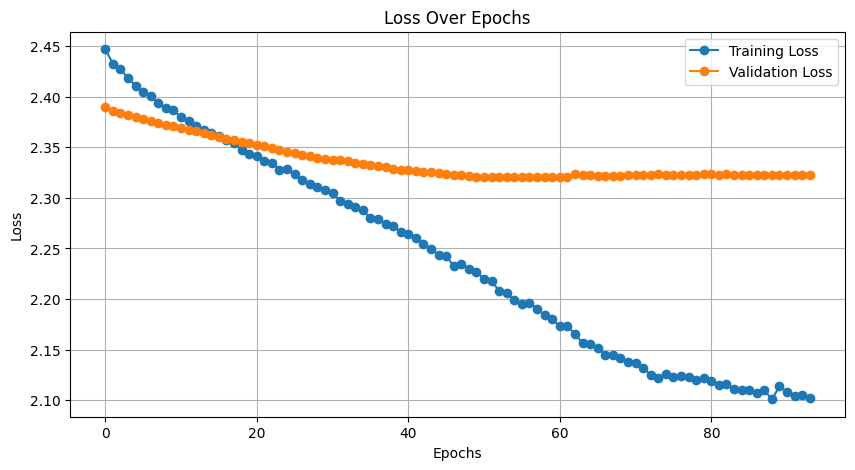

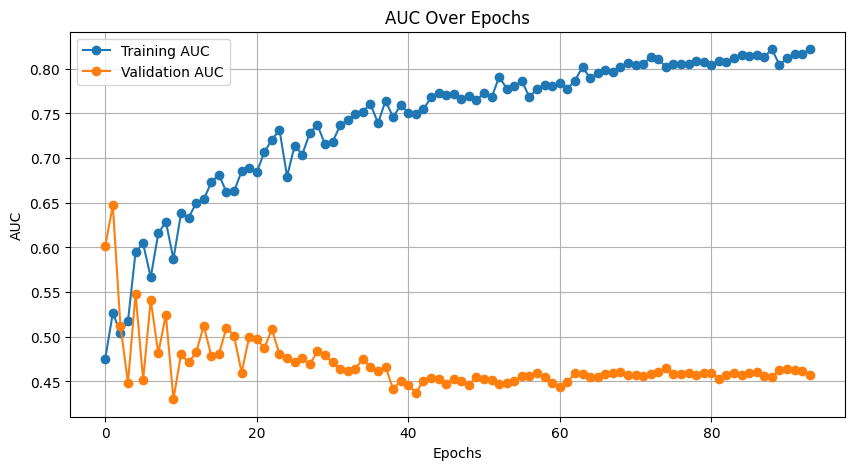



print_and_save_for
ticker data: TSLA


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
972        High-Low-Ratio  High-Open-Ratio  Close-O...   
973        High-Low-Ratio  High-Open-Ratio  Close-O...   
974        High-Low-Ratio  High-Open-Ratio  Close-O...   
975        High-Low-Ratio  High-Open-Ratio  Close-O...   
976        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2020-11-11 00:00:00-05:00       0       0         0.001118   
1    2020-11-12 00:00:00-05:00       0       0         0.001118   
2    2020-11-13 00:00:00-05:00       0     

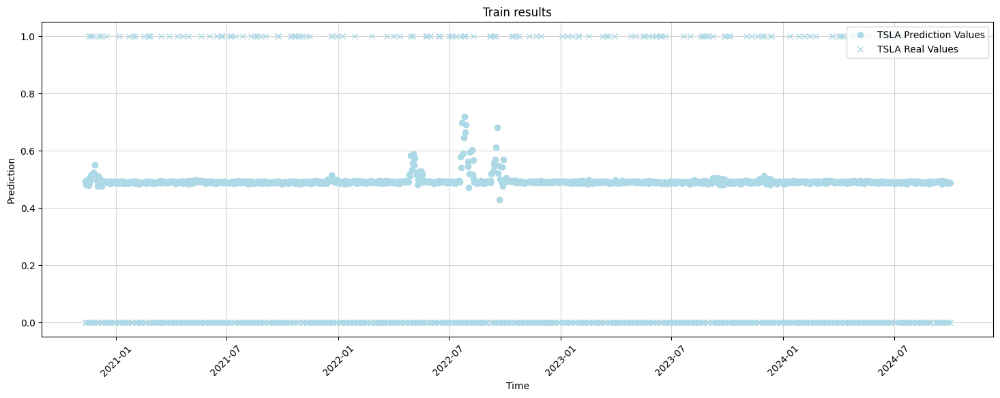

DONE PLOTTING 




print_and_save_for
ticker data: TSLA


Here is the data:                                                LstmData  \
977         High-Low-Ratio  High-Open-Ratio  Close-O...   
978         High-Low-Ratio  High-Open-Ratio  Close-O...   
979         High-Low-Ratio  High-Open-Ratio  Close-O...   
980         High-Low-Ratio  High-Open-Ratio  Close-O...   
981         High-Low-Ratio  High-Open-Ratio  Close-O...   
...                                                 ...   
1035        High-Low-Ratio  High-Open-Ratio  Close-O...   
1036        High-Low-Ratio  High-Open-Ratio  Close-O...   
1037        High-Low-Ratio  High-Open-Ratio  Close-O...   
1038        High-Low-Ratio  High-Open-Ratio  Close-O...   
1039        High-Low-Ratio  High-Open-Ratio  Close-O...   

                           Date  Ticker  Sector  Target-20D-Mean  \
977   2024-10-02 00:00:00-04:00       0       0         0.001118   
978   2024-10-03 00:00:00-04:00       0       0         0.001118   
979   2024-

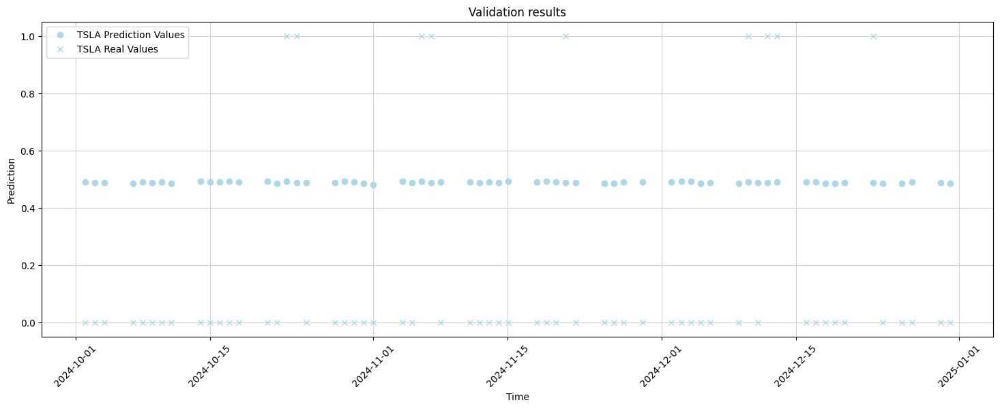

DONE PLOTTING 




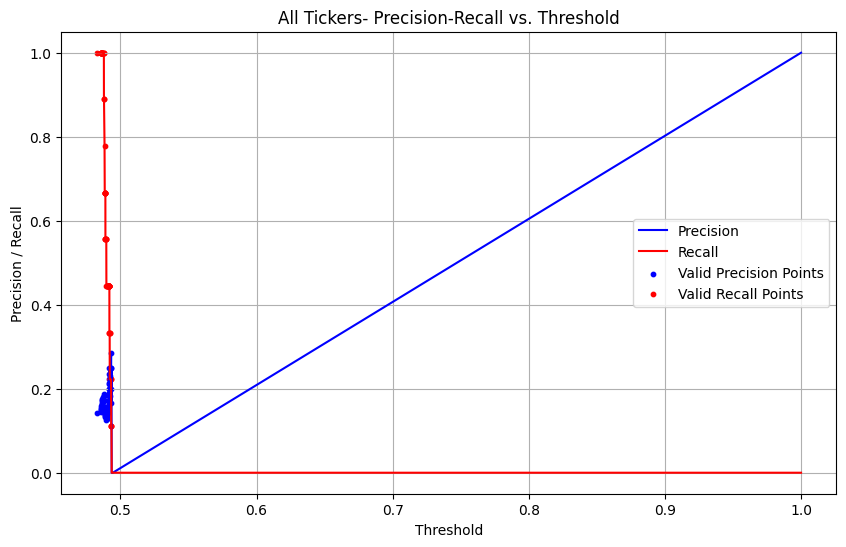

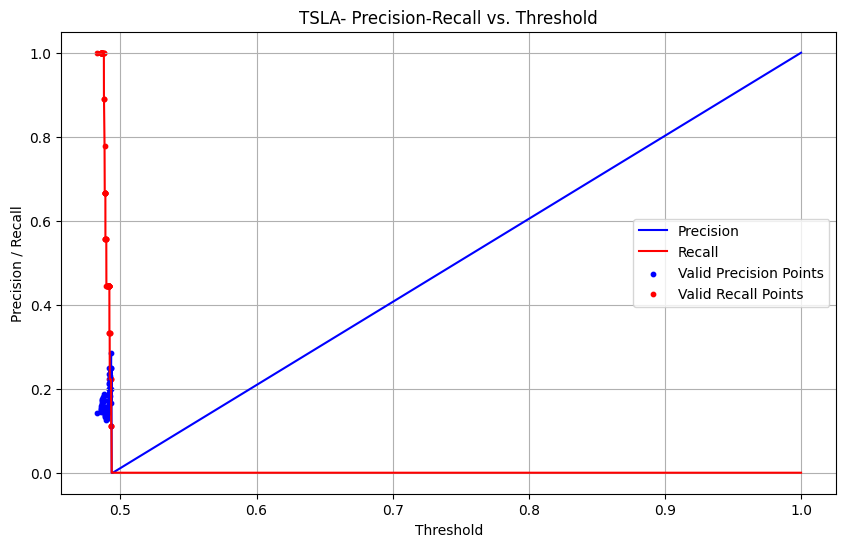

[0.         0.00122699 0.00490798 0.00490798 0.00981595 0.00981595
 0.01349693 0.01349693 0.01472393 0.01472393 0.03312883 0.03312883
 0.0404908  0.0404908  0.04294479 0.04294479 0.04417178 0.04417178
 0.04907975 0.04907975 0.06134969 0.06134969 0.06257669 0.06257669
 0.06380368 0.06380368 0.07239264 0.07239264 0.0797546  0.0797546
 0.08343558 0.08343558 0.08588957 0.08588957 0.08834356 0.08834356
 0.09570552 0.09570552 0.10184049 0.10184049 0.11042945 0.11042945
 0.11656442 0.11656442 0.13128834 0.13128834 0.13251534 0.13251534
 0.13619632 0.13619632 0.13742331 0.13742331 0.14601227 0.14601227
 0.15460123 0.15460123 0.15705521 0.15705521 0.17055215 0.17055215
 0.18282209 0.18282209 0.18773006 0.18773006 0.20490798 0.20490798
 0.20613497 0.20613497 0.20736196 0.20736196 0.20981595 0.20981595
 0.21349693 0.21349693 0.2196319  0.2196319  0.22208589 0.22208589
 0.23312883 0.23312883 0.23803681 0.23803681 0.24662577 0.24662577
 0.24907975 0.25276074 0.25276074 0.2601227  0.2601227  0.26257

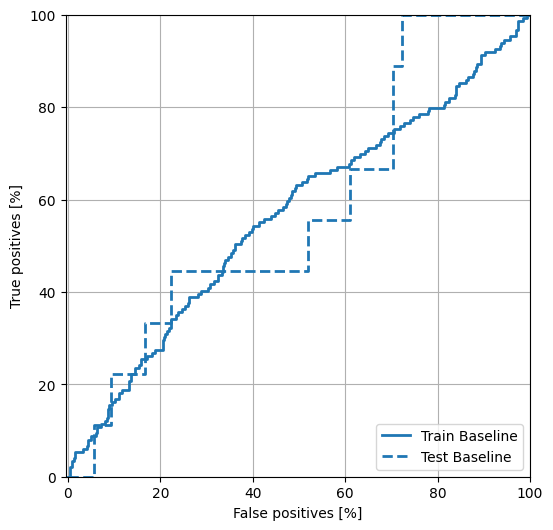

Best threshold: 0.4918351173400879
Number of true positives for the given ticker: 3
Number of false positives for the given ticker: 12
Precision score: 0.2
Recall score: 0.3333333333333333
Random guess score: 0.14285714285714285
true-positive per ticker: Orig_Ticker
TSLA    3
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
TSLA    12
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
TSLA    6
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
TSLA    0.2
dtype: float64
recall per ticker: Orig_Ticker
TSLA    0.333333
dtype: float64
rand guess per ticker: Orig_Ticker
TSLA    0.142857
dtype: float64
Some true positives
                           Date Orig_Ticker  y-predict-original  \
992   2024-10-23 00:00:00-04:00        TSLA            0.493356   
1002  2024-11-06 00:00:00-05:00        TSLA            0.493098   
1025  2024-12-10 00:00:00-05:00        TSLA            0.492059   

      y-value-original  Target-20D-Mean 

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[1 0 0 0 0 0 0 0 1 1 1 1 0 1 0 1 0 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0 1 0 1 0 0
 0 0 0 0 0 0 1 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 0 0 0 0 0 1 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = v

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['TSLA'] UNDERLYING_TARGET: Next-Day-Close-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:33 mode: medium LR_RATE: 0.0005 STARTING_LR: 0.0001
fetch_finance_data_for_tickers: just returning file name: TSLA for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode medium is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode medium is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, b

{'TSLA': 0}
{'Auto Tech': 0}
size before sigma app: 1025 for ticker: TSLA mean: 0.0011176336951166338, sigma: 0.028529713944736745 upper_bound: 0.08670677552932687 lower_bound: -0.0844715081390936
size after sigma app: 1012 for ticker: TSLA
0      1.0
1      1.0
2      0.0
4      0.0
5      0.0
      ... 
956    0.0
957    0.0
958    0.0
959    0.0
960    0.0
Name: y-value, Length: 948, dtype: float64
0      1.0
1      1.0
2      0.0
4      0.0
5      0.0
      ... 
956    0.0
957    0.0
958    0.0
959    0.0
960    0.0
Name: y-value-original, Length: 948, dtype: float64
High-Low-Ratio                               6.515334e-01
High-Open-Ratio                              5.000000e-01
Close-Open-Ratio                             3.863924e-01
Close-Prev-Close                             3.968271e-01
MACD-Prev-MACD                               2.146324e-01
200D-Ratio                                   8.786384e-01
MACD_SIG                                     4.467693e-01
MFI3            

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 33, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 31, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_6 (PReLU)   │ (None, 31, 256)   │        256 │ conv1d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 15, 256)   │    196,864 │ p_re_lu_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_7 (PReLU)   │ (None, 15, 256)   │        256 │ conv1d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 7, 512)    │    393,728 │ p_re_lu_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_8 (PReLU)   │ (None, 7, 512)    │        512 │ conv1d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 3, 512)    │    786,944 │ p_re_lu_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_9 (PReLU)   │ (None, 3, 512)    │        512 │ conv1d_7[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 1, 1024)   │  1,573,888 │ p_re_lu_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_10 (PReLU)  │ (None, 1, 1024)   │      1,024 │ conv1d_8[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_2 (Reshape) │ (None, 512)       │          0 │ stock_embedding[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 1024)      │          0 │ p_re_lu_10[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_3 (Reshape) │ (None, 128)       │          0 │ sector_embedding… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 1536)      │          0 │ flatten_2[0][0],  │
│ (Concatenate)       │                   │            │ stock_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_dense        │ (None, 256)       │     33,024 │ reshape_3[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 7,696,364 (29.36 MB)

 Trainable params: 7,696,364 (29.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 7s 500ms/step - AUC: 0.5019 - Precision: 0.1351 - Recall: 0.5967 - all_positives: 19.3397 - f1_score_metric: 23.7501 - loss: 2.1905 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 1463.4152 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 1463.4152 - val_AUC: 0.4753 - val_Precision: 0.1429 - val_Recall: 1.0000 - val_all_positives: 9.0000 - val_f1_score_metric: 15.7500 - val_loss: 2.1399 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 567.0001 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 567.0000 - learning_rate: 1.0000e-04
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 279ms/step - AUC: 0.5516 - Precision: 0.1480 - Recall: 0.9824 - all_positives: 17.5487 - f1_score_metric: 30.2245 - loss: 2.1023 - precision_with_threshold_fixed: 5.3466 - recall_mul_prediction: 2064.0251 - recall_with_threshold_fixed: 0.2114 - true_positives: 2064.0251 - val_AUC: 0.5895 - val_Precision: 0.

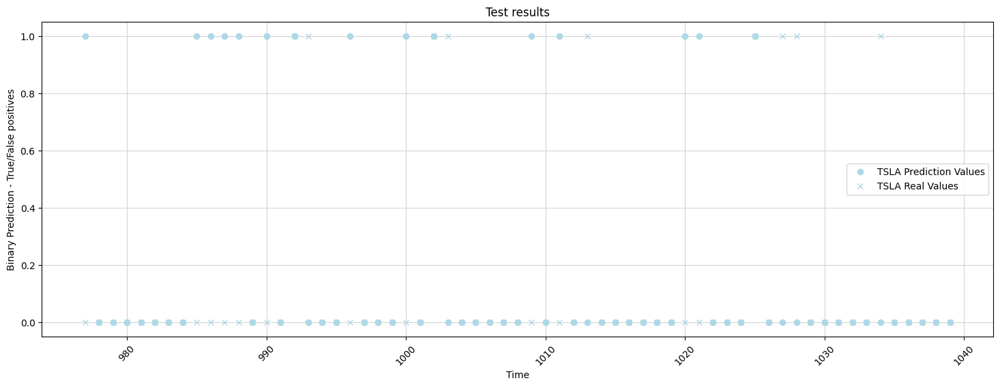

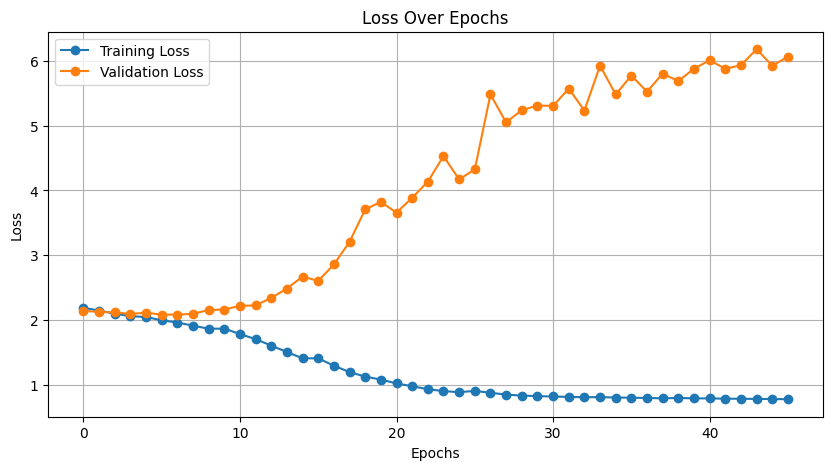

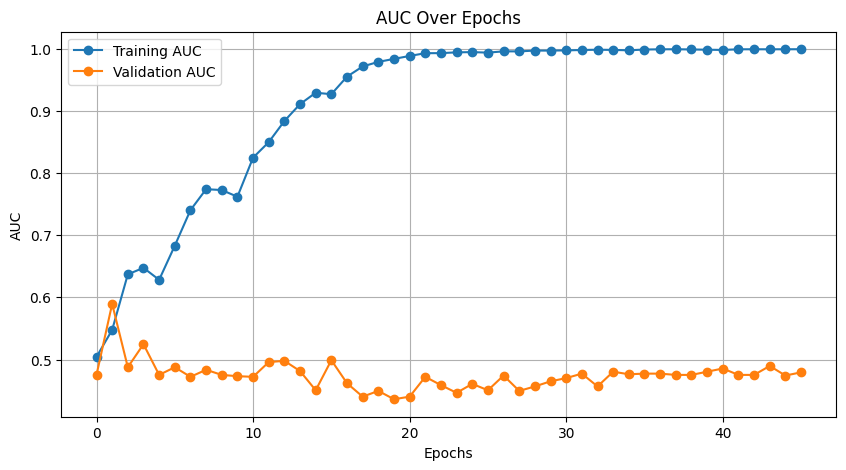



print_and_save_for
ticker data: TSLA


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
5         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
956        High-Low-Ratio  High-Open-Ratio  Close-O...   
957        High-Low-Ratio  High-Open-Ratio  Close-O...   
958        High-Low-Ratio  High-Open-Ratio  Close-O...   
959        High-Low-Ratio  High-Open-Ratio  Close-O...   
960        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2020-12-04 00:00:00-05:00       0       0         0.001118   
1    2020-12-07 00:00:00-05:00       0       0         0.001118   
2    2020-12-08 00:00:00-05:00       0     

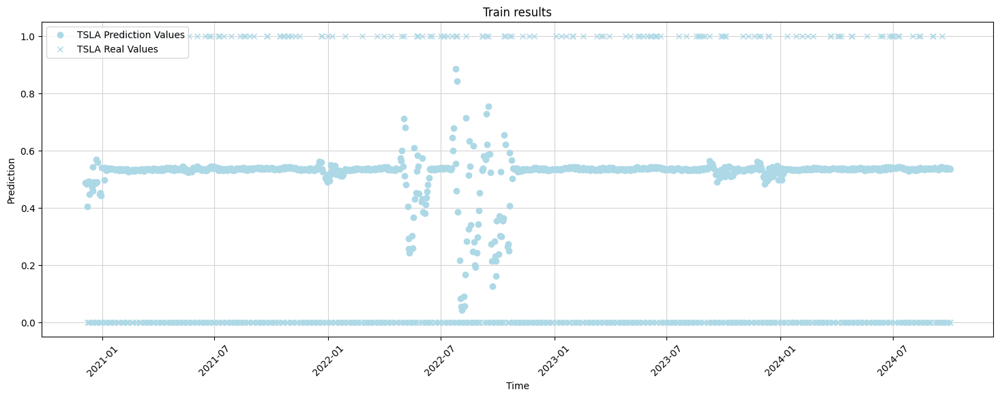

DONE PLOTTING 




print_and_save_for
ticker data: TSLA


Here is the data:                                                LstmData  \
961         High-Low-Ratio  High-Open-Ratio  Close-O...   
962         High-Low-Ratio  High-Open-Ratio  Close-O...   
963         High-Low-Ratio  High-Open-Ratio  Close-O...   
964         High-Low-Ratio  High-Open-Ratio  Close-O...   
965         High-Low-Ratio  High-Open-Ratio  Close-O...   
...                                                 ...   
1019        High-Low-Ratio  High-Open-Ratio  Close-O...   
1020        High-Low-Ratio  High-Open-Ratio  Close-O...   
1021        High-Low-Ratio  High-Open-Ratio  Close-O...   
1022        High-Low-Ratio  High-Open-Ratio  Close-O...   
1023        High-Low-Ratio  High-Open-Ratio  Close-O...   

                           Date  Ticker  Sector  Target-20D-Mean  \
961   2024-10-02 00:00:00-04:00       0       0         0.001118   
962   2024-10-03 00:00:00-04:00       0       0         0.001118   
963   2024-

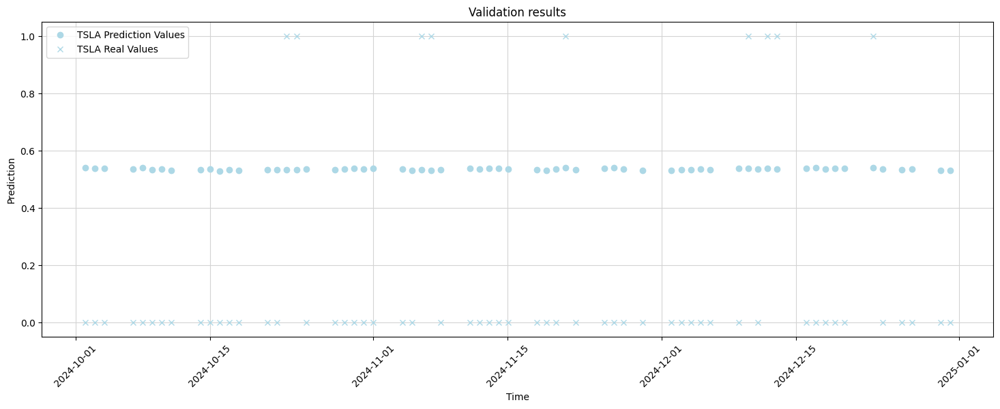

DONE PLOTTING 




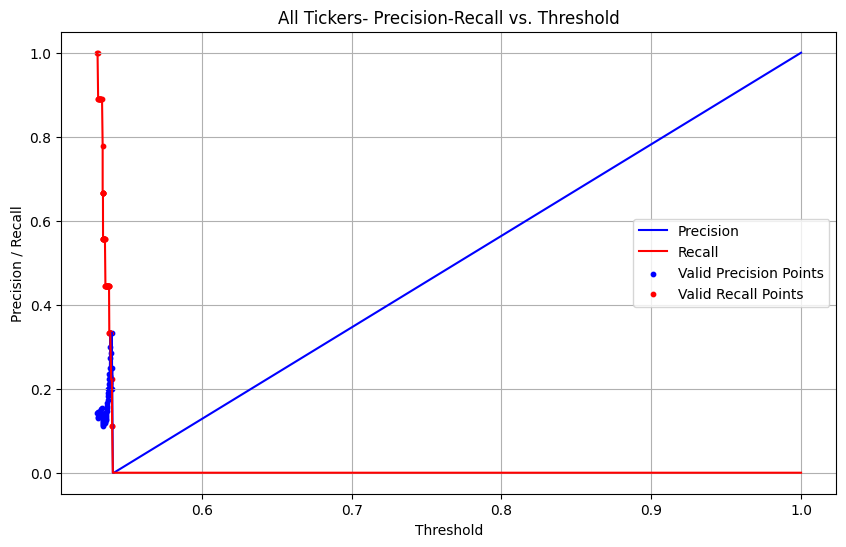

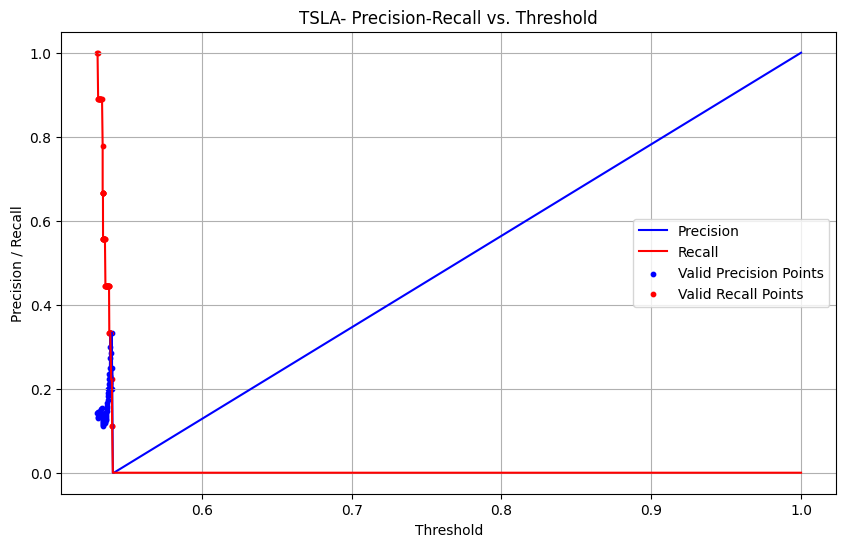

[0.         0.         0.         0.00249377 0.00249377 0.00498753
 0.00498753 0.0074813  0.0074813  0.00872818 0.00872818 0.01122195
 0.01122195 0.01371571 0.01371571 0.01620948 0.01620948 0.01745636
 0.01745636 0.02119701 0.02119701 0.03366584 0.03366584 0.0361596
 0.0361596  0.03740648 0.03740648 0.03990025 0.03990025 0.04114713
 0.04114713 0.0436409  0.0436409  0.04613466 0.04613466 0.04738155
 0.04738155 0.04987531 0.04987531 0.05236908 0.05236908 0.05486284
 0.05486284 0.05860349 0.05860349 0.06359102 0.06359102 0.06483791
 0.06483791 0.06733167 0.06733167 0.07730673 0.07730673 0.0798005
 0.0798005  0.09226933 0.09226933 0.09600998 0.09600998 0.09725686
 0.09725686 0.10099751 0.10099751 0.10349127 0.10349127 0.10598504
 0.10598504 0.1084788  0.1084788  0.10972569 0.10972569 0.1159601
 0.1159601  0.12967581 0.12967581 0.14214464 0.14214464 0.14339152
 0.14339152 0.1446384  0.1446384  0.15336658 0.15336658 0.15461347
 0.15461347 0.16084788 0.16084788 0.16209476 0.16209476 0.1645885

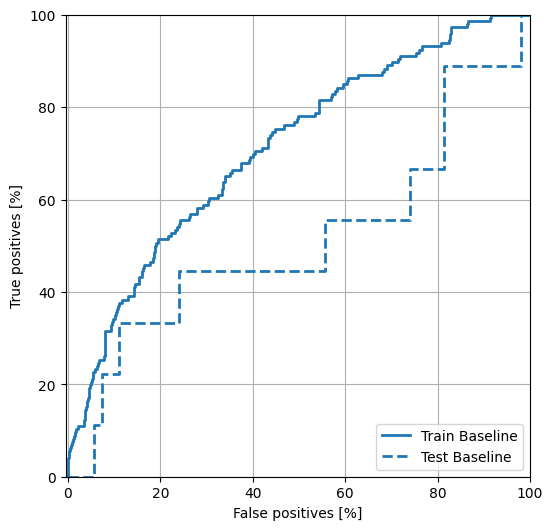

Best threshold: 0.5389059782028198
Number of true positives for the given ticker: 2
Number of false positives for the given ticker: 6
Precision score: 0.25
Recall score: 0.2222222222222222
Random guess score: 0.14285714285714285
true-positive per ticker: Orig_Ticker
TSLA    2
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
TSLA    6
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
TSLA    7
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
TSLA    0.25
dtype: float64
recall per ticker: Orig_Ticker
TSLA    0.222222
dtype: float64
rand guess per ticker: Orig_Ticker
TSLA    0.142857
dtype: float64
Some true positives
                           Date Orig_Ticker  y-predict-original  \
1018  2024-12-23 00:00:00-05:00        TSLA            0.540165   
997   2024-11-21 00:00:00-05:00        TSLA            0.539991   

      y-value-original  Target-20D-Mean  Target-20D-Sigma  
1018               1.0         0.001118        

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 1
 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 0 0 0 0 0 1 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = v

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['TSLA'] UNDERLYING_TARGET: Next-Day-Close-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:65 mode: complex LR_RATE: 0.0001 STARTING_LR: 0.001
fetch_finance_data_for_tickers: just returning file name: TSLA for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode complex is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode complex is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names,

{'TSLA': 0}
{'Auto Tech': 0}
size before sigma app: 993 for ticker: TSLA mean: 0.0011176336951166336, sigma: 0.02852971394473674 upper_bound: 0.08670677552932685 lower_bound: -0.08447150813909357
size after sigma app: 981 for ticker: TSLA
0      1.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
924    0.0
925    0.0
926    0.0
927    0.0
928    0.0
Name: y-value, Length: 917, dtype: float64
0      1.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
924    0.0
925    0.0
926    0.0
927    0.0
928    0.0
Name: y-value-original, Length: 917, dtype: float64
High-Low-Ratio                               6.515334e-01
High-Open-Ratio                              5.000000e-01
Close-Open-Ratio                             3.863924e-01
Close-Prev-Close                             3.968271e-01
MACD-Prev-MACD                               2.146324e-01
200D-Ratio                                   8.786384e-01
MACD_SIG                                     4.467693e-01
MFI3              

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 65, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_9 (Conv1D)   │ (None, 63, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_14 (PReLU)  │ (None, 63, 256)   │        256 │ conv1d_9[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_10 (Conv1D)  │ (None, 31, 256)   │    196,864 │ p_re_lu_14[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_15 (PReLU)  │ (None, 31, 256)   │        256 │ conv1d_10[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_11 (Conv1D)  │ (None, 15, 512)   │    393,728 │ p_re_lu_15[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_16 (PReLU)  │ (None, 15, 512)   │        512 │ conv1d_11[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_12 (Conv1D)  │ (None, 7, 512)    │    786,944 │ p_re_lu_16[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_17 (PReLU)  │ (None, 7, 512)    │        512 │ conv1d_12[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_13 (Conv1D)  │ (None, 3, 1024)   │  1,573,888 │ p_re_lu_17[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_18 (PReLU)  │ (None, 3, 1024)   │      1,024 │ conv1d_13[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_14 (Conv1D)  │ (None, 1, 1024)   │  3,146,752 │ p_re_lu_18[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_19 (PReLU)  │ (None, 1, 1024)   │      1,024 │ conv1d_14[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_4 (Reshape) │ (None, 512)       │          0 │ stock_embedding[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_4 (Flatten) │ (None, 1024)      │          0 │ p_re_lu_19[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_5 (Reshape) │ (None, 128)       │          0 │ sector_embedding… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 1536)      │          0 │ flatten_4[0][0],  │
│ (Concatenate)       │                   │            │ stock_dense[0][0

 Total params: 10,844,140 (41.37 MB)

 Trainable params: 10,844,140 (41.37 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 642ms/step - AUC: 0.4717 - Precision: 0.1436 - Recall: 0.5220 - all_positives: 21.2201 - f1_score_metric: 21.8100 - loss: 1.6722 - precision_with_threshold_fixed: 4.7095 - recall_mul_prediction: 1371.3162 - recall_with_threshold_fixed: 23.9571 - true_positives: 1371.3162 - val_AUC: 0.5000 - val_Precision: 0.1429 - val_Recall: 1.0000 - val_all_positives: 9.0000 - val_f1_score_metric: 15.7500 - val_loss: 1.4993 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 567.0001 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 567.0000 - learning_rate: 0.0010
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 336ms/step - AUC: 0.4249 - Precision: 0.1578 - Recall: 1.0000 - all_positives: 19.7331 - f1_score_metric: 34.0284 - loss: 1.5500 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2513.9438 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2513.9438 - val_AUC: 0.5000 - val_Precision: 0.142

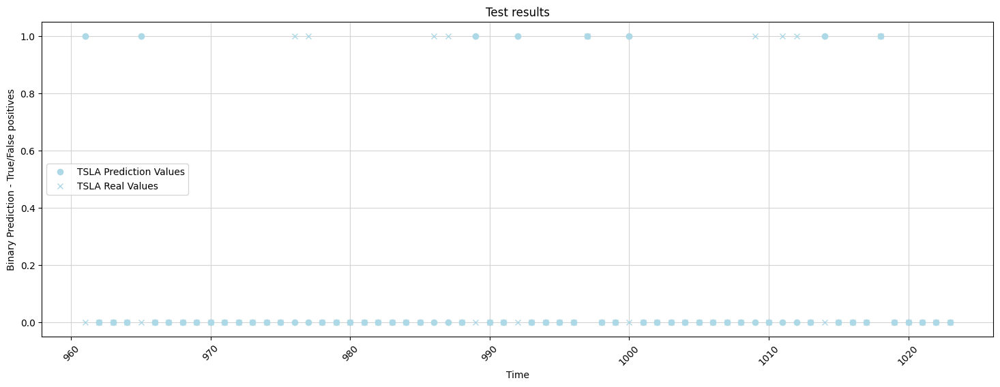

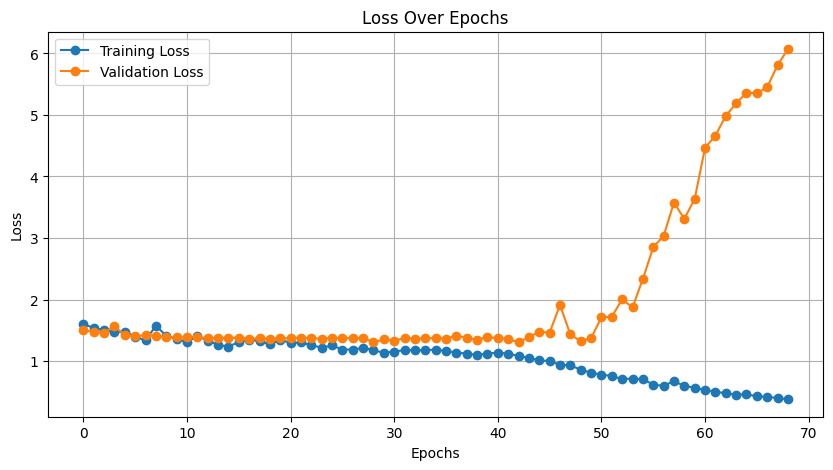

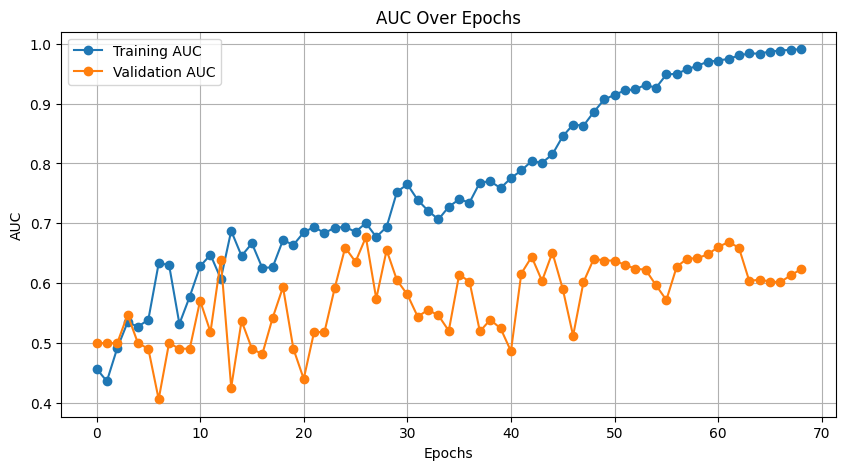



print_and_save_for
ticker data: TSLA


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
924        High-Low-Ratio  High-Open-Ratio  Close-O...   
925        High-Low-Ratio  High-Open-Ratio  Close-O...   
926        High-Low-Ratio  High-Open-Ratio  Close-O...   
927        High-Low-Ratio  High-Open-Ratio  Close-O...   
928        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2021-01-22 00:00:00-05:00       0       0         0.001118   
1    2021-01-25 00:00:00-05:00       0       0         0.001118   
2    2021-01-26 00:00:00-05:00       0     

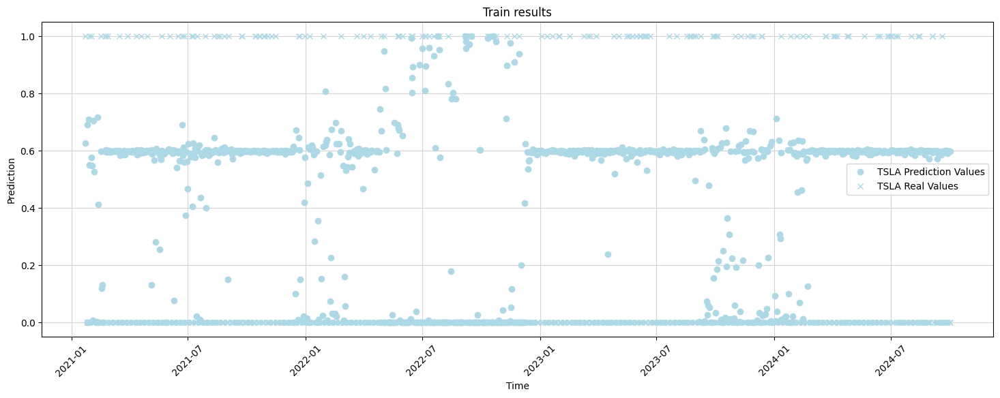

DONE PLOTTING 




print_and_save_for
ticker data: TSLA


Here is the data:                                               LstmData  \
929        High-Low-Ratio  High-Open-Ratio  Close-O...   
930        High-Low-Ratio  High-Open-Ratio  Close-O...   
931        High-Low-Ratio  High-Open-Ratio  Close-O...   
932        High-Low-Ratio  High-Open-Ratio  Close-O...   
933        High-Low-Ratio  High-Open-Ratio  Close-O...   
..                                                 ...   
987        High-Low-Ratio  High-Open-Ratio  Close-O...   
988        High-Low-Ratio  High-Open-Ratio  Close-O...   
989        High-Low-Ratio  High-Open-Ratio  Close-O...   
990        High-Low-Ratio  High-Open-Ratio  Close-O...   
991        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
929  2024-10-02 00:00:00-04:00       0       0         0.001118   
930  2024-10-03 00:00:00-04:00       0       0         0.001118   
931  2024-10-04 00:00:00-0

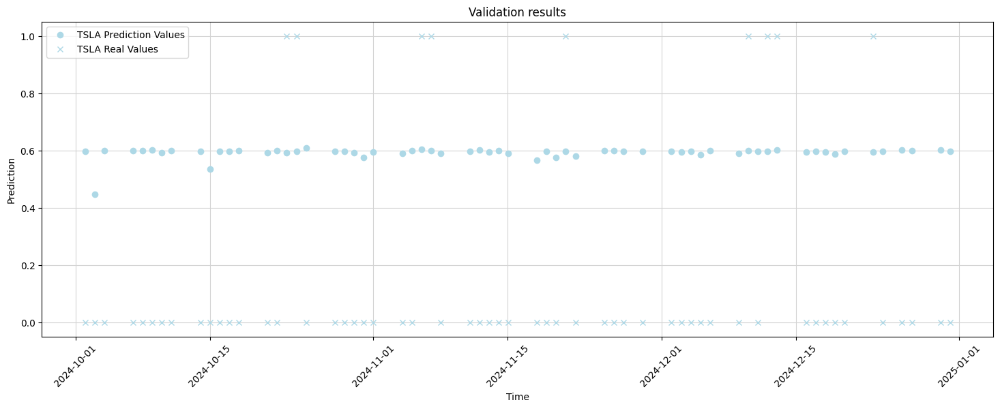

DONE PLOTTING 




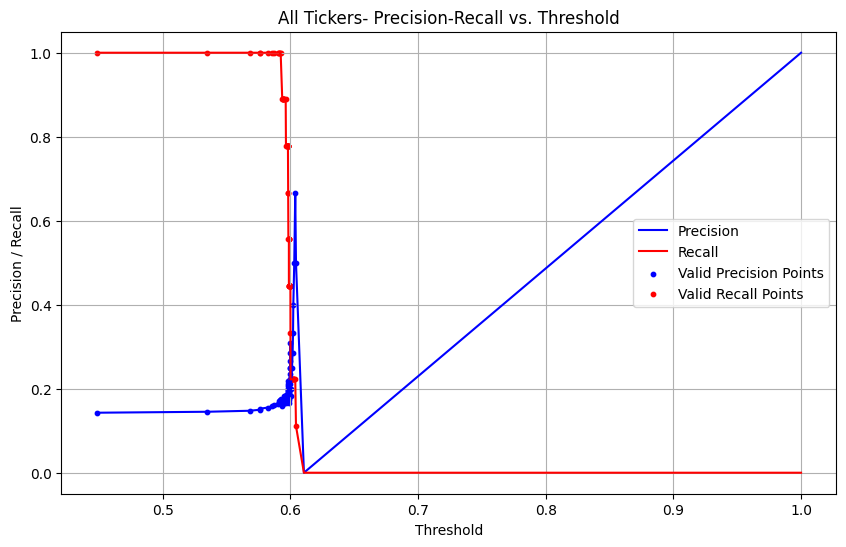

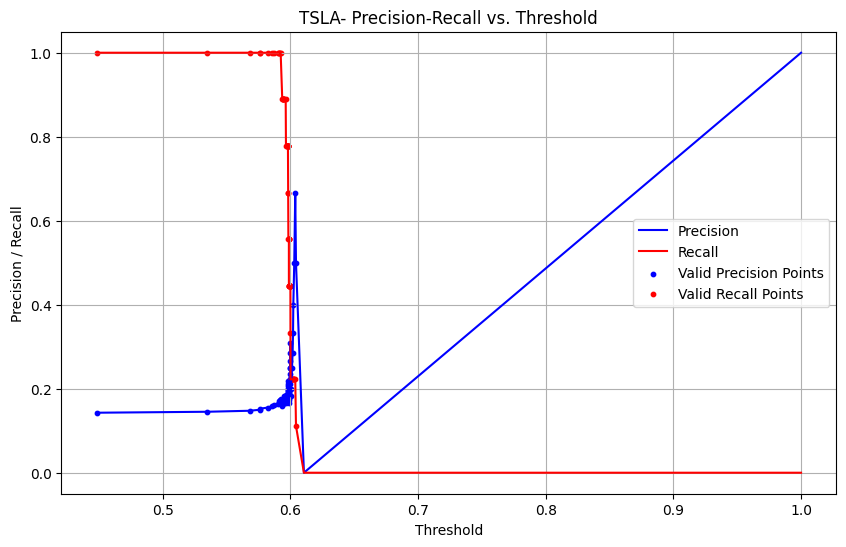

[0.         0.         0.         0.00129032 0.00129032 0.00258065
 0.00258065 0.00387097 0.00387097 0.00516129 0.00516129 0.02322581
 0.02322581 0.02580645 0.02580645 0.0283871  0.0283871  0.02967742
 0.02967742 0.03096774 0.03096774 0.04516129 0.04516129 0.05290323
 0.05290323 0.06064516 0.06064516 0.07483871 0.07483871 0.07612903
 0.07612903 0.07870968 0.07870968 0.08516129 0.08516129 0.08774194
 0.08774194 0.08903226 0.08903226 0.09032258 0.09032258 0.09290323
 0.09290323 0.09935484 0.09935484 0.10064516 0.10064516 0.10193548
 0.10193548 0.10580645 0.10580645 0.10967742 0.10967742 0.11741935
 0.11741935 0.12645161 0.12645161 0.12903226 0.12903226 0.1316129
 0.1316129  0.13806452 0.13806452 0.15096774 0.15096774 0.16129032
 0.16129032 0.16258065 0.16258065 0.18709677 0.18709677 0.1883871
 0.1883871  0.19870968 0.19870968 0.21032258 0.21032258 0.21548387
 0.21548387 0.21677419 0.21677419 0.22064516 0.22064516 0.22967742
 0.22967742 0.23483871 0.23483871 0.23870968 0.23870968 0.24
 0.

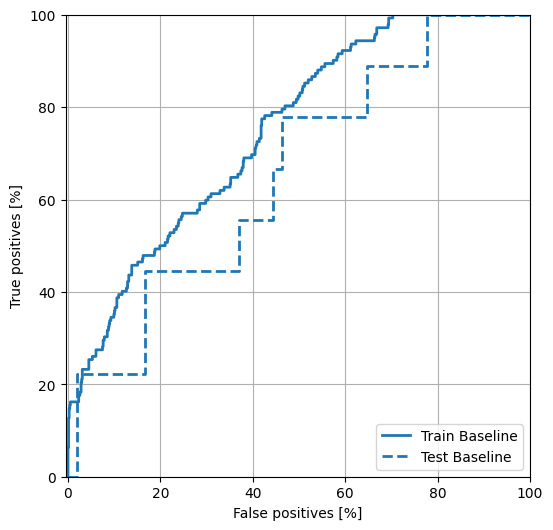

Best threshold: 0.60382080078125
Number of true positives for the given ticker: 1
Number of false positives for the given ticker: 1
Precision score: 0.5
Recall score: 0.1111111111111111
Random guess score: 0.14285714285714285
true-positive per ticker: Orig_Ticker
TSLA    1
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
TSLA    1
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
TSLA    8
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
TSLA    0.5
dtype: float64
recall per ticker: Orig_Ticker
TSLA    0.111111
dtype: float64
rand guess per ticker: Orig_Ticker
TSLA    0.142857
dtype: float64
Some true positives
                          Date Orig_Ticker  y-predict-original  \
954  2024-11-06 00:00:00-05:00        TSLA            0.604397   

     y-value-original  Target-20D-Mean  Target-20D-Sigma  
954               1.0         0.001118           0.02853  
Some false positives
                          Date Orig_Ticke

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 0 0 0 0 0 1 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = v

Trial 2: Validation Best metric: val_AUC = 0.6769547462463379
Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['TSLA'] UNDERLYING_TARGET: Next-Day-High-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:17 mode: simple LR_RATE: 0.001 STARTING_LR: 1e-05
fetch_finance_data_for_tickers: just returning file name: TSLA for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode simple is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode simple is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, b

{'TSLA': 0}
{'Auto Tech': 0}
size before sigma app: 1041 for ticker: TSLA mean: 0.022305356334566668, sigma: 0.018909837731215417 upper_bound: 0.07903486952821291 lower_bound: -0.03442415685907958
size after sigma app: 1025 for ticker: TSLA
0      0.0
1      0.0
2      0.0
3      0.0
5      0.0
      ... 
972    0.0
973    0.0
974    0.0
975    0.0
976    0.0
Name: y-value, Length: 962, dtype: float64
0      0.0
1      0.0
2      0.0
3      0.0
5      0.0
      ... 
972    0.0
973    0.0
974    0.0
975    0.0
976    0.0
Name: y-value-original, Length: 962, dtype: float64
High-Low-Ratio                               6.515334e-01
High-Open-Ratio                              5.000000e-01
Close-Open-Ratio                             3.863924e-01
Close-Prev-Close                             3.968271e-01
MACD-Prev-MACD                               2.146324e-01
200D-Ratio                                   8.786384e-01
MACD_SIG                                     4.467693e-01
MFI3            

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 17, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_15 (Conv1D)  │ (None, 15, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_23 (PReLU)  │ (None, 15, 256)   │        256 │ conv1d_15[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_16 (Conv1D)  │ (None, 7, 256)    │    196,864 │ p_re_lu_23[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_24 (PReLU)  │ (None, 7, 256)    │        256 │ conv1d_16[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_17 (Conv1D)  │ (None, 3, 512)    │    393,728 │ p_re_lu_24[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_25 (PReLU)  │ (None, 3, 512)    │        512 │ conv1d_17[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_18 (Conv1D)  │ (None, 1, 512)    │    786,944 │ p_re_lu_25[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_26 (PReLU)  │ (None, 1, 512)    │        512 │ conv1d_18[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_6 (Reshape) │ (None, 512)       │          0 │ stock_embedding[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_6 (Flatten) │ (None, 512)       │          0 │ p_re_lu_26[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_7 (Reshape) │ (None, 128)       │          0 │ sector_embedding… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_6       │ (None, 1024)      │          0 │ flatten_6[0][0],  │
│ (Concatenate)       │                   │            │ stock_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_dense        │ (None, 256)       │     33,024 │ reshape_7[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_7       │ (None, 1280)      │          0 │ concatenate_6[0]… │
│ (Concatenate)       │                   │            │ sector_dense[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 400)       │    512,400 │ concatenate_7[0]

 Total params: 2,247,451 (8.57 MB)

 Trainable params: 2,247,451 (8.57 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 7s 499ms/step - AUC: 0.5028 - Precision: 0.1691 - Recall: 0.0335 - all_positives: 16.8442 - f1_score_metric: 5.4886 - loss: 2.3893 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 58.7783 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 58.7783 - val_AUC: 0.5178 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_all_positives: 9.0000 - val_f1_score_metric: 0.0000e+00 - val_loss: 2.4329 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 0.0000e+00 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 0.0000e+00 - learning_rate: 1.0000e-05
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 255ms/step - AUC: 0.5674 - Precision: 0.1947 - Recall: 0.1895 - all_positives: 19.0296 - f1_score_metric: 17.4708 - loss: 2.4478 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 356.9608 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 356.9608 - val_AUC: 0.5189 - v

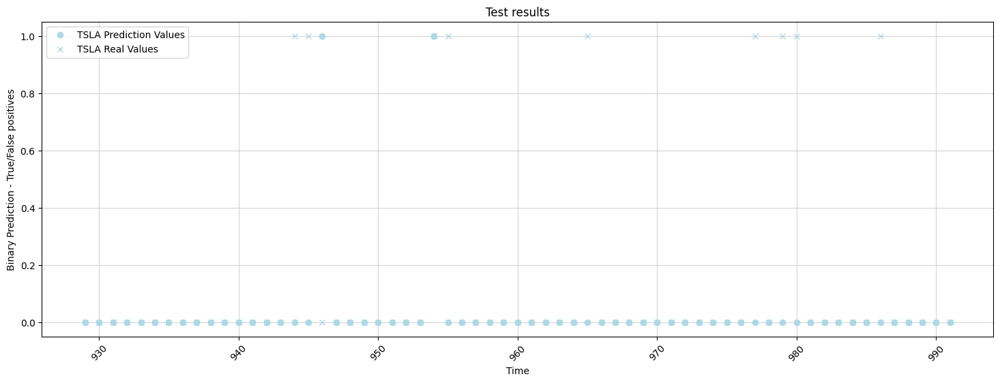

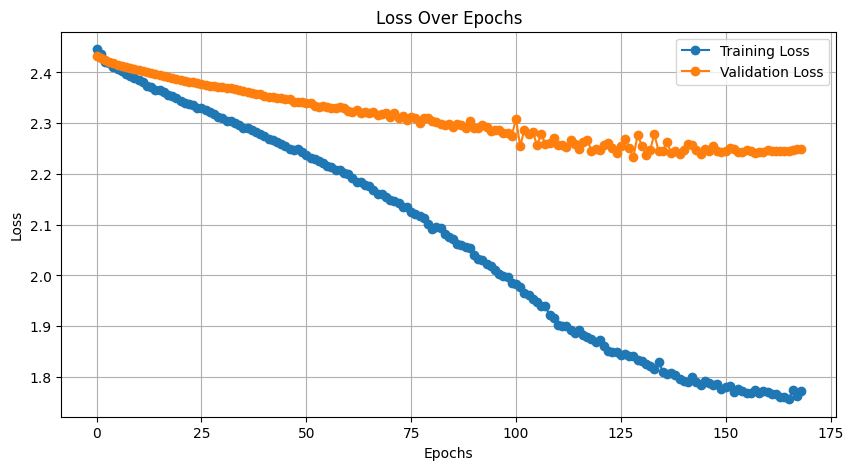

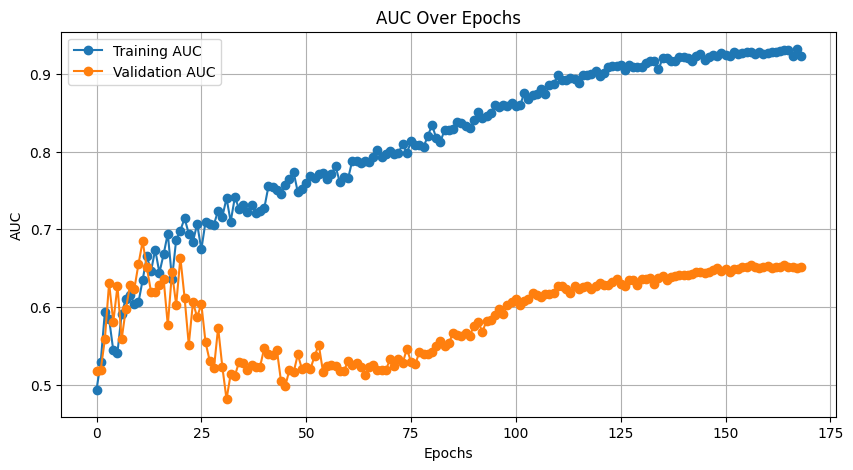



print_and_save_for
ticker data: TSLA


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
5         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
972        High-Low-Ratio  High-Open-Ratio  Close-O...   
973        High-Low-Ratio  High-Open-Ratio  Close-O...   
974        High-Low-Ratio  High-Open-Ratio  Close-O...   
975        High-Low-Ratio  High-Open-Ratio  Close-O...   
976        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2020-11-11 00:00:00-05:00       0       0         0.022305   
1    2020-11-12 00:00:00-05:00       0       0         0.022305   
2    2020-11-13 00:00:00-05:00       0     

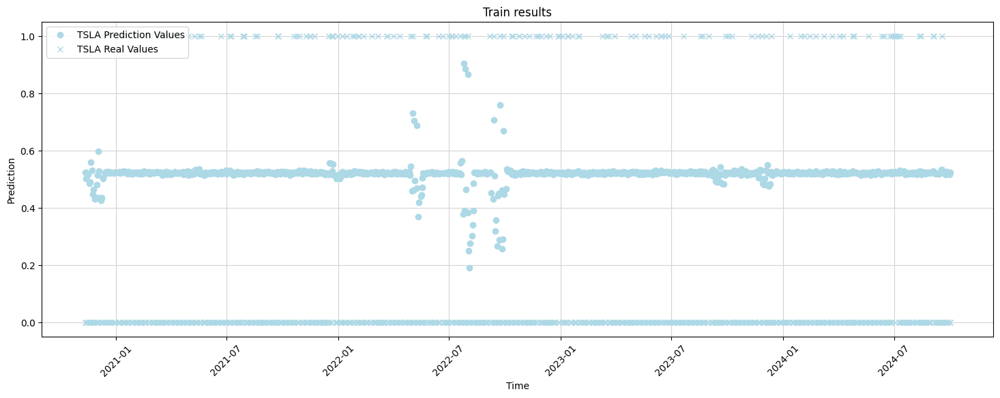

DONE PLOTTING 




print_and_save_for
ticker data: TSLA


Here is the data:                                                LstmData  \
977         High-Low-Ratio  High-Open-Ratio  Close-O...   
978         High-Low-Ratio  High-Open-Ratio  Close-O...   
979         High-Low-Ratio  High-Open-Ratio  Close-O...   
980         High-Low-Ratio  High-Open-Ratio  Close-O...   
981         High-Low-Ratio  High-Open-Ratio  Close-O...   
...                                                 ...   
1035        High-Low-Ratio  High-Open-Ratio  Close-O...   
1036        High-Low-Ratio  High-Open-Ratio  Close-O...   
1037        High-Low-Ratio  High-Open-Ratio  Close-O...   
1038        High-Low-Ratio  High-Open-Ratio  Close-O...   
1039        High-Low-Ratio  High-Open-Ratio  Close-O...   

                           Date  Ticker  Sector  Target-20D-Mean  \
977   2024-10-02 00:00:00-04:00       0       0         0.022305   
978   2024-10-03 00:00:00-04:00       0       0         0.022305   
979   2024-

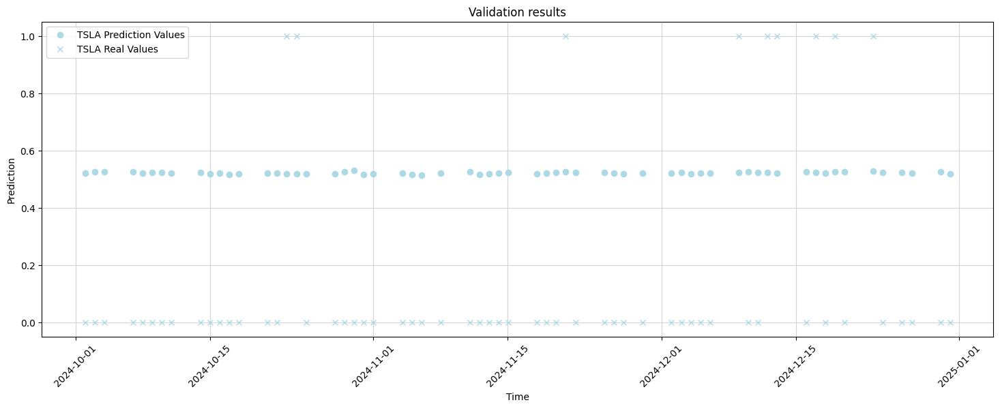

DONE PLOTTING 




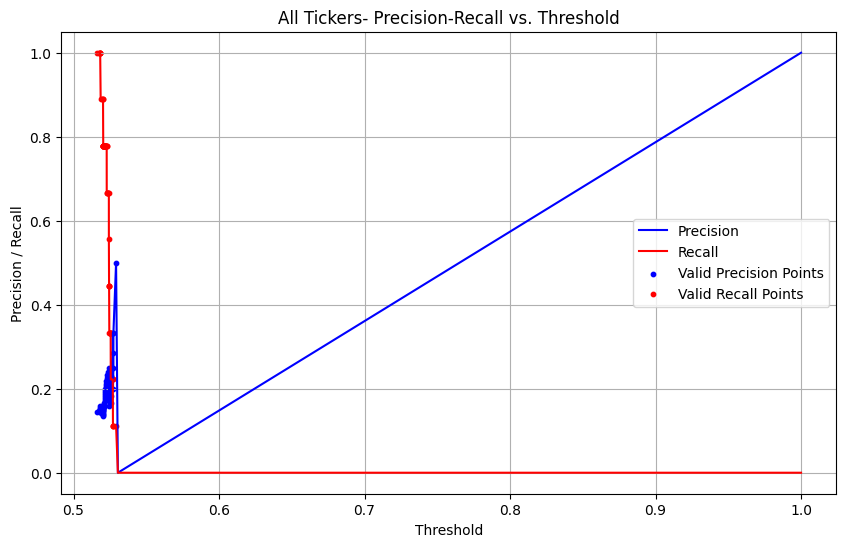

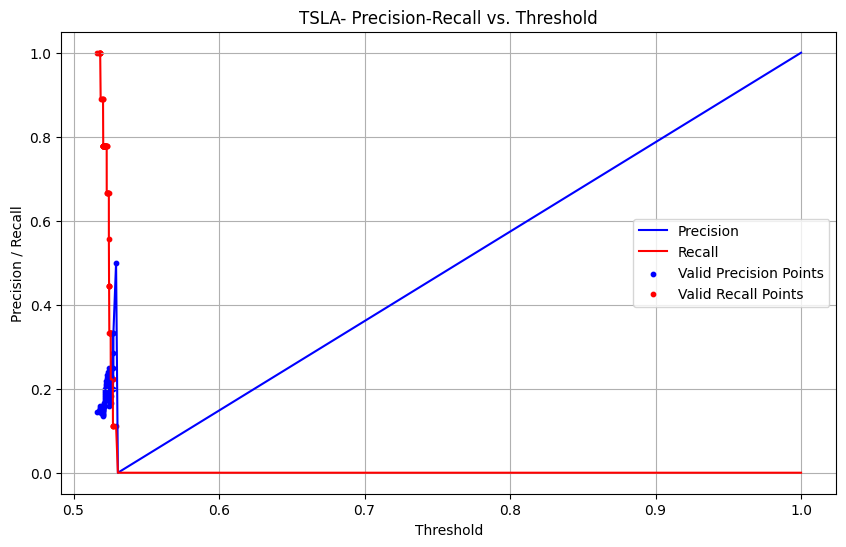

[0.         0.         0.         0.00243605 0.00243605 0.00730816
 0.00730816 0.00852619 0.00852619 0.00974421 0.00974421 0.01218027
 0.01218027 0.01705238 0.01705238 0.0182704  0.0182704  0.02070646
 0.02070646 0.02557856 0.02557856 0.02801462 0.02801462 0.03045067
 0.03045067 0.03288672 0.03288672 0.03410475 0.03410475 0.03532278
 0.03532278 0.03775883 0.03775883 0.04263094 0.04263094 0.04384896
 0.04384896 0.04872107 0.04872107 0.05968331 0.05968331 0.06211937
 0.06211937 0.07186358 0.07186358 0.07551766 0.07551766 0.07673569
 0.07673569 0.08038977 0.08038977 0.08282582 0.08282582 0.0864799
 0.0864799  0.08769793 0.08769793 0.09135201 0.09135201 0.09500609
 0.09500609 0.09622412 0.09622412 0.09866017 0.09866017 0.10718636
 0.10718636 0.12545676 0.12545676 0.136419   0.136419   0.14738124
 0.14738124 0.16686967 0.16686967 0.1863581  0.18879415 0.19244823
 0.19244823 0.20950061 0.20950061 0.21559074 0.21559074 0.23142509
 0.23142509 0.24116931 0.24116931 0.24360536 0.24360536 0.24482

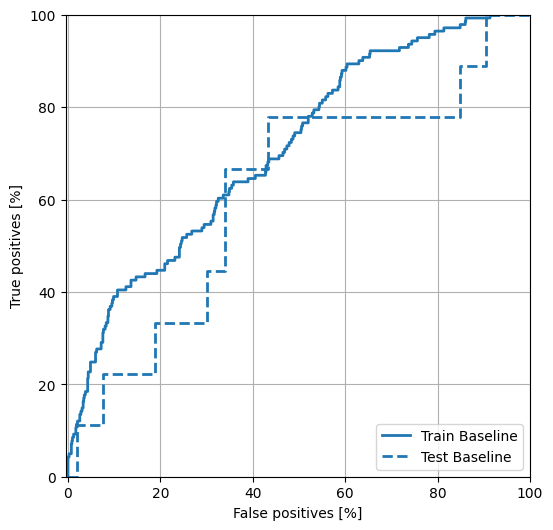

Best threshold: 0.5269784331321716
Number of true positives for the given ticker: 1
Number of false positives for the given ticker: 4
Precision score: 0.2
Recall score: 0.1111111111111111
Random guess score: 0.14516129032258066
true-positive per ticker: Orig_Ticker
TSLA    1
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
TSLA    4
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
TSLA    8
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
TSLA    0.2
dtype: float64
recall per ticker: Orig_Ticker
TSLA    0.111111
dtype: float64
rand guess per ticker: Orig_Ticker
TSLA    0.145161
dtype: float64
Some true positives
                           Date Orig_Ticker  y-predict-original  \
1034  2024-12-23 00:00:00-05:00        TSLA            0.529238   

      y-value-original  Target-20D-Mean  Target-20D-Sigma  
1034               1.0         0.022305           0.01891  
Some false positives
                           Date Ori

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 1 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0
 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0 1 0 1 0 1 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = valid

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['TSLA'] UNDERLYING_TARGET: Next-Day-High-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:33 mode: medium LR_RATE: 0.0005 STARTING_LR: 0.0001
fetch_finance_data_for_tickers: just returning file name: TSLA for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode medium is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode medium is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, b

{'TSLA': 0}
{'Auto Tech': 0}
size before sigma app: 1025 for ticker: TSLA mean: 0.022305356334566668, sigma: 0.018909837731215413 upper_bound: 0.07903486952821291 lower_bound: -0.03442415685907957
size after sigma app: 1010 for ticker: TSLA
0      1.0
1      0.0
2      0.0
4      0.0
5      0.0
      ... 
956    0.0
957    0.0
958    0.0
959    0.0
960    0.0
Name: y-value, Length: 947, dtype: float64
0      1.0
1      0.0
2      0.0
4      0.0
5      0.0
      ... 
956    0.0
957    0.0
958    0.0
959    0.0
960    0.0
Name: y-value-original, Length: 947, dtype: float64
High-Low-Ratio                               6.515334e-01
High-Open-Ratio                              5.000000e-01
Close-Open-Ratio                             3.863924e-01
Close-Prev-Close                             3.968271e-01
MACD-Prev-MACD                               2.146324e-01
200D-Ratio                                   8.786384e-01
MACD_SIG                                     4.467693e-01
MFI3            

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 33, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_19 (Conv1D)  │ (None, 31, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_29 (PReLU)  │ (None, 31, 256)   │        256 │ conv1d_19[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_20 (Conv1D)  │ (None, 15, 256)   │    196,864 │ p_re_lu_29[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_30 (PReLU)  │ (None, 15, 256)   │        256 │ conv1d_20[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_21 (Conv1D)  │ (None, 7, 512)    │    393,728 │ p_re_lu_30[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_31 (PReLU)  │ (None, 7, 512)    │        512 │ conv1d_21[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_22 (Conv1D)  │ (None, 3, 512)    │    786,944 │ p_re_lu_31[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_32 (PReLU)  │ (None, 3, 512)    │        512 │ conv1d_22[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_23 (Conv1D)  │ (None, 1, 1024)   │  1,573,888 │ p_re_lu_32[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_33 (PReLU)  │ (None, 1, 1024)   │      1,024 │ conv1d_23[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_8 (Reshape) │ (None, 512)       │          0 │ stock_embedding[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_8 (Flatten) │ (None, 1024)      │          0 │ p_re_lu_33[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_9 (Reshape) │ (None, 128)       │          0 │ sector_embedding… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_8       │ (None, 1536)      │          0 │ flatten_8[0][0],  │
│ (Concatenate)       │                   │            │ stock_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_dense        │ (None, 256)       │     33,024 │ reshape_9[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 7,696,364 (29.36 MB)

 Trainable params: 7,696,364 (29.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 705ms/step - AUC: 0.4407 - Precision: 0.1475 - Recall: 0.9386 - all_positives: 18.6979 - f1_score_metric: 31.6910 - loss: 2.2036 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2227.9363 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2227.9363 - val_AUC: 0.4560 - val_Precision: 0.1452 - val_Recall: 1.0000 - val_all_positives: 9.0000 - val_f1_score_metric: 15.7183 - val_loss: 2.1702 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 558.0000 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 558.0000 - learning_rate: 1.0000e-04
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 407ms/step - AUC: 0.5540 - Precision: 0.1453 - Recall: 0.9004 - all_positives: 18.2183 - f1_score_metric: 31.3297 - loss: 2.1496 - precision_with_threshold_fixed: 0.9947 - recall_mul_prediction: 2078.0610 - recall_with_threshold_fixed: 0.0622 - true_positives: 2078.0610 - val_AUC: 0.5818 - val_Precision: 0.

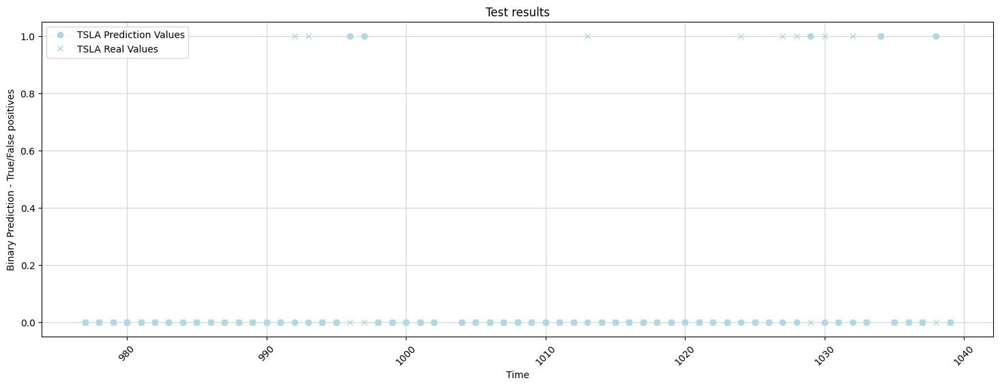

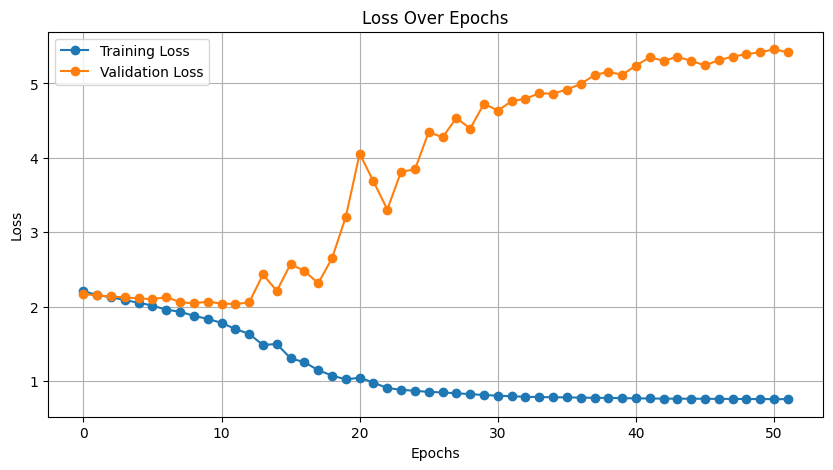

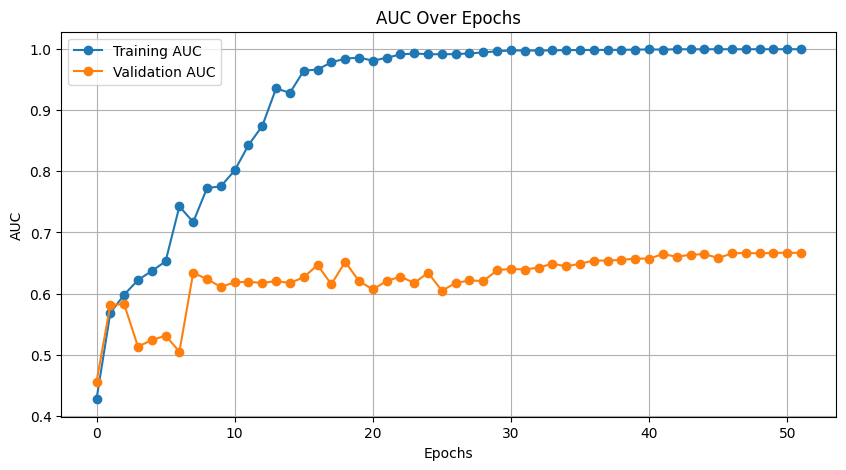



print_and_save_for
ticker data: TSLA


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
5         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
956        High-Low-Ratio  High-Open-Ratio  Close-O...   
957        High-Low-Ratio  High-Open-Ratio  Close-O...   
958        High-Low-Ratio  High-Open-Ratio  Close-O...   
959        High-Low-Ratio  High-Open-Ratio  Close-O...   
960        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2020-12-04 00:00:00-05:00       0       0         0.022305   
1    2020-12-07 00:00:00-05:00       0       0         0.022305   
2    2020-12-08 00:00:00-05:00       0     

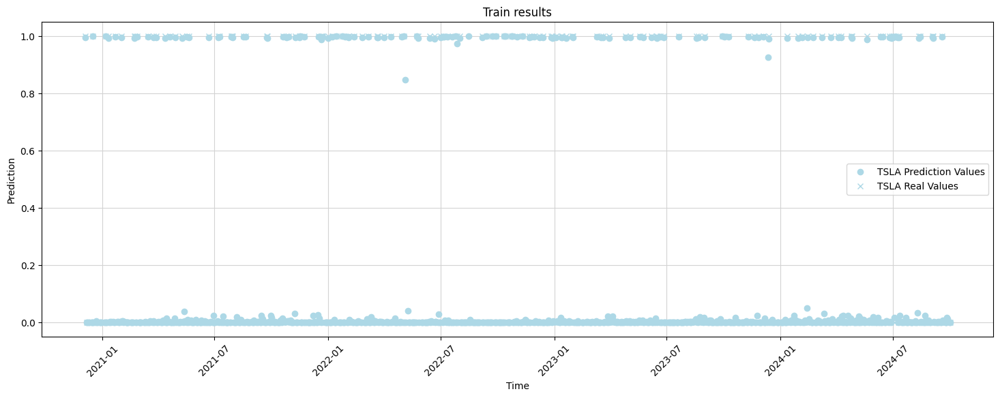

DONE PLOTTING 




print_and_save_for
ticker data: TSLA


Here is the data:                                                LstmData  \
961         High-Low-Ratio  High-Open-Ratio  Close-O...   
962         High-Low-Ratio  High-Open-Ratio  Close-O...   
963         High-Low-Ratio  High-Open-Ratio  Close-O...   
964         High-Low-Ratio  High-Open-Ratio  Close-O...   
965         High-Low-Ratio  High-Open-Ratio  Close-O...   
...                                                 ...   
1019        High-Low-Ratio  High-Open-Ratio  Close-O...   
1020        High-Low-Ratio  High-Open-Ratio  Close-O...   
1021        High-Low-Ratio  High-Open-Ratio  Close-O...   
1022        High-Low-Ratio  High-Open-Ratio  Close-O...   
1023        High-Low-Ratio  High-Open-Ratio  Close-O...   

                           Date  Ticker  Sector  Target-20D-Mean  \
961   2024-10-02 00:00:00-04:00       0       0         0.022305   
962   2024-10-03 00:00:00-04:00       0       0         0.022305   
963   2024-

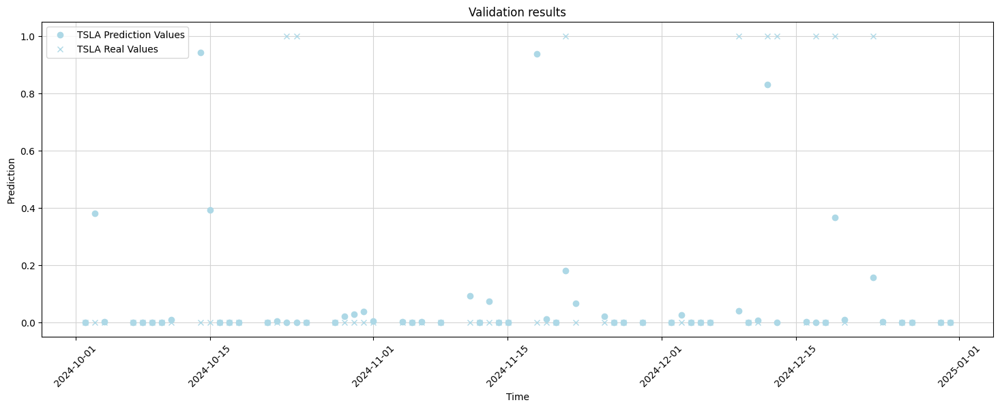

DONE PLOTTING 




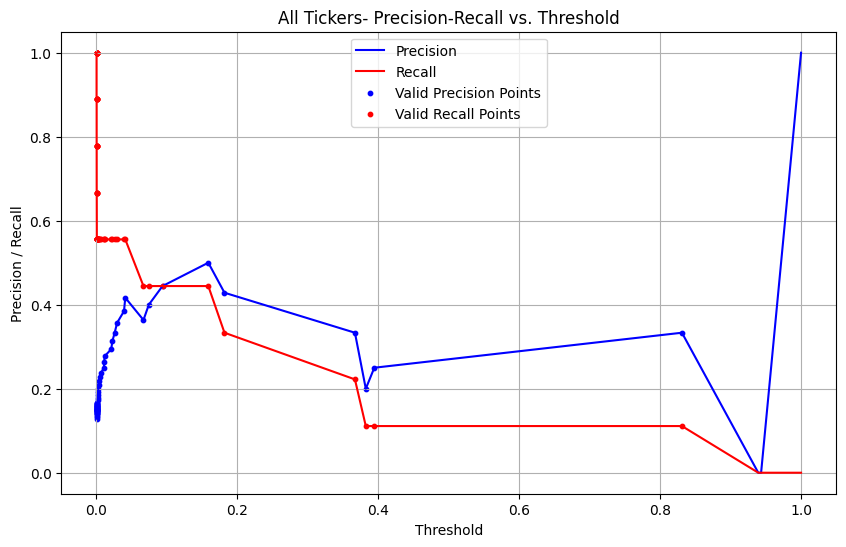

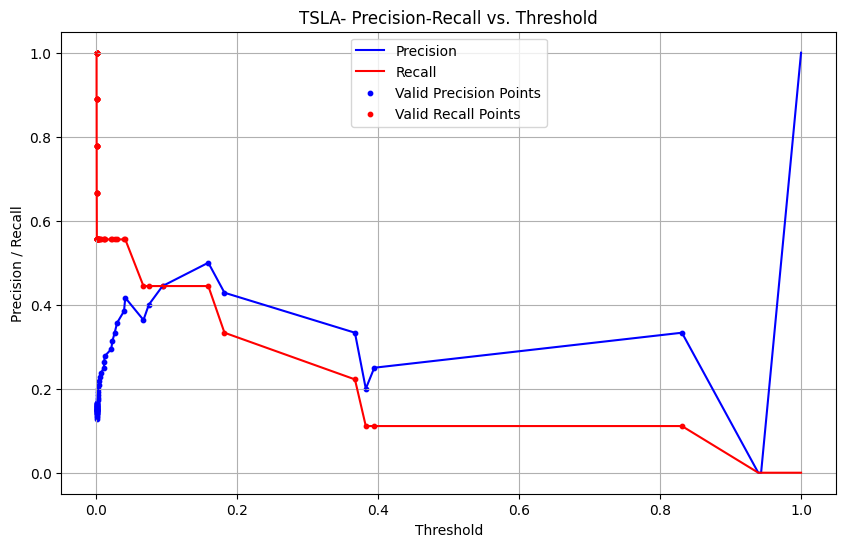

[0.         0.00124069 0.00124069 0.98759305 1.        ]
[0.        0.0212766 1.        1.        1.       ]
[0.         0.01886792 0.03773585 0.03773585 0.0754717  0.0754717
 0.13207547 0.13207547 0.64150943 0.64150943 0.69811321 0.69811321
 0.77358491 0.77358491 0.8490566  0.8490566  1.        ]
[0.         0.         0.         0.11111111 0.11111111 0.44444444
 0.44444444 0.55555556 0.55555556 0.66666667 0.66666667 0.77777778
 0.77777778 0.88888889 0.88888889 1.         1.        ]


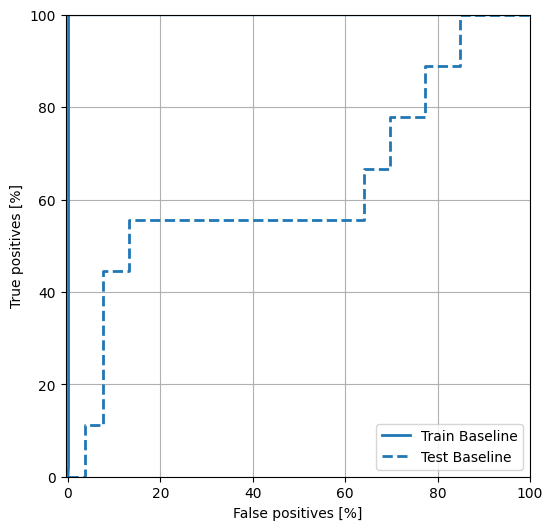

Best threshold: 0.15869870781898499
Number of true positives for the given ticker: 3
Number of false positives for the given ticker: 4
Precision score: 0.42857142857142855
Recall score: 0.3333333333333333
Random guess score: 0.14516129032258066
true-positive per ticker: Orig_Ticker
TSLA    3
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
TSLA    4
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
TSLA    6
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
TSLA    0.428571
dtype: float64
recall per ticker: Orig_Ticker
TSLA    0.333333
dtype: float64
rand guess per ticker: Orig_Ticker
TSLA    0.145161
dtype: float64
Some true positives
                           Date Orig_Ticker  y-predict-original  \
997   2024-11-21 00:00:00-05:00        TSLA            0.181634   
1011  2024-12-12 00:00:00-05:00        TSLA            0.830924   
1016  2024-12-19 00:00:00-05:00        TSLA            0.366806   

      y-value-origin

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 1 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0
 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0 1 0 1 0 1 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = valid

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['TSLA'] UNDERLYING_TARGET: Next-Day-High-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:65 mode: complex LR_RATE: 0.0001 STARTING_LR: 0.001
fetch_finance_data_for_tickers: just returning file name: TSLA for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode complex is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode complex is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names,

{'TSLA': 0}
{'Auto Tech': 0}
size before sigma app: 993 for ticker: TSLA mean: 0.022305356334566668, sigma: 0.018909837731215413 upper_bound: 0.07903486952821291 lower_bound: -0.03442415685907957
size after sigma app: 979 for ticker: TSLA
0      1.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
924    0.0
925    0.0
926    0.0
927    0.0
928    0.0
Name: y-value, Length: 916, dtype: float64
0      1.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
924    0.0
925    0.0
926    0.0
927    0.0
928    0.0
Name: y-value-original, Length: 916, dtype: float64
High-Low-Ratio                               6.515334e-01
High-Open-Ratio                              5.000000e-01
Close-Open-Ratio                             3.863924e-01
Close-Prev-Close                             3.968271e-01
MACD-Prev-MACD                               2.146324e-01
200D-Ratio                                   8.786384e-01
MACD_SIG                                     4.467693e-01
MFI3              

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 65, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_24 (Conv1D)  │ (None, 63, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_37 (PReLU)  │ (None, 63, 256)   │        256 │ conv1d_24[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_25 (Conv1D)  │ (None, 31, 256)   │    196,864 │ p_re_lu_37[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_38 (PReLU)  │ (None, 31, 256)   │        256 │ conv1d_25[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_26 (Conv1D)  │ (None, 15, 512)   │    393,728 │ p_re_lu_38[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_39 (PReLU)  │ (None, 15, 512)   │        512 │ conv1d_26[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_27 (Conv1D)  │ (None, 7, 512)    │    786,944 │ p_re_lu_39[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_40 (PReLU)  │ (None, 7, 512)    │        512 │ conv1d_27[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_28 (Conv1D)  │ (None, 3, 1024)   │  1,573,888 │ p_re_lu_40[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_41 (PReLU)  │ (None, 3, 1024)   │      1,024 │ conv1d_28[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_29 (Conv1D)  │ (None, 1, 1024)   │  3,146,752 │ p_re_lu_41[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_42 (PReLU)  │ (None, 1, 1024)   │      1,024 │ conv1d_29[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_10          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_10          │ (None, 1024)      │          0 │ p_re_lu_42[0][0]  │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_10[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_11          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                 

 Total params: 10,844,140 (41.37 MB)

 Trainable params: 10,844,140 (41.37 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 11s 818ms/step - AUC: 0.5007 - Precision: 0.1349 - Recall: 0.4155 - all_positives: 17.3138 - f1_score_metric: 19.8261 - loss: 1.5537 - precision_with_threshold_fixed: 6.2656 - recall_mul_prediction: 949.8091 - recall_with_threshold_fixed: 3.0820 - true_positives: 949.8090 - val_AUC: 0.5000 - val_Precision: 0.1452 - val_Recall: 1.0000 - val_all_positives: 9.0000 - val_f1_score_metric: 15.7183 - val_loss: 1.5931 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 558.0000 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 558.0000 - learning_rate: 0.0010
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 469ms/step - AUC: 0.4486 - Precision: 0.1560 - Recall: 1.0000 - all_positives: 19.4894 - f1_score_metric: 33.5138 - loss: 1.6143 - precision_with_threshold_fixed: 13.2683 - recall_mul_prediction: 2494.6455 - recall_with_threshold_fixed: 6.6016 - true_positives: 2494.6455 - val_AUC: 0.5000 - val_Precision: 0.0000e+00 - v

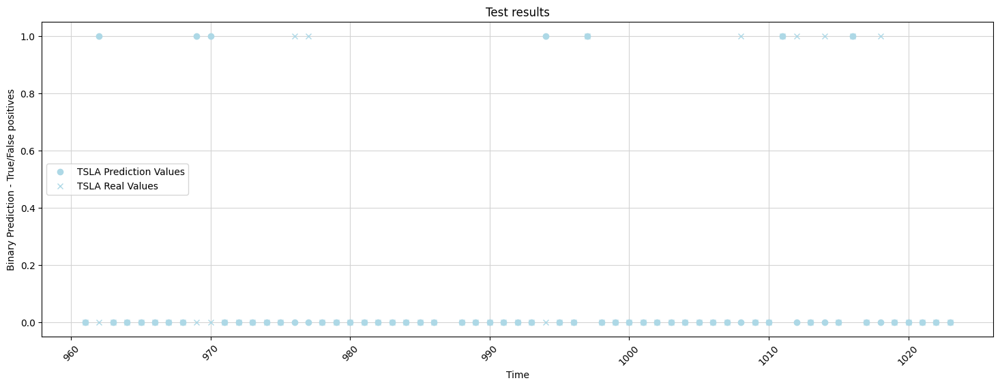

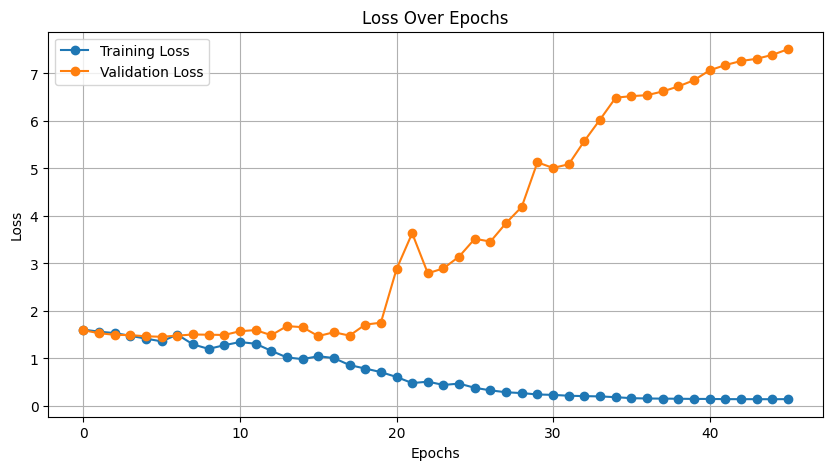

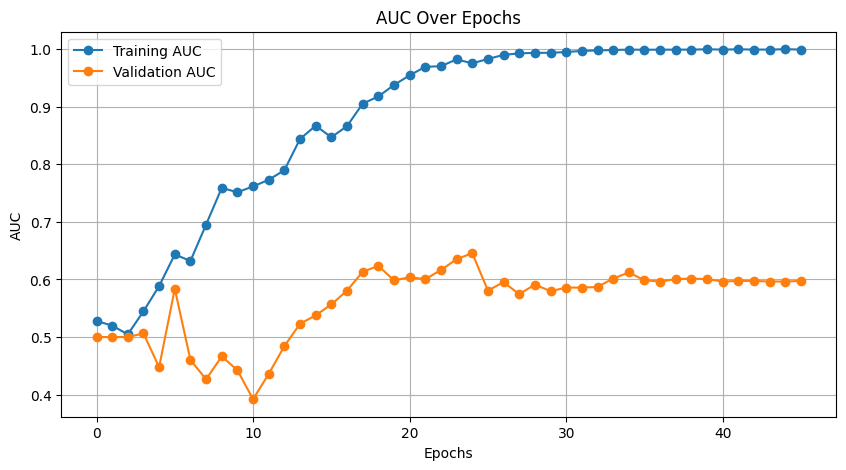



print_and_save_for
ticker data: TSLA


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
924        High-Low-Ratio  High-Open-Ratio  Close-O...   
925        High-Low-Ratio  High-Open-Ratio  Close-O...   
926        High-Low-Ratio  High-Open-Ratio  Close-O...   
927        High-Low-Ratio  High-Open-Ratio  Close-O...   
928        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2021-01-22 00:00:00-05:00       0       0         0.022305   
1    2021-01-25 00:00:00-05:00       0       0         0.022305   
2    2021-01-26 00:00:00-05:00       0     

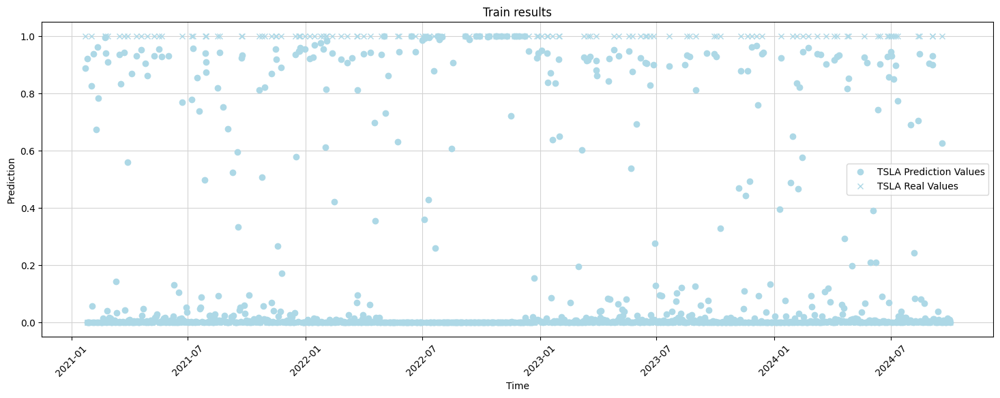

DONE PLOTTING 




print_and_save_for
ticker data: TSLA


Here is the data:                                               LstmData  \
929        High-Low-Ratio  High-Open-Ratio  Close-O...   
930        High-Low-Ratio  High-Open-Ratio  Close-O...   
931        High-Low-Ratio  High-Open-Ratio  Close-O...   
932        High-Low-Ratio  High-Open-Ratio  Close-O...   
933        High-Low-Ratio  High-Open-Ratio  Close-O...   
..                                                 ...   
987        High-Low-Ratio  High-Open-Ratio  Close-O...   
988        High-Low-Ratio  High-Open-Ratio  Close-O...   
989        High-Low-Ratio  High-Open-Ratio  Close-O...   
990        High-Low-Ratio  High-Open-Ratio  Close-O...   
991        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
929  2024-10-02 00:00:00-04:00       0       0         0.022305   
930  2024-10-03 00:00:00-04:00       0       0         0.022305   
931  2024-10-04 00:00:00-0

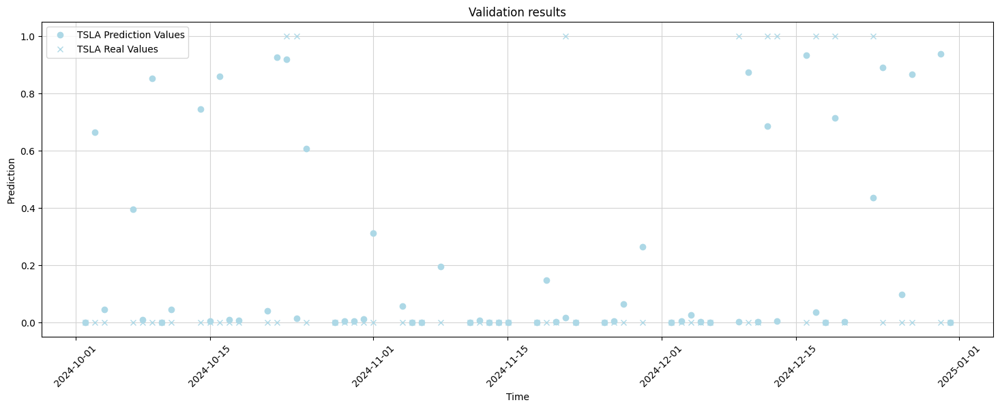

DONE PLOTTING 




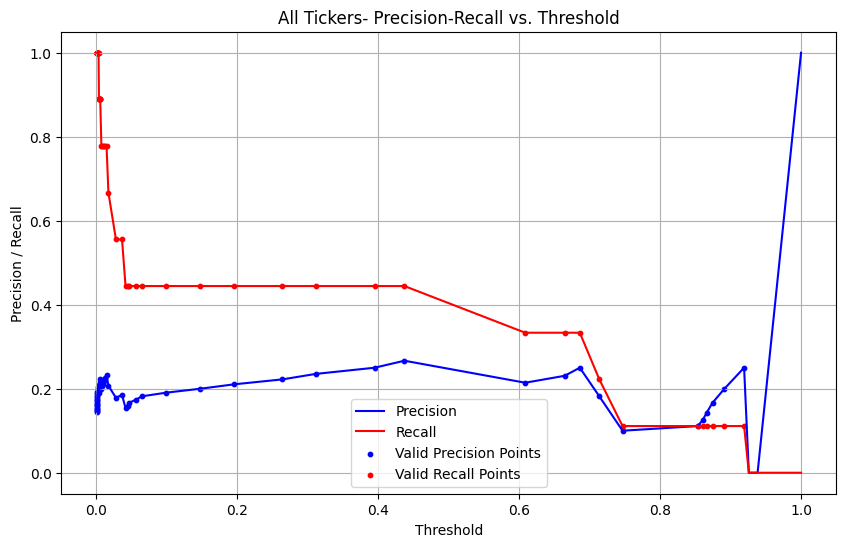

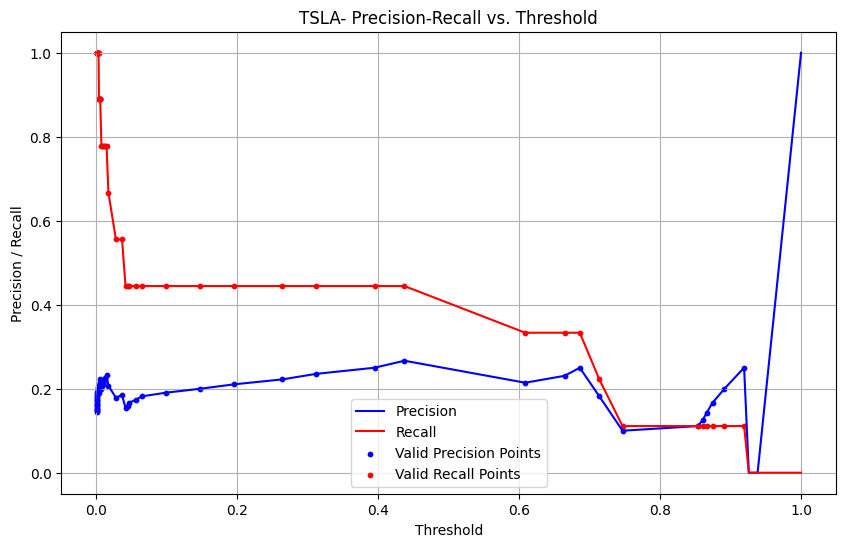

[0.         0.         0.         0.0012837  0.0012837  0.00256739
 0.00256739 0.00385109 0.00385109 0.00513479 0.00513479 0.00641849
 0.00641849 0.00770218 0.00770218 0.00898588 0.00898588 0.01026958
 0.01026958 0.01283697 0.01283697 0.01412067 0.01412067 0.01540436
 0.01540436 0.01668806 0.01668806 0.01797176 0.01797176 0.02053915
 0.02053915 0.02182285 0.02182285 0.02310655 0.02310655 0.02439024
 0.02439024 0.02695764 0.02695764 0.02824134 0.02824134 0.02952503
 0.02952503 0.03080873 0.03080873 0.03209243 0.03209243 0.03337612
 0.03337612 0.03465982 0.03465982 0.03594352 0.03594352 0.03851091
 0.03851091 0.042362   0.042362   0.04878049 0.04878049 0.05648267
 0.05648267 0.05905006 0.05905006 0.07573813 0.07573813 0.1296534
 0.1296534  0.9563543  1.        ]
[0.         0.03649635 0.20437956 0.20437956 0.34306569 0.34306569
 0.37226277 0.37226277 0.41605839 0.41605839 0.44525547 0.44525547
 0.47445255 0.47445255 0.49635036 0.49635036 0.56934307 0.56934307
 0.59854015 0.59854015 0.605

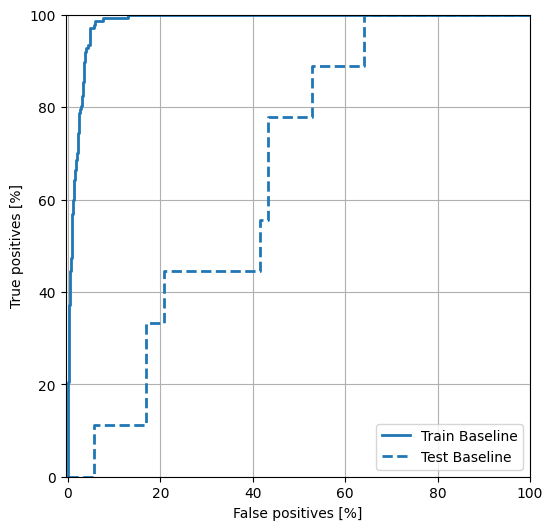

Best threshold: 0.43707937002182007
Number of true positives for the given ticker: 3
Number of false positives for the given ticker: 11
Precision score: 0.21428571428571427
Recall score: 0.3333333333333333
Random guess score: 0.14516129032258066
true-positive per ticker: Orig_Ticker
TSLA    3
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
TSLA    11
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
TSLA    6
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
TSLA    0.214286
dtype: float64
recall per ticker: Orig_Ticker
TSLA    0.333333
dtype: float64
rand guess per ticker: Orig_Ticker
TSLA    0.145161
dtype: float64
Some true positives
                          Date Orig_Ticker  y-predict-original  \
944  2024-10-23 00:00:00-04:00        TSLA            0.919182   
979  2024-12-12 00:00:00-05:00        TSLA            0.685991   
984  2024-12-19 00:00:00-05:00        TSLA            0.713707   

     y-value-original 

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 1 0 0 0 1 0 0 1 0 1 0 0 0 1 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 1 0 1 0 1 0 0 1 0 0 1 0 1 1 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0
 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0 1 0 1 0 1 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = valid

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['NVDA'] UNDERLYING_TARGET: Next-Day-Close-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:17 mode: simple LR_RATE: 0.001 STARTING_LR: 1e-05
fetch_finance_data_for_tickers: just returning file name: NVDA for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode simple is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode simple is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, b

{'NVDA': 0}
{'Tech': 0}
size before sigma app: 1041 for ticker: NVDA mean: -0.0006747830027395319, sigma: 0.027003594559580853 upper_bound: 0.08033600067600304 lower_bound: -0.0816855666814821
size after sigma app: 1031 for ticker: NVDA
0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
972    0.0
973    0.0
974    0.0
975    0.0
976    0.0
Name: y-value, Length: 967, dtype: float64
0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
972    0.0
973    0.0
974    0.0
975    0.0
976    0.0
Name: y-value-original, Length: 967, dtype: float64
High-Low-Ratio                               0.608370
High-Open-Ratio                              0.579600
Close-Open-Ratio                             0.522822
Close-Prev-Close                             0.554731
MACD-Prev-MACD                               0.270857
200D-Ratio                                   0.666372
MACD_SIG                                     0.821060
MFI3                                         0.2

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 17, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_30 (Conv1D)  │ (None, 15, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_46 (PReLU)  │ (None, 15, 256)   │        256 │ conv1d_30[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_31 (Conv1D)  │ (None, 7, 256)    │    196,864 │ p_re_lu_46[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_47 (PReLU)  │ (None, 7, 256)    │        256 │ conv1d_31[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_32 (Conv1D)  │ (None, 3, 512)    │    393,728 │ p_re_lu_47[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_48 (PReLU)  │ (None, 3, 512)    │        512 │ conv1d_32[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_33 (Conv1D)  │ (None, 1, 512)    │    786,944 │ p_re_lu_48[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_49 (PReLU)  │ (None, 1, 512)    │        512 │ conv1d_33[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_12          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_12          │ (None, 512)       │          0 │ p_re_lu_49[0][0]  │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_12[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_13          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_12      │ (None, 1024)      │          0 │ flatten_12[0][0], │
│ (Concatenate)       │                   │            │ stock_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_dense        │ (None, 256)       │     33,024 │ reshape_13[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_13      │ (None, 1280)      │          0 │ concatenate_12[0

 Total params: 2,247,451 (8.57 MB)

 Trainable params: 2,247,451 (8.57 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 8s 580ms/step - AUC: 0.5077 - Precision: 0.1740 - Recall: 0.9935 - all_positives: 21.9587 - f1_score_metric: 37.2002 - loss: 2.3787 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2764.2183 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2764.2183 - val_AUC: 0.6696 - val_Precision: 0.1111 - val_Recall: 1.0000 - val_all_positives: 7.0000 - val_f1_score_metric: 12.6000 - val_loss: 2.1964 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 441.0001 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 441.0000 - learning_rate: 1.0000e-05
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 320ms/step - AUC: 0.5226 - Precision: 0.1881 - Recall: 1.0000 - all_positives: 23.7693 - f1_score_metric: 39.9882 - loss: 2.4139 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 3023.0300 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 3023.0300 - val_AUC: 0.6288 - val_Preci

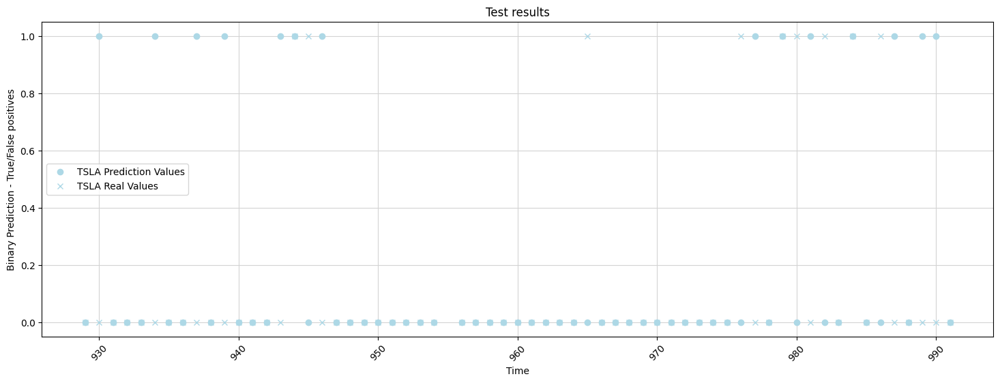

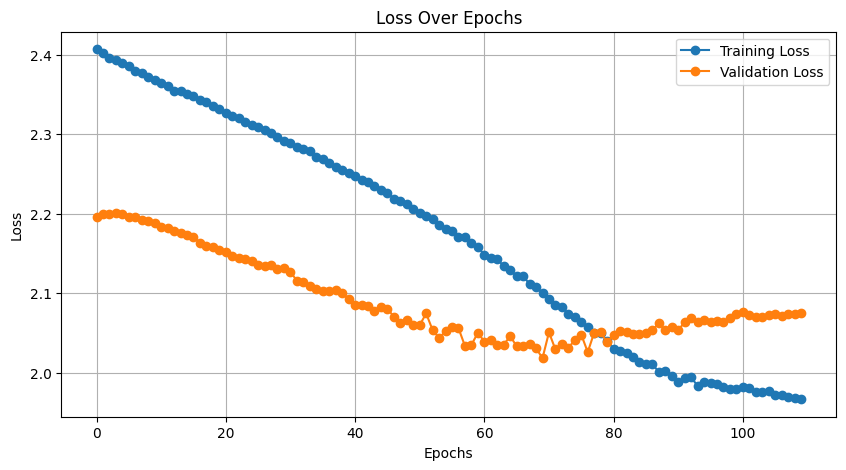

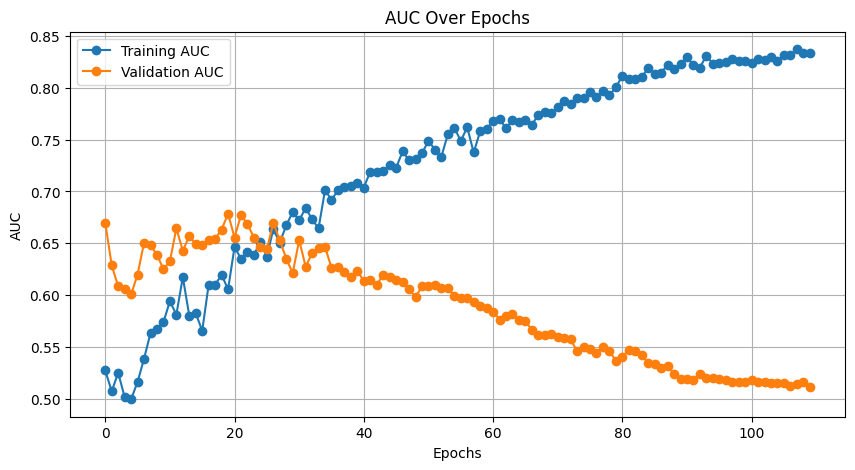



print_and_save_for
ticker data: NVDA


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
972        High-Low-Ratio  High-Open-Ratio  Close-O...   
973        High-Low-Ratio  High-Open-Ratio  Close-O...   
974        High-Low-Ratio  High-Open-Ratio  Close-O...   
975        High-Low-Ratio  High-Open-Ratio  Close-O...   
976        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2020-11-11 00:00:00-05:00       0       0        -0.000675   
1    2020-11-12 00:00:00-05:00       0       0        -0.000675   
2    2020-11-13 00:00:00-05:00       0     

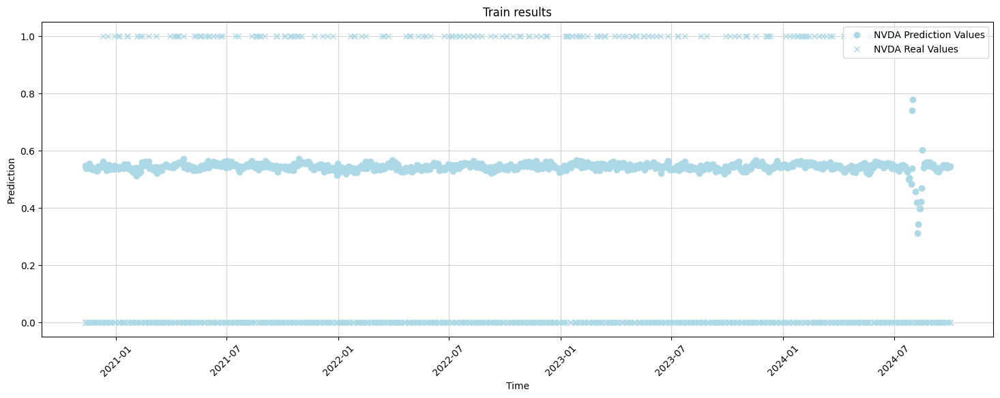

DONE PLOTTING 




print_and_save_for
ticker data: NVDA


Here is the data:                                                LstmData  \
977         High-Low-Ratio  High-Open-Ratio  Close-O...   
978         High-Low-Ratio  High-Open-Ratio  Close-O...   
979         High-Low-Ratio  High-Open-Ratio  Close-O...   
980         High-Low-Ratio  High-Open-Ratio  Close-O...   
981         High-Low-Ratio  High-Open-Ratio  Close-O...   
...                                                 ...   
1035        High-Low-Ratio  High-Open-Ratio  Close-O...   
1036        High-Low-Ratio  High-Open-Ratio  Close-O...   
1037        High-Low-Ratio  High-Open-Ratio  Close-O...   
1038        High-Low-Ratio  High-Open-Ratio  Close-O...   
1039        High-Low-Ratio  High-Open-Ratio  Close-O...   

                           Date  Ticker  Sector  Target-20D-Mean  \
977   2024-10-02 00:00:00-04:00       0       0        -0.000675   
978   2024-10-03 00:00:00-04:00       0       0        -0.000675   
979   2024-

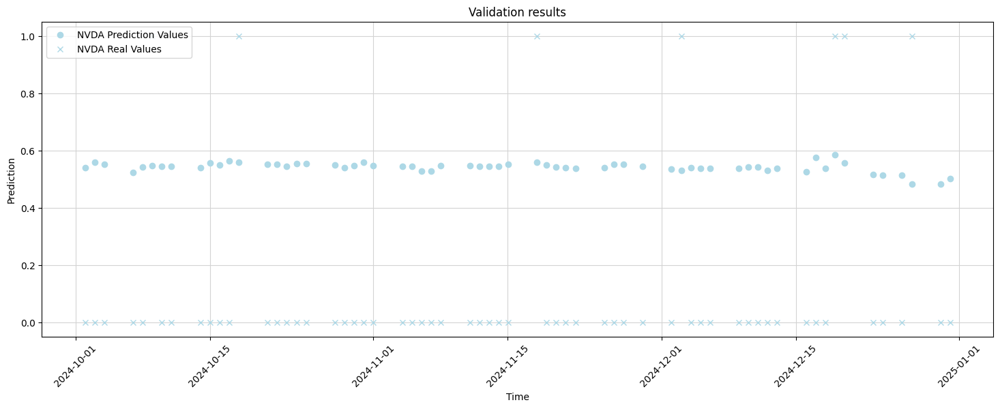

DONE PLOTTING 




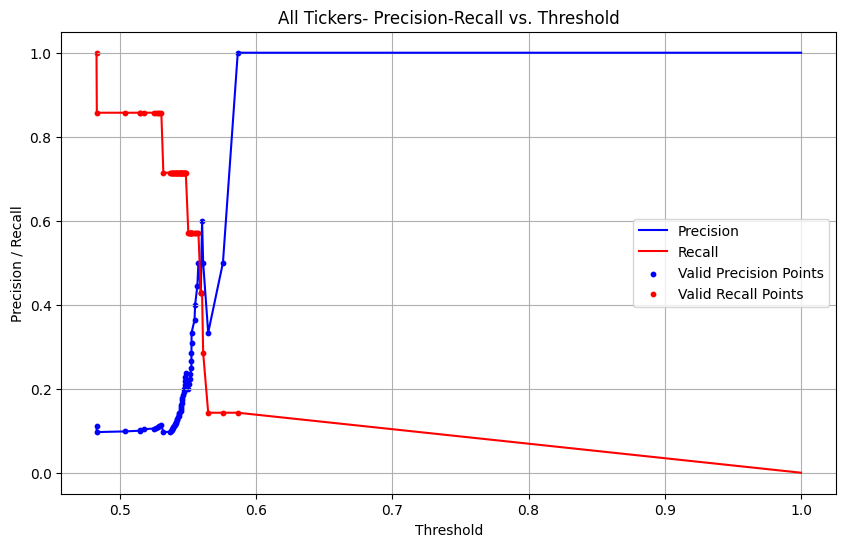

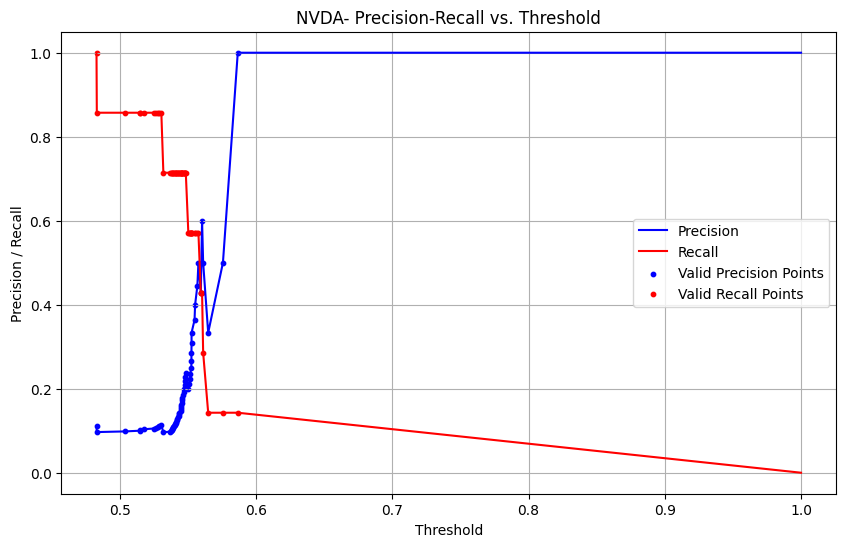

[0.         0.         0.         0.00126743 0.00126743 0.00253485
 0.00253485 0.00380228 0.00380228 0.00887199 0.00887199 0.01267427
 0.01267427 0.01520913 0.01520913 0.01774398 0.01774398 0.02281369
 0.02281369 0.0278834  0.0278834  0.03041825 0.03041825 0.03929024
 0.03929024 0.04055767 0.04055767 0.0468948  0.0468948  0.05196451
 0.05196451 0.05576679 0.05576679 0.06844106 0.06844106 0.07224335
 0.07224335 0.07858048 0.07858048 0.08238276 0.08238276 0.08618504
 0.08618504 0.0887199  0.0887199  0.09125475 0.09125475 0.10773131
 0.10773131 0.10899873 0.10899873 0.11280101 0.11280101 0.11406844
 0.11406844 0.11533587 0.11533587 0.12674271 0.12674271 0.12927757
 0.12927757 0.13434728 0.13434728 0.1356147  0.1356147  0.14575412
 0.14575412 0.14702155 0.14702155 0.14828897 0.14828897 0.15335868
 0.15335868 0.15589354 0.15589354 0.1634981  0.1634981  0.16476553
 0.16476553 0.16856781 0.16856781 0.20405577 0.20405577 0.20532319
 0.20532319 0.2103929  0.2103929  0.21292776 0.21292776 0.2141

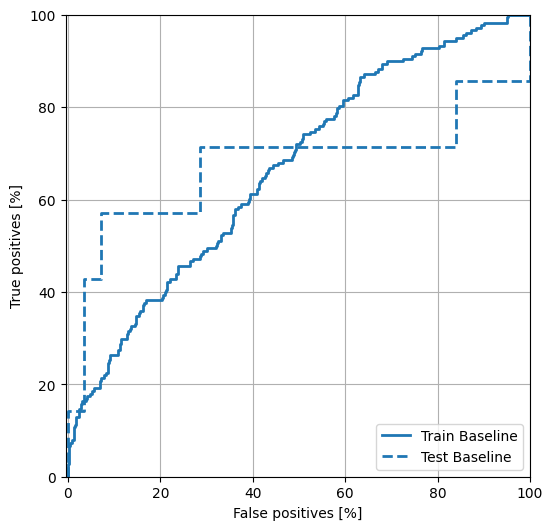

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0
 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 1 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = v

Best threshold: 0.5603084564208984
Number of true positives for the given ticker: 2
Number of false positives for the given ticker: 2
Precision score: 0.5
Recall score: 0.2857142857142857
Random guess score: 0.1111111111111111
true-positive per ticker: Orig_Ticker
NVDA    2
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
NVDA    2
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
NVDA    5
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
NVDA    0.5
dtype: float64
recall per ticker: Orig_Ticker
NVDA    0.285714
dtype: float64
rand guess per ticker: Orig_Ticker
NVDA    0.111111
dtype: float64
Some true positives
                           Date Orig_Ticker  y-predict-original  \
1032  2024-12-19 00:00:00-05:00        NVDA            0.586508   
1010  2024-11-18 00:00:00-05:00        NVDA            0.561095   

      y-value-original  Target-20D-Mean  Target-20D-Sigma  
1032               1.0        -0.000675          0

/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode medium is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode medium is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, b

{'NVDA': 0}
{'Tech': 0}
size before sigma app: 1025 for ticker: NVDA mean: -0.000674783002739532, sigma: 0.027003594559580853 upper_bound: 0.08033600067600304 lower_bound: -0.0816855666814821
size after sigma app: 1015 for ticker: NVDA
0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
956    0.0
957    0.0
958    0.0
959    0.0
960    0.0
Name: y-value, Length: 951, dtype: float64
0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
956    0.0
957    0.0
958    0.0
959    0.0
960    0.0
Name: y-value-original, Length: 951, dtype: float64
High-Low-Ratio                               0.608370
High-Open-Ratio                              0.579600
Close-Open-Ratio                             0.522822
Close-Prev-Close                             0.554731
MACD-Prev-MACD                               0.270857
200D-Ratio                                   0.666372
MACD_SIG                                     0.821060
MFI3                                         0.29

/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:500: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_frame["Ticker"] = data_frame["Ticker"].replace(stock_dict)
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:515: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_frame["Sector"] = data_frame["Sector"].replace(sector_dict)


...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 33, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_34 (Conv1D)  │ (None, 31, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_52 (PReLU)  │ (None, 31, 256)   │        256 │ conv1d_34[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_35 (Conv1D)  │ (None, 15, 256)   │    196,864 │ p_re_lu_52[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_53 (PReLU)  │ (None, 15, 256)   │        256 │ conv1d_35[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_36 (Conv1D)  │ (None, 7, 512)    │    393,728 │ p_re_lu_53[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_54 (PReLU)  │ (None, 7, 512)    │        512 │ conv1d_36[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_37 (Conv1D)  │ (None, 3, 512)    │    786,944 │ p_re_lu_54[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_55 (PReLU)  │ (None, 3, 512)    │        512 │ conv1d_37[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_38 (Conv1D)  │ (None, 1, 1024)   │  1,573,888 │ p_re_lu_55[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_56 (PReLU)  │ (None, 1, 1024)   │      1,024 │ conv1d_38[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_14          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_14          │ (None, 1024)      │          0 │ p_re_lu_56[0][0]  │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_14[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_15          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_14      │ (None, 1536)      │          0 │ flatten_14[0][0], │
│ (Concatenate)       │                   │            │ stock_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 7,696,364 (29.36 MB)

 Trainable params: 7,696,364 (29.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 11s 840ms/step - AUC: 0.4917 - Precision: 0.1733 - Recall: 0.6638 - all_positives: 23.5558 - f1_score_metric: 33.6274 - loss: 2.1657 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2079.9102 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2079.9102 - val_AUC: 0.4247 - val_Precision: 0.1111 - val_Recall: 1.0000 - val_all_positives: 7.0000 - val_f1_score_metric: 12.6000 - val_loss: 1.9615 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 441.0001 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 441.0000 - learning_rate: 1.0000e-04
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 393ms/step - AUC: 0.5854 - Precision: 0.1913 - Recall: 1.0000 - all_positives: 23.8926 - f1_score_metric: 40.0588 - loss: 2.1330 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2999.5537 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2999.5537 - val_AUC: 0.4643 - val_Prec

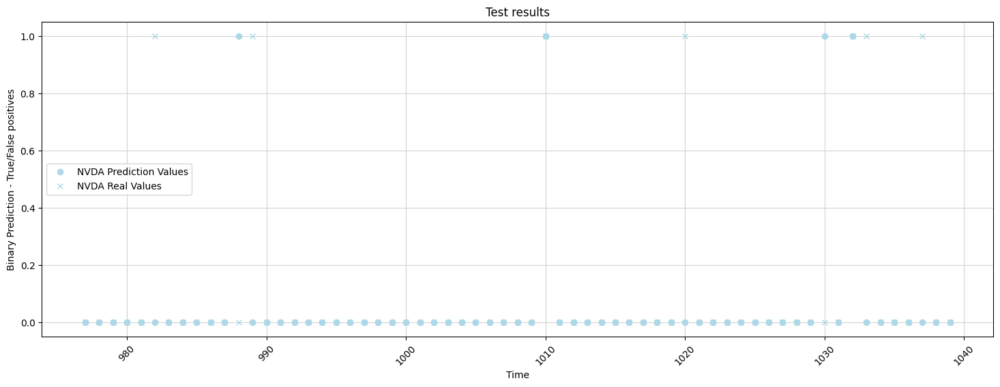

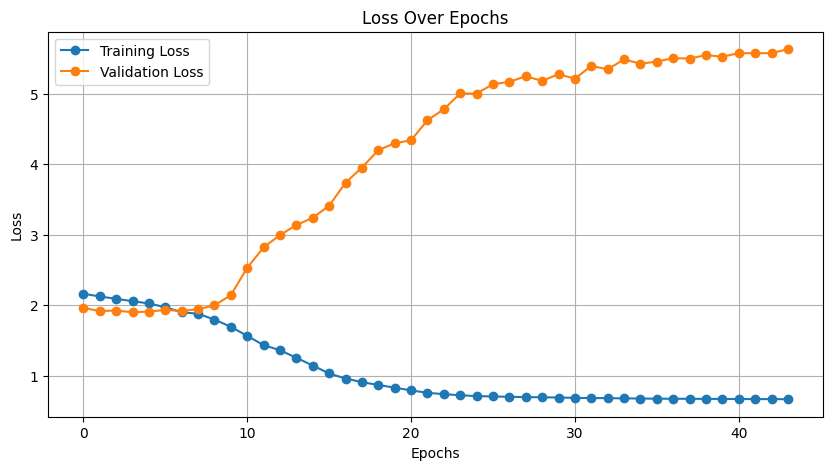

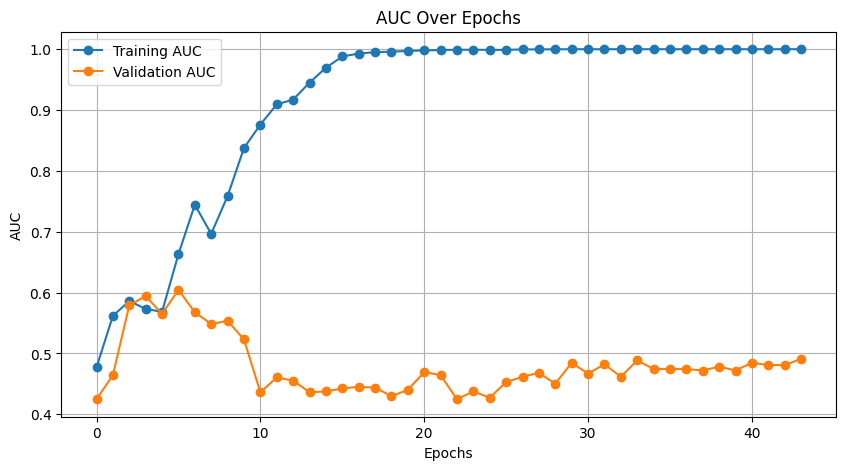



print_and_save_for
ticker data: NVDA


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
956        High-Low-Ratio  High-Open-Ratio  Close-O...   
957        High-Low-Ratio  High-Open-Ratio  Close-O...   
958        High-Low-Ratio  High-Open-Ratio  Close-O...   
959        High-Low-Ratio  High-Open-Ratio  Close-O...   
960        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2020-12-04 00:00:00-05:00       0       0        -0.000675   
1    2020-12-07 00:00:00-05:00       0       0        -0.000675   
2    2020-12-08 00:00:00-05:00       0     

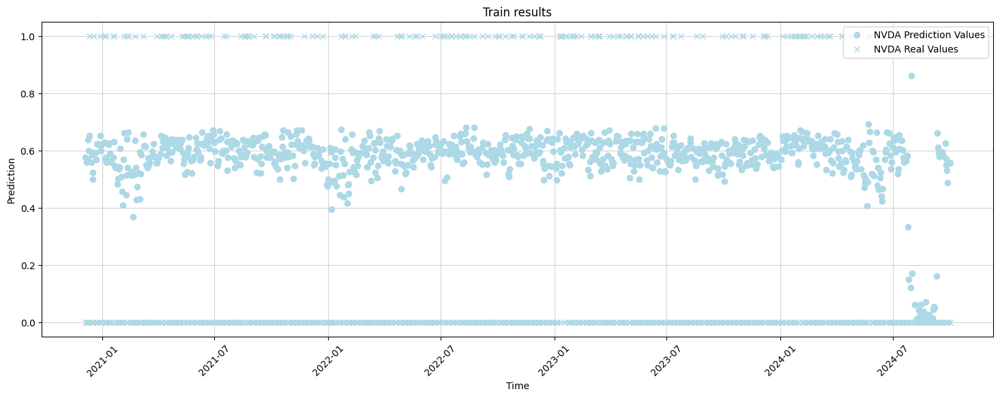

DONE PLOTTING 




print_and_save_for
ticker data: NVDA


Here is the data:                                                LstmData  \
961         High-Low-Ratio  High-Open-Ratio  Close-O...   
962         High-Low-Ratio  High-Open-Ratio  Close-O...   
963         High-Low-Ratio  High-Open-Ratio  Close-O...   
964         High-Low-Ratio  High-Open-Ratio  Close-O...   
965         High-Low-Ratio  High-Open-Ratio  Close-O...   
...                                                 ...   
1019        High-Low-Ratio  High-Open-Ratio  Close-O...   
1020        High-Low-Ratio  High-Open-Ratio  Close-O...   
1021        High-Low-Ratio  High-Open-Ratio  Close-O...   
1022        High-Low-Ratio  High-Open-Ratio  Close-O...   
1023        High-Low-Ratio  High-Open-Ratio  Close-O...   

                           Date  Ticker  Sector  Target-20D-Mean  \
961   2024-10-02 00:00:00-04:00       0       0        -0.000675   
962   2024-10-03 00:00:00-04:00       0       0        -0.000675   
963   2024-

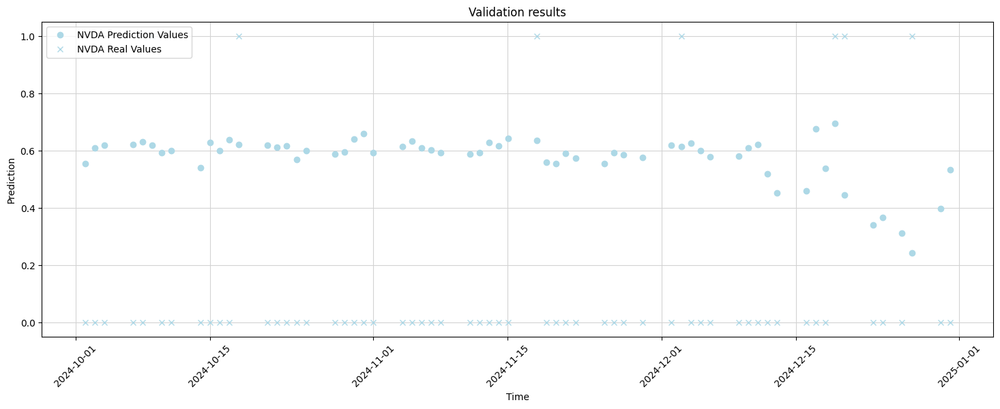

DONE PLOTTING 




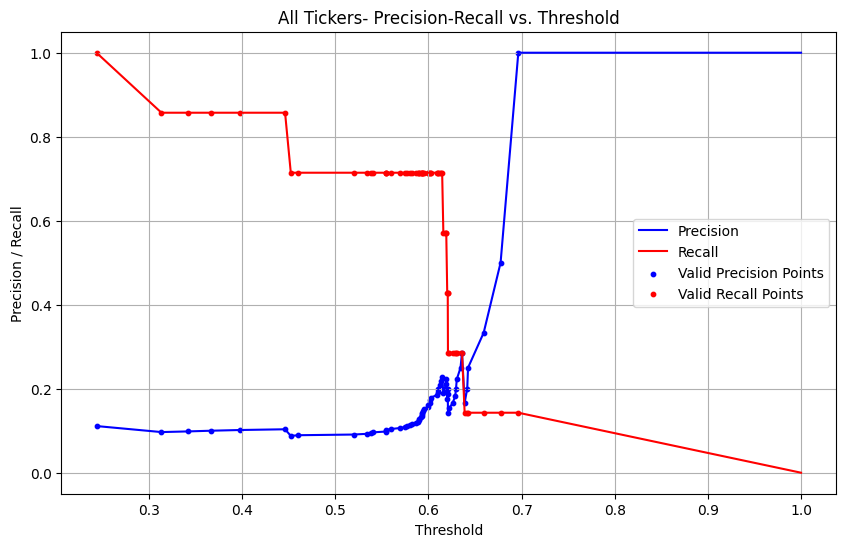

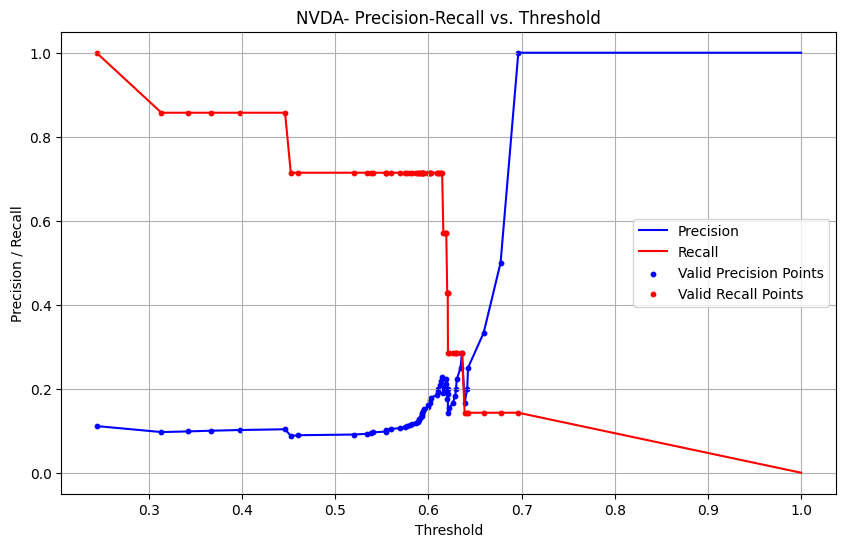

[0.         0.         0.         0.00388098 0.00388098 0.00776197
 0.00776197 0.00905563 0.00905563 0.01293661 0.01293661 0.01423027
 0.01423027 0.01552393 0.01552393 0.01681759 0.01681759 0.01811125
 0.01811125 0.02069858 0.02069858 0.0232859  0.0232859  0.02457956
 0.02457956 0.02846054 0.02846054 0.0297542  0.0297542  0.03104787
 0.03104787 0.03363519 0.03363519 0.03492885 0.03492885 0.03880983
 0.03880983 0.04139715 0.04139715 0.04269082 0.04269082 0.04398448
 0.04398448 0.04527814 0.04527814 0.0530401  0.0530401  0.05433376
 0.05433376 0.06209573 0.06209573 0.06468305 0.06468305 0.0698577
 0.0698577  0.07244502 0.07244502 0.07761966 0.07761966 0.08020699
 0.08020699 0.08796895 0.08796895 0.09573092 0.09573092 0.10349288
 0.10349288 0.10608021 0.10608021 0.10996119 0.10996119 0.11125485
 0.11125485 0.11384217 0.11384217 0.11513583 0.11513583 0.12160414
 0.12160414 0.12419146 0.12419146 0.12807245 0.12807245 0.13195343
 0.13195343 0.13324709 0.13324709 0.13583441 0.13583441 0.13712

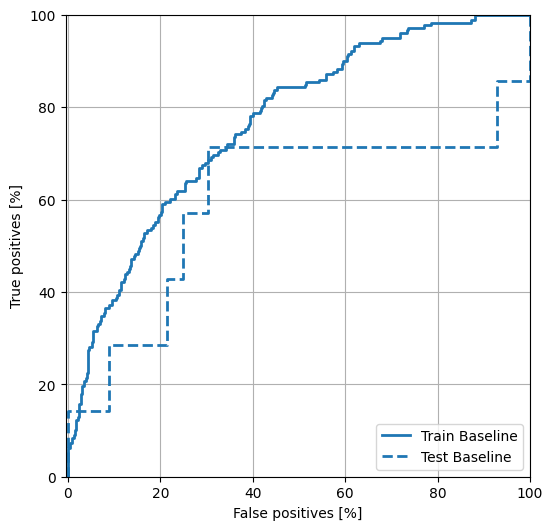

Best threshold: 0.6964630484580994
Number of true positives for the given ticker: 0
Number of false positives for the given ticker: 0
Precision score: nan
Recall score: 0.0
Random guess score: 0.1111111111111111
true-positive per ticker: Orig_Ticker
NVDA    0
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
NVDA    0
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
NVDA    7
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
NVDA   NaN
dtype: float64
recall per ticker: Orig_Ticker
NVDA    0.0
dtype: float64
rand guess per ticker: Orig_Ticker
NVDA    0.111111
dtype: float64
Some true positives
Empty DataFrame
Columns: [Date, Orig_Ticker, y-predict-original, y-value-original, Target-20D-Mean, Target-20D-Sigma]
Index: []
Some false positives
Empty DataFrame
Columns: [Date, Orig_Ticker, y-predict-original, y-value-original, Target-20D-Mean, Target-20D-Sigma]
Index: []
gain is: 0.0 and loss is 0.0
Effective gain is: 0.0
Scor

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0
 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 1 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = v

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['NVDA'] UNDERLYING_TARGET: Next-Day-Close-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:65 mode: complex LR_RATE: 0.0001 STARTING_LR: 0.001
fetch_finance_data_for_tickers: just returning file name: NVDA for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode complex is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode complex is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names,

{'NVDA': 0}
{'Tech': 0}
size before sigma app: 993 for ticker: NVDA mean: -0.0006747830027395319, sigma: 0.027003594559580846 upper_bound: 0.08033600067600301 lower_bound: -0.08168556668148207
size after sigma app: 983 for ticker: NVDA
0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
924    0.0
925    0.0
926    0.0
927    0.0
928    0.0
Name: y-value, Length: 919, dtype: float64
0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
924    0.0
925    0.0
926    0.0
927    0.0
928    0.0
Name: y-value-original, Length: 919, dtype: float64
High-Low-Ratio                               0.608370
High-Open-Ratio                              0.579600
Close-Open-Ratio                             0.522822
Close-Prev-Close                             0.554731
MACD-Prev-MACD                               0.270857
200D-Ratio                                   0.666372
MACD_SIG                                     0.821060
MFI3                                         0.29

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 65, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_39 (Conv1D)  │ (None, 63, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_60 (PReLU)  │ (None, 63, 256)   │        256 │ conv1d_39[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_40 (Conv1D)  │ (None, 31, 256)   │    196,864 │ p_re_lu_60[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_61 (PReLU)  │ (None, 31, 256)   │        256 │ conv1d_40[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_41 (Conv1D)  │ (None, 15, 512)   │    393,728 │ p_re_lu_61[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_62 (PReLU)  │ (None, 15, 512)   │        512 │ conv1d_41[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_42 (Conv1D)  │ (None, 7, 512)    │    786,944 │ p_re_lu_62[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_63 (PReLU)  │ (None, 7, 512)    │        512 │ conv1d_42[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_43 (Conv1D)  │ (None, 3, 1024)   │  1,573,888 │ p_re_lu_63[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_64 (PReLU)  │ (None, 3, 1024)   │      1,024 │ conv1d_43[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_44 (Conv1D)  │ (None, 1, 1024)   │  3,146,752 │ p_re_lu_64[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_65 (PReLU)  │ (None, 1, 1024)   │      1,024 │ conv1d_44[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_16          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_16          │ (None, 1024)      │          0 │ p_re_lu_65[0][0]  │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_16[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_17          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                 

 Total params: 10,844,140 (41.37 MB)

 Trainable params: 10,844,140 (41.37 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 12s 900ms/step - AUC: 0.4946 - Precision: 0.1755 - Recall: 0.6454 - all_positives: 21.7019 - f1_score_metric: 25.4169 - loss: 2.6159 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 1756.8733 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 1756.8733 - val_AUC: 0.6033 - val_Precision: 0.1111 - val_Recall: 1.0000 - val_all_positives: 7.0000 - val_f1_score_metric: 12.6000 - val_loss: 1.3391 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 441.0001 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 441.0000 - learning_rate: 0.0010
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 567ms/step - AUC: 0.4806 - Precision: 0.1867 - Recall: 1.0000 - all_positives: 23.3212 - f1_score_metric: 39.2275 - loss: 1.4878 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2969.4851 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2969.4851 - val_AUC: 0.5791 - val_Precisio

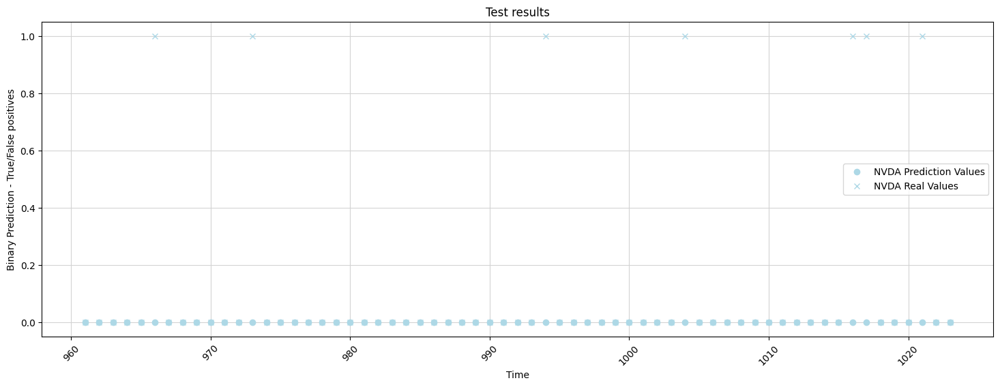

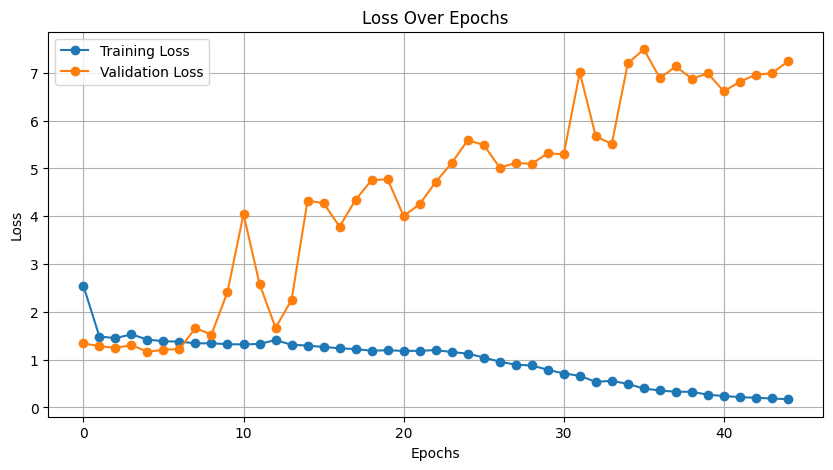

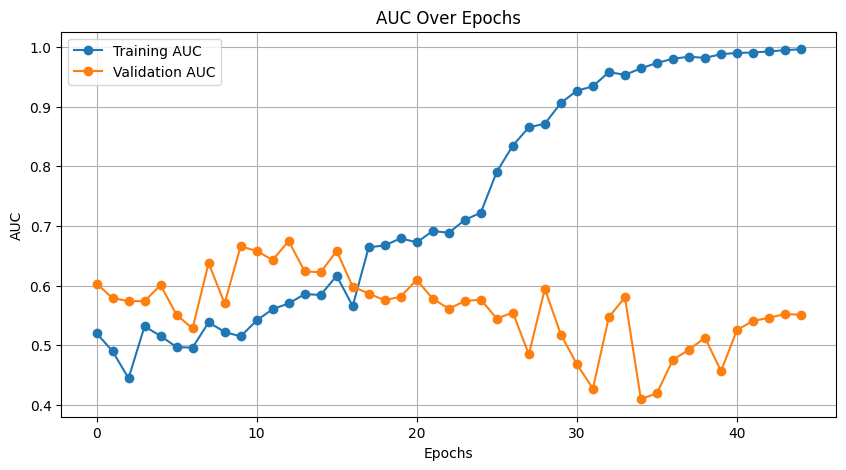



print_and_save_for
ticker data: NVDA


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
924        High-Low-Ratio  High-Open-Ratio  Close-O...   
925        High-Low-Ratio  High-Open-Ratio  Close-O...   
926        High-Low-Ratio  High-Open-Ratio  Close-O...   
927        High-Low-Ratio  High-Open-Ratio  Close-O...   
928        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2021-01-22 00:00:00-05:00       0       0        -0.000675   
1    2021-01-25 00:00:00-05:00       0       0        -0.000675   
2    2021-01-26 00:00:00-05:00       0     

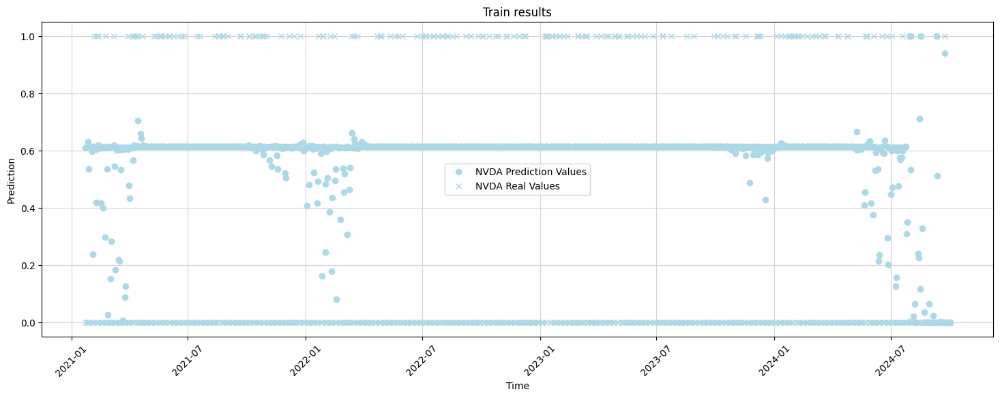

DONE PLOTTING 




print_and_save_for
ticker data: NVDA


Here is the data:                                               LstmData  \
929        High-Low-Ratio  High-Open-Ratio  Close-O...   
930        High-Low-Ratio  High-Open-Ratio  Close-O...   
931        High-Low-Ratio  High-Open-Ratio  Close-O...   
932        High-Low-Ratio  High-Open-Ratio  Close-O...   
933        High-Low-Ratio  High-Open-Ratio  Close-O...   
..                                                 ...   
987        High-Low-Ratio  High-Open-Ratio  Close-O...   
988        High-Low-Ratio  High-Open-Ratio  Close-O...   
989        High-Low-Ratio  High-Open-Ratio  Close-O...   
990        High-Low-Ratio  High-Open-Ratio  Close-O...   
991        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
929  2024-10-02 00:00:00-04:00       0       0        -0.000675   
930  2024-10-03 00:00:00-04:00       0       0        -0.000675   
931  2024-10-04 00:00:00-0

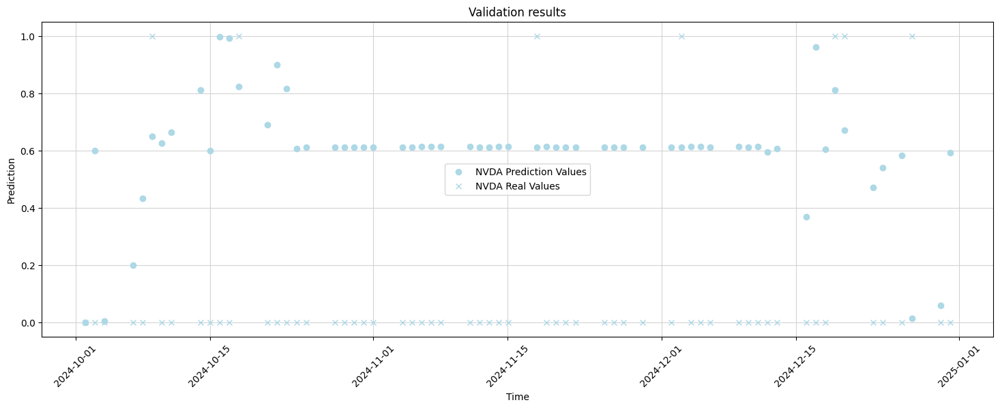

DONE PLOTTING 




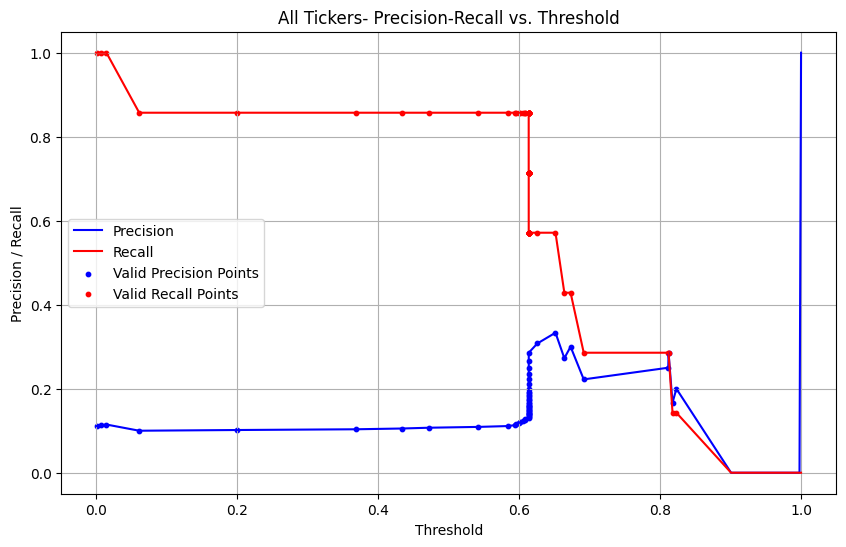

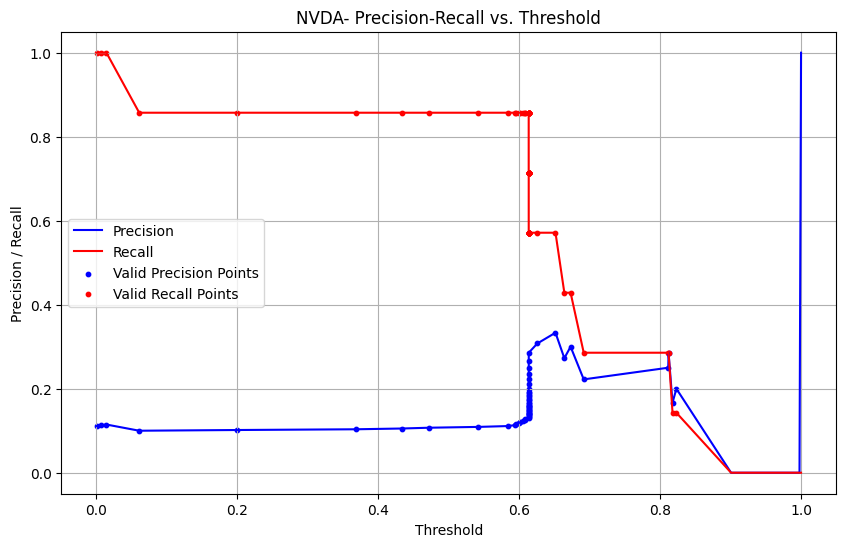

[0.         0.         0.         0.0013369  0.0013369  0.0026738
 0.0026738  0.00534759 0.00534759 0.01604278 0.01604278 0.02005348
 0.02005348 0.03074866 0.03074866 0.03342246 0.03342246 0.03609626
 0.03609626 0.04411765 0.04411765 0.05347594 0.05614973 0.05614973
 0.06417112 0.06417112 0.07085561 0.07085561 0.07352941 0.07352941
 0.07754011 0.07754011 0.07887701 0.07887701 0.08957219 0.08957219
 0.09625668 0.09625668 0.10695187 0.10962567 0.10962567 0.11229947
 0.11229947 0.12165775 0.12165775 0.12700535 0.13235294 0.13235294
 0.13368984 0.13636364 0.13636364 0.14171123 0.14171123 0.14705882
 0.14705882 0.14973262 0.15240642 0.15240642 0.15508021 0.15508021
 0.15775401 0.1671123  0.1684492  0.1697861  0.1697861  0.17112299
 0.17914439 0.18315508 0.18582888 0.19786096 0.19786096 0.20053476
 0.20053476 0.20588235 0.20855615 0.20855615 0.20989305 0.20989305
 0.21122995 0.21122995 0.21256684 0.21524064 0.21524064 0.21791444
 0.22058824 0.22326203 0.22326203 0.22727273 0.22994652 0.22994

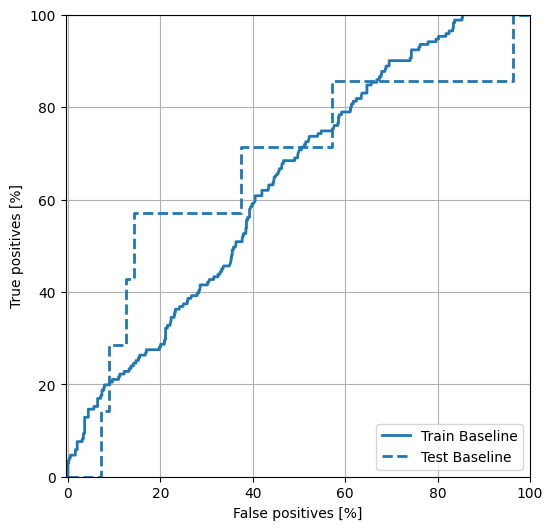

Best threshold: 0.6514756083488464
Number of true positives for the given ticker: 3
Number of false positives for the given ticker: 8
Precision score: 0.2727272727272727
Recall score: 0.42857142857142855
Random guess score: 0.1111111111111111
true-positive per ticker: Orig_Ticker
NVDA    3
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
NVDA    8
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
NVDA    4
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
NVDA    0.272727
dtype: float64
recall per ticker: Orig_Ticker
NVDA    0.428571
dtype: float64
rand guess per ticker: Orig_Ticker
NVDA    0.111111
dtype: float64
Some true positives
                          Date Orig_Ticker  y-predict-original  \
941  2024-10-18 00:00:00-04:00        NVDA            0.823054   
984  2024-12-19 00:00:00-05:00        NVDA            0.811955   
985  2024-12-20 00:00:00-05:00        NVDA            0.672910   

     y-value-original  Tar

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 0 0 1 1 0 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0
 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 1 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = v

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['NVDA'] UNDERLYING_TARGET: Next-Day-High-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:17 mode: simple LR_RATE: 0.001 STARTING_LR: 1e-05
fetch_finance_data_for_tickers: just returning file name: NVDA for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode simple is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode simple is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, b

{'NVDA': 0}
{'Tech': 0}
size before sigma app: 1041 for ticker: NVDA mean: 0.018503441545992098, sigma: 0.01618105060358572 upper_bound: 0.06704659335674926 lower_bound: -0.030039710264765058
size after sigma app: 1022 for ticker: NVDA
0      0.0
1      0.0
2      1.0
3      0.0
4      0.0
      ... 
972    0.0
973    0.0
974    0.0
975    0.0
976    0.0
Name: y-value, Length: 958, dtype: float64
0      0.0
1      0.0
2      1.0
3      0.0
4      0.0
      ... 
972    0.0
973    0.0
974    0.0
975    0.0
976    0.0
Name: y-value-original, Length: 958, dtype: float64
High-Low-Ratio                               0.608370
High-Open-Ratio                              0.579600
Close-Open-Ratio                             0.522822
Close-Prev-Close                             0.554731
MACD-Prev-MACD                               0.270857
200D-Ratio                                   0.666372
MACD_SIG                                     0.821060
MFI3                                         0.29

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 17, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_45 (Conv1D)  │ (None, 15, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_69 (PReLU)  │ (None, 15, 256)   │        256 │ conv1d_45[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_46 (Conv1D)  │ (None, 7, 256)    │    196,864 │ p_re_lu_69[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_70 (PReLU)  │ (None, 7, 256)    │        256 │ conv1d_46[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_47 (Conv1D)  │ (None, 3, 512)    │    393,728 │ p_re_lu_70[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_71 (PReLU)  │ (None, 3, 512)    │        512 │ conv1d_47[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_48 (Conv1D)  │ (None, 1, 512)    │    786,944 │ p_re_lu_71[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_72 (PReLU)  │ (None, 1, 512)    │        512 │ conv1d_48[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_18          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_18          │ (None, 512)       │          0 │ p_re_lu_72[0][0]  │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_18[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_19          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_18      │ (None, 1024)      │          0 │ flatten_18[0][0], │
│ (Concatenate)       │                   │            │ stock_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_dense        │ (None, 256)       │     33,024 │ reshape_19[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_19      │ (None, 1280)      │          0 │ concatenate_18[0

 Total params: 2,247,451 (8.57 MB)

 Trainable params: 2,247,451 (8.57 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 891ms/step - AUC: 0.4661 - Precision: 0.1415 - Recall: 0.5239 - all_positives: 18.4500 - f1_score_metric: 28.6116 - loss: 2.4416 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 1240.3865 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 1240.3865 - val_AUC: 0.5241 - val_Precision: 0.0727 - val_Recall: 0.8000 - val_all_positives: 5.0000 - val_f1_score_metric: 9.1667 - val_loss: 2.1717 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 275.0000 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 275.0000 - learning_rate: 1.0000e-05
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 339ms/step - AUC: 0.5470 - Precision: 0.1565 - Recall: 0.8896 - all_positives: 18.0384 - f1_score_metric: 30.4405 - loss: 2.4205 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 1857.0151 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 1857.0151 - val_AUC: 0.4793 - val_Preci

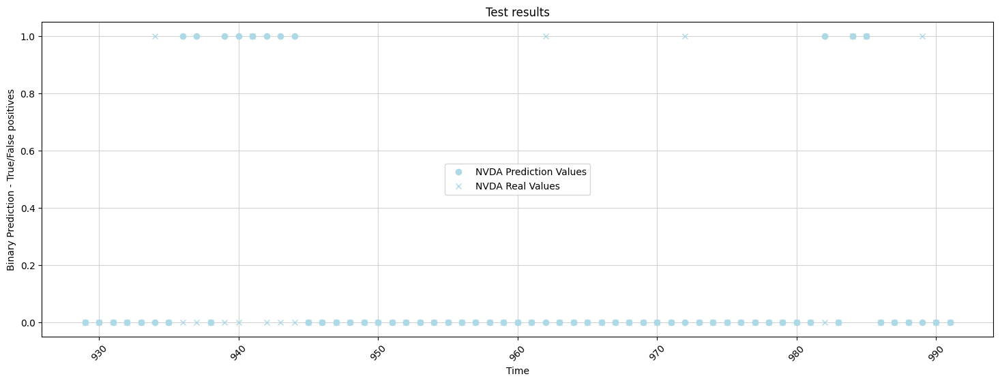

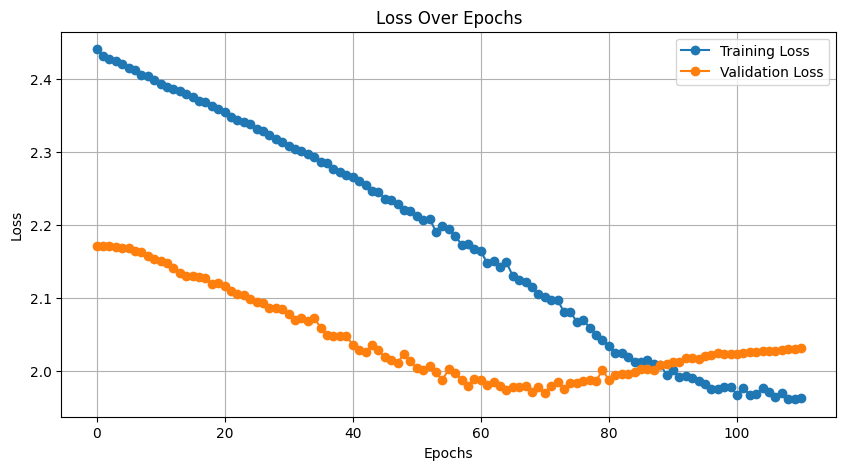

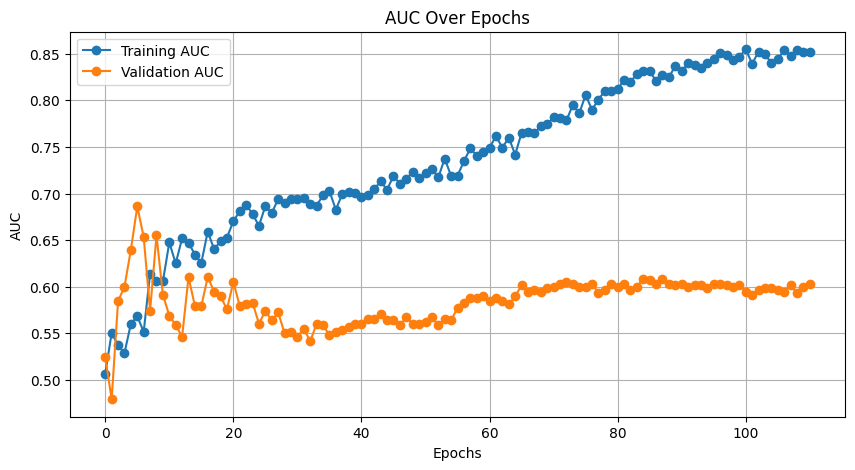



print_and_save_for
ticker data: NVDA


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
972        High-Low-Ratio  High-Open-Ratio  Close-O...   
973        High-Low-Ratio  High-Open-Ratio  Close-O...   
974        High-Low-Ratio  High-Open-Ratio  Close-O...   
975        High-Low-Ratio  High-Open-Ratio  Close-O...   
976        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2020-11-11 00:00:00-05:00       0       0         0.018503   
1    2020-11-12 00:00:00-05:00       0       0         0.018503   
2    2020-11-13 00:00:00-05:00       0     

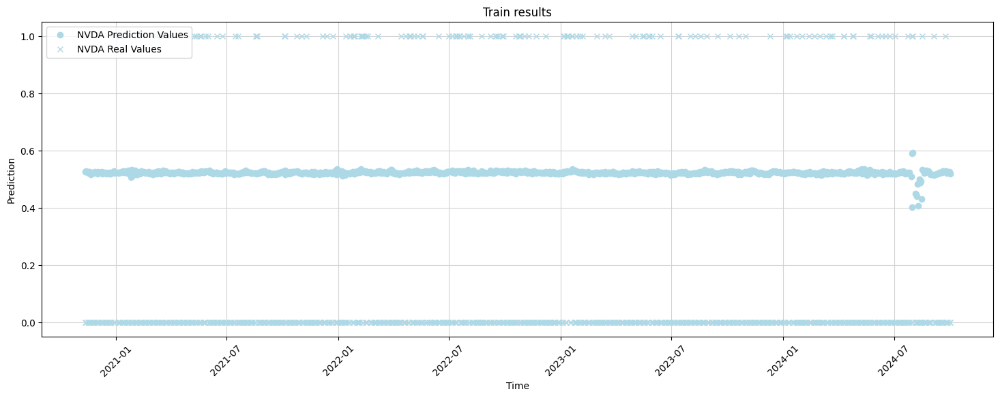

DONE PLOTTING 




print_and_save_for
ticker data: NVDA


Here is the data:                                                LstmData  \
977         High-Low-Ratio  High-Open-Ratio  Close-O...   
978         High-Low-Ratio  High-Open-Ratio  Close-O...   
979         High-Low-Ratio  High-Open-Ratio  Close-O...   
980         High-Low-Ratio  High-Open-Ratio  Close-O...   
981         High-Low-Ratio  High-Open-Ratio  Close-O...   
...                                                 ...   
1035        High-Low-Ratio  High-Open-Ratio  Close-O...   
1036        High-Low-Ratio  High-Open-Ratio  Close-O...   
1037        High-Low-Ratio  High-Open-Ratio  Close-O...   
1038        High-Low-Ratio  High-Open-Ratio  Close-O...   
1039        High-Low-Ratio  High-Open-Ratio  Close-O...   

                           Date  Ticker  Sector  Target-20D-Mean  \
977   2024-10-02 00:00:00-04:00       0       0         0.018503   
978   2024-10-03 00:00:00-04:00       0       0         0.018503   
979   2024-

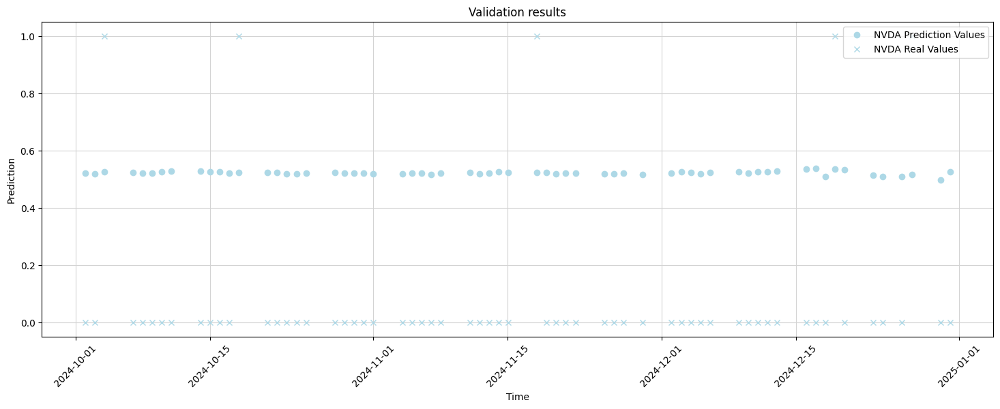

DONE PLOTTING 




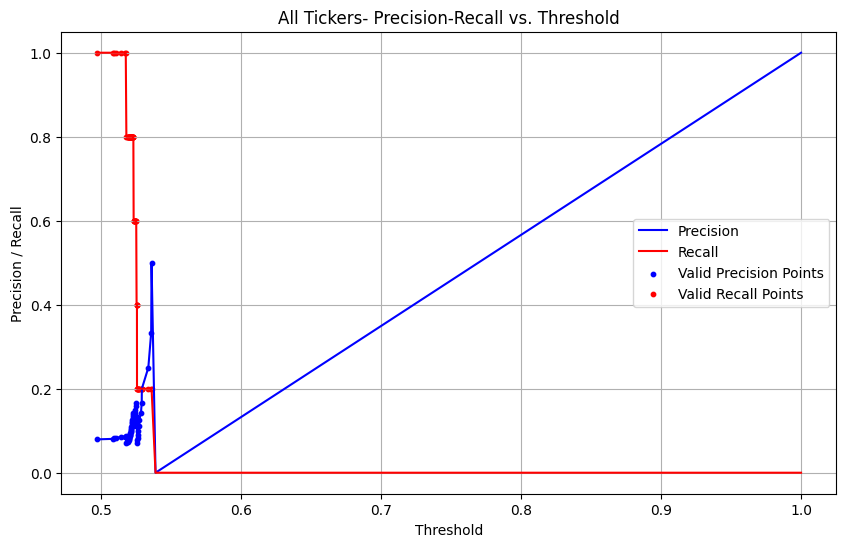

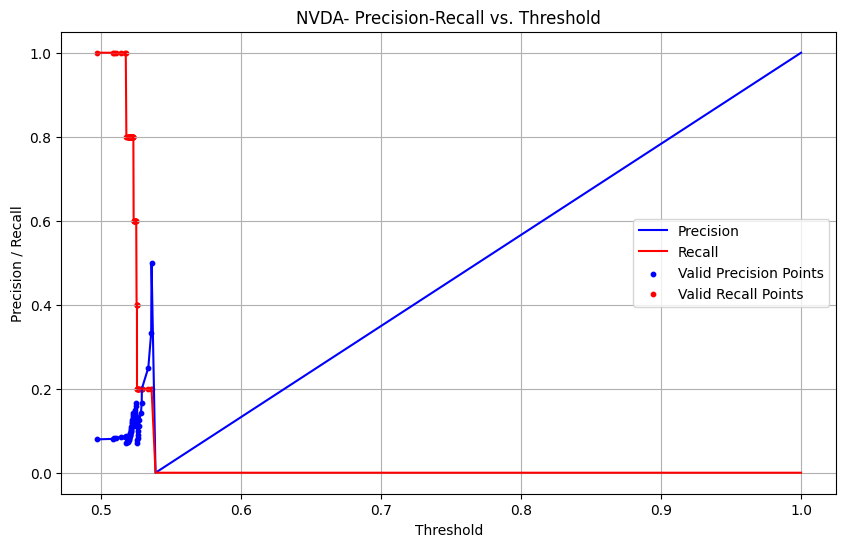

[0.         0.         0.         0.00366748 0.00366748 0.00488998
 0.00488998 0.00611247 0.00611247 0.01222494 0.01222494 0.01344743
 0.01344743 0.01466993 0.01466993 0.01589242 0.01589242 0.02444988
 0.02444988 0.03545232 0.03545232 0.03789731 0.03789731 0.0403423
 0.0403423  0.04156479 0.04156479 0.04645477 0.04645477 0.04767726
 0.04767726 0.04889976 0.04889976 0.05134474 0.05134474 0.05256724
 0.05256724 0.05378973 0.05378973 0.05501222 0.05501222 0.05623472
 0.05623472 0.06234719 0.06234719 0.06845966 0.06845966 0.07212714
 0.07212714 0.07457213 0.07457213 0.08557457 0.08557457 0.09046455
 0.09046455 0.099022   0.099022   0.10757946 0.10757946 0.11491443
 0.11491443 0.13202934 0.13202934 0.13569682 0.13569682 0.1405868
 0.1405868  0.14425428 0.14425428 0.14547677 0.14547677 0.17603912
 0.17603912 0.18337408 0.18337408 0.18459658 0.18459658 0.18826406
 0.18826406 0.18948655 0.18948655 0.19070905 0.19070905 0.19193154
 0.19193154 0.19315403 0.19315403 0.20171149 0.20171149 0.205378

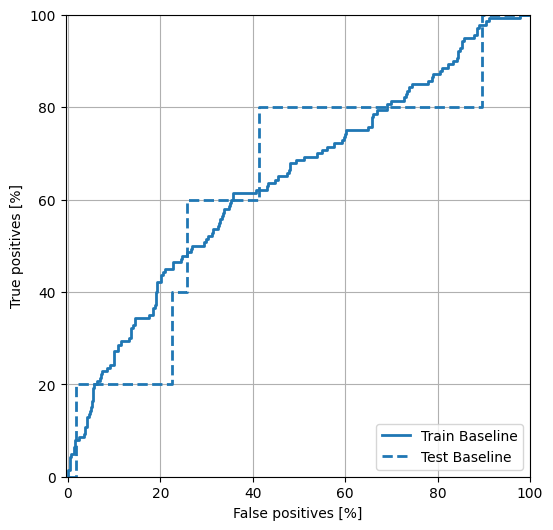

Best threshold: 0.5361459851264954
Number of true positives for the given ticker: 0
Number of false positives for the given ticker: 1
Precision score: 0.0
Recall score: 0.0
Random guess score: 0.07936507936507936
true-positive per ticker: Orig_Ticker
NVDA    0
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
NVDA    1
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
NVDA    5
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
NVDA    0.0
dtype: float64
recall per ticker: Orig_Ticker
NVDA    0.0
dtype: float64
rand guess per ticker: Orig_Ticker
NVDA    0.079365
dtype: float64
Some true positives
Empty DataFrame
Columns: [Date, Orig_Ticker, y-predict-original, y-value-original, Target-20D-Mean, Target-20D-Sigma]
Index: []
Some false positives
                           Date Orig_Ticker  y-predict-original  \
1030  2024-12-17 00:00:00-05:00        NVDA             0.53899   

      y-value-original  Target-20D-Mean  Target

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = v

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['NVDA'] UNDERLYING_TARGET: Next-Day-High-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:33 mode: medium LR_RATE: 0.0005 STARTING_LR: 0.0001
fetch_finance_data_for_tickers: just returning file name: NVDA for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode medium is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode medium is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, b

{'NVDA': 0}
{'Tech': 0}
size before sigma app: 1025 for ticker: NVDA mean: 0.018503441545992098, sigma: 0.01618105060358572 upper_bound: 0.06704659335674926 lower_bound: -0.030039710264765058
size after sigma app: 1006 for ticker: NVDA
0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
956    0.0
957    0.0
958    0.0
959    0.0
960    0.0
Name: y-value, Length: 942, dtype: float64
0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
956    0.0
957    0.0
958    0.0
959    0.0
960    0.0
Name: y-value-original, Length: 942, dtype: float64
High-Low-Ratio                               0.608370
High-Open-Ratio                              0.579600
Close-Open-Ratio                             0.522822
Close-Prev-Close                             0.554731
MACD-Prev-MACD                               0.270857
200D-Ratio                                   0.666372
MACD_SIG                                     0.821060
MFI3                                         0.29

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 33, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_49 (Conv1D)  │ (None, 31, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_75 (PReLU)  │ (None, 31, 256)   │        256 │ conv1d_49[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_50 (Conv1D)  │ (None, 15, 256)   │    196,864 │ p_re_lu_75[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_76 (PReLU)  │ (None, 15, 256)   │        256 │ conv1d_50[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_51 (Conv1D)  │ (None, 7, 512)    │    393,728 │ p_re_lu_76[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_77 (PReLU)  │ (None, 7, 512)    │        512 │ conv1d_51[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_52 (Conv1D)  │ (None, 3, 512)    │    786,944 │ p_re_lu_77[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_78 (PReLU)  │ (None, 3, 512)    │        512 │ conv1d_52[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_53 (Conv1D)  │ (None, 1, 1024)   │  1,573,888 │ p_re_lu_78[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_79 (PReLU)  │ (None, 1, 1024)   │      1,024 │ conv1d_53[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_20          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_20          │ (None, 1024)      │          0 │ p_re_lu_79[0][0]  │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_20[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_21          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_20      │ (None, 1536)      │          0 │ flatten_20[0][0], │
│ (Concatenate)       │                   │            │ stock_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 7,696,364 (29.36 MB)

 Trainable params: 7,696,364 (29.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - AUC: 0.4403 - Precision: 0.1321 - Recall: 0.7276 - all_positives: 18.8804 - f1_score_metric: 30.4123 - loss: 2.2079 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 1845.9263 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 1845.9263 - val_AUC: 0.4448 - val_Precision: 0.0794 - val_Recall: 1.0000 - val_all_positives: 5.0000 - val_f1_score_metric: 9.2647 - val_loss: 1.9266 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 315.0000 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 315.0000 - learning_rate: 1.0000e-04
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 468ms/step - AUC: 0.5826 - Precision: 0.1490 - Recall: 1.0000 - all_positives: 18.3164 - f1_score_metric: 31.8596 - loss: 2.1515 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2275.8845 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2275.8845 - val_AUC: 0.3466 - val_Precisio

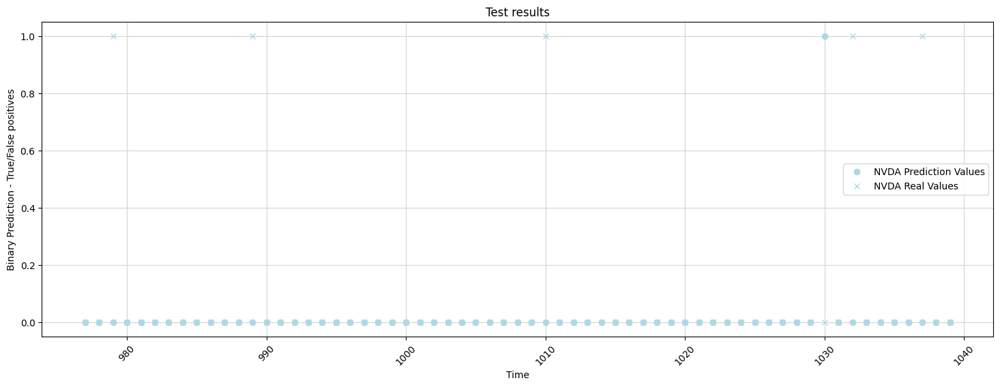

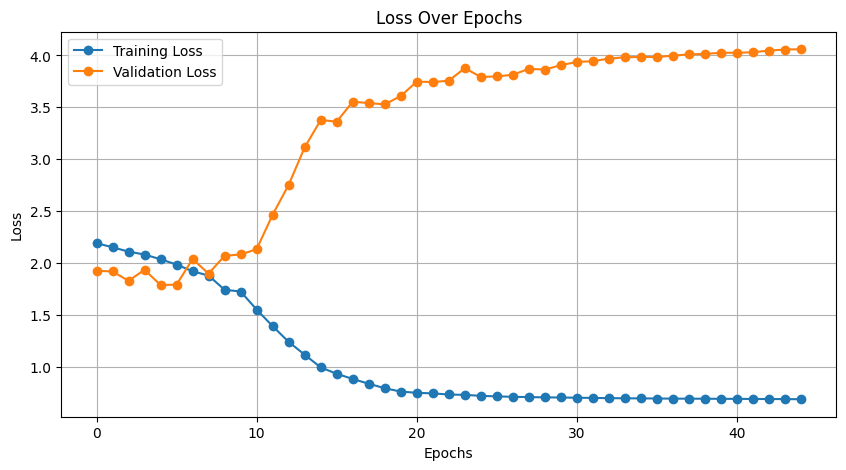

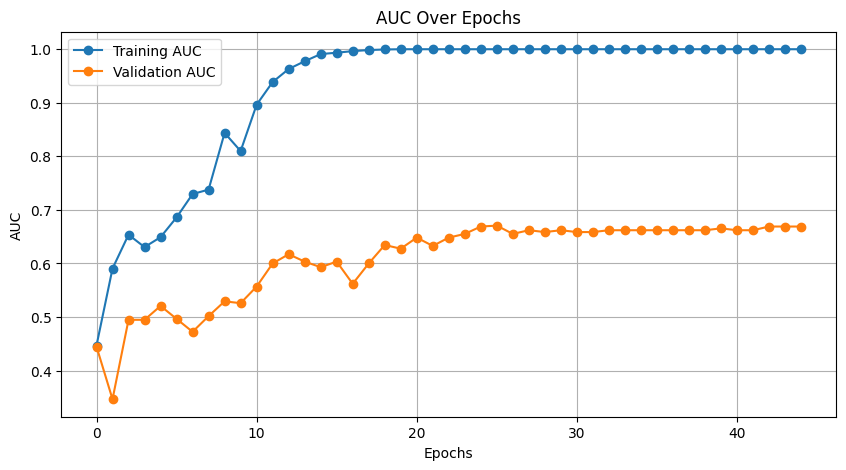



print_and_save_for
ticker data: NVDA


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
956        High-Low-Ratio  High-Open-Ratio  Close-O...   
957        High-Low-Ratio  High-Open-Ratio  Close-O...   
958        High-Low-Ratio  High-Open-Ratio  Close-O...   
959        High-Low-Ratio  High-Open-Ratio  Close-O...   
960        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2020-12-04 00:00:00-05:00       0       0         0.018503   
1    2020-12-07 00:00:00-05:00       0       0         0.018503   
2    2020-12-08 00:00:00-05:00       0     

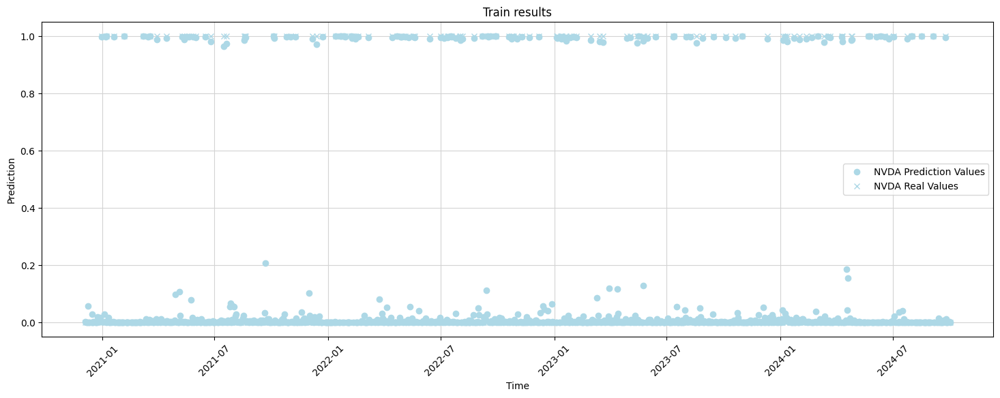

DONE PLOTTING 




print_and_save_for
ticker data: NVDA


Here is the data:                                                LstmData  \
961         High-Low-Ratio  High-Open-Ratio  Close-O...   
962         High-Low-Ratio  High-Open-Ratio  Close-O...   
963         High-Low-Ratio  High-Open-Ratio  Close-O...   
964         High-Low-Ratio  High-Open-Ratio  Close-O...   
965         High-Low-Ratio  High-Open-Ratio  Close-O...   
...                                                 ...   
1019        High-Low-Ratio  High-Open-Ratio  Close-O...   
1020        High-Low-Ratio  High-Open-Ratio  Close-O...   
1021        High-Low-Ratio  High-Open-Ratio  Close-O...   
1022        High-Low-Ratio  High-Open-Ratio  Close-O...   
1023        High-Low-Ratio  High-Open-Ratio  Close-O...   

                           Date  Ticker  Sector  Target-20D-Mean  \
961   2024-10-02 00:00:00-04:00       0       0         0.018503   
962   2024-10-03 00:00:00-04:00       0       0         0.018503   
963   2024-

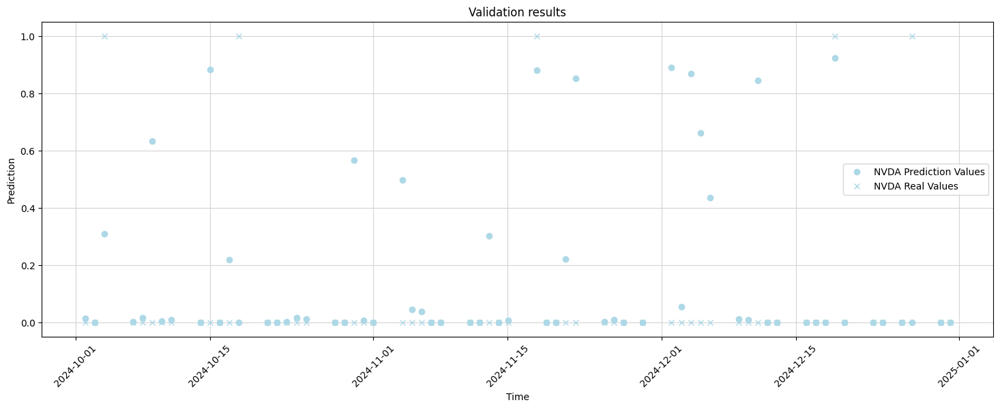

DONE PLOTTING 




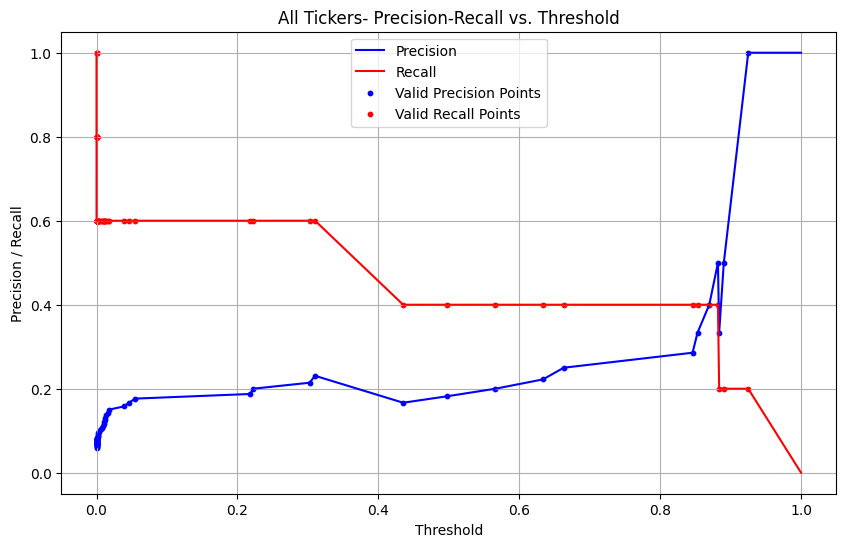

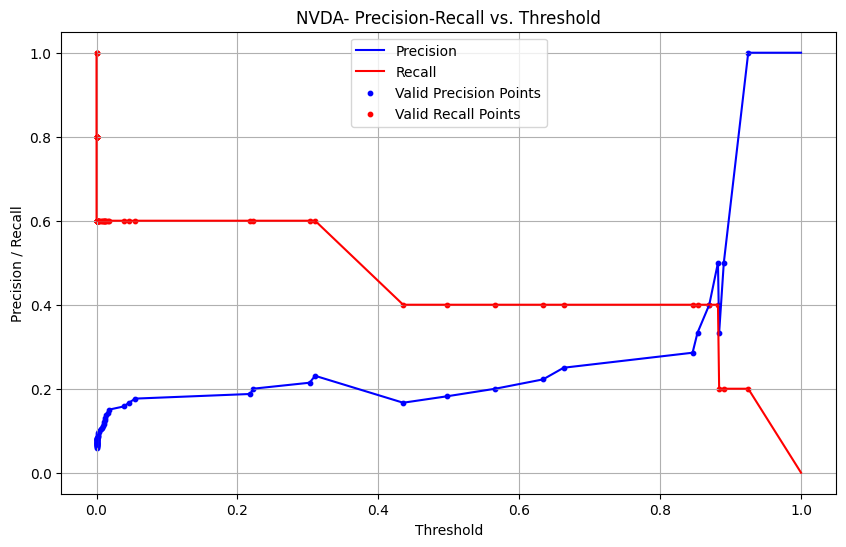

[0.         0.         0.         0.99128269 1.        ]
[0.         0.02158273 1.         1.         1.        ]
[0.         0.         0.03448276 0.03448276 0.17241379 0.17241379
 0.81034483 0.81034483 0.96551724 0.96551724 1.        ]
[0.  0.2 0.2 0.4 0.4 0.6 0.6 0.8 0.8 1.  1. ]


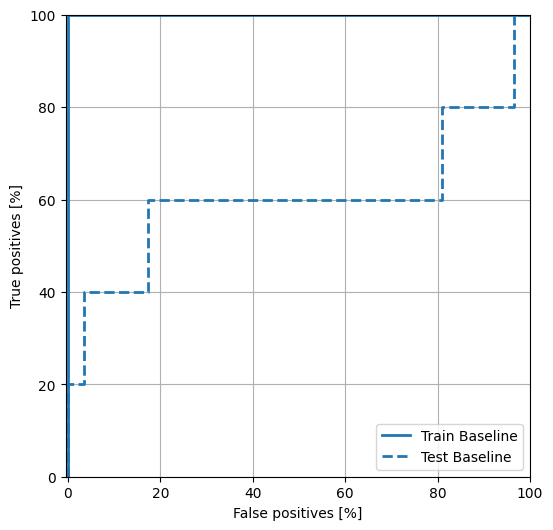

Best threshold: 0.9250262379646301
Number of true positives for the given ticker: 0
Number of false positives for the given ticker: 0
Precision score: nan
Recall score: 0.0
Random guess score: 0.07936507936507936
true-positive per ticker: Orig_Ticker
NVDA    0
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
NVDA    0
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
NVDA    5
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
NVDA   NaN
dtype: float64
recall per ticker: Orig_Ticker
NVDA    0.0
dtype: float64
rand guess per ticker: Orig_Ticker
NVDA    0.079365
dtype: float64
Some true positives
Empty DataFrame
Columns: [Date, Orig_Ticker, y-predict-original, y-value-original, Target-20D-Mean, Target-20D-Sigma]
Index: []
Some false positives
Empty DataFrame
Columns: [Date, Orig_Ticker, y-predict-original, y-value-original, Target-20D-Mean, Target-20D-Sigma]
Index: []
gain is: 0.0 and loss is 0.0
Effective gain is: 0.0
Sco

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = v

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['NVDA'] UNDERLYING_TARGET: Next-Day-High-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:65 mode: complex LR_RATE: 0.0001 STARTING_LR: 0.001
fetch_finance_data_for_tickers: just returning file name: NVDA for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode complex is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode complex is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names,

{'NVDA': 0}
{'Tech': 0}
size before sigma app: 993 for ticker: NVDA mean: 0.018503441545992098, sigma: 0.016181050603585715 upper_bound: 0.06704659335674924 lower_bound: -0.03003971026476505
size after sigma app: 974 for ticker: NVDA
0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
924    0.0
925    0.0
926    0.0
927    0.0
928    0.0
Name: y-value, Length: 910, dtype: float64
0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
924    0.0
925    0.0
926    0.0
927    0.0
928    0.0
Name: y-value-original, Length: 910, dtype: float64
High-Low-Ratio                               0.608370
High-Open-Ratio                              0.579600
Close-Open-Ratio                             0.522822
Close-Prev-Close                             0.554731
MACD-Prev-MACD                               0.270857
200D-Ratio                                   0.666372
MACD_SIG                                     0.821060
MFI3                                         0.2962

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 65, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_54 (Conv1D)  │ (None, 63, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_83 (PReLU)  │ (None, 63, 256)   │        256 │ conv1d_54[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_55 (Conv1D)  │ (None, 31, 256)   │    196,864 │ p_re_lu_83[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_84 (PReLU)  │ (None, 31, 256)   │        256 │ conv1d_55[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_56 (Conv1D)  │ (None, 15, 512)   │    393,728 │ p_re_lu_84[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_85 (PReLU)  │ (None, 15, 512)   │        512 │ conv1d_56[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_57 (Conv1D)  │ (None, 7, 512)    │    786,944 │ p_re_lu_85[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_86 (PReLU)  │ (None, 7, 512)    │        512 │ conv1d_57[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_58 (Conv1D)  │ (None, 3, 1024)   │  1,573,888 │ p_re_lu_86[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_87 (PReLU)  │ (None, 3, 1024)   │      1,024 │ conv1d_58[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_59 (Conv1D)  │ (None, 1, 1024)   │  3,146,752 │ p_re_lu_87[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_88 (PReLU)  │ (None, 1, 1024)   │      1,024 │ conv1d_59[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_22          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_22          │ (None, 1024)      │          0 │ p_re_lu_88[0][0]  │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_22[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_23          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                 

 Total params: 10,844,140 (41.37 MB)

 Trainable params: 10,844,140 (41.37 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - AUC: 0.4916 - Precision: 0.1468 - Recall: 0.3369 - all_positives: 17.8855 - f1_score_metric: 18.0164 - loss: 1.6167 - precision_with_threshold_fixed: 2.6857 - recall_mul_prediction: 762.9550 - recall_with_threshold_fixed: 16.8603 - true_positives: 762.9550 - val_AUC: 0.5000 - val_Precision: 0.0794 - val_Recall: 1.0000 - val_all_positives: 5.0000 - val_f1_score_metric: 9.2647 - val_loss: 1.2759 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 315.0000 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 315.0000 - learning_rate: 0.0010
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 677ms/step - AUC: 0.4513 - Precision: 0.1544 - Recall: 0.9637 - all_positives: 19.6519 - f1_score_metric: 33.7055 - loss: 1.5546 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2452.6147 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2452.6147 - val_AUC: 0.4741 - val_Precision: 0.0794 - v

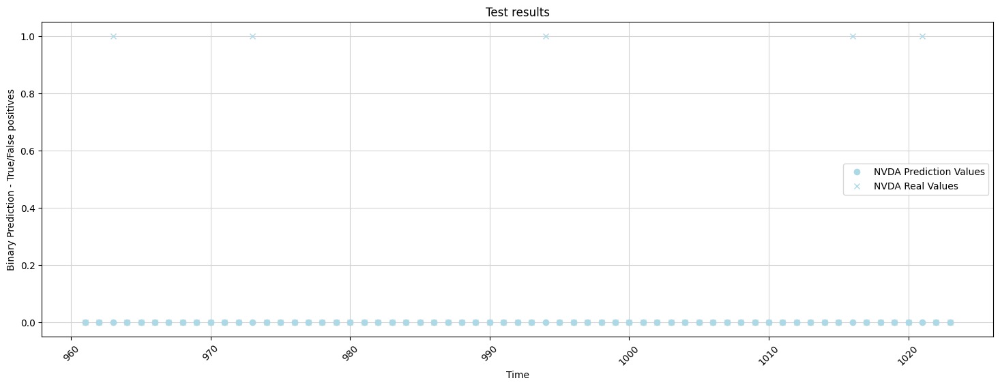

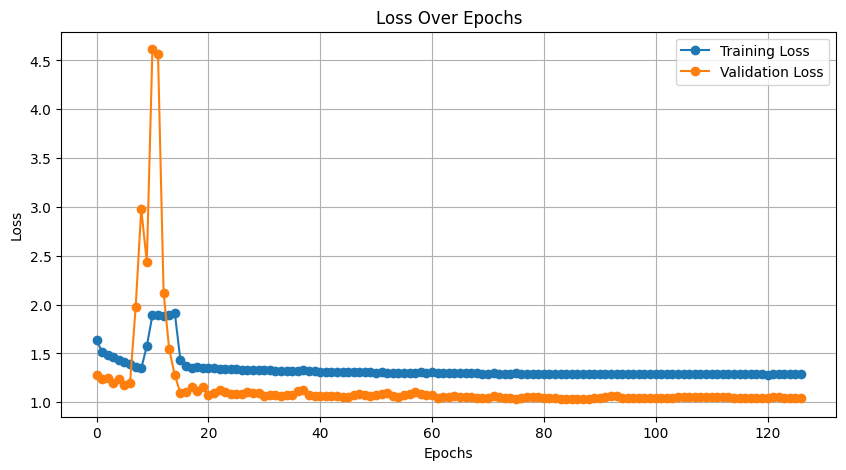

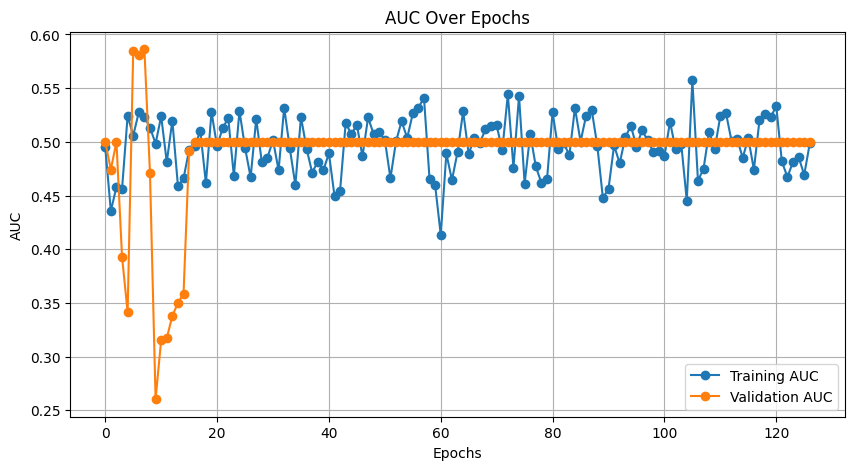



print_and_save_for
ticker data: NVDA


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
924        High-Low-Ratio  High-Open-Ratio  Close-O...   
925        High-Low-Ratio  High-Open-Ratio  Close-O...   
926        High-Low-Ratio  High-Open-Ratio  Close-O...   
927        High-Low-Ratio  High-Open-Ratio  Close-O...   
928        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2021-01-22 00:00:00-05:00       0       0         0.018503   
1    2021-01-25 00:00:00-05:00       0       0         0.018503   
2    2021-01-26 00:00:00-05:00       0     

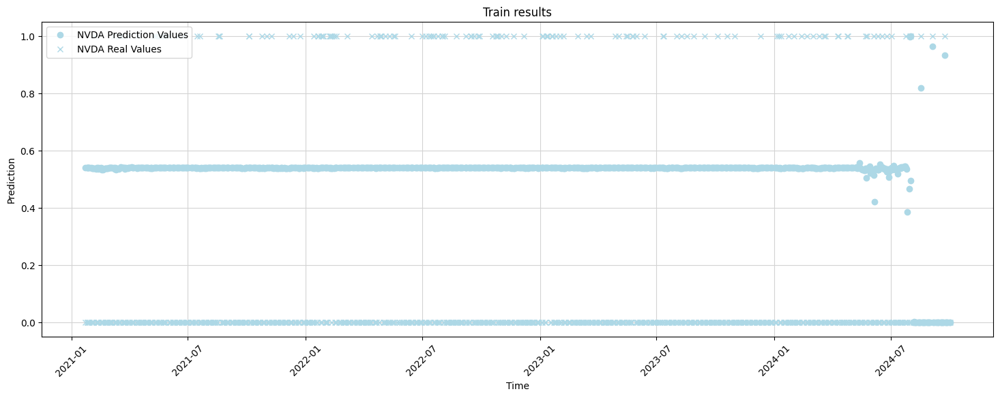

DONE PLOTTING 




print_and_save_for
ticker data: NVDA


Here is the data:                                               LstmData  \
929        High-Low-Ratio  High-Open-Ratio  Close-O...   
930        High-Low-Ratio  High-Open-Ratio  Close-O...   
931        High-Low-Ratio  High-Open-Ratio  Close-O...   
932        High-Low-Ratio  High-Open-Ratio  Close-O...   
933        High-Low-Ratio  High-Open-Ratio  Close-O...   
..                                                 ...   
987        High-Low-Ratio  High-Open-Ratio  Close-O...   
988        High-Low-Ratio  High-Open-Ratio  Close-O...   
989        High-Low-Ratio  High-Open-Ratio  Close-O...   
990        High-Low-Ratio  High-Open-Ratio  Close-O...   
991        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
929  2024-10-02 00:00:00-04:00       0       0         0.018503   
930  2024-10-03 00:00:00-04:00       0       0         0.018503   
931  2024-10-04 00:00:00-0

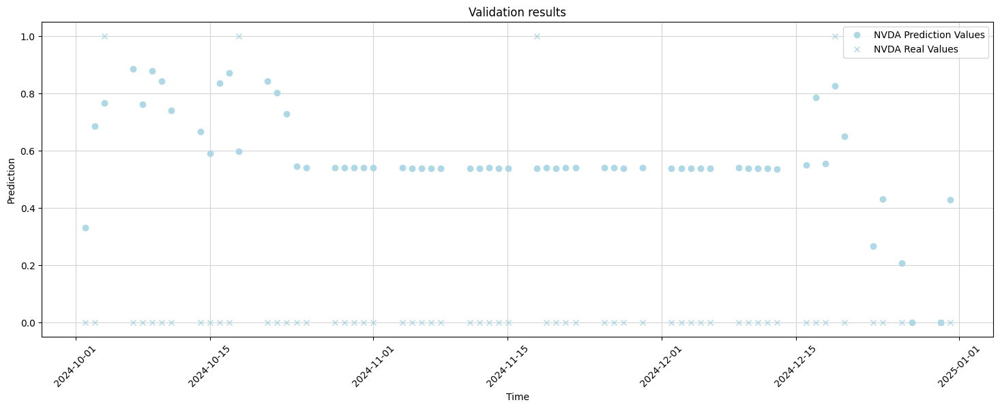

DONE PLOTTING 




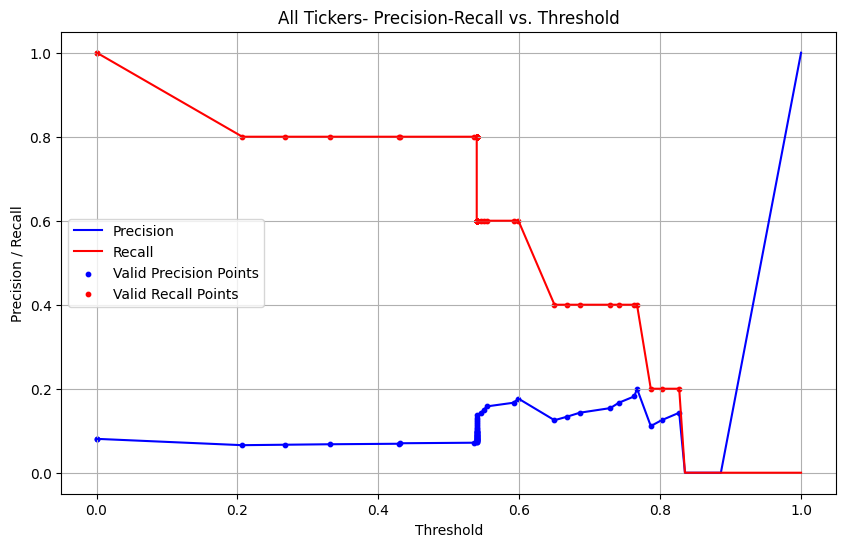

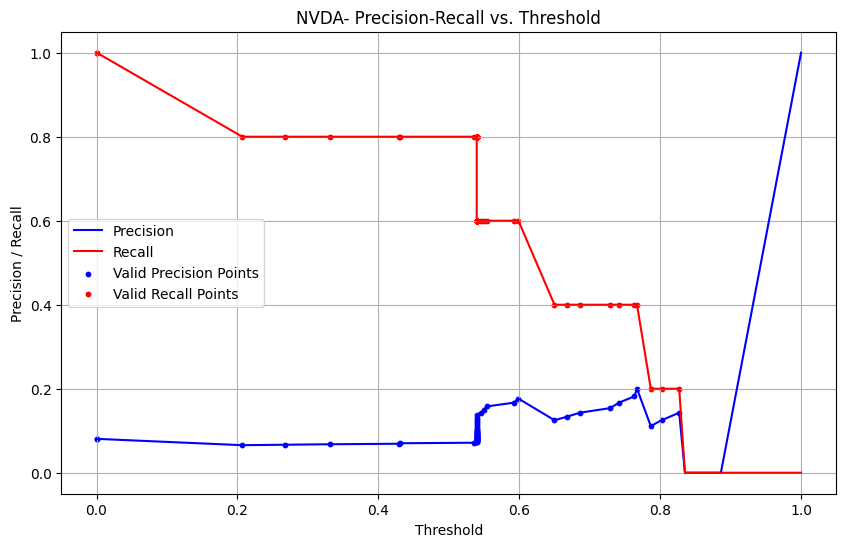

[0.         0.         0.         0.0116129  0.0116129  0.01548387
 0.01548387 0.01677419 0.01677419 0.01806452 0.01806452 0.03612903
 0.03612903 0.03870968 0.03870968 0.06322581 0.06322581 0.0683871
 0.0683871  0.07096774 0.07096774 0.07612903 0.07612903 0.07741935
 0.07741935 0.07870968 0.07870968 0.08258065 0.08258065 0.09032258
 0.09032258 0.09677419 0.09677419 0.10193548 0.10193548 0.11096774
 0.11096774 0.11483871 0.11483871 0.11870968 0.12129032 0.13935484
 0.13935484 0.14580645 0.14580645 0.15870968 0.15870968 0.16258065
 0.16258065 0.17419355 0.17419355 0.18580645 0.18580645 0.1883871
 0.1883871  0.19225806 0.19225806 0.19354839 0.19354839 0.19612903
 0.19612903 0.20258065 0.20258065 0.20387097 0.20387097 0.20516129
 0.20516129 0.2116129  0.2116129  0.21419355 0.21419355 0.22064516
 0.22064516 0.22193548 0.22193548 0.22451613 0.22451613 0.22709677
 0.22709677 0.22967742 0.22967742 0.23096774 0.23096774 0.23225806
 0.23225806 0.24       0.24       0.27354839 0.27354839 0.274838

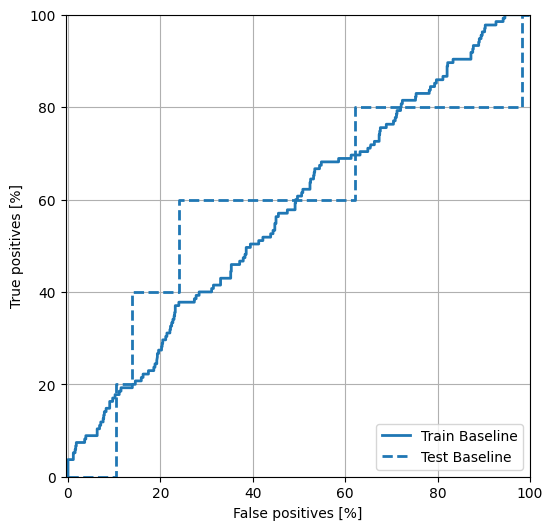

Best threshold: 0.7671502232551575
Number of true positives for the given ticker: 1
Number of false positives for the given ticker: 8
Precision score: 0.1111111111111111
Recall score: 0.2
Random guess score: 0.07936507936507936
true-positive per ticker: Orig_Ticker
NVDA    1
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
NVDA    8
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
NVDA    4
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
NVDA    0.111111
dtype: float64
recall per ticker: Orig_Ticker
NVDA    0.2
dtype: float64
rand guess per ticker: Orig_Ticker
NVDA    0.079365
dtype: float64
Some true positives
                          Date Orig_Ticker  y-predict-original  \
984  2024-12-19 00:00:00-05:00        NVDA            0.827055   

     y-value-original  Target-20D-Mean  Target-20D-Sigma  
984               1.0         0.018503          0.016181  
Some false positives
                          Date Orig_Tic

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 1 0 1 1 0 0 0 1 1 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = v

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['AAPL'] UNDERLYING_TARGET: Next-Day-Close-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:17 mode: simple LR_RATE: 0.001 STARTING_LR: 1e-05
fetch_finance_data_for_tickers: just returning file name: AAPL for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode simple is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode simple is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, b

{'AAPL': 0}
{'Tech': 0}
size before sigma app: 1041 for ticker: AAPL mean: 0.001385152363391233, sigma: 0.012232279879829387 upper_bound: 0.03808199200287939 lower_bound: -0.035311687276096924
size after sigma app: 1019 for ticker: AAPL
0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
972    0.0
973    0.0
974    1.0
975    0.0
976    0.0
Name: y-value, Length: 955, dtype: float64
0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
972    0.0
973    0.0
974    1.0
975    0.0
976    0.0
Name: y-value-original, Length: 955, dtype: float64
High-Low-Ratio                               0.644859
High-Open-Ratio                              0.619622
Close-Open-Ratio                             0.556369
Close-Prev-Close                             0.565959
MACD-Prev-MACD                               0.270057
200D-Ratio                                   0.546643
MACD_SIG                                     0.766335
MFI3                                         0.3

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 17, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_60 (Conv1D)  │ (None, 15, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_92 (PReLU)  │ (None, 15, 256)   │        256 │ conv1d_60[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_61 (Conv1D)  │ (None, 7, 256)    │    196,864 │ p_re_lu_92[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_93 (PReLU)  │ (None, 7, 256)    │        256 │ conv1d_61[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_62 (Conv1D)  │ (None, 3, 512)    │    393,728 │ p_re_lu_93[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_94 (PReLU)  │ (None, 3, 512)    │        512 │ conv1d_62[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_63 (Conv1D)  │ (None, 1, 512)    │    786,944 │ p_re_lu_94[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_95 (PReLU)  │ (None, 1, 512)    │        512 │ conv1d_63[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_24          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_24          │ (None, 512)       │          0 │ p_re_lu_95[0][0]  │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_24[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_25          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_24      │ (None, 1024)      │          0 │ flatten_24[0][0], │
│ (Concatenate)       │                   │            │ stock_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_dense        │ (None, 256)       │     33,024 │ reshape_25[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_25      │ (None, 1280)      │          0 │ concatenate_24[0

 Total params: 2,247,451 (8.57 MB)

 Trainable params: 2,247,451 (8.57 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 12s 959ms/step - AUC: 0.4804 - Precision: 0.1563 - Recall: 0.9849 - all_positives: 19.8786 - f1_score_metric: 34.1875 - loss: 2.4570 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2513.7830 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2513.7827 - val_AUC: 0.5577 - val_Precision: 0.2063 - val_Recall: 1.0000 - val_all_positives: 13.0000 - val_f1_score_metric: 21.5526 - val_loss: 2.6235 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 819.0001 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 819.0000 - learning_rate: 1.0000e-05
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 508ms/step - AUC: 0.5174 - Precision: 0.1408 - Recall: 0.9966 - all_positives: 17.7021 - f1_score_metric: 30.9284 - loss: 2.3899 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2236.9531 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2236.9531 - val_AUC: 0.5292 - val_Pre

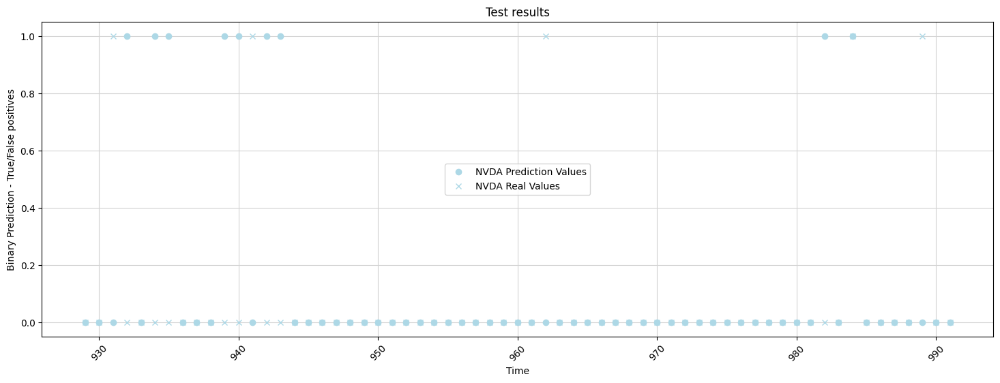

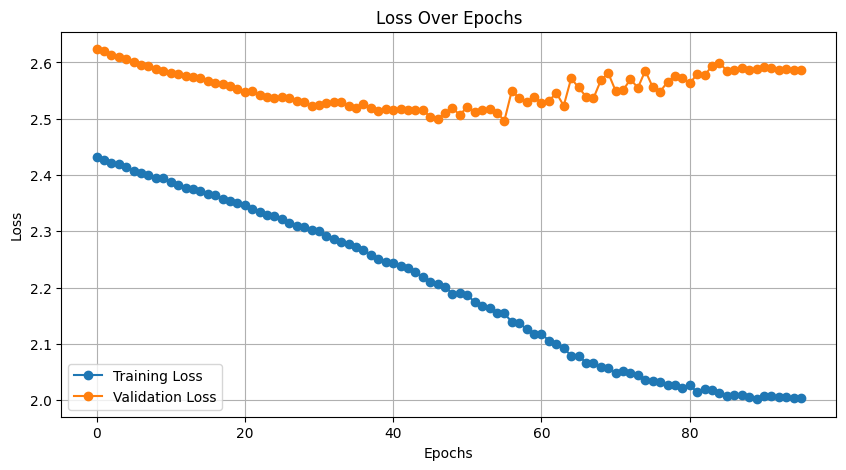

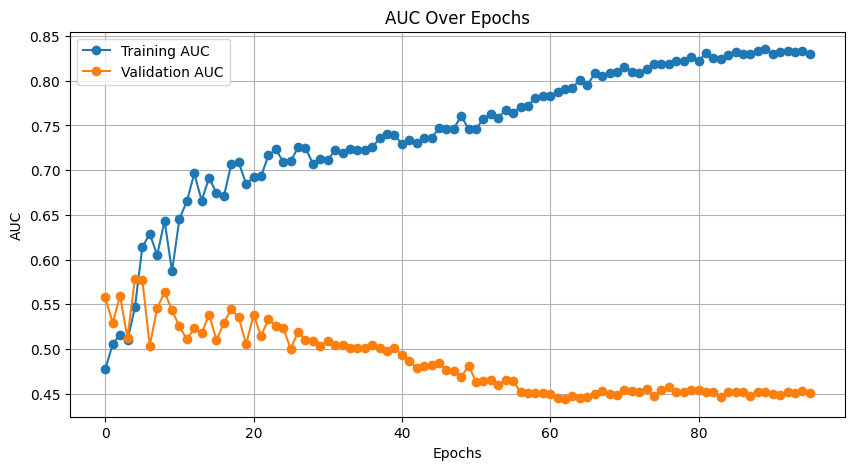



print_and_save_for
ticker data: AAPL


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
972        High-Low-Ratio  High-Open-Ratio  Close-O...   
973        High-Low-Ratio  High-Open-Ratio  Close-O...   
974        High-Low-Ratio  High-Open-Ratio  Close-O...   
975        High-Low-Ratio  High-Open-Ratio  Close-O...   
976        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2020-11-11 00:00:00-05:00       0       0         0.001385   
1    2020-11-12 00:00:00-05:00       0       0         0.001385   
2    2020-11-13 00:00:00-05:00       0     

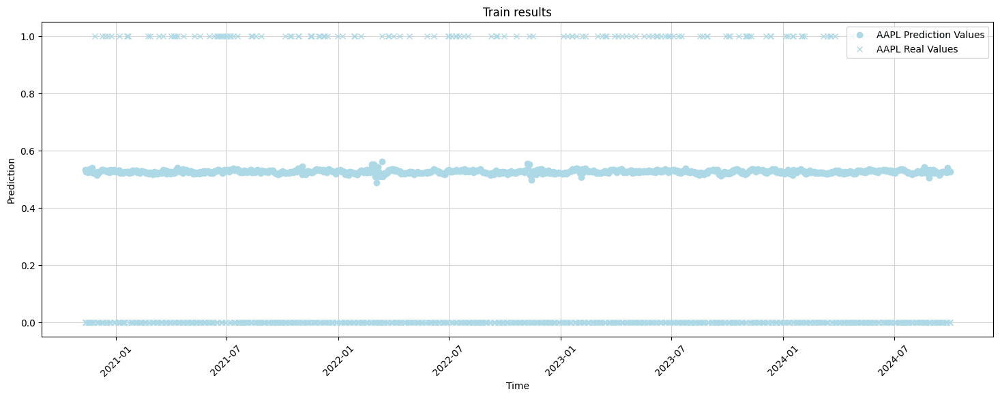

DONE PLOTTING 




print_and_save_for
ticker data: AAPL


Here is the data:                                                LstmData  \
977         High-Low-Ratio  High-Open-Ratio  Close-O...   
978         High-Low-Ratio  High-Open-Ratio  Close-O...   
979         High-Low-Ratio  High-Open-Ratio  Close-O...   
980         High-Low-Ratio  High-Open-Ratio  Close-O...   
981         High-Low-Ratio  High-Open-Ratio  Close-O...   
...                                                 ...   
1035        High-Low-Ratio  High-Open-Ratio  Close-O...   
1036        High-Low-Ratio  High-Open-Ratio  Close-O...   
1037        High-Low-Ratio  High-Open-Ratio  Close-O...   
1038        High-Low-Ratio  High-Open-Ratio  Close-O...   
1039        High-Low-Ratio  High-Open-Ratio  Close-O...   

                           Date  Ticker  Sector  Target-20D-Mean  \
977   2024-10-02 00:00:00-04:00       0       0         0.001385   
978   2024-10-03 00:00:00-04:00       0       0         0.001385   
979   2024-

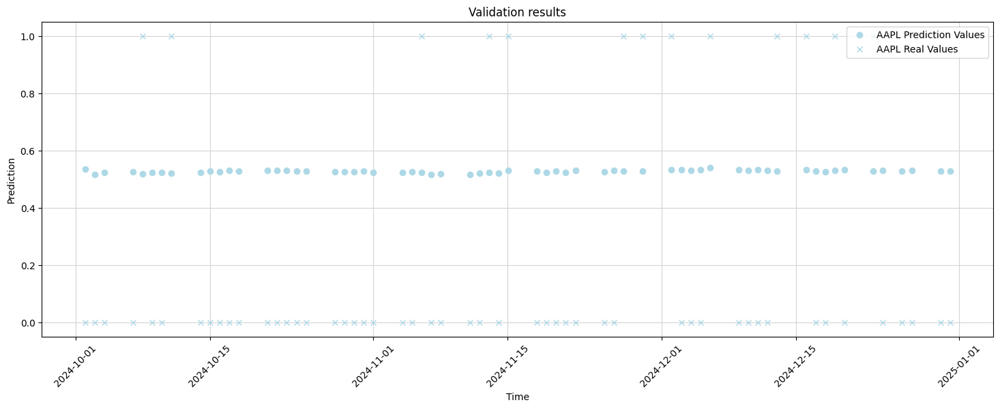

DONE PLOTTING 




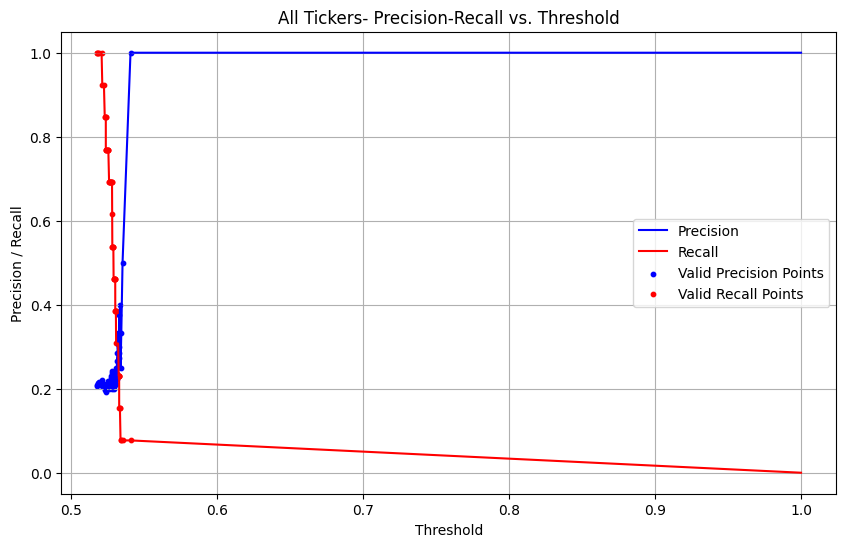

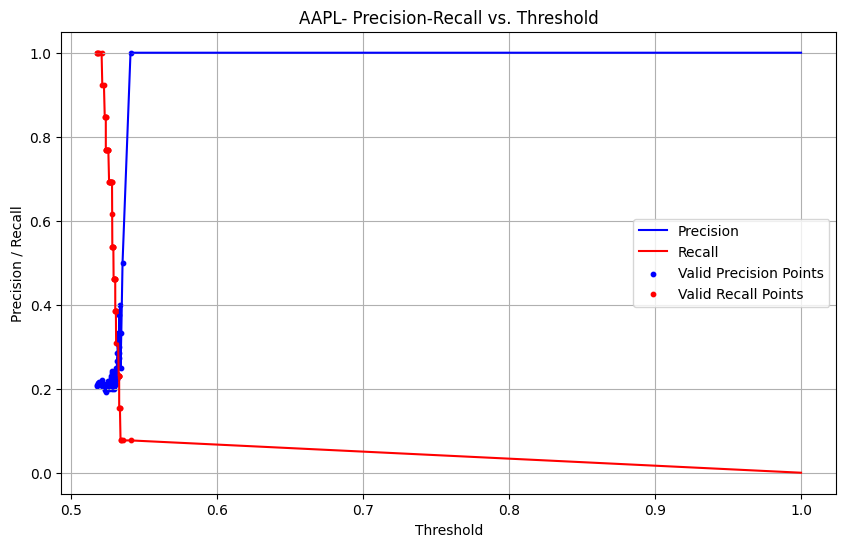

[0.         0.         0.00246609 0.00246609 0.00739827 0.00739827
 0.00863132 0.00863132 0.01233046 0.01233046 0.01479655 0.01479655
 0.01602959 0.01602959 0.01849568 0.01849568 0.027127   0.027127
 0.03452528 0.03452528 0.04069051 0.04069051 0.04192355 0.04192355
 0.05055487 0.05055487 0.05178792 0.05178792 0.06165228 0.06165228
 0.06411837 0.06411837 0.06535142 0.06535142 0.06658446 0.06658446
 0.06905055 0.06905055 0.07768187 0.07768187 0.08014797 0.08014797
 0.09371147 0.09371147 0.0998767  0.0998767  0.10234279 0.10234279
 0.10974106 0.10974106 0.12577065 0.12577065 0.1270037  0.1270037
 0.13810111 0.13810111 0.14796547 0.14796547 0.1541307  0.1541307
 0.16152898 0.16152898 0.1676942  0.1676942  0.17262639 0.17262639
 0.18125771 0.18125771 0.18742293 0.18742293 0.18988903 0.18988903
 0.19482121 0.19482121 0.20838471 0.20838471 0.21331689 0.21331689
 0.21454994 0.21454994 0.22071517 0.22071517 0.23797781 0.23797781
 0.23921085 0.23921085 0.25277435 0.25277435 0.25524044 0.25524044

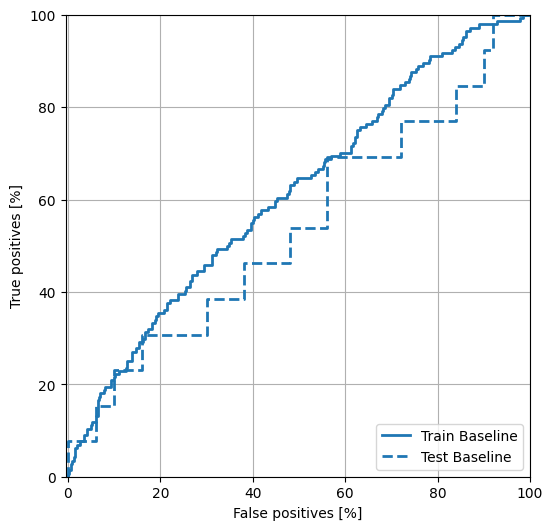

Best threshold: 0.532673716545105
Number of true positives for the given ticker: 2
Number of false positives for the given ticker: 5
Precision score: 0.2857142857142857
Recall score: 0.15384615384615385
Random guess score: 0.20634920634920634
true-positive per ticker: Orig_Ticker
AAPL    2
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
AAPL    5
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
AAPL    11
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
AAPL    0.285714
dtype: float64
recall per ticker: Orig_Ticker
AAPL    0.153846
dtype: float64
rand guess per ticker: Orig_Ticker
AAPL    0.206349
dtype: float64
Some true positives
                           Date Orig_Ticker  y-predict-original  \
1023  2024-12-06 00:00:00-05:00        AAPL            0.540453   
1019  2024-12-02 00:00:00-05:00        AAPL            0.533202   

      y-value-original  Target-20D-Mean  Target-20D-Sigma  
1023               1.0      

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 1 0 0 1 1 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 1 0 0 0 0
 0 0 0 1 1 1 0 0 0 1 0 0 0 0 1 1 0 0 1 0 1 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = v

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['AAPL'] UNDERLYING_TARGET: Next-Day-Close-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:33 mode: medium LR_RATE: 0.0005 STARTING_LR: 0.0001
fetch_finance_data_for_tickers: just returning file name: AAPL for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode medium is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode medium is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, b

{'AAPL': 0}
{'Tech': 0}
size before sigma app: 1025 for ticker: AAPL mean: 0.001385152363391233, sigma: 0.012232279879829389 upper_bound: 0.0380819920028794 lower_bound: -0.03531168727609693
size after sigma app: 1003 for ticker: AAPL
0      0.0
1      0.0
2      0.0
3      1.0
4      0.0
      ... 
956    0.0
957    0.0
958    1.0
959    0.0
960    0.0
Name: y-value, Length: 939, dtype: float64
0      0.0
1      0.0
2      0.0
3      1.0
4      0.0
      ... 
956    0.0
957    0.0
958    1.0
959    0.0
960    0.0
Name: y-value-original, Length: 939, dtype: float64
High-Low-Ratio                               0.644859
High-Open-Ratio                              0.619622
Close-Open-Ratio                             0.556369
Close-Prev-Close                             0.565959
MACD-Prev-MACD                               0.270057
200D-Ratio                                   0.546643
MACD_SIG                                     0.766335
MFI3                                         0.342

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 33, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_64 (Conv1D)  │ (None, 31, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_98 (PReLU)  │ (None, 31, 256)   │        256 │ conv1d_64[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_65 (Conv1D)  │ (None, 15, 256)   │    196,864 │ p_re_lu_98[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_99 (PReLU)  │ (None, 15, 256)   │        256 │ conv1d_65[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_66 (Conv1D)  │ (None, 7, 512)    │    393,728 │ p_re_lu_99[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_100 (PReLU) │ (None, 7, 512)    │        512 │ conv1d_66[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_67 (Conv1D)  │ (None, 3, 512)    │    786,944 │ p_re_lu_100[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_101 (PReLU) │ (None, 3, 512)    │        512 │ conv1d_67[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_68 (Conv1D)  │ (None, 1, 1024)   │  1,573,888 │ p_re_lu_101[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_102 (PReLU) │ (None, 1, 1024)   │      1,024 │ conv1d_68[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_26          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_26          │ (None, 1024)      │          0 │ p_re_lu_102[0][0] │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_26[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_27          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_26      │ (None, 1536)      │          0 │ flatten_26[0][0], │
│ (Concatenate)       │                   │            │ stock_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 7,696,364 (29.36 MB)

 Trainable params: 7,696,364 (29.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - AUC: 0.4820 - Precision: 0.1374 - Recall: 0.5326 - all_positives: 17.9701 - f1_score_metric: 20.7015 - loss: 2.1595 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 1181.5542 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 1181.5542 - val_AUC: 0.4631 - val_Precision: 0.2063 - val_Recall: 1.0000 - val_all_positives: 13.0000 - val_f1_score_metric: 21.5526 - val_loss: 2.3359 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 819.0001 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 819.0000 - learning_rate: 1.0000e-04
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 524ms/step - AUC: 0.5525 - Precision: 0.1476 - Recall: 1.0000 - all_positives: 18.5299 - f1_score_metric: 32.2051 - loss: 2.1406 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2352.9375 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2352.9375 - val_AUC: 0.4200 - val_Precis

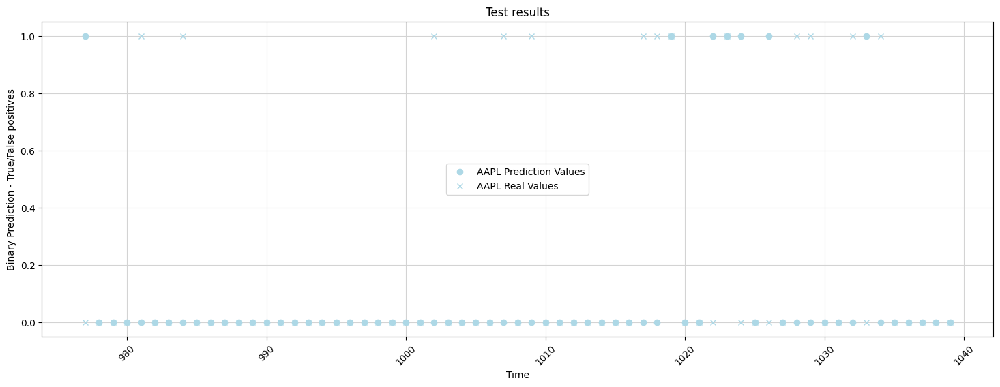

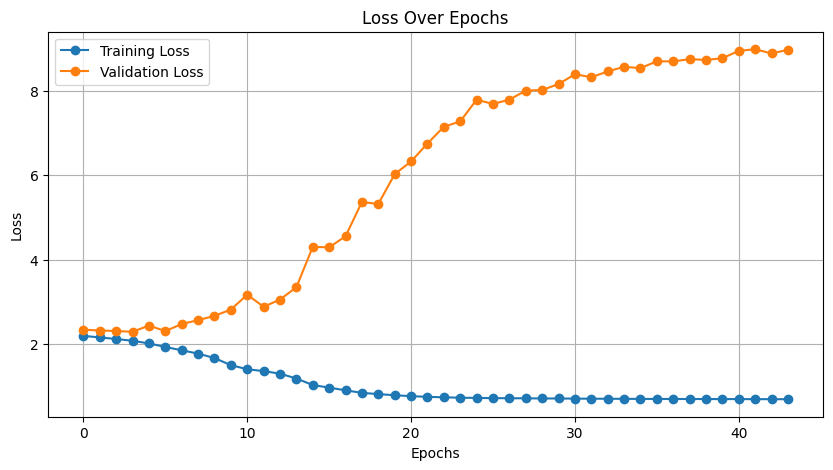

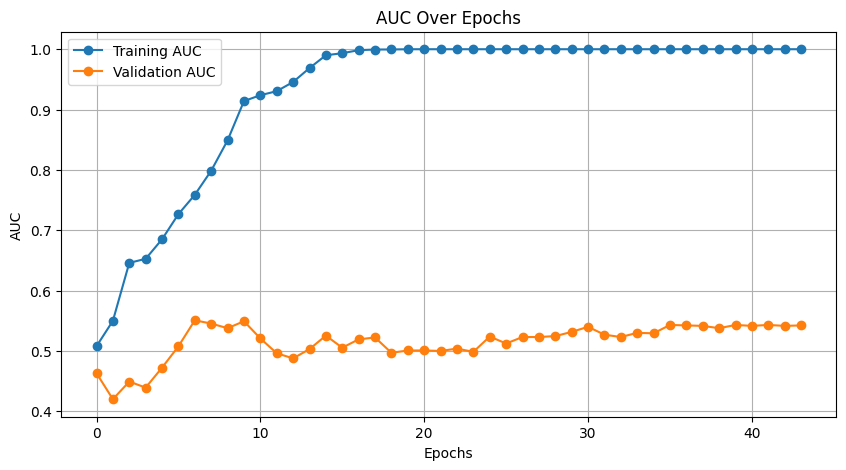



print_and_save_for
ticker data: AAPL


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
956        High-Low-Ratio  High-Open-Ratio  Close-O...   
957        High-Low-Ratio  High-Open-Ratio  Close-O...   
958        High-Low-Ratio  High-Open-Ratio  Close-O...   
959        High-Low-Ratio  High-Open-Ratio  Close-O...   
960        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2020-12-04 00:00:00-05:00       0       0         0.001385   
1    2020-12-07 00:00:00-05:00       0       0         0.001385   
2    2020-12-08 00:00:00-05:00       0     

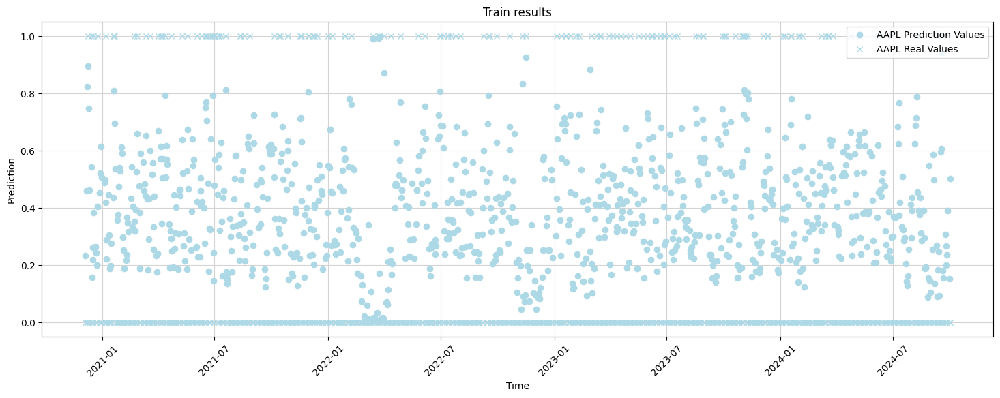

DONE PLOTTING 




print_and_save_for
ticker data: AAPL


Here is the data:                                                LstmData  \
961         High-Low-Ratio  High-Open-Ratio  Close-O...   
962         High-Low-Ratio  High-Open-Ratio  Close-O...   
963         High-Low-Ratio  High-Open-Ratio  Close-O...   
964         High-Low-Ratio  High-Open-Ratio  Close-O...   
965         High-Low-Ratio  High-Open-Ratio  Close-O...   
...                                                 ...   
1019        High-Low-Ratio  High-Open-Ratio  Close-O...   
1020        High-Low-Ratio  High-Open-Ratio  Close-O...   
1021        High-Low-Ratio  High-Open-Ratio  Close-O...   
1022        High-Low-Ratio  High-Open-Ratio  Close-O...   
1023        High-Low-Ratio  High-Open-Ratio  Close-O...   

                           Date  Ticker  Sector  Target-20D-Mean  \
961   2024-10-02 00:00:00-04:00       0       0         0.001385   
962   2024-10-03 00:00:00-04:00       0       0         0.001385   
963   2024-

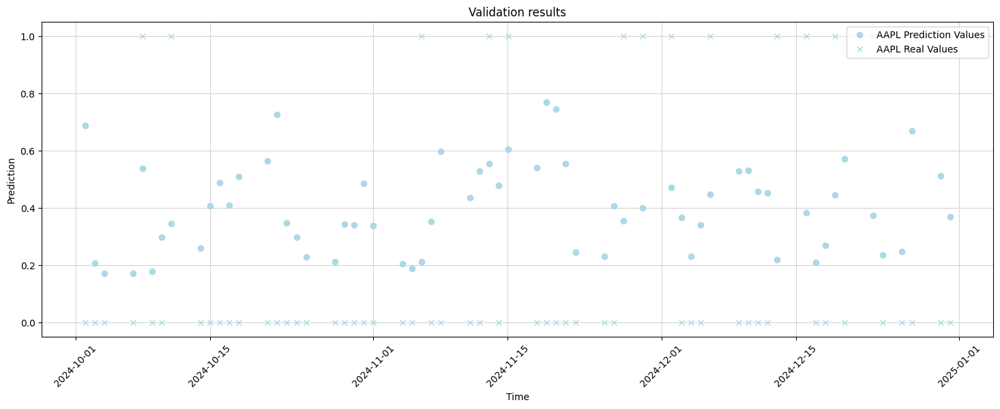

DONE PLOTTING 




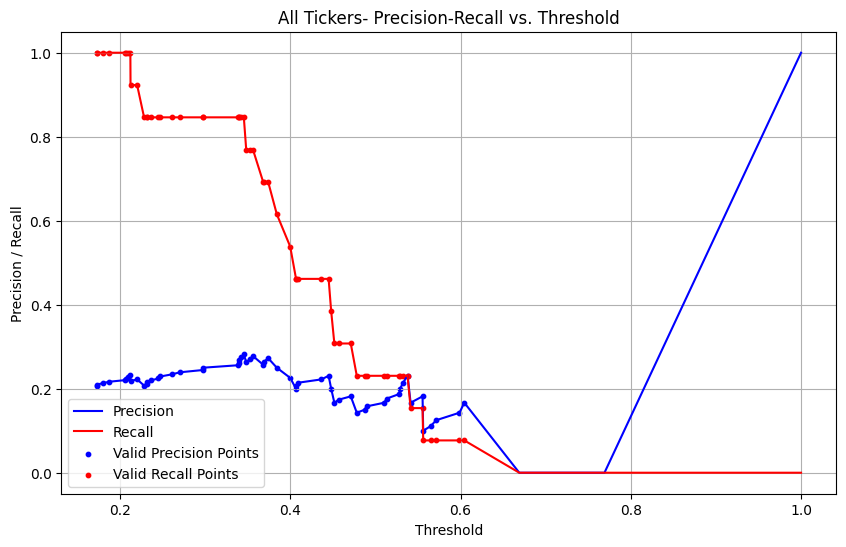

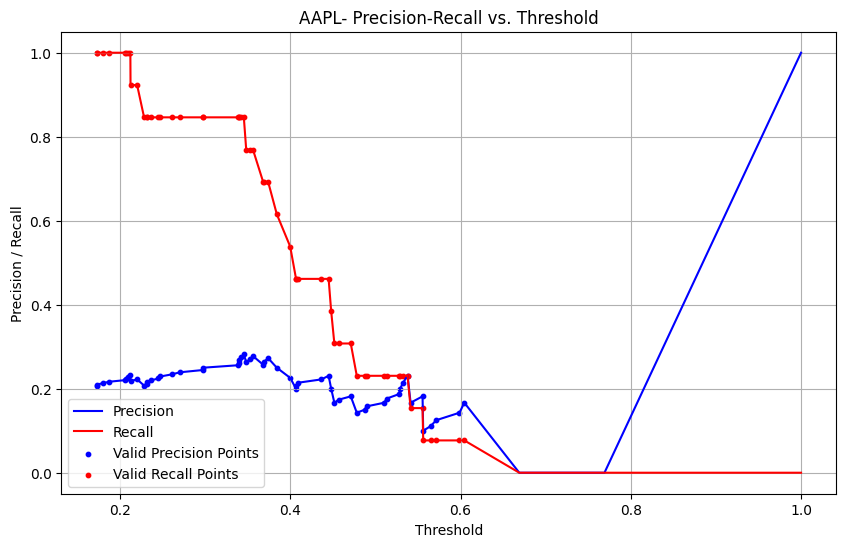

[0.         0.         0.         0.00125628 0.00125628 0.00251256
 0.00251256 0.00376884 0.00376884 0.00628141 0.00628141 0.00753769
 0.00753769 0.00879397 0.00879397 0.01005025 0.01005025 0.01256281
 0.01256281 0.01507538 0.01507538 0.01758794 0.01758794 0.01884422
 0.01884422 0.02135678 0.02135678 0.02261307 0.02261307 0.02889447
 0.02889447 0.03015075 0.03015075 0.03266332 0.03266332 0.03643216
 0.03643216 0.03768844 0.03768844 0.03894472 0.03894472 0.04020101
 0.04020101 0.04145729 0.04145729 0.04396985 0.04396985 0.05150754
 0.05150754 0.0540201  0.0540201  0.05653266 0.05653266 0.05778894
 0.05778894 0.06532663 0.06532663 0.06658291 0.06658291 0.07286432
 0.07286432 0.07537688 0.07537688 0.07788945 0.07788945 0.08291457
 0.08291457 0.09547739 0.09547739 0.09798995 0.09798995 0.09924623
 0.09924623 0.10678392 0.10678392 0.11683417 0.11683417 0.11934673
 0.11934673 0.12311558 0.12311558 0.12437186 0.12437186 0.12939698
 0.12939698 0.13316583 0.13316583 0.13567839 0.13567839 0.1381

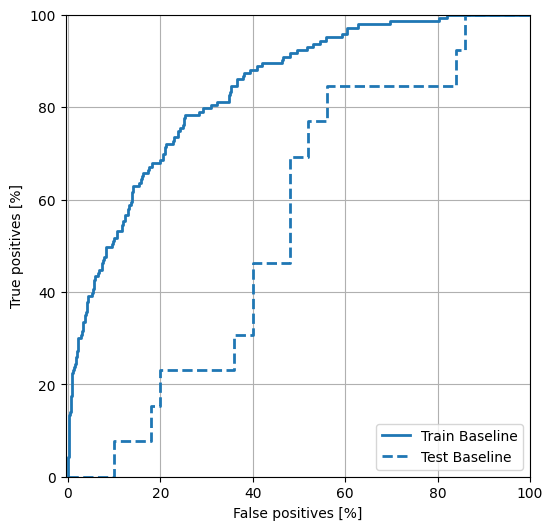

Best threshold: 0.345425546169281
Number of true positives for the given ticker: 10
Number of false positives for the given ticker: 28
Precision score: 0.2631578947368421
Recall score: 0.7692307692307693
Random guess score: 0.20634920634920634
true-positive per ticker: Orig_Ticker
AAPL    10
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
AAPL    28
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
AAPL    3
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
AAPL    0.263158
dtype: float64
recall per ticker: Orig_Ticker
AAPL    0.769231
dtype: float64
rand guess per ticker: Orig_Ticker
AAPL    0.206349
dtype: float64
Some true positives
                           Date Orig_Ticker  y-predict-original  \
1016  2024-12-19 00:00:00-05:00        AAPL            0.445030   
991   2024-11-13 00:00:00-05:00        AAPL            0.555363   
1003  2024-12-02 00:00:00-05:00        AAPL            0.471039   
965   2024-10-08 00:

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[1 0 0 0 1 0 0 0 0 1 1 1 1 1 1 1 0 0 0 0 0 1 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1
 0 0 1 1 1 1 1 0 0 1 1 1 1 1 0 1 0 0 1 1 1 0 0 1 1 1]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 1 0 0 0 0
 0 0 0 1 1 1 0 0 0 1 0 0 0 0 1 1 0 0 1 0 1 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = v

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['AAPL'] UNDERLYING_TARGET: Next-Day-Close-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:65 mode: complex LR_RATE: 0.0001 STARTING_LR: 0.001
fetch_finance_data_for_tickers: just returning file name: AAPL for interval: 5y


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode complex is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode complex is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")


object


...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 65, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_69 (Conv1D)  │ (None, 63, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_106 (PReLU) │ (None, 63, 256)   │        256 │ conv1d_69[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_70 (Conv1D)  │ (None, 31, 256)   │    196,864 │ p_re_lu_106[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_107 (PReLU) │ (None, 31, 256)   │        256 │ conv1d_70[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_71 (Conv1D)  │ (None, 15, 512)   │    393,728 │ p_re_lu_107[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_108 (PReLU) │ (None, 15, 512)   │        512 │ conv1d_71[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_72 (Conv1D)  │ (None, 7, 512)    │    786,944 │ p_re_lu_108[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_109 (PReLU) │ (None, 7, 512)    │        512 │ conv1d_72[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_73 (Conv1D)  │ (None, 3, 1024)   │  1,573,888 │ p_re_lu_109[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_110 (PReLU) │ (None, 3, 1024)   │      1,024 │ conv1d_73[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_74 (Conv1D)  │ (None, 1, 1024)   │  3,146,752 │ p_re_lu_110[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_111 (PReLU) │ (None, 1, 1024)   │      1,024 │ conv1d_74[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_28          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_28          │ (None, 1024)      │          0 │ p_re_lu_111[0][0] │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_28[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_29          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                 

 Total params: 10,844,140 (41.37 MB)

 Trainable params: 10,844,140 (41.37 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - AUC: 0.4971 - Precision: 0.1781 - Recall: 0.2691 - all_positives: 17.4786 - f1_score_metric: 13.0103 - loss: 1.5832 - precision_with_threshold_fixed: 2.8349 - recall_mul_prediction: 504.0079 - recall_with_threshold_fixed: 18.5016 - true_positives: 504.0079 - val_AUC: 0.5000 - val_Precision: 0.2063 - val_Recall: 1.0000 - val_all_positives: 13.0000 - val_f1_score_metric: 21.5526 - val_loss: 1.7032 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 819.0001 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 819.0000 - learning_rate: 0.0010
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 701ms/step - AUC: 0.5345 - Precision: 0.1470 - Recall: 1.0000 - all_positives: 18.3265 - f1_score_metric: 31.8506 - loss: 1.5055 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2329.5364 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2329.5364 - val_AUC: 0.5000 - val_Precision: 0.2063 -

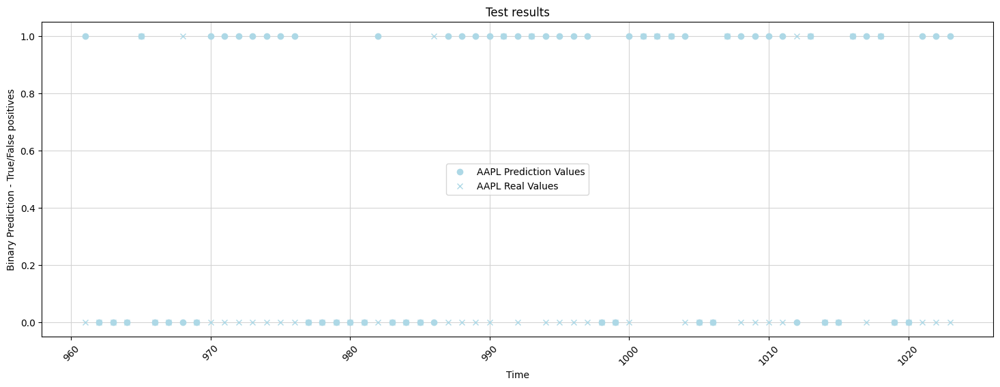

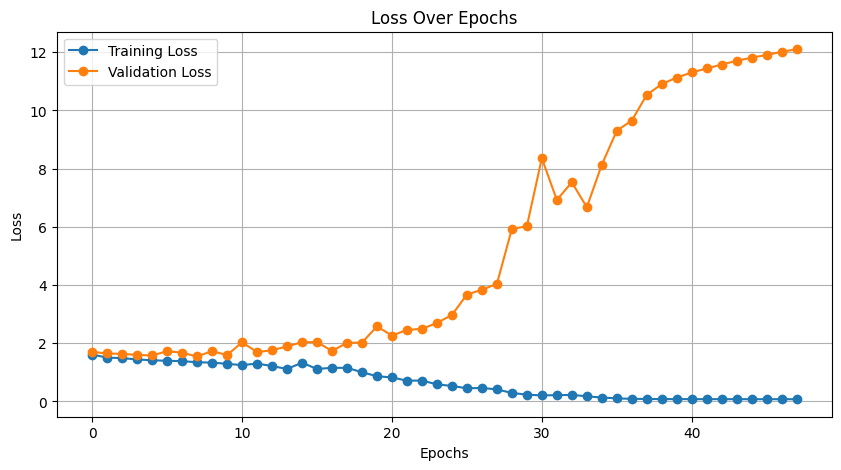

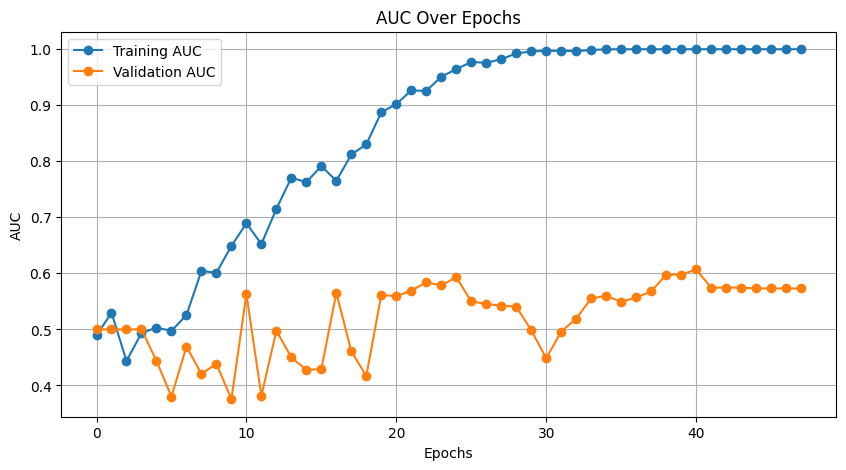



print_and_save_for
ticker data: AAPL


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
924        High-Low-Ratio  High-Open-Ratio  Close-O...   
925        High-Low-Ratio  High-Open-Ratio  Close-O...   
926        High-Low-Ratio  High-Open-Ratio  Close-O...   
927        High-Low-Ratio  High-Open-Ratio  Close-O...   
928        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2021-01-22 00:00:00-05:00       0       0         0.001385   
1    2021-01-25 00:00:00-05:00       0       0         0.001385   
2    2021-01-26 00:00:00-05:00       0     

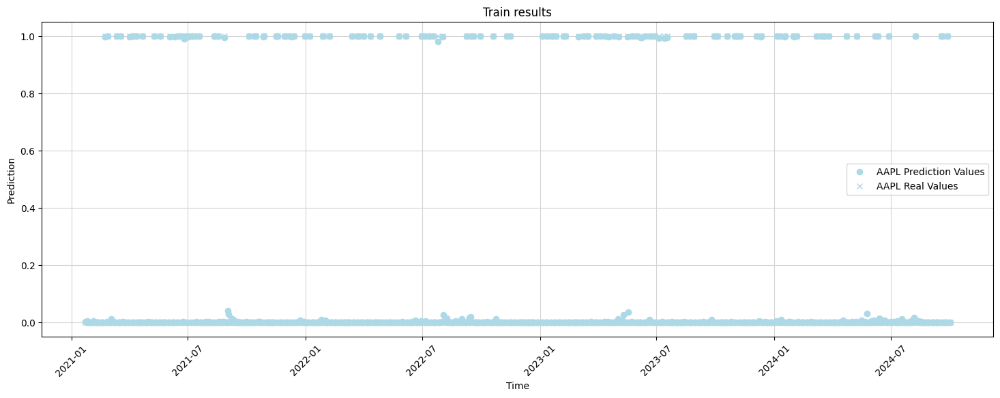

DONE PLOTTING 




print_and_save_for
ticker data: AAPL


Here is the data:                                               LstmData  \
929        High-Low-Ratio  High-Open-Ratio  Close-O...   
930        High-Low-Ratio  High-Open-Ratio  Close-O...   
931        High-Low-Ratio  High-Open-Ratio  Close-O...   
932        High-Low-Ratio  High-Open-Ratio  Close-O...   
933        High-Low-Ratio  High-Open-Ratio  Close-O...   
..                                                 ...   
987        High-Low-Ratio  High-Open-Ratio  Close-O...   
988        High-Low-Ratio  High-Open-Ratio  Close-O...   
989        High-Low-Ratio  High-Open-Ratio  Close-O...   
990        High-Low-Ratio  High-Open-Ratio  Close-O...   
991        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
929  2024-10-02 00:00:00-04:00       0       0         0.001385   
930  2024-10-03 00:00:00-04:00       0       0         0.001385   
931  2024-10-04 00:00:00-0

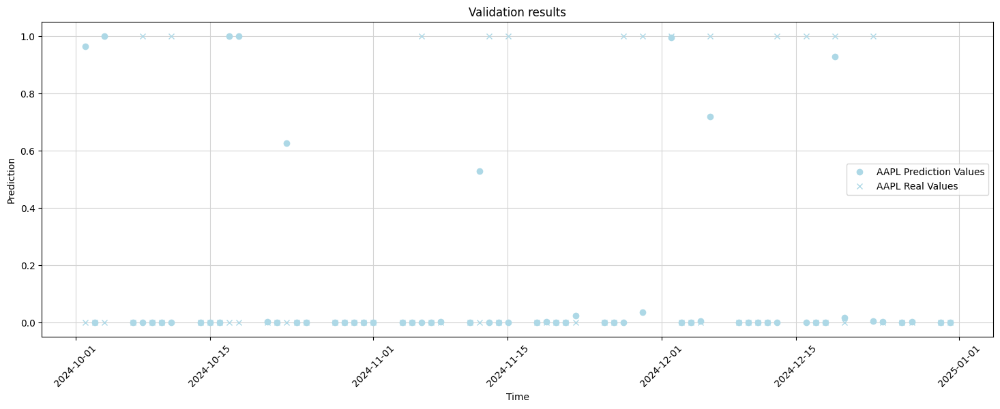

DONE PLOTTING 




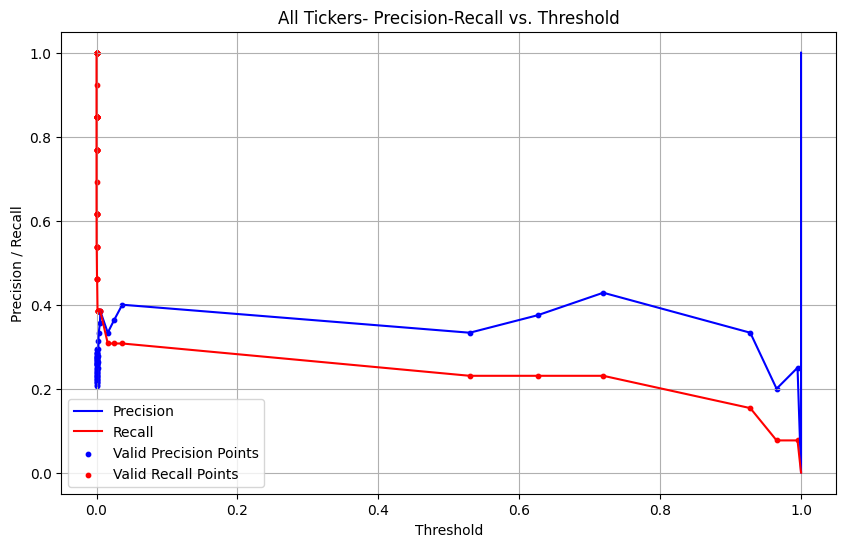

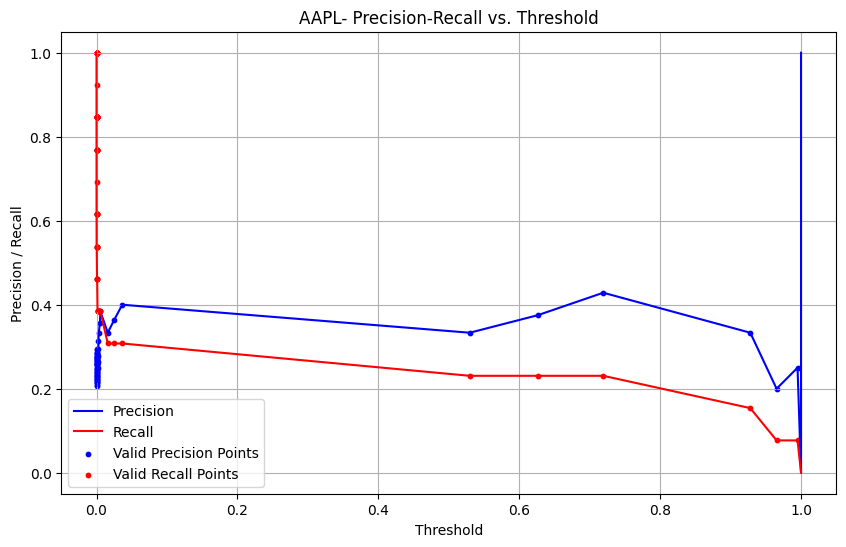

[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.93911917 1.        ]
[0.         0.17777778 0.2        0.23703704 0.25185185 0.25925926
 0.28888889 0.34074074 0.35555556 0.52592593 0.54074074 1.
 1.         1.        ]
[0.   0.02 0.06 0.06 0.08 0.08 0.12 0.12 0.16 0.16 0.3  0.3  0.34 0.34
 0.4  0.4  0.48 0.48 0.58 0.58 0.8  0.8  1.  ]
[0.         0.         0.         0.07692308 0.07692308 0.23076923
 0.23076923 0.30769231 0.30769231 0.38461538 0.38461538 0.46153846
 0.46153846 0.53846154 0.53846154 0.61538462 0.61538462 0.76923077
 0.76923077 0.84615385 0.84615385 1.         1.        ]


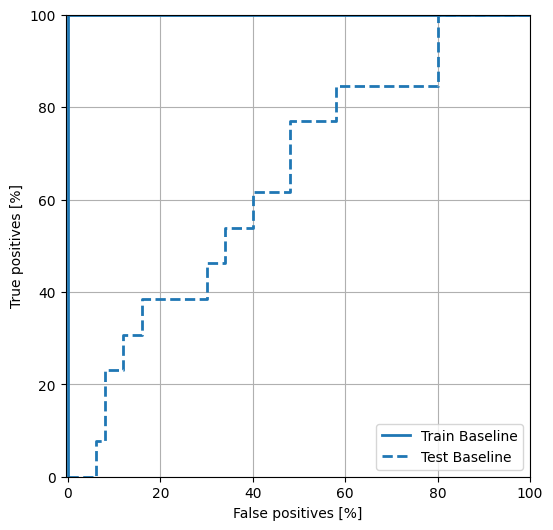

Best threshold: 0.005429374054074287


/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[1 0 1 0 0 0 0 0 0 0 0 1 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0
 1 0 0 0 1 1 0 0 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 1 0 0 0 0
 0 0 0 1 1 1 0 0 0 1 0 0 0 0 1 1 0 0 1 0 1 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = v

Number of true positives for the given ticker: 4
Number of false positives for the given ticker: 8
Precision score: 0.3333333333333333
Recall score: 0.3076923076923077
Random guess score: 0.20634920634920634
true-positive per ticker: Orig_Ticker
AAPL    4
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
AAPL    8
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
AAPL    9
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
AAPL    0.333333
dtype: float64
recall per ticker: Orig_Ticker
AAPL    0.307692
dtype: float64
rand guess per ticker: Orig_Ticker
AAPL    0.206349
dtype: float64
Some true positives
                          Date Orig_Ticker  y-predict-original  \
971  2024-12-02 00:00:00-05:00        AAPL            0.995008   
984  2024-12-19 00:00:00-05:00        AAPL            0.927935   
970  2024-11-29 00:00:00-05:00        AAPL            0.036565   
975  2024-12-06 00:00:00-05:00        AAPL            0.719254

/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:500: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_frame["Ticker"] = data_frame["Ticker"].replace(stock_dict)
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:515: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_frame["Sector"] = data_frame["Sector"].replace(sector_dict)


Model: "functional_15"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 17, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_75 (Conv1D)  │ (None, 15, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_115 (PReLU) │ (None, 15, 256)   │        256 │ conv1d_75[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_76 (Conv1D)  │ (None, 7, 256)    │    196,864 │ p_re_lu_115[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_116 (PReLU) │ (None, 7, 256)    │        256 │ conv1d_76[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_77 (Conv1D)  │ (None, 3, 512)    │    393,728 │ p_re_lu_116[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_117 (PReLU) │ (None, 3, 512)    │        512 │ conv1d_77[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_78 (Conv1D)  │ (None, 1, 512)    │    786,944 │ p_re_lu_117[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_118 (PReLU) │ (None, 1, 512)    │        512 │ conv1d_78[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_30          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_30          │ (None, 512)       │          0 │ p_re_lu_118[0][0] │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_30[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_31          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_30      │ (None, 1024)      │          0 │ flatten_30[0][0], │
│ (Concatenate)       │                   │            │ stock_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_dense        │ (None, 256)       │     33,024 │ reshape_31[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_31      │ (None, 1280)      │          0 │ concatenate_30[0

 Total params: 2,247,451 (8.57 MB)

 Trainable params: 2,247,451 (8.57 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 11s 809ms/step - AUC: 0.5081 - Precision: 0.1682 - Recall: 0.9412 - all_positives: 20.1124 - f1_score_metric: 33.8581 - loss: 2.4258 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2262.9888 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2262.9888 - val_AUC: 0.5010 - val_Precision: 0.1429 - val_Recall: 1.0000 - val_all_positives: 9.0000 - val_f1_score_metric: 15.7500 - val_loss: 2.3647 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 567.0001 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 567.0000 - learning_rate: 1.0000e-05
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 480ms/step - AUC: 0.5482 - Precision: 0.1618 - Recall: 0.9650 - all_positives: 20.5251 - f1_score_metric: 35.0033 - loss: 2.4313 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2521.5925 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2521.5925 - val_AUC: 0.5175 - val_Prec

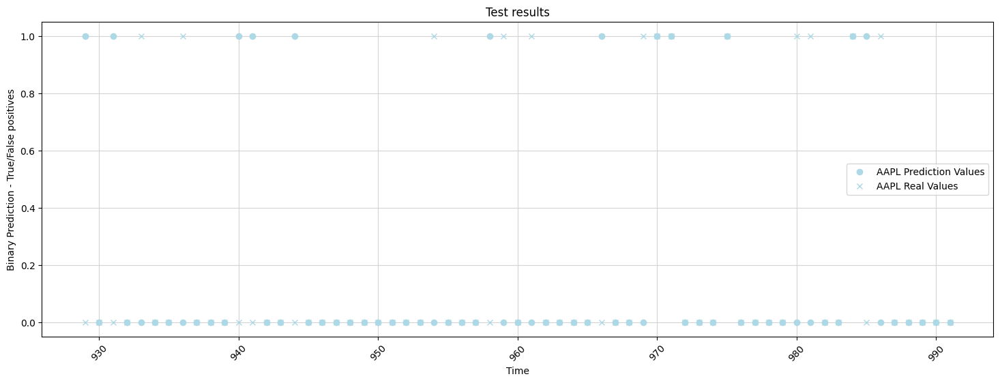

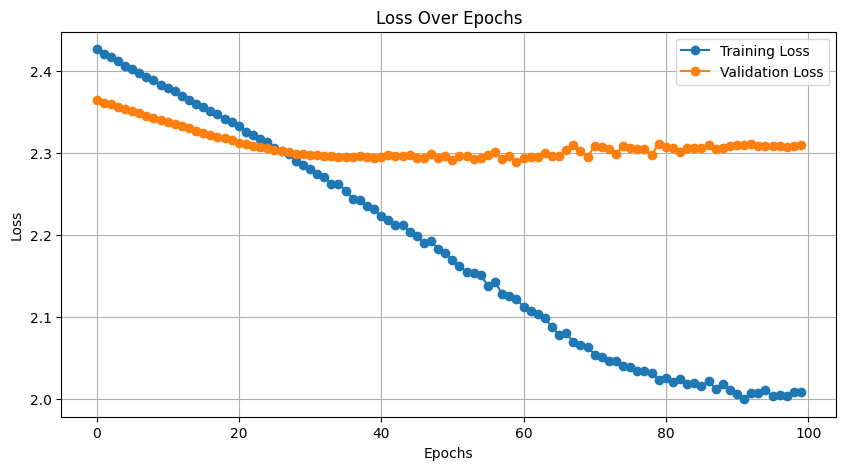

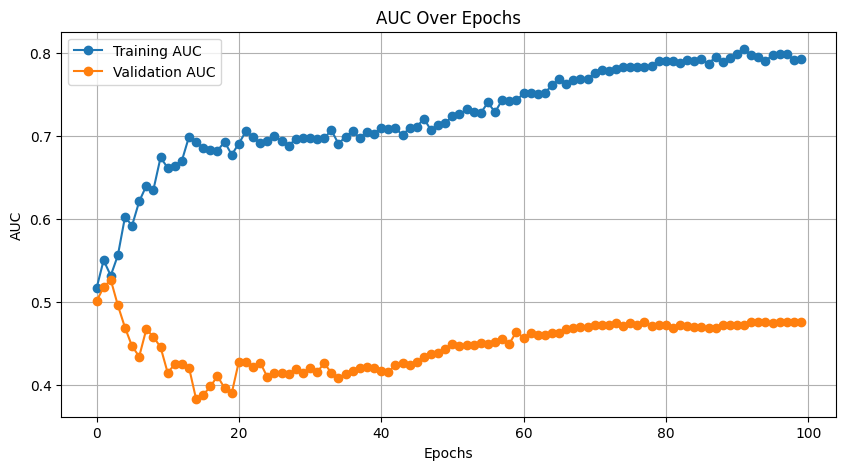



print_and_save_for
ticker data: AAPL


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
972        High-Low-Ratio  High-Open-Ratio  Close-O...   
973        High-Low-Ratio  High-Open-Ratio  Close-O...   
974        High-Low-Ratio  High-Open-Ratio  Close-O...   
975        High-Low-Ratio  High-Open-Ratio  Close-O...   
976        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2020-11-11 00:00:00-05:00       0       0          0.00992   
1    2020-11-12 00:00:00-05:00       0       0          0.00992   
2    2020-11-13 00:00:00-05:00       0     

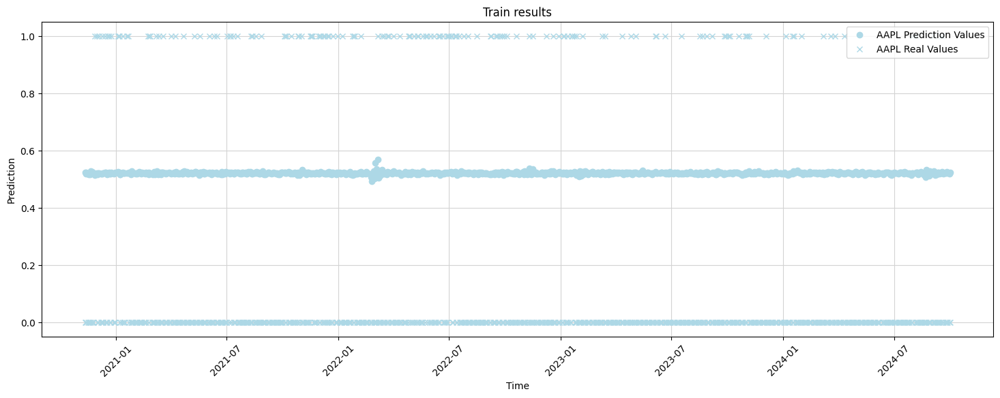

DONE PLOTTING 




print_and_save_for
ticker data: AAPL


Here is the data:                                                LstmData  \
977         High-Low-Ratio  High-Open-Ratio  Close-O...   
978         High-Low-Ratio  High-Open-Ratio  Close-O...   
979         High-Low-Ratio  High-Open-Ratio  Close-O...   
980         High-Low-Ratio  High-Open-Ratio  Close-O...   
981         High-Low-Ratio  High-Open-Ratio  Close-O...   
...                                                 ...   
1035        High-Low-Ratio  High-Open-Ratio  Close-O...   
1036        High-Low-Ratio  High-Open-Ratio  Close-O...   
1037        High-Low-Ratio  High-Open-Ratio  Close-O...   
1038        High-Low-Ratio  High-Open-Ratio  Close-O...   
1039        High-Low-Ratio  High-Open-Ratio  Close-O...   

                           Date  Ticker  Sector  Target-20D-Mean  \
977   2024-10-02 00:00:00-04:00       0       0          0.00992   
978   2024-10-03 00:00:00-04:00       0       0          0.00992   
979   2024-

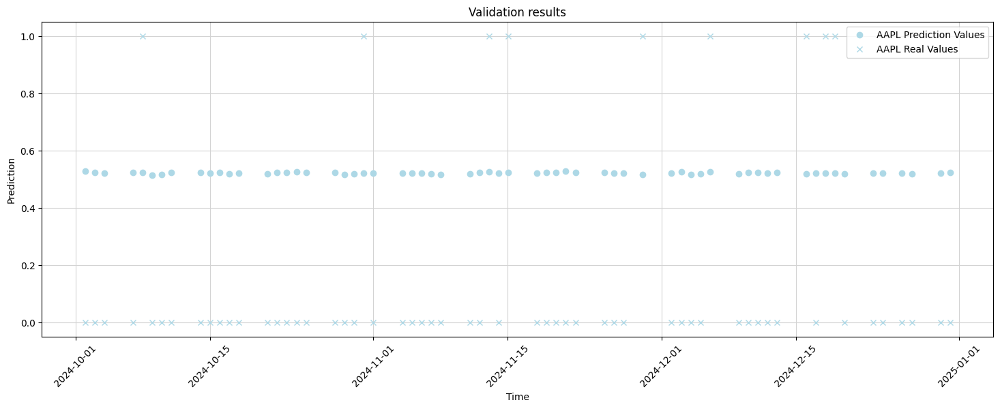

DONE PLOTTING 




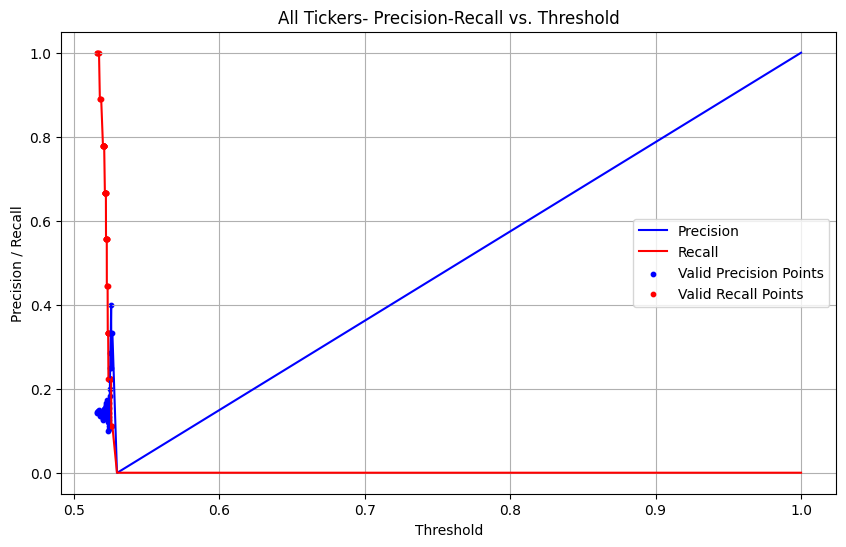

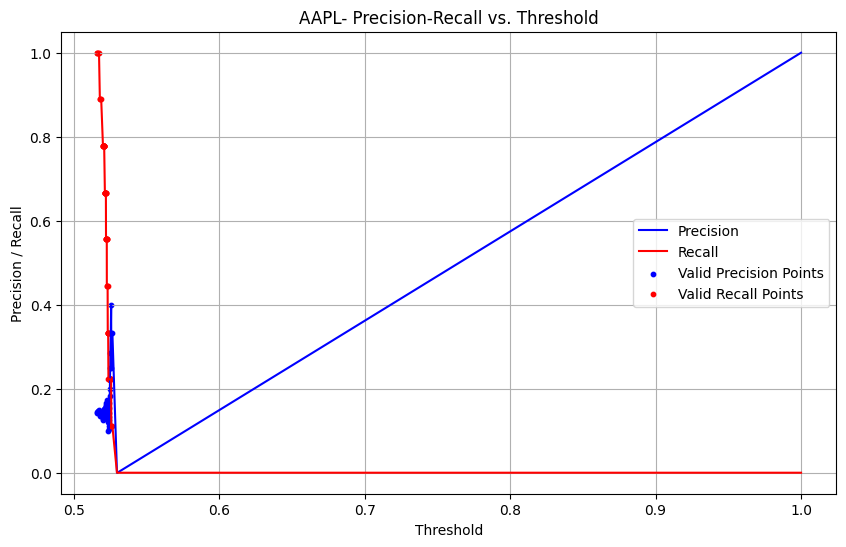

[0.         0.         0.00123609 0.00123609 0.00494438 0.00494438
 0.00865266 0.00865266 0.01359703 0.01359703 0.01483313 0.01483313
 0.02719407 0.02719407 0.03461063 0.03461063 0.04449938 0.04449938
 0.04820766 0.04820766 0.05686032 0.05686032 0.05809642 0.05809642
 0.05933251 0.05933251 0.0605686  0.0605686  0.0618047  0.0618047
 0.07416564 0.07416564 0.07540173 0.07540173 0.07663782 0.07663782
 0.0815822  0.0815822  0.08529048 0.08529048 0.08652658 0.08652658
 0.09023486 0.09023486 0.09765142 0.09765142 0.10754017 0.10754017
 0.11990111 0.11990111 0.12855377 0.12855377 0.13102596 0.13102596
 0.13597033 0.13597033 0.13720643 0.13720643 0.15080346 0.15080346
 0.15698393 0.15698393 0.1631644  0.1631644  0.17676143 0.17676143
 0.18046972 0.18046972 0.18665019 0.18665019 0.20519159 0.20519159
 0.20766378 0.20766378 0.21013597 0.21013597 0.21137206 0.21137206
 0.21260816 0.21260816 0.21508035 0.21508035 0.23238566 0.23238566
 0.24351051 0.24351051 0.25339926 0.25339926 0.26205192 0.26205

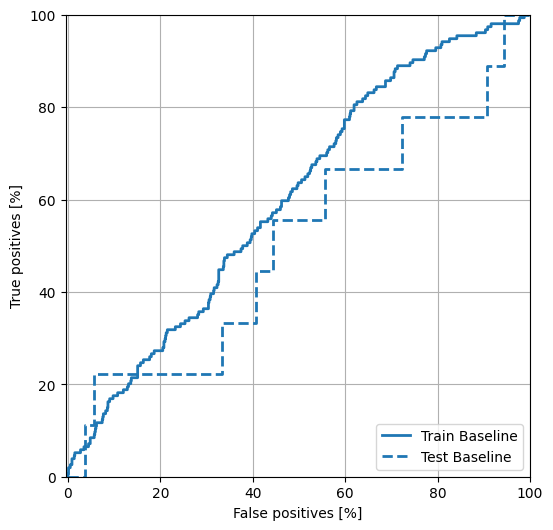

Best threshold: 0.5256847739219666
Number of true positives for the given ticker: 1
Number of false positives for the given ticker: 3
Precision score: 0.25
Recall score: 0.1111111111111111
Random guess score: 0.14285714285714285
true-positive per ticker: Orig_Ticker
AAPL    1
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
AAPL    3
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
AAPL    8
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
AAPL    0.25
dtype: float64
recall per ticker: Orig_Ticker
AAPL    0.111111
dtype: float64
rand guess per ticker: Orig_Ticker
AAPL    0.142857
dtype: float64
Some true positives
                           Date Orig_Ticker  y-predict-original  \
1007  2024-11-13 00:00:00-05:00        AAPL            0.526534   

      y-value-original  Target-20D-Mean  Target-20D-Sigma  
1007               1.0          0.00992          0.009971  
Some false positives
                           Date O

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1
 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0
 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 1 0 1 1 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = v

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['AAPL'] UNDERLYING_TARGET: Next-Day-High-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:33 mode: medium LR_RATE: 0.0005 STARTING_LR: 0.0001
fetch_finance_data_for_tickers: just returning file name: AAPL for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode medium is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode medium is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, b

{'AAPL': 0}
{'Tech': 0}
size before sigma app: 1025 for ticker: AAPL mean: 0.009920074564524758, sigma: 0.009970945611285134 upper_bound: 0.03983291139838016 lower_bound: -0.019992762269330642
size after sigma app: 1011 for ticker: AAPL
0      1.0
1      0.0
2      0.0
3      1.0
4      0.0
      ... 
956    0.0
957    0.0
958    0.0
959    0.0
960    0.0
Name: y-value, Length: 947, dtype: float64
0      1.0
1      0.0
2      0.0
3      1.0
4      0.0
      ... 
956    0.0
957    0.0
958    0.0
959    0.0
960    0.0
Name: y-value-original, Length: 947, dtype: float64
High-Low-Ratio                               0.644859
High-Open-Ratio                              0.619622
Close-Open-Ratio                             0.556369
Close-Prev-Close                             0.565959
MACD-Prev-MACD                               0.270057
200D-Ratio                                   0.546643
MACD_SIG                                     0.766335
MFI3                                         0.3

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 33, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_79 (Conv1D)  │ (None, 31, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_121 (PReLU) │ (None, 31, 256)   │        256 │ conv1d_79[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_80 (Conv1D)  │ (None, 15, 256)   │    196,864 │ p_re_lu_121[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_122 (PReLU) │ (None, 15, 256)   │        256 │ conv1d_80[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_81 (Conv1D)  │ (None, 7, 512)    │    393,728 │ p_re_lu_122[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_123 (PReLU) │ (None, 7, 512)    │        512 │ conv1d_81[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_82 (Conv1D)  │ (None, 3, 512)    │    786,944 │ p_re_lu_123[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_124 (PReLU) │ (None, 3, 512)    │        512 │ conv1d_82[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_83 (Conv1D)  │ (None, 1, 1024)   │  1,573,888 │ p_re_lu_124[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_125 (PReLU) │ (None, 1, 1024)   │      1,024 │ conv1d_83[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_32          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_32          │ (None, 1024)      │          0 │ p_re_lu_125[0][0] │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_32[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_33          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_32      │ (None, 1536)      │          0 │ flatten_32[0][0], │
│ (Concatenate)       │                   │            │ stock_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 7,696,364 (29.36 MB)

 Trainable params: 7,696,364 (29.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - AUC: 0.5128 - Precision: 0.1460 - Recall: 0.6732 - all_positives: 20.5275 - f1_score_metric: 23.7996 - loss: 2.1953 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 1730.5162 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 1730.5161 - val_AUC: 0.4239 - val_Precision: 0.1429 - val_Recall: 1.0000 - val_all_positives: 9.0000 - val_f1_score_metric: 15.7500 - val_loss: 2.1096 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 567.0001 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 567.0000 - learning_rate: 1.0000e-04
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 630ms/step - AUC: 0.5657 - Precision: 0.1777 - Recall: 1.0000 - all_positives: 22.3310 - f1_score_metric: 37.4794 - loss: 2.1993 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2828.2620 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2828.2620 - val_AUC: 0.3837 - val_Precisi

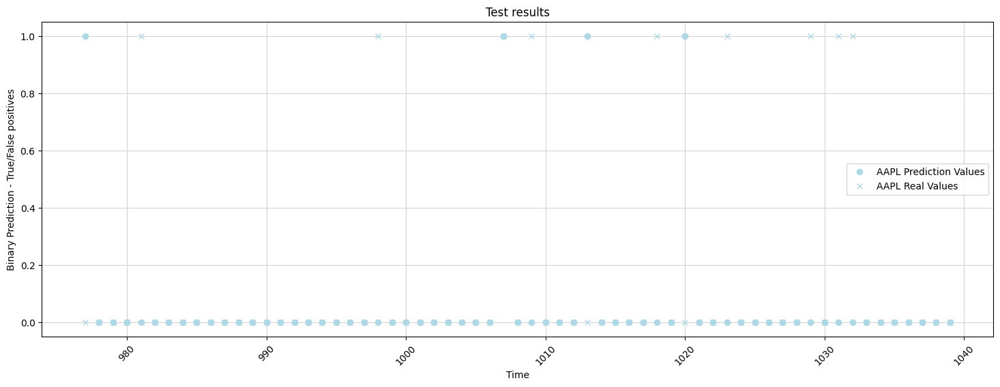

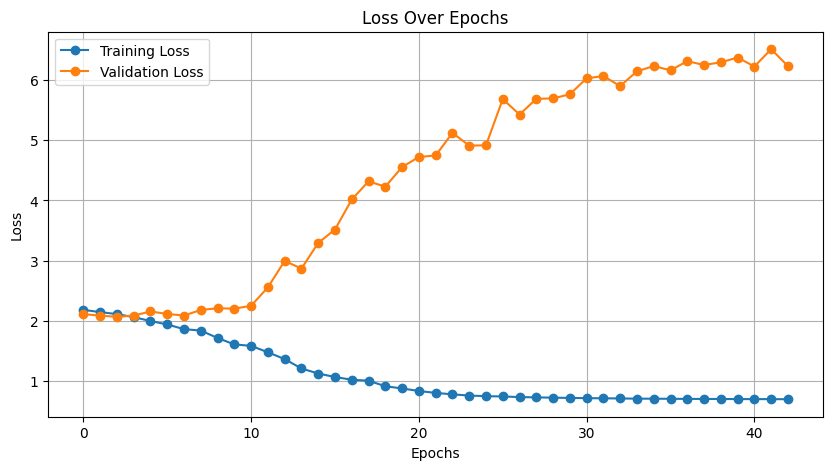

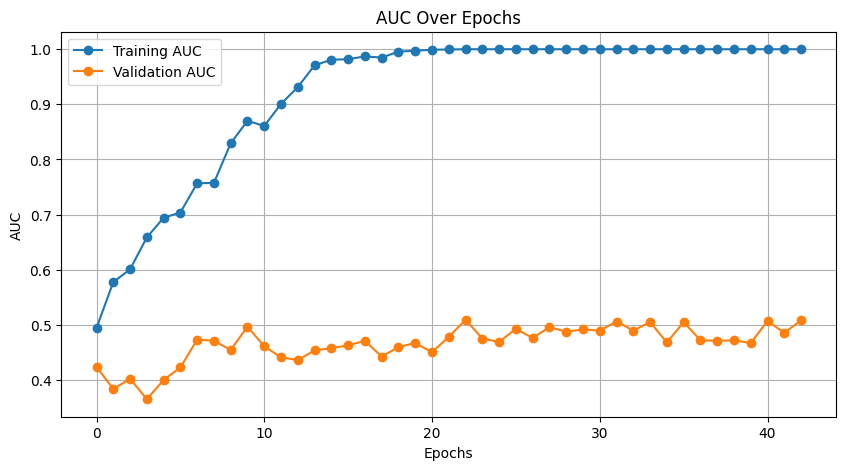



print_and_save_for
ticker data: AAPL


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
956        High-Low-Ratio  High-Open-Ratio  Close-O...   
957        High-Low-Ratio  High-Open-Ratio  Close-O...   
958        High-Low-Ratio  High-Open-Ratio  Close-O...   
959        High-Low-Ratio  High-Open-Ratio  Close-O...   
960        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2020-12-04 00:00:00-05:00       0       0          0.00992   
1    2020-12-07 00:00:00-05:00       0       0          0.00992   
2    2020-12-08 00:00:00-05:00       0     

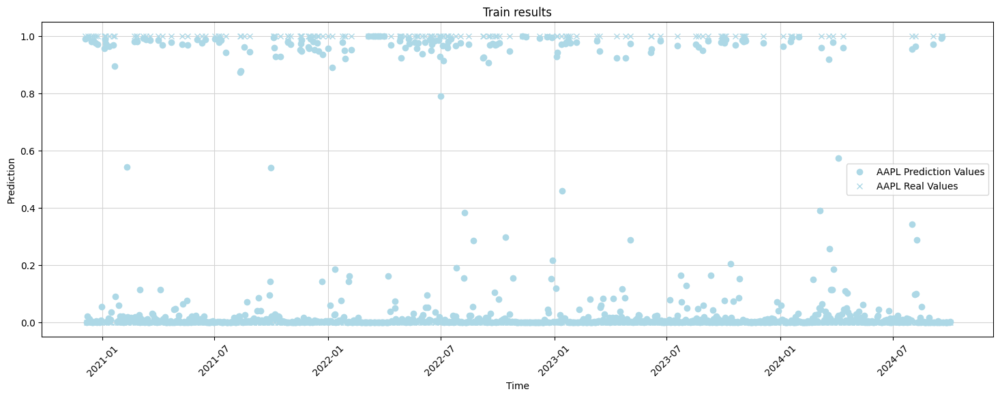

DONE PLOTTING 




print_and_save_for
ticker data: AAPL


Here is the data:                                                LstmData  \
961         High-Low-Ratio  High-Open-Ratio  Close-O...   
962         High-Low-Ratio  High-Open-Ratio  Close-O...   
963         High-Low-Ratio  High-Open-Ratio  Close-O...   
964         High-Low-Ratio  High-Open-Ratio  Close-O...   
965         High-Low-Ratio  High-Open-Ratio  Close-O...   
...                                                 ...   
1019        High-Low-Ratio  High-Open-Ratio  Close-O...   
1020        High-Low-Ratio  High-Open-Ratio  Close-O...   
1021        High-Low-Ratio  High-Open-Ratio  Close-O...   
1022        High-Low-Ratio  High-Open-Ratio  Close-O...   
1023        High-Low-Ratio  High-Open-Ratio  Close-O...   

                           Date  Ticker  Sector  Target-20D-Mean  \
961   2024-10-02 00:00:00-04:00       0       0          0.00992   
962   2024-10-03 00:00:00-04:00       0       0          0.00992   
963   2024-

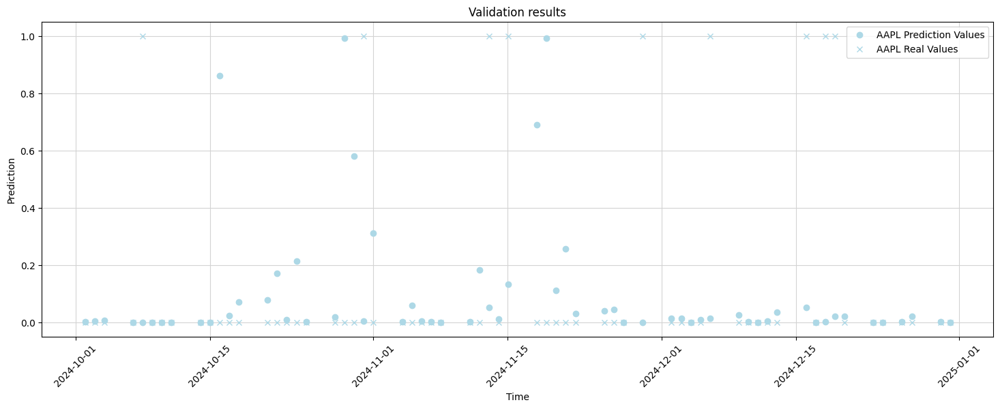

DONE PLOTTING 




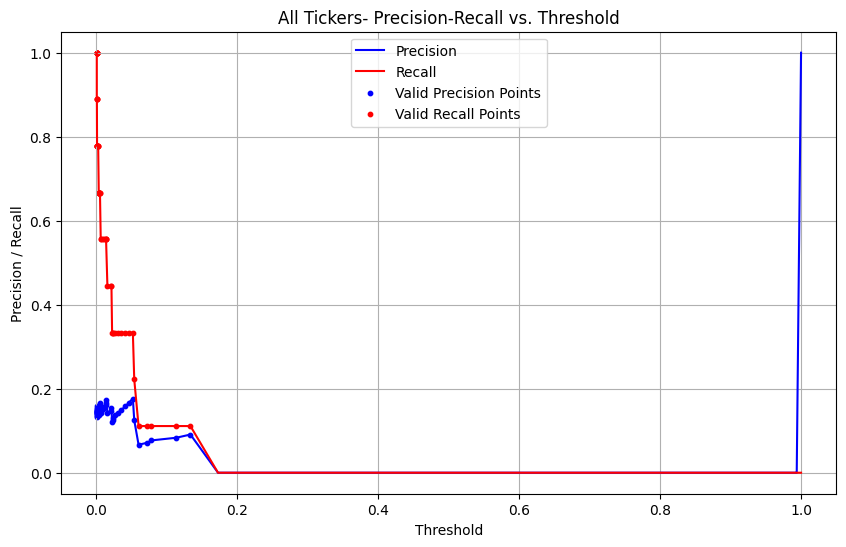

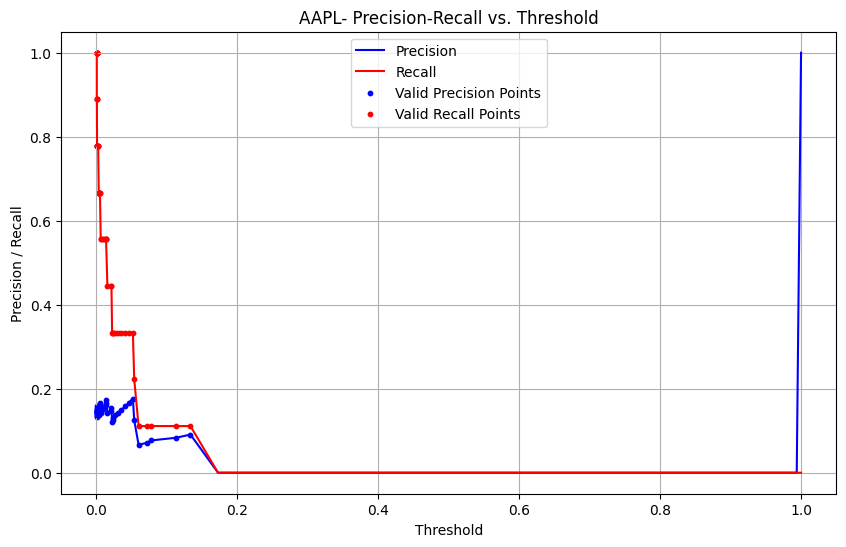

[0. 0. 0. 1.]
[0.         0.01315789 1.         1.        ]
[0.         0.01851852 0.18518519 0.18518519 0.25925926 0.25925926
 0.40740741 0.40740741 0.44444444 0.44444444 0.55555556 0.55555556
 0.7037037  0.7037037  0.85185185 0.85185185 0.88888889 0.88888889
 1.        ]
[0.         0.         0.         0.11111111 0.11111111 0.33333333
 0.33333333 0.44444444 0.44444444 0.55555556 0.55555556 0.66666667
 0.66666667 0.77777778 0.77777778 0.88888889 0.88888889 1.
 1.        ]


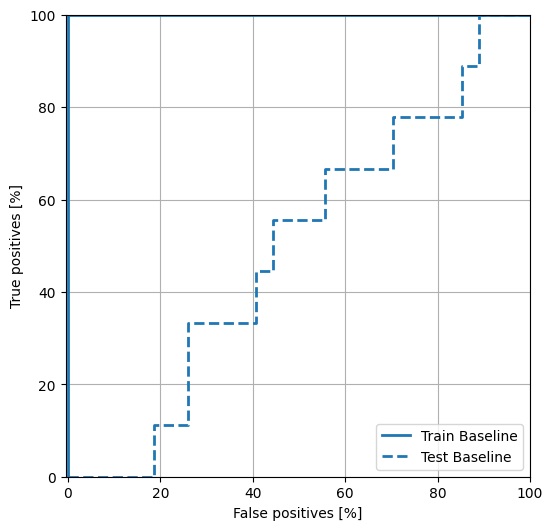

Best threshold: 0.013683863915503025
Number of true positives for the given ticker: 4
Number of false positives for the given ticker: 24
Precision score: 0.14285714285714285
Recall score: 0.4444444444444444
Random guess score: 0.14285714285714285
true-positive per ticker: Orig_Ticker
AAPL    4
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
AAPL    24
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
AAPL    5
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
AAPL    0.142857
dtype: float64
recall per ticker: Orig_Ticker
AAPL    0.444444
dtype: float64
rand guess per ticker: Orig_Ticker
AAPL    0.142857
dtype: float64
Some true positives
                           Date Orig_Ticker  y-predict-original  \
993   2024-11-15 00:00:00-05:00        AAPL            0.133422   
1016  2024-12-19 00:00:00-05:00        AAPL            0.021345   
991   2024-11-13 00:00:00-05:00        AAPL            0.051722   
1013  2024-12-16 0

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 0 1 0 1 1 1 0 1 0 1 0 0 0 0 1 1 0 1 1 1 1 1
 1 1 1 0 0 0 1 0 0 0 1 0 0 0 1 1 0 0 1 1 0 0 0 1 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0
 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 1 0 1 1 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = v

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['AAPL'] UNDERLYING_TARGET: Next-Day-High-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:65 mode: complex LR_RATE: 0.0001 STARTING_LR: 0.001
fetch_finance_data_for_tickers: just returning file name: AAPL for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode complex is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode complex is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names,

{'AAPL': 0}
{'Tech': 0}
size before sigma app: 993 for ticker: AAPL mean: 0.009920074564524758, sigma: 0.009970945611285134 upper_bound: 0.03983291139838016 lower_bound: -0.019992762269330642
size after sigma app: 980 for ticker: AAPL
0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
924    0.0
925    0.0
926    0.0
927    0.0
928    0.0
Name: y-value, Length: 916, dtype: float64
0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
924    0.0
925    0.0
926    0.0
927    0.0
928    0.0
Name: y-value-original, Length: 916, dtype: float64
High-Low-Ratio                               0.644859
High-Open-Ratio                              0.619622
Close-Open-Ratio                             0.556369
Close-Prev-Close                             0.565959
MACD-Prev-MACD                               0.270057
200D-Ratio                                   0.546643
MACD_SIG                                     0.766335
MFI3                                         0.342

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 65, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_84 (Conv1D)  │ (None, 63, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_129 (PReLU) │ (None, 63, 256)   │        256 │ conv1d_84[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_85 (Conv1D)  │ (None, 31, 256)   │    196,864 │ p_re_lu_129[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_130 (PReLU) │ (None, 31, 256)   │        256 │ conv1d_85[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_86 (Conv1D)  │ (None, 15, 512)   │    393,728 │ p_re_lu_130[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_131 (PReLU) │ (None, 15, 512)   │        512 │ conv1d_86[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_87 (Conv1D)  │ (None, 7, 512)    │    786,944 │ p_re_lu_131[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_132 (PReLU) │ (None, 7, 512)    │        512 │ conv1d_87[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_88 (Conv1D)  │ (None, 3, 1024)   │  1,573,888 │ p_re_lu_132[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_133 (PReLU) │ (None, 3, 1024)   │      1,024 │ conv1d_88[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_89 (Conv1D)  │ (None, 1, 1024)   │  3,146,752 │ p_re_lu_133[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_134 (PReLU) │ (None, 1, 1024)   │      1,024 │ conv1d_89[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_34          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_34          │ (None, 1024)      │          0 │ p_re_lu_134[0][0] │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_34[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_35          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                 

 Total params: 10,844,140 (41.37 MB)

 Trainable params: 10,844,140 (41.37 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - AUC: 0.4603 - Precision: 0.1227 - Recall: 0.4532 - all_positives: 19.9347 - f1_score_metric: 16.5421 - loss: 1.6068 - precision_with_threshold_fixed: 3.6857 - recall_mul_prediction: 1166.2391 - recall_with_threshold_fixed: 4.0952 - true_positives: 1166.2391 - val_AUC: 0.4290 - val_Precision: 0.1429 - val_Recall: 1.0000 - val_all_positives: 9.0000 - val_f1_score_metric: 15.7500 - val_loss: 1.4826 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 567.0001 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 567.0000 - learning_rate: 0.0010
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 758ms/step - AUC: 0.5189 - Precision: 0.1514 - Recall: 0.9839 - all_positives: 18.9587 - f1_score_metric: 32.5630 - loss: 1.5224 - precision_with_threshold_fixed: 1.1217 - recall_mul_prediction: 2392.4529 - recall_with_threshold_fixed: 7.5153 - true_positives: 2392.4529 - val_AUC: 0.4815 - val_Precision: 0.0000e+00 - val

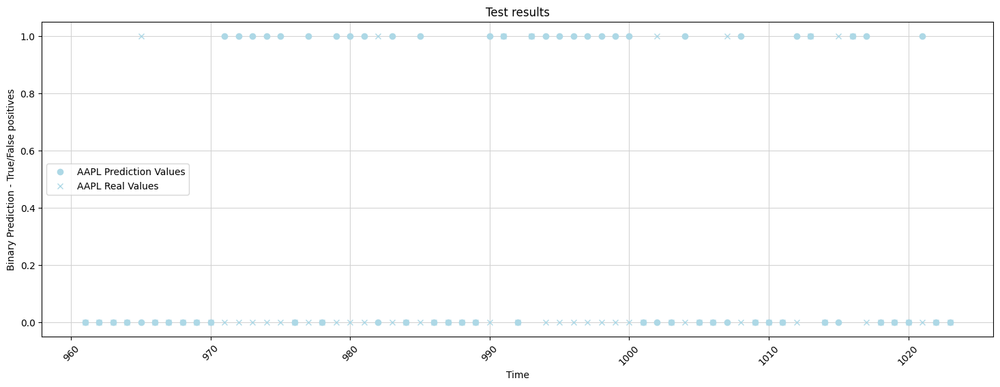

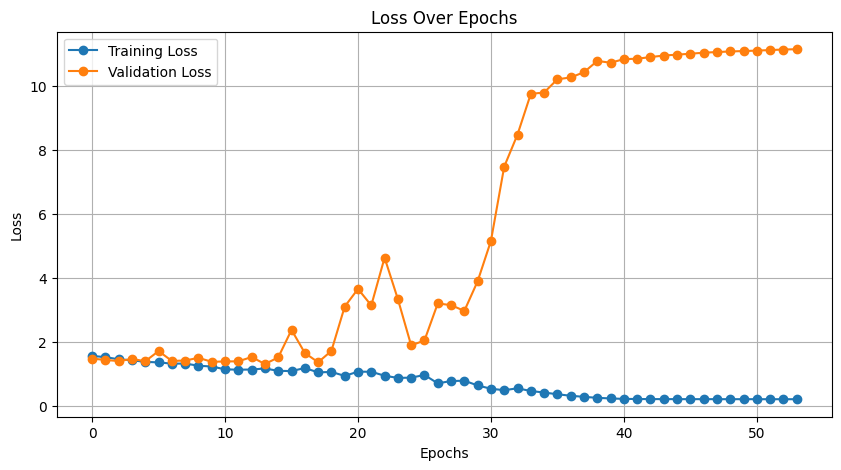

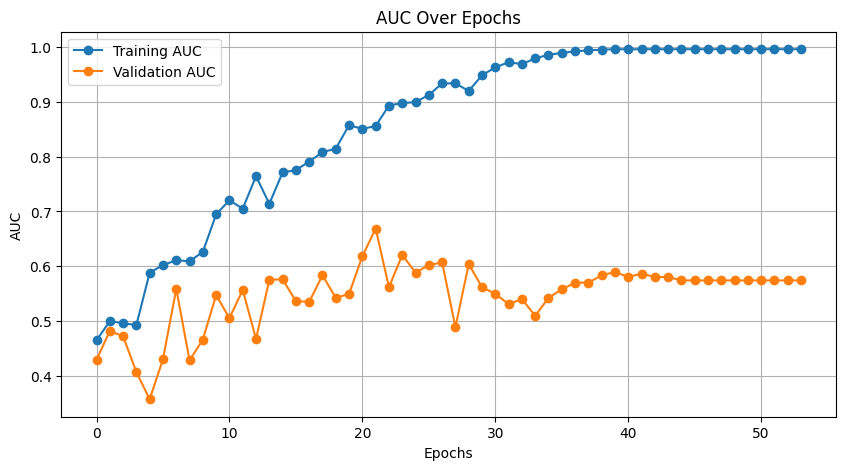



print_and_save_for
ticker data: AAPL


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
924        High-Low-Ratio  High-Open-Ratio  Close-O...   
925        High-Low-Ratio  High-Open-Ratio  Close-O...   
926        High-Low-Ratio  High-Open-Ratio  Close-O...   
927        High-Low-Ratio  High-Open-Ratio  Close-O...   
928        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2021-01-22 00:00:00-05:00       0       0          0.00992   
1    2021-01-25 00:00:00-05:00       0       0          0.00992   
2    2021-01-26 00:00:00-05:00       0     

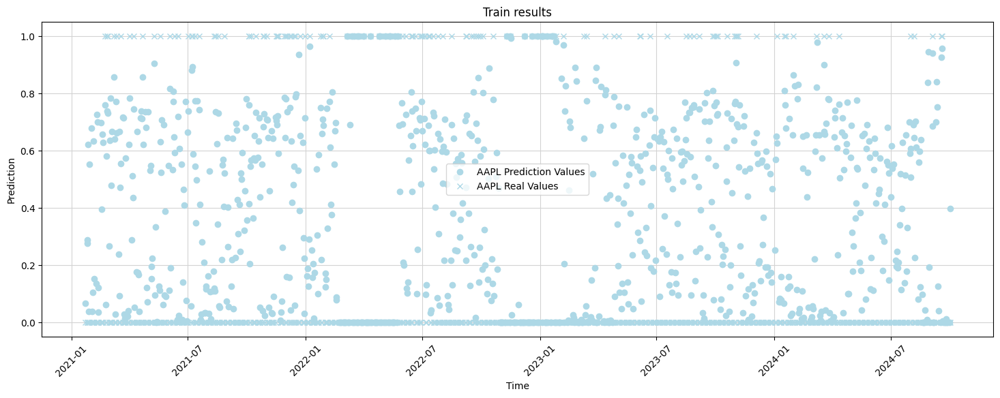

DONE PLOTTING 




print_and_save_for
ticker data: AAPL


Here is the data:                                               LstmData  \
929        High-Low-Ratio  High-Open-Ratio  Close-O...   
930        High-Low-Ratio  High-Open-Ratio  Close-O...   
931        High-Low-Ratio  High-Open-Ratio  Close-O...   
932        High-Low-Ratio  High-Open-Ratio  Close-O...   
933        High-Low-Ratio  High-Open-Ratio  Close-O...   
..                                                 ...   
987        High-Low-Ratio  High-Open-Ratio  Close-O...   
988        High-Low-Ratio  High-Open-Ratio  Close-O...   
989        High-Low-Ratio  High-Open-Ratio  Close-O...   
990        High-Low-Ratio  High-Open-Ratio  Close-O...   
991        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
929  2024-10-02 00:00:00-04:00       0       0          0.00992   
930  2024-10-03 00:00:00-04:00       0       0          0.00992   
931  2024-10-04 00:00:00-0

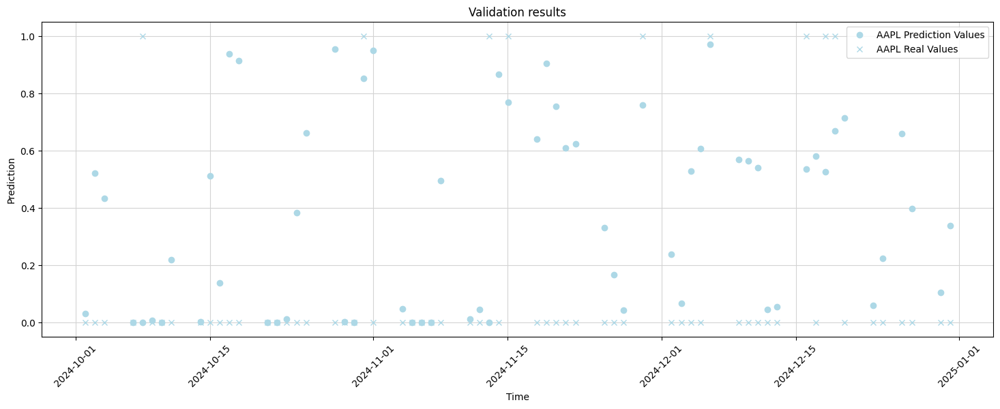

DONE PLOTTING 




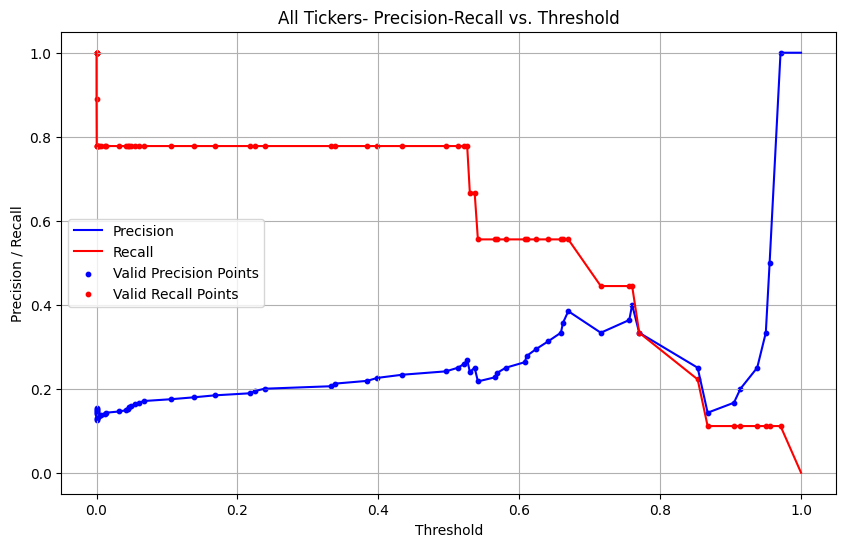

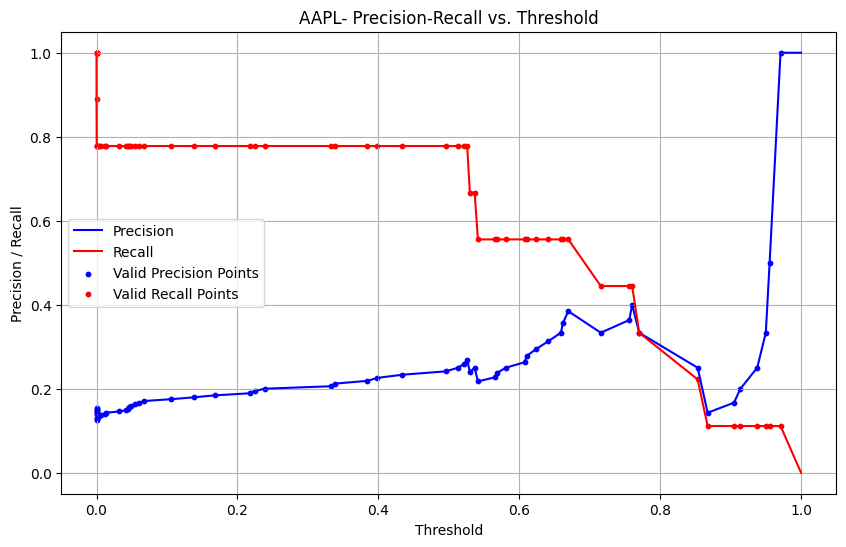

[0.         0.00128866 0.00128866 0.00257732 0.00257732 0.00386598
 0.00386598 0.00515464 0.00515464 0.0064433  0.0064433  0.01030928
 0.01030928 0.02190722 0.02190722 0.02319588 0.02319588 0.0257732
 0.0257732  0.02706186 0.02706186 0.02835052 0.02835052 0.03092784
 0.03092784 0.03350515 0.03350515 0.03608247 0.03608247 0.03994845
 0.03994845 0.04252577 0.04252577 0.04639175 0.04639175 0.04768041
 0.04768041 0.04896907 0.04896907 0.05283505 0.05283505 0.05412371
 0.05412371 0.05541237 0.05541237 0.05670103 0.05670103 0.05927835
 0.05927835 0.06185567 0.06185567 0.06314433 0.06314433 0.06572165
 0.06572165 0.06958763 0.06958763 0.07216495 0.07216495 0.07345361
 0.07345361 0.08376289 0.08376289 0.08505155 0.08505155 0.08891753
 0.08891753 0.09020619 0.09020619 0.10180412 0.10180412 0.10438144
 0.10438144 0.10953608 0.10953608 0.11082474 0.11082474 0.1121134
 0.1121134  0.11469072 0.11469072 0.12242268 0.12242268 0.12757732
 0.12757732 0.14046392 0.14046392 0.1443299  0.1443299  0.157216

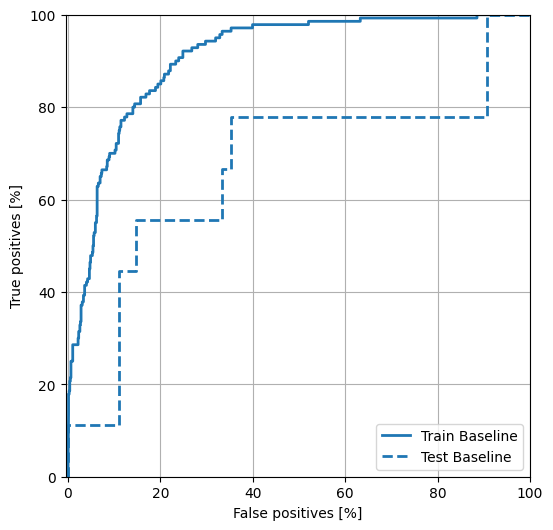

Best threshold: 0.6696279644966125
Number of true positives for the given ticker: 4
Number of false positives for the given ticker: 8
Precision score: 0.3333333333333333
Recall score: 0.4444444444444444
Random guess score: 0.14285714285714285
true-positive per ticker: Orig_Ticker
AAPL    4
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
AAPL    8
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
AAPL    5
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
AAPL    0.333333
dtype: float64
recall per ticker: Orig_Ticker
AAPL    0.444444
dtype: float64
rand guess per ticker: Orig_Ticker
AAPL    0.142857
dtype: float64
Some true positives
                          Date Orig_Ticker  y-predict-original  \
961  2024-11-15 00:00:00-05:00        AAPL            0.770268   
975  2024-12-06 00:00:00-05:00        AAPL            0.970874   
950  2024-10-31 00:00:00-04:00        AAPL            0.853246   
970  2024-11-29 00:00:00-05

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 1 0 0 1 1 0 0 0 0 0 0 0 0 1 1 0 1 1 0
 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0
 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 1 0 1 1 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = v

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['MSTR'] UNDERLYING_TARGET: Next-Day-Close-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:17 mode: simple LR_RATE: 0.001 STARTING_LR: 1e-05
fetch_finance_data_for_tickers: just returning file name: MSTR for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode simple is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode simple is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, b

{'MSTR': 0}
{'Unknown': 0}
size before sigma app: 1040 for ticker: MSTR mean: -0.0009348677720681329, sigma: 0.058674000971499544 upper_bound: 0.1750871351424305 lower_bound: -0.17695687068656676
size after sigma app: 1035 for ticker: MSTR
0      1.0
1      1.0
2      0.0
3      0.0
4      0.0
      ... 
962    1.0
963    0.0
964    0.0
965    0.0
966    0.0
Name: y-value, Length: 963, dtype: float64
0      1.0
1      1.0
2      0.0
3      0.0
4      0.0
      ... 
962    1.0
963    0.0
964    0.0
965    0.0
966    0.0
Name: y-value-original, Length: 963, dtype: float64
High-Low-Ratio                               0.643938
High-Open-Ratio                              0.583942
Close-Open-Ratio                             0.564503
Close-Prev-Close                             0.661494
MACD-Prev-MACD                               0.329598
200D-Ratio                                   0.521319
MACD_SIG                                     0.732406
MFI3                                         

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 17, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_90 (Conv1D)  │ (None, 15, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_138 (PReLU) │ (None, 15, 256)   │        256 │ conv1d_90[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_91 (Conv1D)  │ (None, 7, 256)    │    196,864 │ p_re_lu_138[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_139 (PReLU) │ (None, 7, 256)    │        256 │ conv1d_91[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_92 (Conv1D)  │ (None, 3, 512)    │    393,728 │ p_re_lu_139[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_140 (PReLU) │ (None, 3, 512)    │        512 │ conv1d_92[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_93 (Conv1D)  │ (None, 1, 512)    │    786,944 │ p_re_lu_140[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_141 (PReLU) │ (None, 1, 512)    │        512 │ conv1d_93[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_36          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_36          │ (None, 512)       │          0 │ p_re_lu_141[0][0] │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_36[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_37          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_36      │ (None, 1024)      │          0 │ flatten_36[0][0], │
│ (Concatenate)       │                   │            │ stock_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_dense        │ (None, 256)       │     33,024 │ reshape_37[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_37      │ (None, 1280)      │          0 │ concatenate_36[0

 Total params: 2,247,451 (8.57 MB)

 Trainable params: 2,247,451 (8.57 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - AUC: 0.4536 - Precision: 0.1700 - Recall: 0.8127 - all_positives: 22.2468 - f1_score_metric: 36.3295 - loss: 2.4687 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2333.6597 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2333.6597 - val_AUC: 0.4708 - val_Precision: 0.1803 - val_Recall: 0.9167 - val_all_positives: 12.0000 - val_f1_score_metric: 20.0548 - val_loss: 2.5218 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 732.0001 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 732.0000 - learning_rate: 1.0000e-05
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 498ms/step - AUC: 0.5170 - Precision: 0.1594 - Recall: 0.9658 - all_positives: 20.0992 - f1_score_metric: 34.4329 - loss: 2.4024 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2463.8572 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2463.8572 - val_AUC: 0.5425 - val_Precis

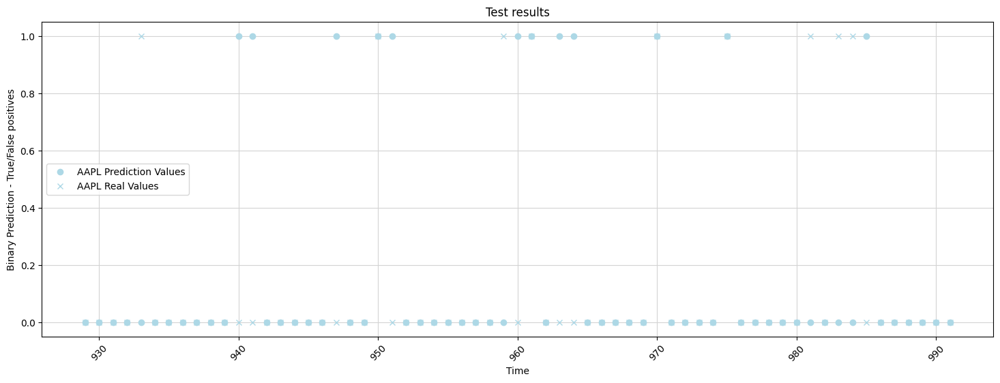

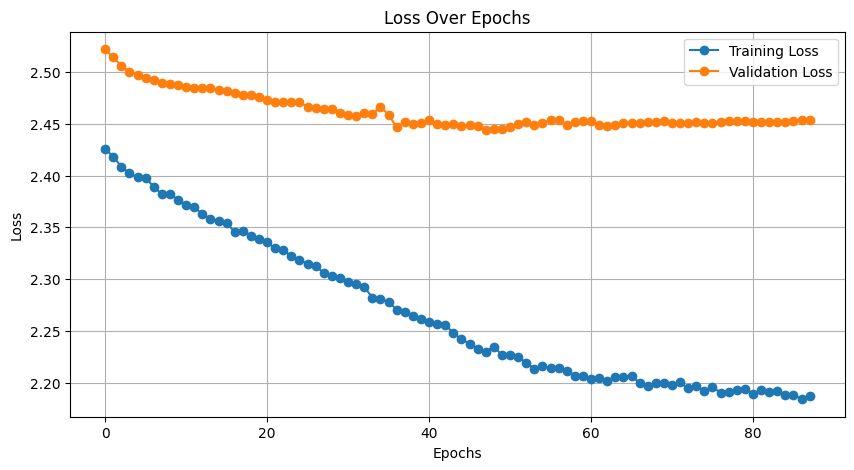

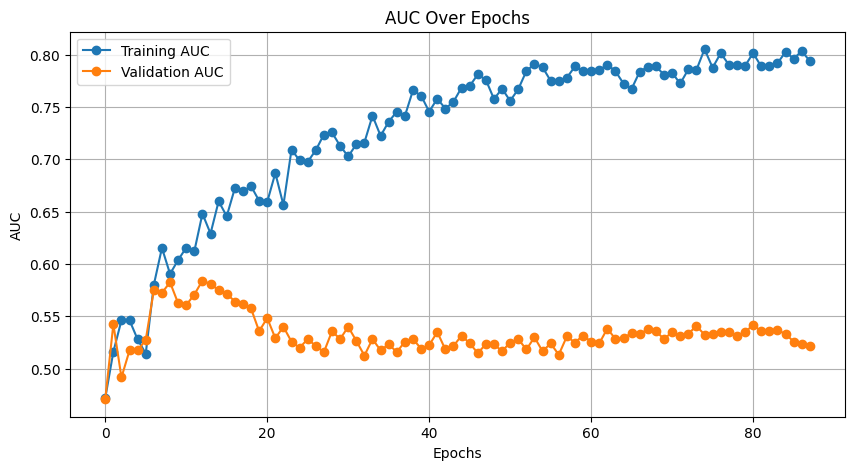



print_and_save_for
ticker data: MSTR


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
962        High-Low-Ratio  High-Open-Ratio  Close-O...   
963        High-Low-Ratio  High-Open-Ratio  Close-O...   
964        High-Low-Ratio  High-Open-Ratio  Close-O...   
965        High-Low-Ratio  High-Open-Ratio  Close-O...   
966        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2020-11-25 00:00:00-05:00       0       0        -0.000935   
1    2020-11-27 00:00:00-05:00       0       0        -0.000935   
2    2020-11-30 00:00:00-05:00       0     

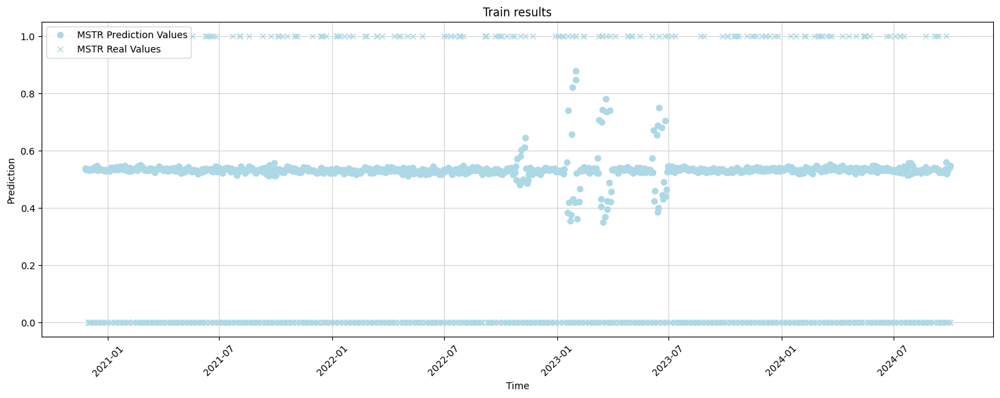

DONE PLOTTING 




print_and_save_for
ticker data: MSTR


Here is the data:                                                LstmData  \
967         High-Low-Ratio  High-Open-Ratio  Close-O...   
968         High-Low-Ratio  High-Open-Ratio  Close-O...   
969         High-Low-Ratio  High-Open-Ratio  Close-O...   
970         High-Low-Ratio  High-Open-Ratio  Close-O...   
971         High-Low-Ratio  High-Open-Ratio  Close-O...   
...                                                 ...   
1025        High-Low-Ratio  High-Open-Ratio  Close-O...   
1026        High-Low-Ratio  High-Open-Ratio  Close-O...   
1027        High-Low-Ratio  High-Open-Ratio  Close-O...   
1028        High-Low-Ratio  High-Open-Ratio  Close-O...   
1029        High-Low-Ratio  High-Open-Ratio  Close-O...   

                           Date  Ticker  Sector  Target-20D-Mean  \
967   2024-10-02 00:00:00-04:00       0       0        -0.000935   
968   2024-10-03 00:00:00-04:00       0       0        -0.000935   
969   2024-

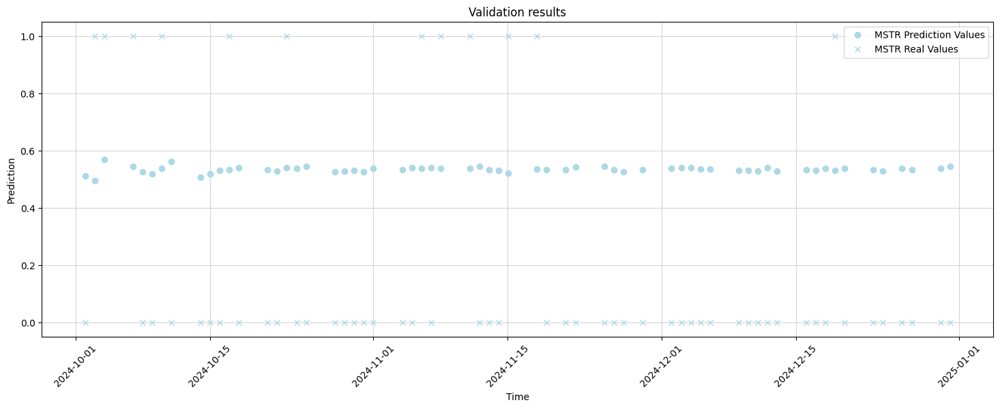

DONE PLOTTING 




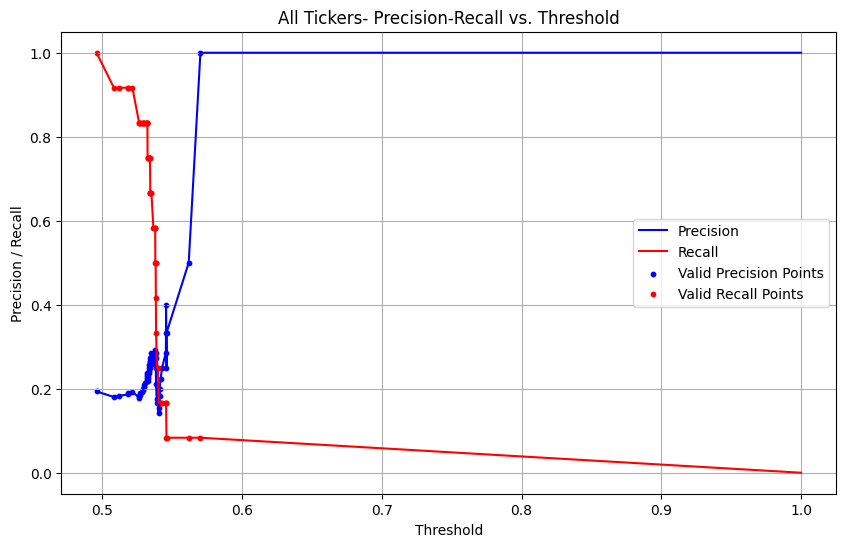

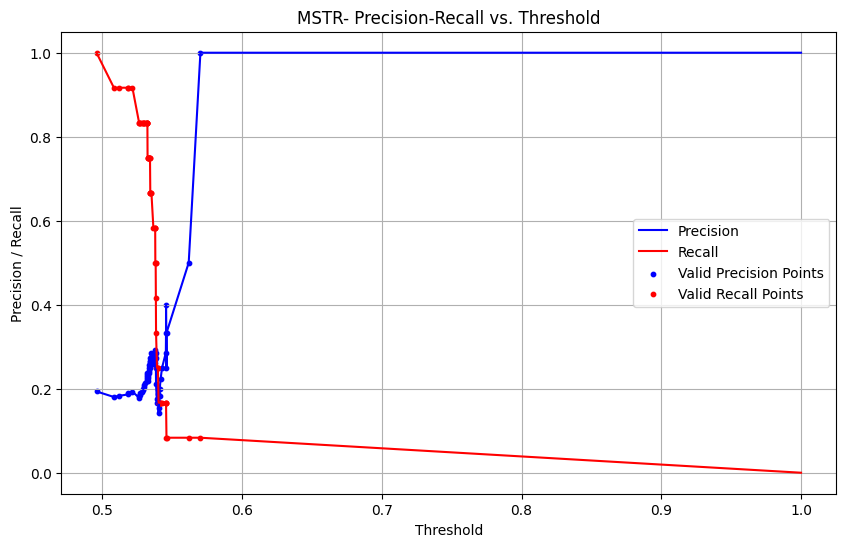

[0.         0.         0.         0.00124224 0.00124224 0.00745342
 0.00745342 0.00993789 0.00993789 0.01118012 0.01118012 0.01242236
 0.01242236 0.01863354 0.01863354 0.02857143 0.02857143 0.02981366
 0.02981366 0.0310559  0.0310559  0.03229814 0.03229814 0.03478261
 0.03478261 0.03850932 0.03850932 0.04347826 0.04347826 0.0484472
 0.0484472  0.04968944 0.04968944 0.07453416 0.07453416 0.08074534
 0.08074534 0.08198758 0.08198758 0.08447205 0.08447205 0.08695652
 0.08695652 0.09192547 0.09192547 0.1068323  0.1068323  0.10807453
 0.10807453 0.11428571 0.11428571 0.11552795 0.11552795 0.12298137
 0.12298137 0.13043478 0.13043478 0.13416149 0.13416149 0.13540373
 0.13540373 0.13664596 0.13664596 0.14037267 0.14037267 0.14161491
 0.14161491 0.15031056 0.15031056 0.1515528  0.1515528  0.15900621
 0.15900621 0.16645963 0.16645963 0.17018634 0.17018634 0.1826087
 0.18509317 0.1863354  0.1863354  0.18757764 0.18757764 0.19875776
 0.19875776 0.20372671 0.20372671 0.22732919 0.22732919 0.232298

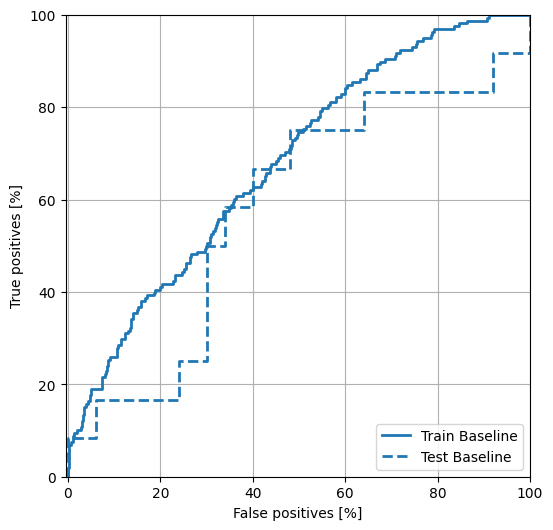

Best threshold: 0.5378482341766357
Number of true positives for the given ticker: 6
Number of false positives for the given ticker: 17
Precision score: 0.2608695652173913
Recall score: 0.5
Random guess score: 0.1935483870967742
true-positive per ticker: Orig_Ticker
MSTR    6
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
MSTR    17
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
MSTR    6
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
MSTR    0.26087
dtype: float64
recall per ticker: Orig_Ticker
MSTR    0.5
dtype: float64
rand guess per ticker: Orig_Ticker
MSTR    0.193548
dtype: float64
Some true positives
                          Date Orig_Ticker  y-predict-original  \
969  2024-10-04 00:00:00-04:00        MSTR            0.570207   
970  2024-10-07 00:00:00-04:00        MSTR            0.545614   
995  2024-11-11 00:00:00-05:00        MSTR            0.538465   
973  2024-10-10 00:00:00-04:00        MSTR     

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 1 1 0 0 1 1 0 0 0 0 1 0 0 1 1 1 0 0 0 0 1 0 1 0 1 1 1 1 0 0 0 0 0 0 1
 1 0 0 0 1 1 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 1]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 1 1 1 0 0 1 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 1 1 0 0 0 1 1 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = valid

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['MSTR'] UNDERLYING_TARGET: Next-Day-Close-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:33 mode: medium LR_RATE: 0.0005 STARTING_LR: 0.0001
fetch_finance_data_for_tickers: just returning file name: MSTR for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode medium is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode medium is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, b

{'MSTR': 0}
{'Unknown': 0}
size before sigma app: 1024 for ticker: MSTR mean: -0.0009348677720681328, sigma: 0.058674000971499544 upper_bound: 0.1750871351424305 lower_bound: -0.17695687068656676
size after sigma app: 1019 for ticker: MSTR
0      1.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
946    1.0
947    0.0
948    0.0
949    0.0
950    0.0
Name: y-value, Length: 947, dtype: float64
0      1.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
946    1.0
947    0.0
948    0.0
949    0.0
950    0.0
Name: y-value-original, Length: 947, dtype: float64
High-Low-Ratio                               0.643938
High-Open-Ratio                              0.583942
Close-Open-Ratio                             0.564503
Close-Prev-Close                             0.661494
MACD-Prev-MACD                               0.329598
200D-Ratio                                   0.521319
MACD_SIG                                     0.732406
MFI3                                         

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 33, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_94 (Conv1D)  │ (None, 31, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_144 (PReLU) │ (None, 31, 256)   │        256 │ conv1d_94[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_95 (Conv1D)  │ (None, 15, 256)   │    196,864 │ p_re_lu_144[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_145 (PReLU) │ (None, 15, 256)   │        256 │ conv1d_95[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_96 (Conv1D)  │ (None, 7, 512)    │    393,728 │ p_re_lu_145[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_146 (PReLU) │ (None, 7, 512)    │        512 │ conv1d_96[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_97 (Conv1D)  │ (None, 3, 512)    │    786,944 │ p_re_lu_146[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_147 (PReLU) │ (None, 3, 512)    │        512 │ conv1d_97[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_98 (Conv1D)  │ (None, 1, 1024)   │  1,573,888 │ p_re_lu_147[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_148 (PReLU) │ (None, 1, 1024)   │      1,024 │ conv1d_98[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_38          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_38          │ (None, 1024)      │          0 │ p_re_lu_148[0][0] │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_38[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_39          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_38      │ (None, 1536)      │          0 │ flatten_38[0][0], │
│ (Concatenate)       │                   │            │ stock_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 7,696,364 (29.36 MB)

 Trainable params: 7,696,364 (29.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - AUC: 0.4825 - Precision: 0.1601 - Recall: 0.6483 - all_positives: 20.0847 - f1_score_metric: 31.4374 - loss: 2.1690 - precision_with_threshold_fixed: 0.6984 - recall_mul_prediction: 1652.9979 - recall_with_threshold_fixed: 0.0437 - true_positives: 1652.9979 - val_AUC: 0.6758 - val_Precision: 0.1935 - val_Recall: 1.0000 - val_all_positives: 12.0000 - val_f1_score_metric: 20.1081 - val_loss: 2.2335 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 744.0000 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 744.0000 - learning_rate: 1.0000e-04
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 662ms/step - AUC: 0.5706 - Precision: 0.1708 - Recall: 0.9986 - all_positives: 21.0540 - f1_score_metric: 35.6539 - loss: 2.1479 - precision_with_threshold_fixed: 19.3675 - recall_mul_prediction: 2624.3442 - recall_with_threshold_fixed: 2.6979 - true_positives: 2624.3442 - val_AUC: 0.6742 - val_Precision: 0.2034 - v

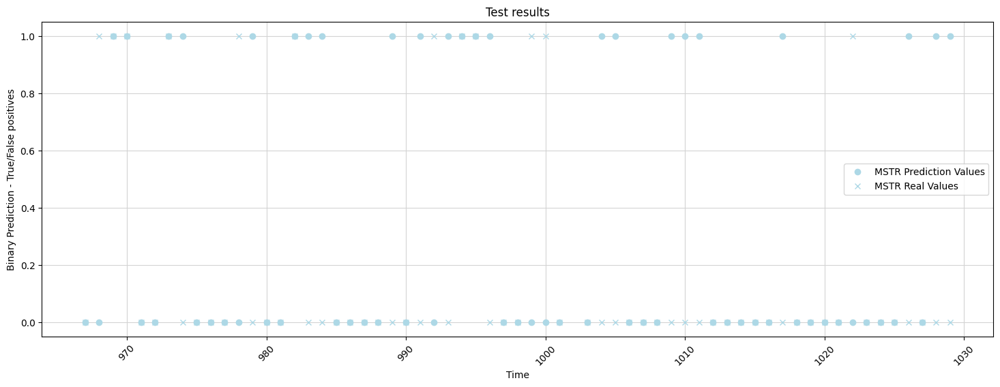

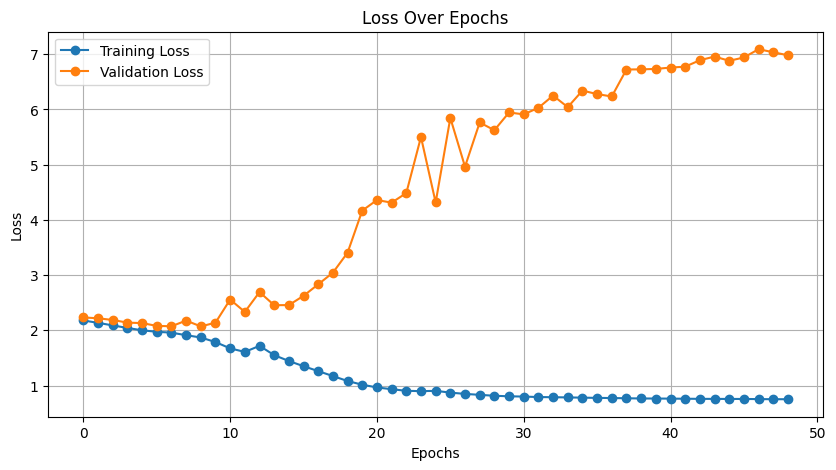

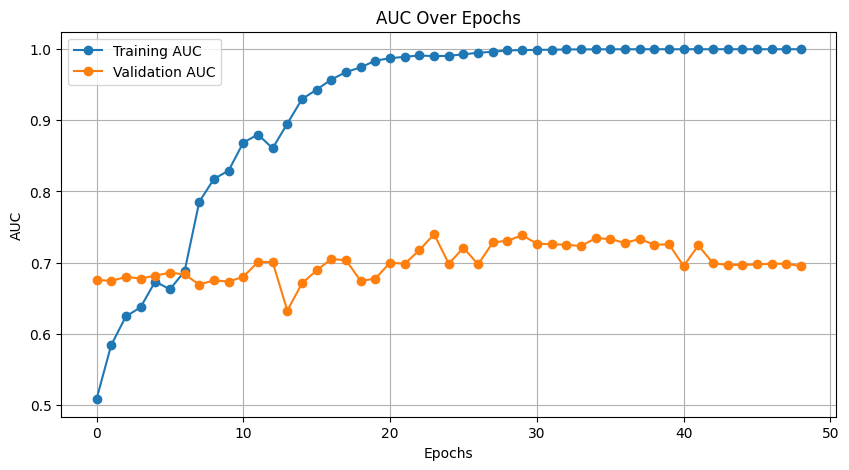



print_and_save_for
ticker data: MSTR


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
946        High-Low-Ratio  High-Open-Ratio  Close-O...   
947        High-Low-Ratio  High-Open-Ratio  Close-O...   
948        High-Low-Ratio  High-Open-Ratio  Close-O...   
949        High-Low-Ratio  High-Open-Ratio  Close-O...   
950        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2020-12-18 00:00:00-05:00       0       0        -0.000935   
1    2020-12-21 00:00:00-05:00       0       0        -0.000935   
2    2020-12-22 00:00:00-05:00       0     

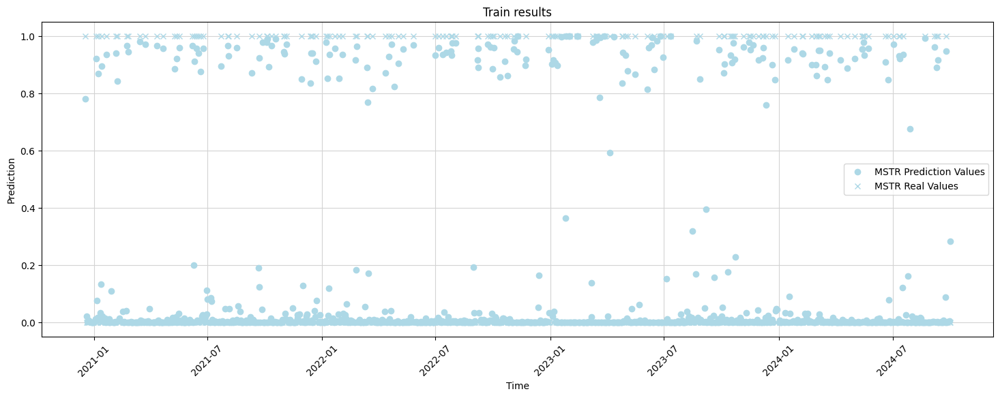

DONE PLOTTING 




print_and_save_for
ticker data: MSTR


Here is the data:                                                LstmData  \
951         High-Low-Ratio  High-Open-Ratio  Close-O...   
952         High-Low-Ratio  High-Open-Ratio  Close-O...   
953         High-Low-Ratio  High-Open-Ratio  Close-O...   
954         High-Low-Ratio  High-Open-Ratio  Close-O...   
955         High-Low-Ratio  High-Open-Ratio  Close-O...   
...                                                 ...   
1009        High-Low-Ratio  High-Open-Ratio  Close-O...   
1010        High-Low-Ratio  High-Open-Ratio  Close-O...   
1011        High-Low-Ratio  High-Open-Ratio  Close-O...   
1012        High-Low-Ratio  High-Open-Ratio  Close-O...   
1013        High-Low-Ratio  High-Open-Ratio  Close-O...   

                           Date  Ticker  Sector  Target-20D-Mean  \
951   2024-10-02 00:00:00-04:00       0       0        -0.000935   
952   2024-10-03 00:00:00-04:00       0       0        -0.000935   
953   2024-

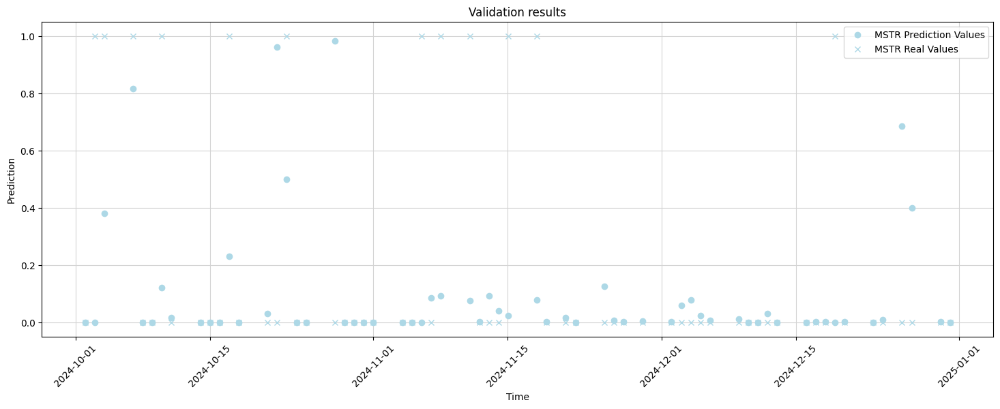

DONE PLOTTING 




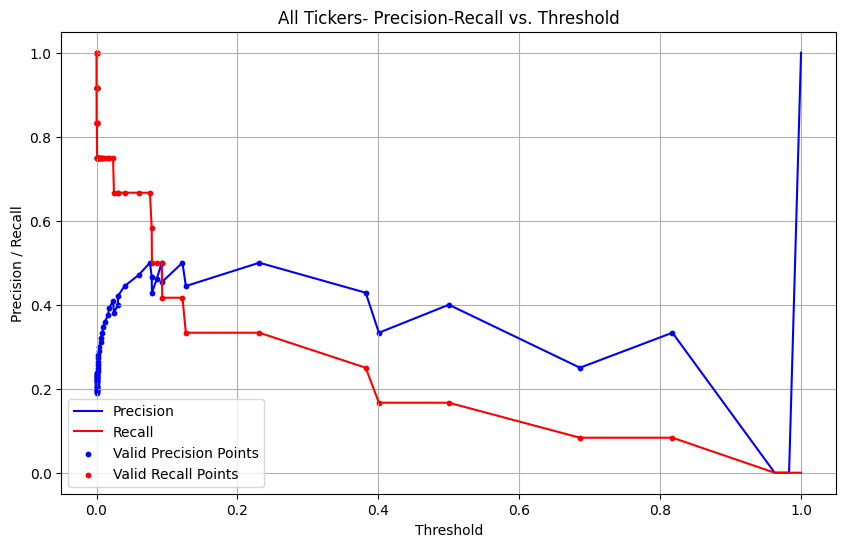

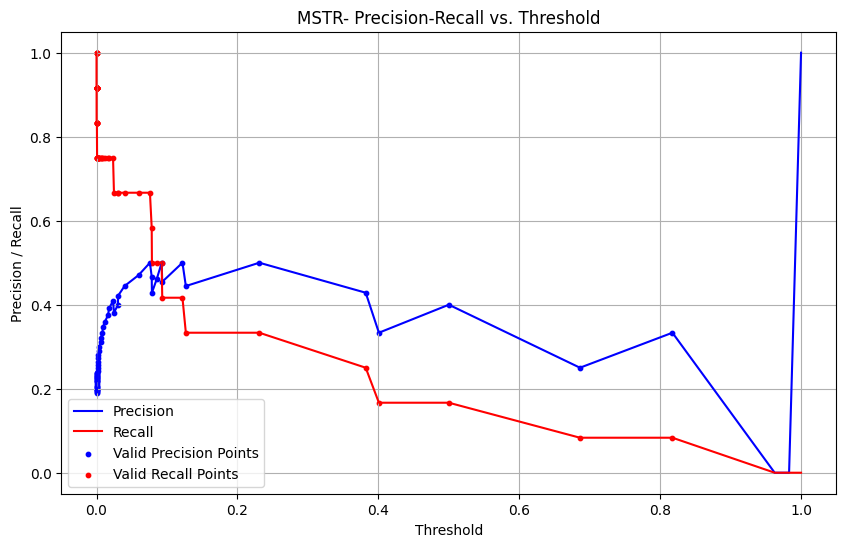

[0.         0.         0.         0.00126422 0.00126422 0.00252845
 0.00252845 0.00505689 0.00505689 0.00632111 0.00632111 0.00758534
 0.00758534 0.00884956 0.00884956 0.01011378 0.01011378 0.011378
 0.011378   0.01264223 0.01264223 0.01390645 0.01390645 0.01517067
 0.01517067 0.01643489 0.01643489 0.18836915 0.18836915 0.99115044
 1.        ]
[0.         0.00641026 0.05769231 0.05769231 0.07692308 0.07692308
 0.10897436 0.10897436 0.12179487 0.12179487 0.19871795 0.19871795
 0.26923077 0.26923077 0.42948718 0.42948718 0.76282051 0.76282051
 0.77564103 0.77564103 0.95512821 0.95512821 0.96794872 0.96794872
 0.98717949 0.98717949 0.99358974 0.99358974 1.         1.
 1.        ]
[0.   0.02 0.04 0.04 0.06 0.06 0.08 0.08 0.1  0.1  0.12 0.12 0.16 0.16
 0.26 0.26 0.64 0.64 0.72 0.72 0.94 0.94 1.  ]
[0.         0.         0.         0.08333333 0.08333333 0.16666667
 0.16666667 0.33333333 0.33333333 0.41666667 0.41666667 0.5
 0.5        0.66666667 0.66666667 0.75       0.75       0.83333333
 0

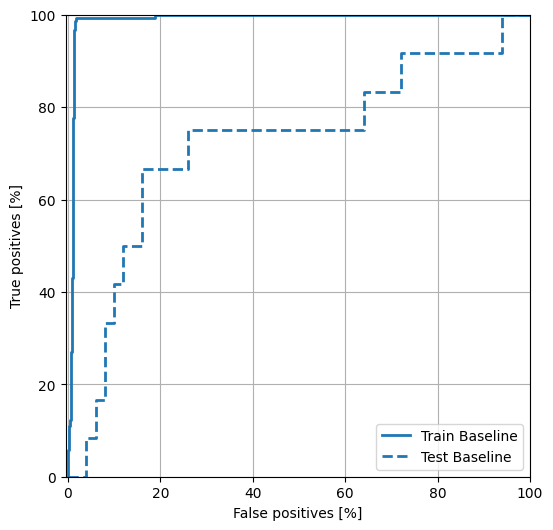

Best threshold: 0.07583627849817276
Number of true positives for the given ticker: 7
Number of false positives for the given ticker: 8
Precision score: 0.4666666666666667
Recall score: 0.5833333333333334
Random guess score: 0.1935483870967742
true-positive per ticker: Orig_Ticker
MSTR    7
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
MSTR    8
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
MSTR    5
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
MSTR    0.466667
dtype: float64
recall per ticker: Orig_Ticker
MSTR    0.583333
dtype: float64
rand guess per ticker: Orig_Ticker
MSTR    0.193548
dtype: float64
Some true positives
                          Date Orig_Ticker  y-predict-original  \
953  2024-10-04 00:00:00-04:00        MSTR            0.382090   
954  2024-10-07 00:00:00-04:00        MSTR            0.817441   
978  2024-11-08 00:00:00-05:00        MSTR            0.092491   
957  2024-10-10 00:00:00-04

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 1 1 0 0 1 0 0 0 0 1 0 0 1 1 0 0 1 0 0 0 0 0 0 0 1 1 0 0 1 0 0 1 0 0 0
 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 1 1 1 0 0 1 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 1 1 0 0 0 1 1 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = valid

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['MSTR'] UNDERLYING_TARGET: Next-Day-Close-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:65 mode: complex LR_RATE: 0.0001 STARTING_LR: 0.001
fetch_finance_data_for_tickers: just returning file name: MSTR for interval: 5y


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode complex is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode complex is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")


object


...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 65, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_99 (Conv1D)  │ (None, 63, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_152 (PReLU) │ (None, 63, 256)   │        256 │ conv1d_99[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_100 (Conv1D) │ (None, 31, 256)   │    196,864 │ p_re_lu_152[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_153 (PReLU) │ (None, 31, 256)   │        256 │ conv1d_100[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_101 (Conv1D) │ (None, 15, 512)   │    393,728 │ p_re_lu_153[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_154 (PReLU) │ (None, 15, 512)   │        512 │ conv1d_101[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_102 (Conv1D) │ (None, 7, 512)    │    786,944 │ p_re_lu_154[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_155 (PReLU) │ (None, 7, 512)    │        512 │ conv1d_102[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_103 (Conv1D) │ (None, 3, 1024)   │  1,573,888 │ p_re_lu_155[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_156 (PReLU) │ (None, 3, 1024)   │      1,024 │ conv1d_103[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_104 (Conv1D) │ (None, 1, 1024)   │  3,146,752 │ p_re_lu_156[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_157 (PReLU) │ (None, 1, 1024)   │      1,024 │ conv1d_104[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_40          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_40          │ (None, 1024)      │          0 │ p_re_lu_157[0][0] │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_40[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_41          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                 

 Total params: 10,844,140 (41.37 MB)

 Trainable params: 10,844,140 (41.37 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - AUC: 0.4841 - Precision: 0.1511 - Recall: 0.5001 - all_positives: 21.4910 - f1_score_metric: 24.9085 - loss: 1.6339 - precision_with_threshold_fixed: 3.8905 - recall_mul_prediction: 1377.1772 - recall_with_threshold_fixed: 13.9238 - true_positives: 1377.1772 - val_AUC: 0.4900 - val_Precision: 0.1935 - val_Recall: 1.0000 - val_all_positives: 12.0000 - val_f1_score_metric: 20.1081 - val_loss: 1.6182 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 744.0000 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 744.0000 - learning_rate: 0.0010
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 701ms/step - AUC: 0.5144 - Precision: 0.1663 - Recall: 1.0000 - all_positives: 20.7833 - f1_score_metric: 35.5440 - loss: 1.5284 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2648.1555 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2648.1555 - val_AUC: 0.5033 - val_Precision: 0.1935

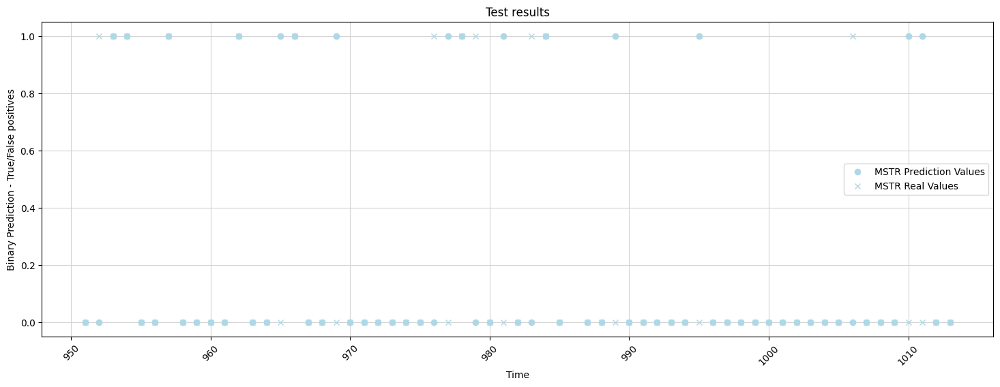

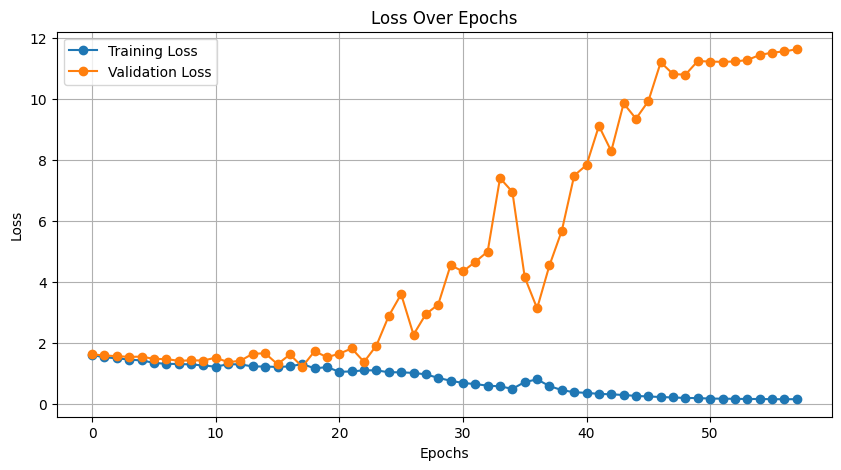

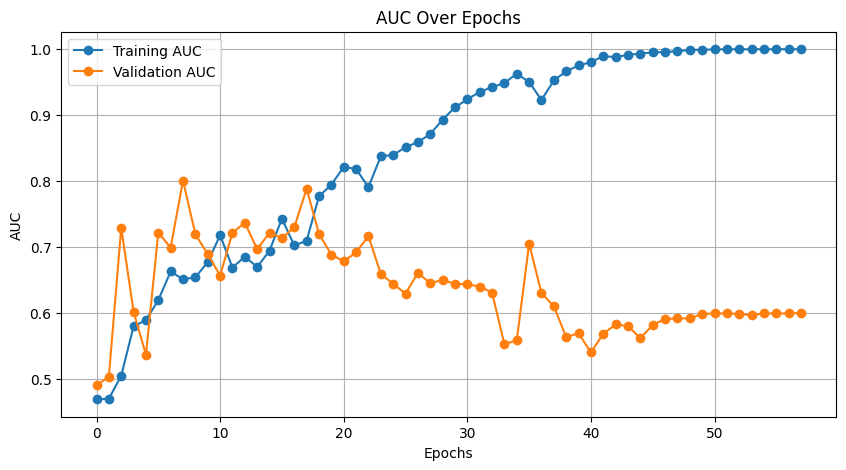



print_and_save_for
ticker data: MSTR


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
5         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
914        High-Low-Ratio  High-Open-Ratio  Close-O...   
915        High-Low-Ratio  High-Open-Ratio  Close-O...   
916        High-Low-Ratio  High-Open-Ratio  Close-O...   
917        High-Low-Ratio  High-Open-Ratio  Close-O...   
918        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2021-02-05 00:00:00-05:00       0       0        -0.000935   
1    2021-02-08 00:00:00-05:00       0       0        -0.000935   
3    2021-02-10 00:00:00-05:00       0     

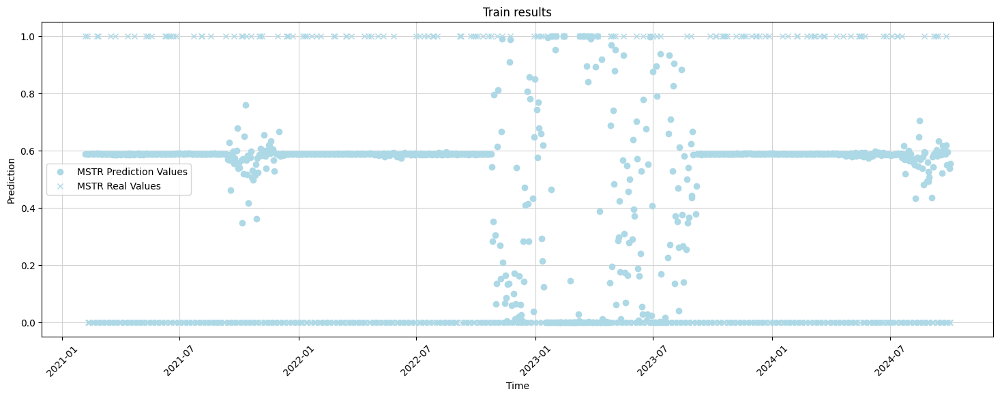

DONE PLOTTING 




print_and_save_for
ticker data: MSTR


Here is the data:                                               LstmData  \
919        High-Low-Ratio  High-Open-Ratio  Close-O...   
920        High-Low-Ratio  High-Open-Ratio  Close-O...   
921        High-Low-Ratio  High-Open-Ratio  Close-O...   
922        High-Low-Ratio  High-Open-Ratio  Close-O...   
923        High-Low-Ratio  High-Open-Ratio  Close-O...   
..                                                 ...   
977        High-Low-Ratio  High-Open-Ratio  Close-O...   
978        High-Low-Ratio  High-Open-Ratio  Close-O...   
979        High-Low-Ratio  High-Open-Ratio  Close-O...   
980        High-Low-Ratio  High-Open-Ratio  Close-O...   
981        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
919  2024-10-02 00:00:00-04:00       0       0        -0.000935   
920  2024-10-03 00:00:00-04:00       0       0        -0.000935   
921  2024-10-04 00:00:00-0

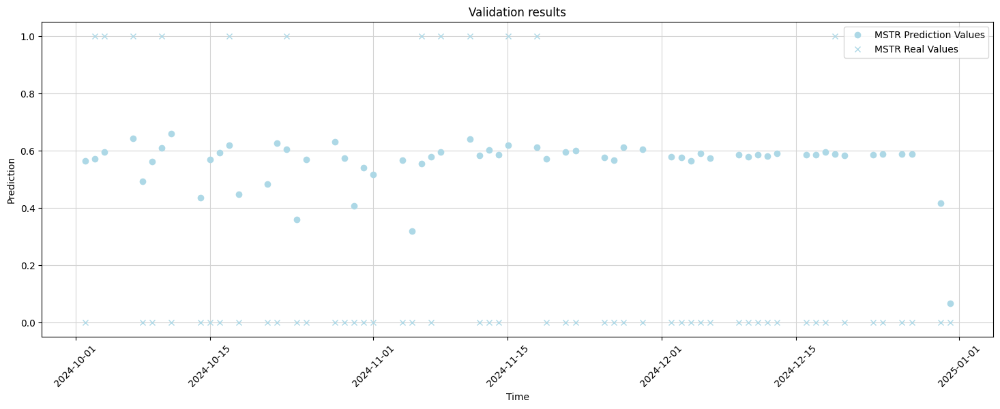

DONE PLOTTING 




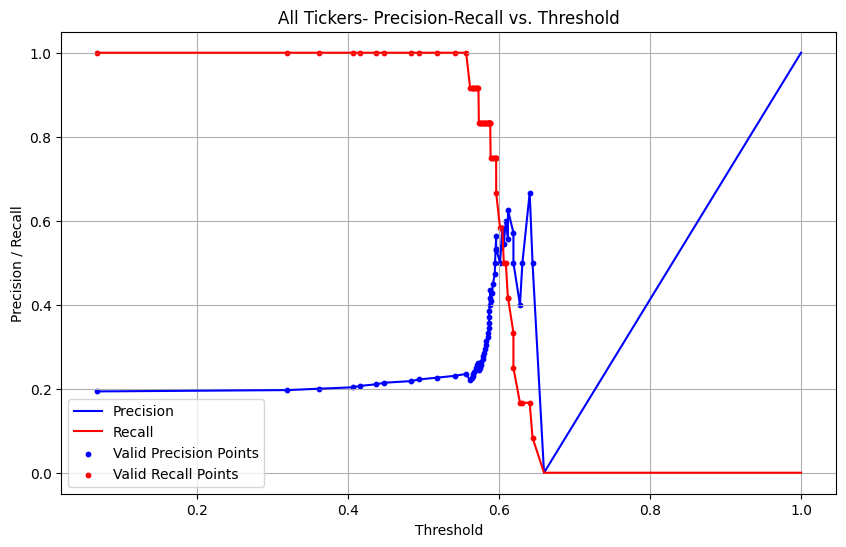

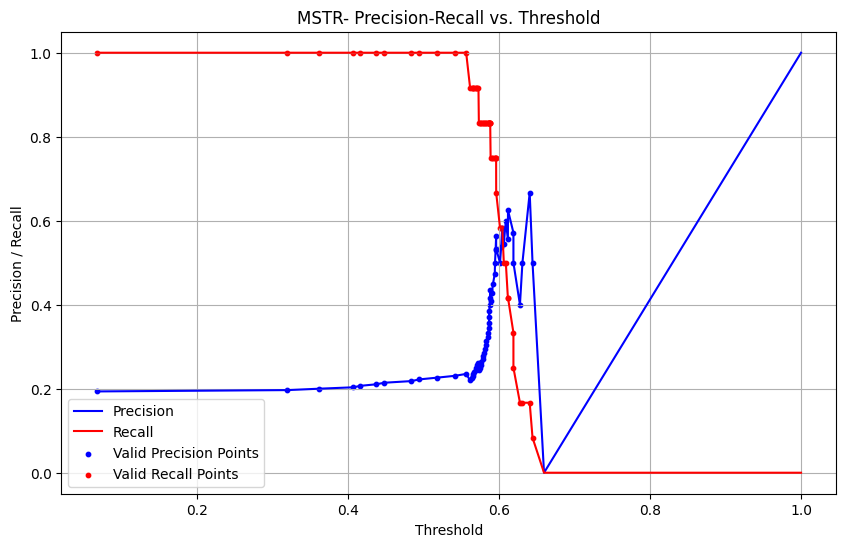

[0.         0.         0.         0.0013089  0.0013089  0.01308901
 0.01308901 0.02225131 0.02225131 0.02356021 0.02356021 0.02486911
 0.02486911 0.02748691 0.02748691 0.03534031 0.03534031 0.03926702
 0.03926702 0.04581152 0.04581152 0.04712042 0.04712042 0.05104712
 0.05104712 0.06413613 0.06413613 0.06937173 0.06937173 0.07460733
 0.07460733 0.07591623 0.07591623 0.07722513 0.07722513 0.08638743
 0.08638743 0.08769634 0.08769634 0.10340314 0.10340314 0.10471204
 0.10471204 0.10732984 0.10732984 0.11387435 0.11387435 0.12958115
 0.12958115 0.13612565 0.13612565 0.13874346 0.13874346 0.15183246
 0.15183246 0.15314136 0.15314136 0.15706806 0.15706806 0.16623037
 0.16623037 0.18324607 0.18324607 0.18455497 0.18455497 0.19109948
 0.19109948 0.19371728 0.19371728 0.20418848 0.20418848 0.21204188
 0.21204188 0.21465969 0.21465969 0.21989529 0.21989529 0.23036649
 0.23036649 0.23298429 0.23298429 0.23429319 0.23429319 0.2408377
 0.2408377  0.2552356  0.2552356  0.2565445  0.2565445  0.26308

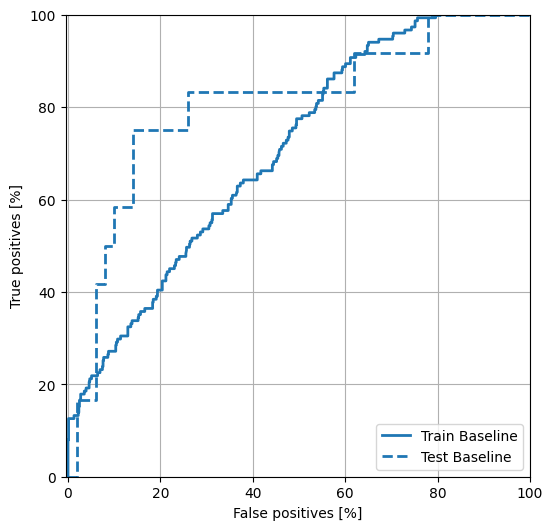

Best threshold: 0.5960298776626587
Number of true positives for the given ticker: 8
Number of false positives for the given ticker: 7
Precision score: 0.5333333333333333
Recall score: 0.6666666666666666
Random guess score: 0.1935483870967742
true-positive per ticker: Orig_Ticker
MSTR    8
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
MSTR    7
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
MSTR    4
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
MSTR    0.533333
dtype: float64
recall per ticker: Orig_Ticker
MSTR    0.666667
dtype: float64
rand guess per ticker: Orig_Ticker
MSTR    0.193548
dtype: float64
Some true positives
                          Date Orig_Ticker  y-predict-original  \
925  2024-10-10 00:00:00-04:00        MSTR            0.608871   
947  2024-11-11 00:00:00-05:00        MSTR            0.640502   
922  2024-10-07 00:00:00-04:00        MSTR            0.644255   
952  2024-11-18 00:00:00-05:

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 1 0 0 1 1 0 0 0 1 0 0 1 1 0 0 1 0 0 0 0 0 0 0 0 1 1 0 1 0 1 1 0 0 1
 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 1 1 1 0 0 1 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 1 1 0 0 0 1 1 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = valid

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['MSTR'] UNDERLYING_TARGET: Next-Day-High-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:17 mode: simple LR_RATE: 0.001 STARTING_LR: 1e-05
fetch_finance_data_for_tickers: just returning file name: MSTR for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode simple is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode simple is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, b

{'MSTR': 0}
{'Unknown': 0}
size before sigma app: 1040 for ticker: MSTR mean: 0.04086811899808716, sigma: 0.03825835991850824 upper_bound: 0.15564319875361188 lower_bound: -0.07390696075743756
size after sigma app: 1024 for ticker: MSTR
0      1.0
2      1.0
3      0.0
4      0.0
5      0.0
      ... 
962    0.0
963    0.0
964    0.0
965    0.0
966    1.0
Name: y-value, Length: 952, dtype: float64
0      1.0
2      1.0
3      0.0
4      0.0
5      0.0
      ... 
962    0.0
963    0.0
964    0.0
965    0.0
966    1.0
Name: y-value-original, Length: 952, dtype: float64
High-Low-Ratio                               0.643938
High-Open-Ratio                              0.583942
Close-Open-Ratio                             0.564503
Close-Prev-Close                             0.661494
MACD-Prev-MACD                               0.329598
200D-Ratio                                   0.521319
MACD_SIG                                     0.732406
MFI3                                         1.0

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 17, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_105 (Conv1D) │ (None, 15, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_161 (PReLU) │ (None, 15, 256)   │        256 │ conv1d_105[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_106 (Conv1D) │ (None, 7, 256)    │    196,864 │ p_re_lu_161[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_162 (PReLU) │ (None, 7, 256)    │        256 │ conv1d_106[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_107 (Conv1D) │ (None, 3, 512)    │    393,728 │ p_re_lu_162[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_163 (PReLU) │ (None, 3, 512)    │        512 │ conv1d_107[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_108 (Conv1D) │ (None, 1, 512)    │    786,944 │ p_re_lu_163[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_164 (PReLU) │ (None, 1, 512)    │        512 │ conv1d_108[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_42          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_42          │ (None, 512)       │          0 │ p_re_lu_164[0][0] │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_42[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_43          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_42      │ (None, 1024)      │          0 │ flatten_42[0][0], │
│ (Concatenate)       │                   │            │ stock_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_dense        │ (None, 256)       │     33,024 │ reshape_43[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_43      │ (None, 1280)      │          0 │ concatenate_42[0

 Total params: 2,247,451 (8.57 MB)

 Trainable params: 2,247,451 (8.57 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 14s 996ms/step - AUC: 0.5130 - Precision: 0.1135 - Recall: 0.1101 - all_positives: 13.6180 - f1_score_metric: 11.6187 - loss: 2.4730 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 160.3003 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 160.3003 - val_AUC: 0.4500 - val_Precision: 0.1250 - val_Recall: 0.1000 - val_all_positives: 10.0000 - val_f1_score_metric: 8.8889 - val_loss: 2.7770 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 80.0000 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 80.0000 - learning_rate: 1.0000e-05
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 7s 801ms/step - AUC: 0.4671 - Precision: 0.0952 - Recall: 0.3774 - all_positives: 15.0373 - f1_score_metric: 22.9384 - loss: 2.5386 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 842.1937 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 842.1937 - val_AUC: 0.4981 - val_Precision:

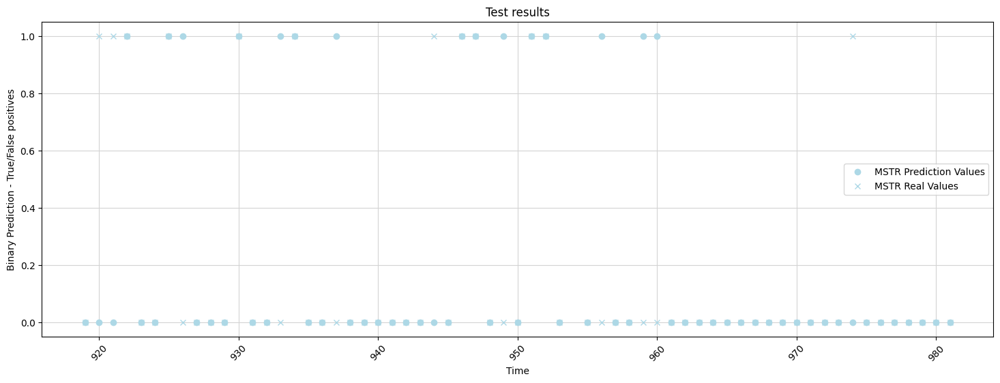

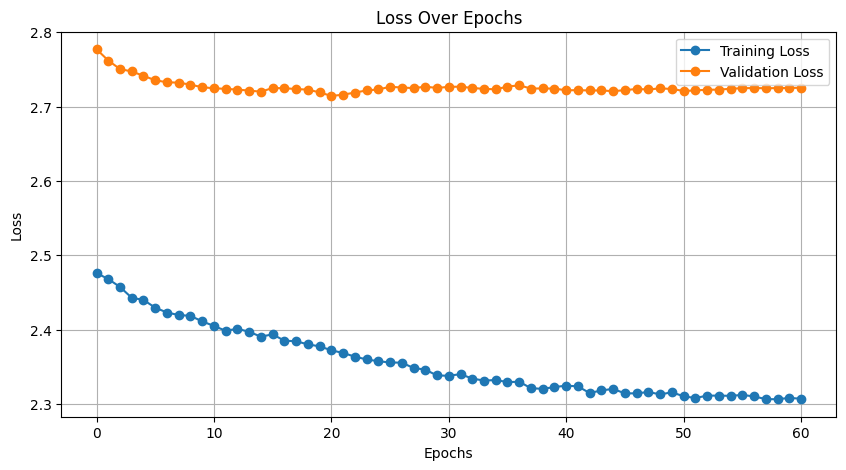

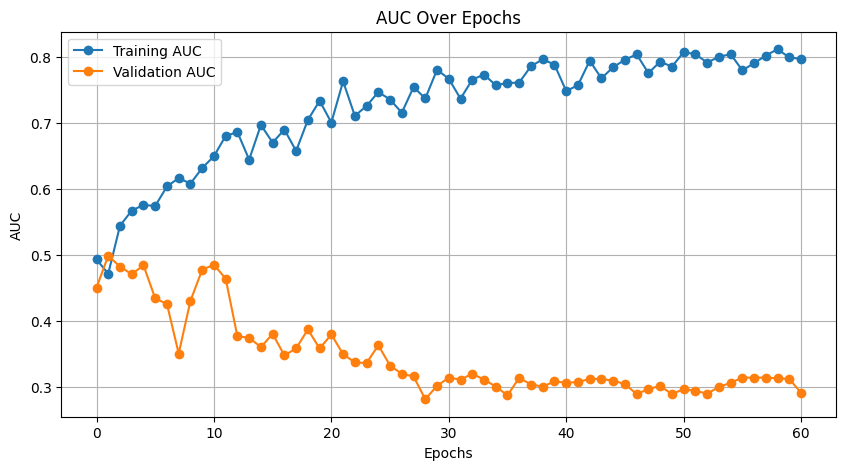



print_and_save_for
ticker data: MSTR


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
5         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
962        High-Low-Ratio  High-Open-Ratio  Close-O...   
963        High-Low-Ratio  High-Open-Ratio  Close-O...   
964        High-Low-Ratio  High-Open-Ratio  Close-O...   
965        High-Low-Ratio  High-Open-Ratio  Close-O...   
966        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2020-11-25 00:00:00-05:00       0       0         0.040868   
2    2020-11-30 00:00:00-05:00       0       0         0.040868   
3    2020-12-01 00:00:00-05:00       0     

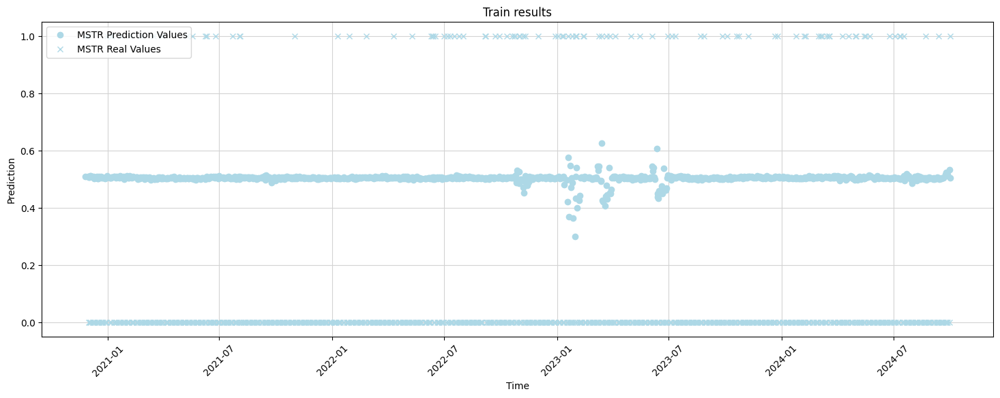

DONE PLOTTING 




print_and_save_for
ticker data: MSTR


Here is the data:                                                LstmData  \
967         High-Low-Ratio  High-Open-Ratio  Close-O...   
968         High-Low-Ratio  High-Open-Ratio  Close-O...   
969         High-Low-Ratio  High-Open-Ratio  Close-O...   
970         High-Low-Ratio  High-Open-Ratio  Close-O...   
971         High-Low-Ratio  High-Open-Ratio  Close-O...   
...                                                 ...   
1025        High-Low-Ratio  High-Open-Ratio  Close-O...   
1026        High-Low-Ratio  High-Open-Ratio  Close-O...   
1027        High-Low-Ratio  High-Open-Ratio  Close-O...   
1028        High-Low-Ratio  High-Open-Ratio  Close-O...   
1029        High-Low-Ratio  High-Open-Ratio  Close-O...   

                           Date  Ticker  Sector  Target-20D-Mean  \
967   2024-10-02 00:00:00-04:00       0       0         0.040868   
968   2024-10-03 00:00:00-04:00       0       0         0.040868   
969   2024-

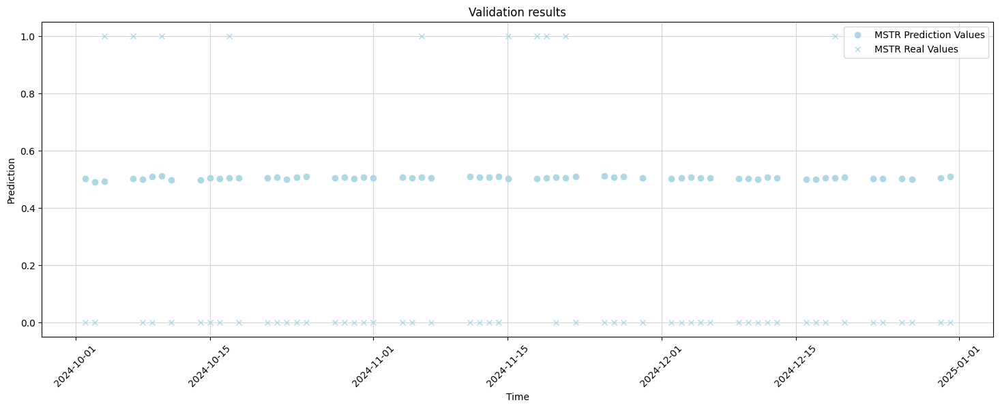

DONE PLOTTING 




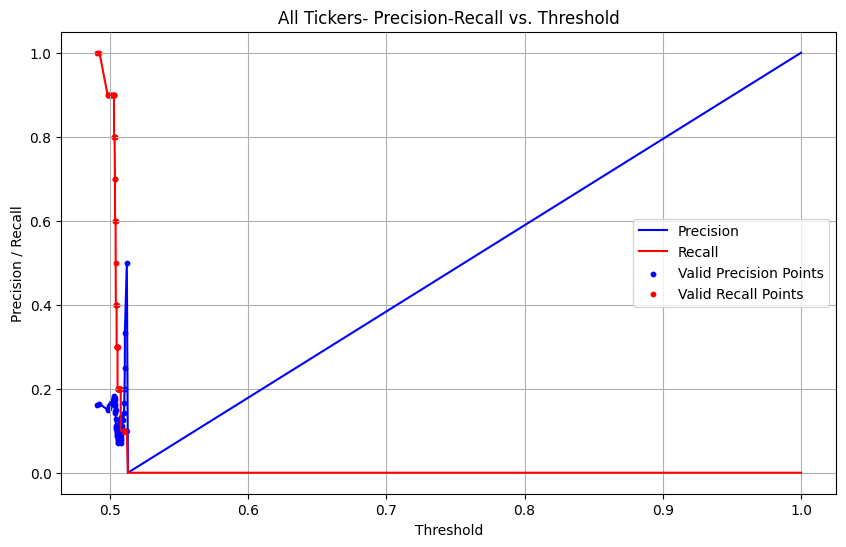

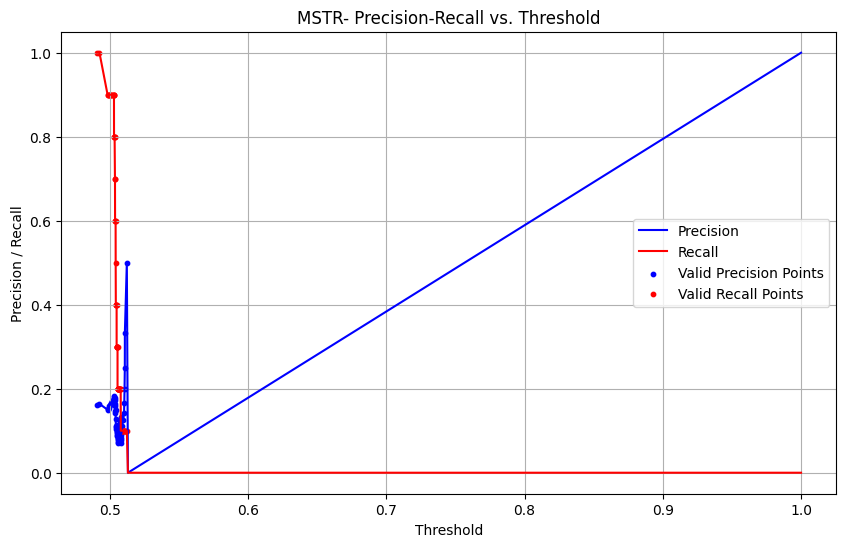

[0.         0.         0.00117786 0.00117786 0.00353357 0.00353357
 0.00588928 0.00588928 0.01177856 0.01177856 0.02002356 0.02002356
 0.02591284 0.02591284 0.0376914  0.0376914  0.04829211 0.04829211
 0.04946996 0.04946996 0.0565371  0.0565371  0.06360424 0.06360424
 0.07067138 0.07067138 0.08480565 0.08480565 0.09305065 0.09305065
 0.09893993 0.09893993 0.10129564 0.10129564 0.10600707 0.10600707
 0.11425206 0.11425206 0.1213192  0.1213192  0.12956419 0.12956419
 0.13309776 0.13309776 0.13663133 0.13663133 0.14487633 0.14487633
 0.15547703 0.15547703 0.16018846 0.16018846 0.19316843 0.19316843
 0.21672556 0.21672556 0.21790342 0.21790342 0.24146054 0.24146054
 0.24734982 0.24734982 0.25206125 0.25206125 0.27326266 0.27326266
 0.27444052 0.27444052 0.28739694 0.28739694 0.28857479 0.28857479
 0.32862191 0.32862191 0.3368669  0.3368669  0.36160188 0.36160188
 0.36866902 0.36866902 0.39458186 0.39458186 0.39693757 0.39693757
 0.401649   0.401649   0.41224971 0.41224971 0.41931684 0.4193

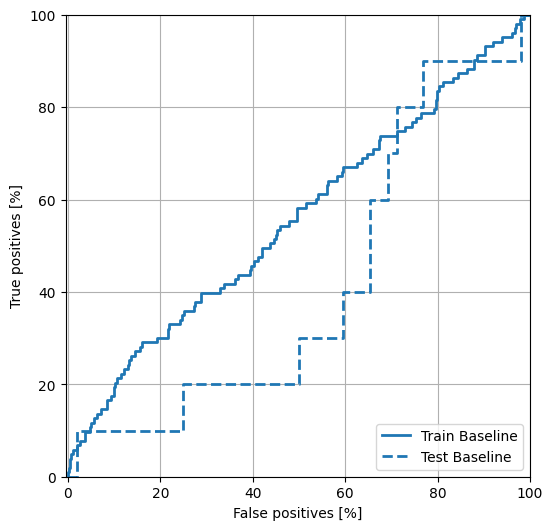

Best threshold: 0.5123370885848999
Number of true positives for the given ticker: 0
Number of false positives for the given ticker: 1
Precision score: 0.0
Recall score: 0.0
Random guess score: 0.16129032258064516
true-positive per ticker: Orig_Ticker
MSTR    0
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
MSTR    1
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
MSTR    10
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
MSTR    0.0
dtype: float64
recall per ticker: Orig_Ticker
MSTR    0.0
dtype: float64
rand guess per ticker: Orig_Ticker
MSTR    0.16129
dtype: float64
Some true positives
Empty DataFrame
Columns: [Date, Orig_Ticker, y-predict-original, y-value-original, Target-20D-Mean, Target-20D-Sigma]
Index: []
Some false positives
                           Date Orig_Ticker  y-predict-original  \
1005  2024-11-25 00:00:00-05:00        MSTR            0.513132   

      y-value-original  Target-20D-Mean  Target

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 1 1 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 1 1 0 1 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = valid

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['MSTR'] UNDERLYING_TARGET: Next-Day-High-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:33 mode: medium LR_RATE: 0.0005 STARTING_LR: 0.0001
fetch_finance_data_for_tickers: just returning file name: MSTR for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode medium is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode medium is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, b

{'MSTR': 0}
{'Unknown': 0}
size before sigma app: 1024 for ticker: MSTR mean: 0.04086811899808716, sigma: 0.03825835991850824 upper_bound: 0.15564319875361188 lower_bound: -0.07390696075743756
size after sigma app: 1009 for ticker: MSTR
0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
946    0.0
947    0.0
948    0.0
949    0.0
950    1.0
Name: y-value, Length: 937, dtype: float64
0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
946    0.0
947    0.0
948    0.0
949    0.0
950    1.0
Name: y-value-original, Length: 937, dtype: float64
High-Low-Ratio                               0.643938
High-Open-Ratio                              0.583942
Close-Open-Ratio                             0.564503
Close-Prev-Close                             0.661494
MACD-Prev-MACD                               0.329598
200D-Ratio                                   0.521319
MACD_SIG                                     0.732406
MFI3                                         1.0

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 33, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_109 (Conv1D) │ (None, 31, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_167 (PReLU) │ (None, 31, 256)   │        256 │ conv1d_109[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_110 (Conv1D) │ (None, 15, 256)   │    196,864 │ p_re_lu_167[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_168 (PReLU) │ (None, 15, 256)   │        256 │ conv1d_110[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_111 (Conv1D) │ (None, 7, 512)    │    393,728 │ p_re_lu_168[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_169 (PReLU) │ (None, 7, 512)    │        512 │ conv1d_111[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_112 (Conv1D) │ (None, 3, 512)    │    786,944 │ p_re_lu_169[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_170 (PReLU) │ (None, 3, 512)    │        512 │ conv1d_112[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_113 (Conv1D) │ (None, 1, 1024)   │  1,573,888 │ p_re_lu_170[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_171 (PReLU) │ (None, 1, 1024)   │      1,024 │ conv1d_113[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_44          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_44          │ (None, 1024)      │          0 │ p_re_lu_171[0][0] │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_44[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_45          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_44      │ (None, 1536)      │          0 │ flatten_44[0][0], │
│ (Concatenate)       │                   │            │ stock_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 7,696,364 (29.36 MB)

 Trainable params: 7,696,364 (29.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - AUC: 0.5070 - Precision: 0.0896 - Recall: 0.5588 - all_positives: 12.2542 - f1_score_metric: 19.0227 - loss: 2.1559 - precision_with_threshold_fixed: 1.7976 - recall_mul_prediction: 870.0233 - recall_with_threshold_fixed: 0.5291 - true_positives: 870.0233 - val_AUC: 0.6279 - val_Precision: 0.1613 - val_Recall: 1.0000 - val_all_positives: 10.0000 - val_f1_score_metric: 17.2222 - val_loss: 2.4709 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 620.0000 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 620.0000 - learning_rate: 1.0000e-04
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 7s 869ms/step - AUC: 0.6031 - Precision: 0.1189 - Recall: 0.9920 - all_positives: 14.7251 - f1_score_metric: 26.1775 - loss: 2.1931 - precision_with_threshold_fixed: 14.7251 - recall_mul_prediction: 1841.4299 - recall_with_threshold_fixed: 3.3831 - true_positives: 1841.4299 - val_AUC: 0.5808 - val_Precision: 0.2000 - val

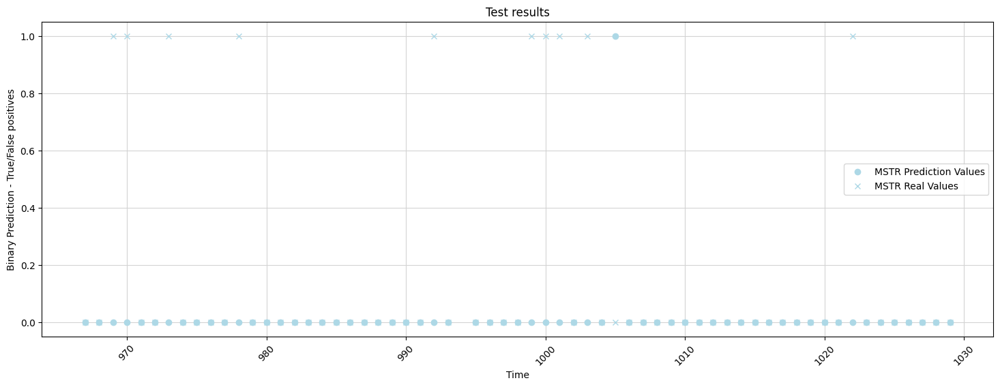

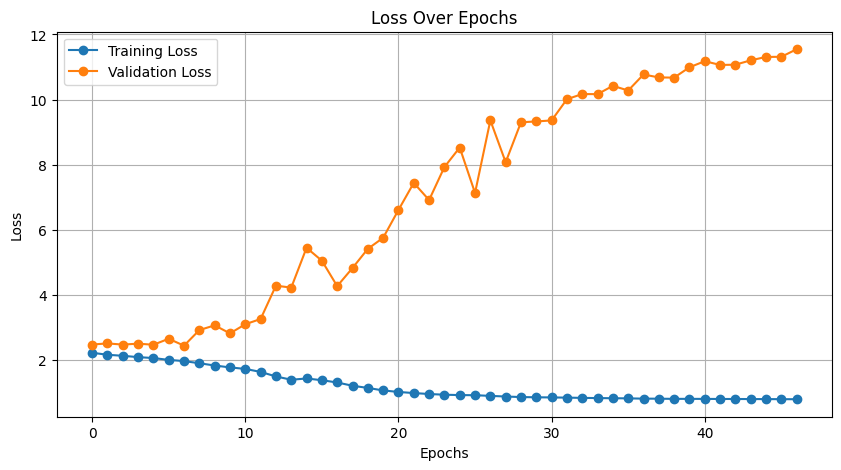

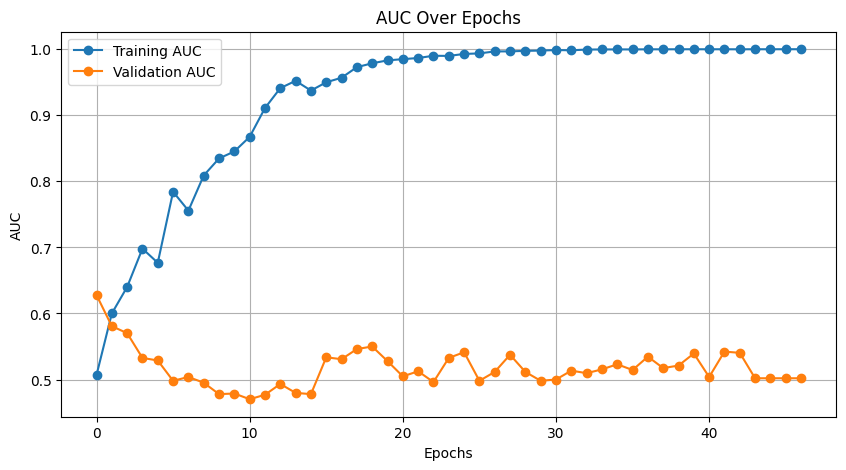



print_and_save_for
ticker data: MSTR


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
946        High-Low-Ratio  High-Open-Ratio  Close-O...   
947        High-Low-Ratio  High-Open-Ratio  Close-O...   
948        High-Low-Ratio  High-Open-Ratio  Close-O...   
949        High-Low-Ratio  High-Open-Ratio  Close-O...   
950        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2020-12-18 00:00:00-05:00       0       0         0.040868   
1    2020-12-21 00:00:00-05:00       0       0         0.040868   
2    2020-12-22 00:00:00-05:00       0     

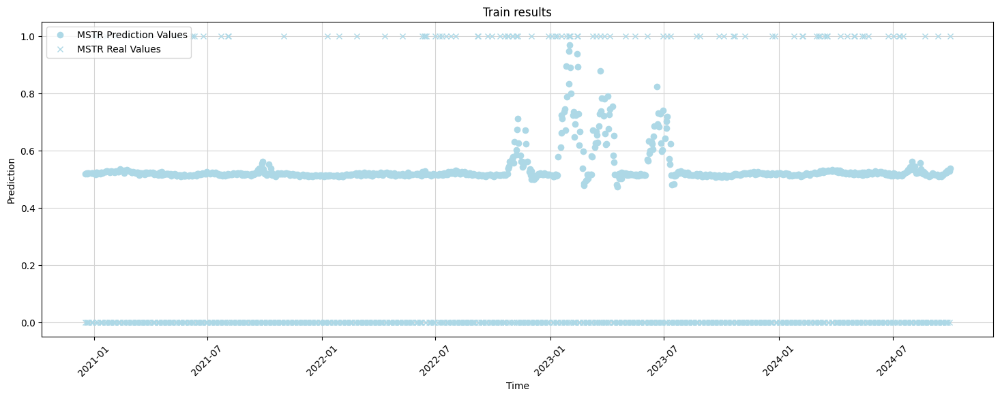

DONE PLOTTING 




print_and_save_for
ticker data: MSTR


Here is the data:                                                LstmData  \
951         High-Low-Ratio  High-Open-Ratio  Close-O...   
952         High-Low-Ratio  High-Open-Ratio  Close-O...   
953         High-Low-Ratio  High-Open-Ratio  Close-O...   
954         High-Low-Ratio  High-Open-Ratio  Close-O...   
955         High-Low-Ratio  High-Open-Ratio  Close-O...   
...                                                 ...   
1009        High-Low-Ratio  High-Open-Ratio  Close-O...   
1010        High-Low-Ratio  High-Open-Ratio  Close-O...   
1011        High-Low-Ratio  High-Open-Ratio  Close-O...   
1012        High-Low-Ratio  High-Open-Ratio  Close-O...   
1013        High-Low-Ratio  High-Open-Ratio  Close-O...   

                           Date  Ticker  Sector  Target-20D-Mean  \
951   2024-10-02 00:00:00-04:00       0       0         0.040868   
952   2024-10-03 00:00:00-04:00       0       0         0.040868   
953   2024-

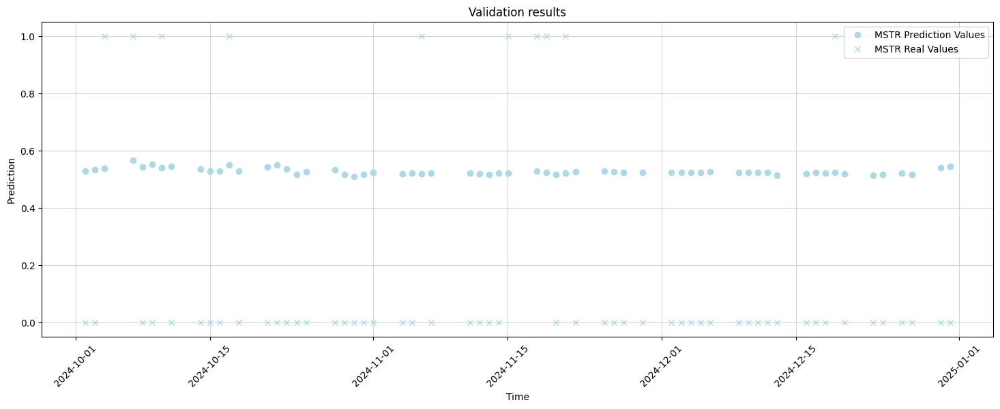

DONE PLOTTING 




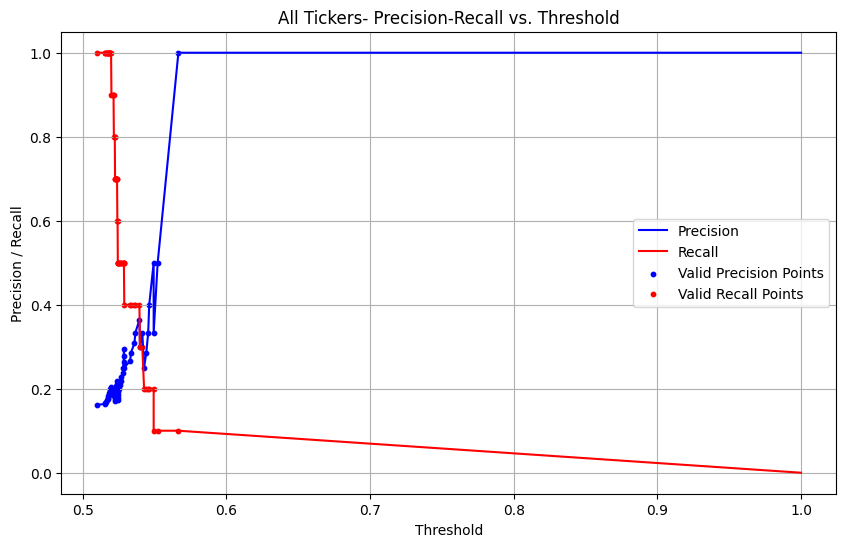

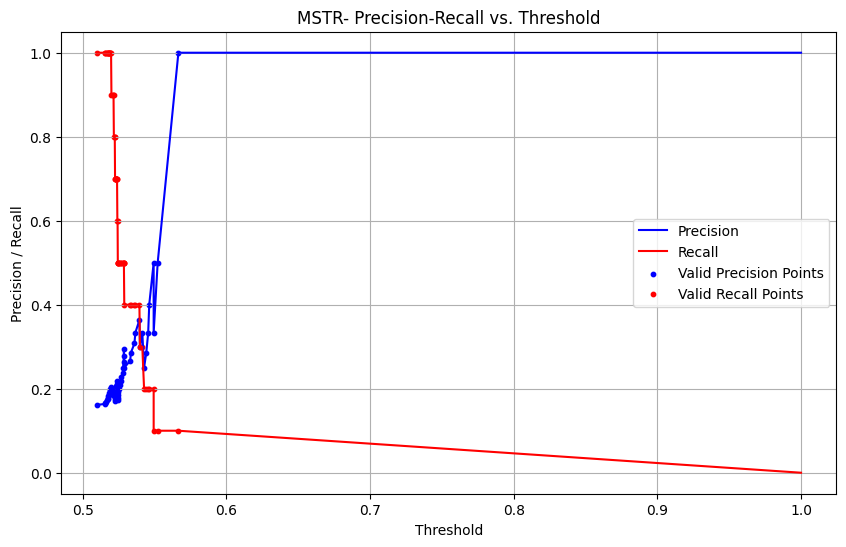

[0.         0.         0.         0.00717703 0.00717703 0.00956938
 0.00956938 0.0215311  0.0215311  0.02272727 0.02272727 0.02392344
 0.02392344 0.034689   0.034689   0.03708134 0.03708134 0.0562201
 0.0562201  0.07177033 0.07177033 0.0777512  0.0777512  0.07894737
 0.07894737 0.10885167 0.10885167 0.11842105 0.11842105 0.13875598
 0.13875598 0.14354067 0.14354067 0.14832536 0.14832536 0.15191388
 0.15191388 0.15430622 0.15430622 0.1638756  0.1638756  0.16626794
 0.16626794 0.1937799  0.1937799  0.23205742 0.23205742 0.23325359
 0.23325359 0.24760766 0.24760766 0.25717703 0.25717703 0.25956938
 0.25956938 0.27990431 0.27990431 0.284689   0.284689   0.28588517
 0.28588517 0.28708134 0.28708134 0.29066986 0.29066986 0.29904306
 0.29904306 0.31100478 0.31339713 0.34449761 0.34449761 0.34688995
 0.34688995 0.34808612 0.34808612 0.35167464 0.35167464 0.35406699
 0.35406699 0.39712919 0.39712919 0.39952153 0.39952153 0.40909091
 0.40909091 0.41626794 0.41626794 0.4222488  0.4222488  0.43899

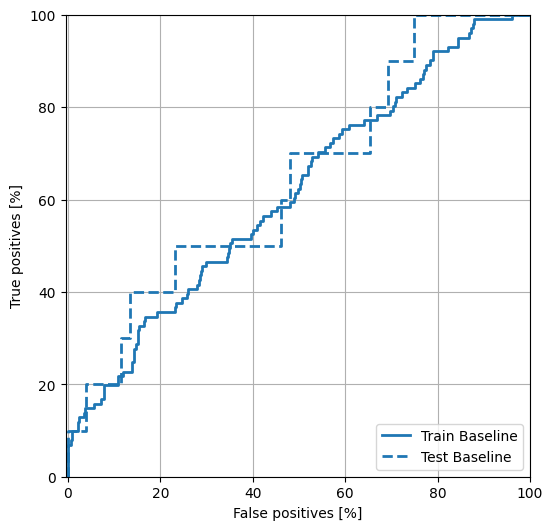

Best threshold: 0.5494474768638611
Number of true positives for the given ticker: 1
Number of false positives for the given ticker: 2
Precision score: 0.3333333333333333
Recall score: 0.1
Random guess score: 0.16129032258064516
true-positive per ticker: Orig_Ticker
MSTR    1
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
MSTR    2
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
MSTR    9
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
MSTR    0.333333
dtype: float64
recall per ticker: Orig_Ticker
MSTR    0.1
dtype: float64
rand guess per ticker: Orig_Ticker
MSTR    0.16129
dtype: float64
Some true positives
                          Date Orig_Ticker  y-predict-original  \
954  2024-10-07 00:00:00-04:00        MSTR            0.566664   

     y-value-original  Target-20D-Mean  Target-20D-Sigma  
954               1.0         0.040868          0.038258  
Some false positives
                          Date Orig_Tick

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 1 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 1 1 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 1 1 0 1 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = valid

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['MSTR'] UNDERLYING_TARGET: Next-Day-High-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:65 mode: complex LR_RATE: 0.0001 STARTING_LR: 0.001
fetch_finance_data_for_tickers: just returning file name: MSTR for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode complex is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode complex is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names,

{'MSTR': 0}
{'Unknown': 0}
size before sigma app: 992 for ticker: MSTR mean: 0.04086811899808716, sigma: 0.03825835991850824 upper_bound: 0.15564319875361188 lower_bound: -0.07390696075743756
size after sigma app: 978 for ticker: MSTR
0      1.0
2      0.0
3      0.0
4      0.0
5      0.0
      ... 
914    0.0
915    0.0
916    0.0
917    0.0
918    1.0
Name: y-value, Length: 906, dtype: float64
0      1.0
2      0.0
3      0.0
4      0.0
5      0.0
      ... 
914    0.0
915    0.0
916    0.0
917    0.0
918    1.0
Name: y-value-original, Length: 906, dtype: float64
High-Low-Ratio                               0.643938
High-Open-Ratio                              0.583942
Close-Open-Ratio                             0.564503
Close-Prev-Close                             0.661494
MACD-Prev-MACD                               0.329598
200D-Ratio                                   0.521319
MACD_SIG                                     0.732406
MFI3                                         1.000

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 65, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_114 (Conv1D) │ (None, 63, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_175 (PReLU) │ (None, 63, 256)   │        256 │ conv1d_114[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_115 (Conv1D) │ (None, 31, 256)   │    196,864 │ p_re_lu_175[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_176 (PReLU) │ (None, 31, 256)   │        256 │ conv1d_115[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_116 (Conv1D) │ (None, 15, 512)   │    393,728 │ p_re_lu_176[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_177 (PReLU) │ (None, 15, 512)   │        512 │ conv1d_116[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_117 (Conv1D) │ (None, 7, 512)    │    786,944 │ p_re_lu_177[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_178 (PReLU) │ (None, 7, 512)    │        512 │ conv1d_117[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_118 (Conv1D) │ (None, 3, 1024)   │  1,573,888 │ p_re_lu_178[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_179 (PReLU) │ (None, 3, 1024)   │      1,024 │ conv1d_118[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_119 (Conv1D) │ (None, 1, 1024)   │  3,146,752 │ p_re_lu_179[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_180 (PReLU) │ (None, 1, 1024)   │      1,024 │ conv1d_119[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_46          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_46          │ (None, 1024)      │          0 │ p_re_lu_180[0][0] │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_46[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_47          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                 

 Total params: 10,844,140 (41.37 MB)

 Trainable params: 10,844,140 (41.37 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - AUC: 0.4904 - Precision: 0.0971 - Recall: 0.3226 - all_positives: 11.4754 - f1_score_metric: 11.5848 - loss: 1.6282 - precision_with_threshold_fixed: 3.8085 - recall_mul_prediction: 470.2011 - recall_with_threshold_fixed: 15.1037 - true_positives: 470.2010 - val_AUC: 0.4481 - val_Precision: 0.1613 - val_Recall: 1.0000 - val_all_positives: 10.0000 - val_f1_score_metric: 17.2222 - val_loss: 1.8879 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 620.0000 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 620.0000 - learning_rate: 0.0010
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - AUC: 0.5115 - Precision: 0.1018 - Recall: 0.9743 - all_positives: 12.5950 - f1_score_metric: 22.7763 - loss: 1.5470 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 1559.6027 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 1559.6027 - val_AUC: 0.5000 - val_Precision: 0.1613 - va

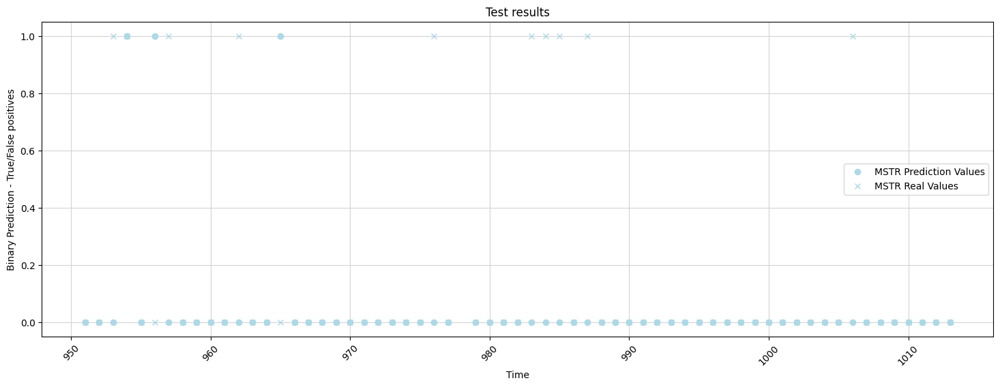

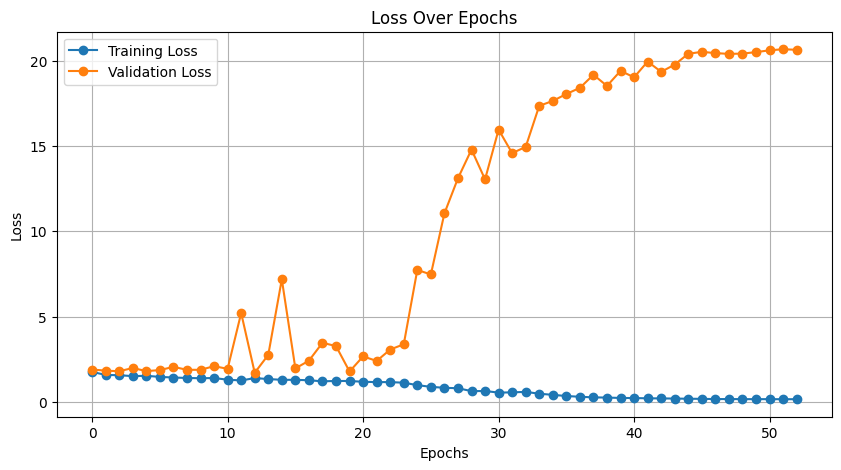

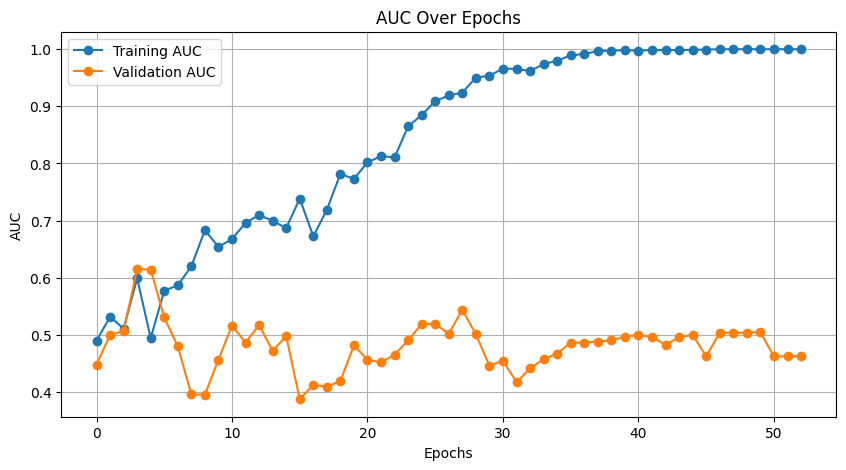



print_and_save_for
ticker data: MSTR


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
5         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
914        High-Low-Ratio  High-Open-Ratio  Close-O...   
915        High-Low-Ratio  High-Open-Ratio  Close-O...   
916        High-Low-Ratio  High-Open-Ratio  Close-O...   
917        High-Low-Ratio  High-Open-Ratio  Close-O...   
918        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2021-02-05 00:00:00-05:00       0       0         0.040868   
2    2021-02-09 00:00:00-05:00       0       0         0.040868   
3    2021-02-10 00:00:00-05:00       0     

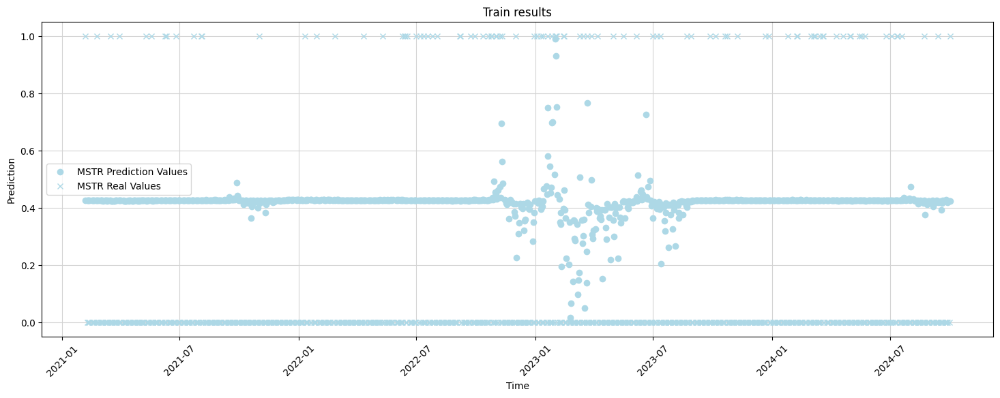

DONE PLOTTING 




print_and_save_for
ticker data: MSTR


Here is the data:                                               LstmData  \
919        High-Low-Ratio  High-Open-Ratio  Close-O...   
920        High-Low-Ratio  High-Open-Ratio  Close-O...   
921        High-Low-Ratio  High-Open-Ratio  Close-O...   
922        High-Low-Ratio  High-Open-Ratio  Close-O...   
923        High-Low-Ratio  High-Open-Ratio  Close-O...   
..                                                 ...   
977        High-Low-Ratio  High-Open-Ratio  Close-O...   
978        High-Low-Ratio  High-Open-Ratio  Close-O...   
979        High-Low-Ratio  High-Open-Ratio  Close-O...   
980        High-Low-Ratio  High-Open-Ratio  Close-O...   
981        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
919  2024-10-02 00:00:00-04:00       0       0         0.040868   
920  2024-10-03 00:00:00-04:00       0       0         0.040868   
921  2024-10-04 00:00:00-0

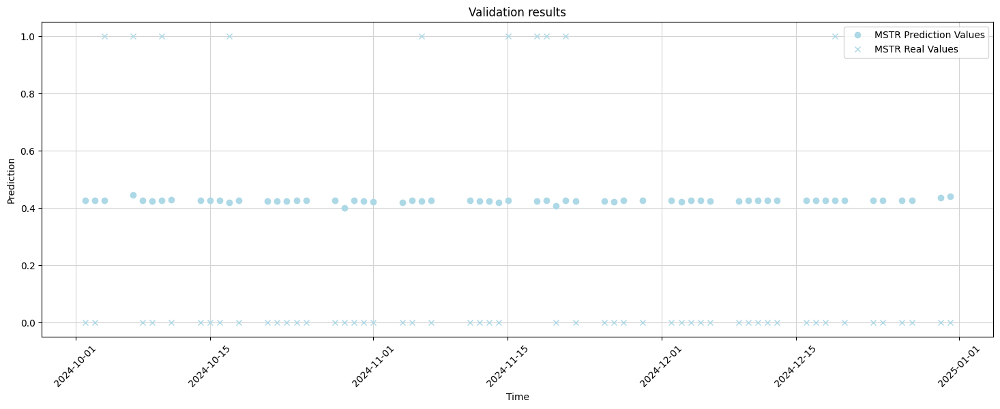

DONE PLOTTING 




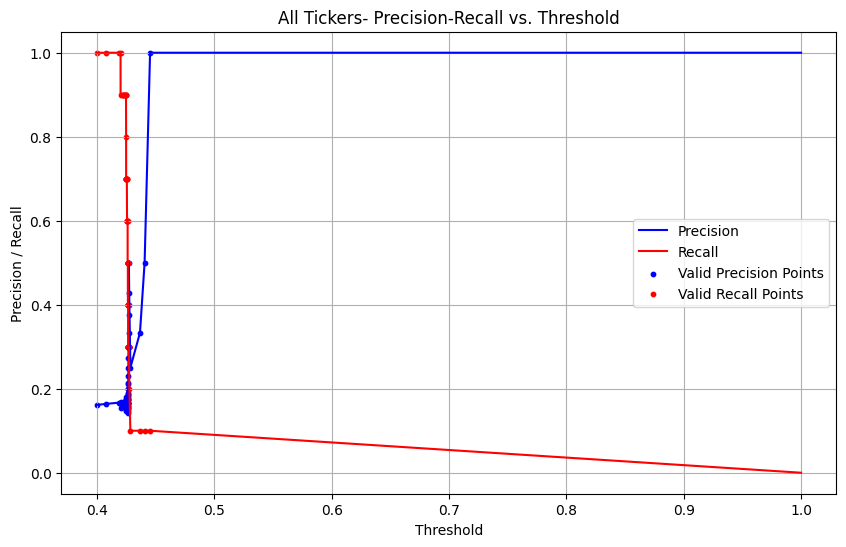

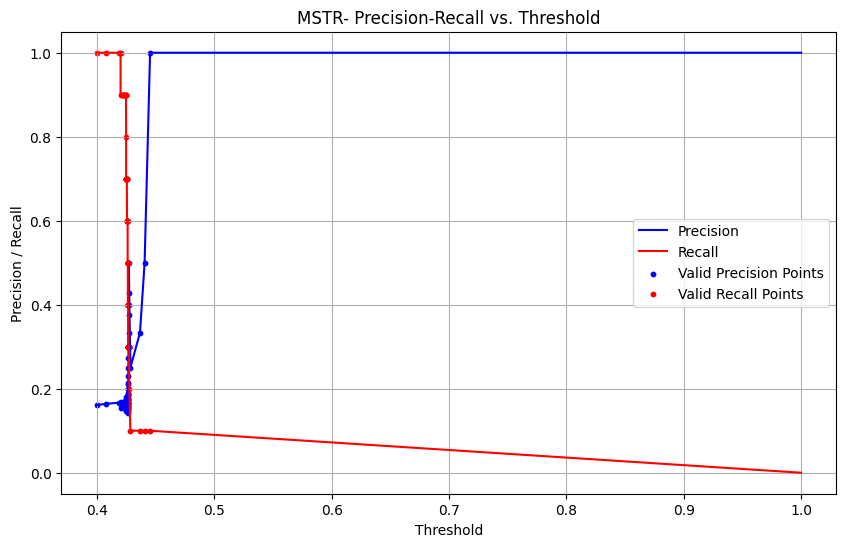

[0.         0.         0.         0.00246914 0.00246914 0.00493827
 0.00493827 0.00864198 0.00864198 0.01728395 0.01728395 0.02222222
 0.02222222 0.02592593 0.02592593 0.03333333 0.03333333 0.04691358
 0.04691358 0.06666667 0.06666667 0.0691358  0.0691358  0.08518519
 0.08518519 0.10246914 0.10246914 0.11728395 0.11728395 0.11975309
 0.11975309 0.12469136 0.12469136 0.14567901 0.14567901 0.15555556
 0.15555556 0.16049383 0.16049383 0.17530864 0.17777778 0.17777778
 0.19012346 0.19012346 0.19382716 0.19382716 0.20246914 0.20246914
 0.22469136 0.22469136 0.22716049 0.22962963 0.23333333 0.23333333
 0.26049383 0.26049383 0.29876543 0.29876543 0.3037037  0.3037037
 0.30617284 0.30617284 0.33333333 0.33333333 0.3382716  0.34074074
 0.34074074 0.34197531 0.34197531 0.34814815 0.34814815 0.36049383
 0.36049383 0.36419753 0.36419753 0.37901235 0.37901235 0.38518519
 0.38518519 0.38765432 0.38765432 0.3962963  0.3962963  0.41851852
 0.42098765 0.4382716  0.4382716  0.4691358  0.4691358  0.47407

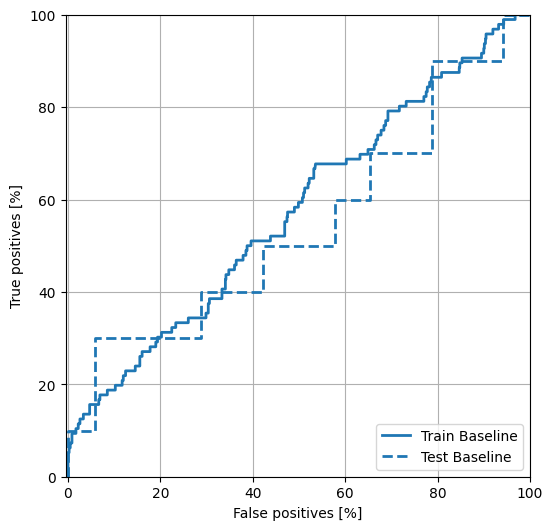

Best threshold: 0.427181601524353
Number of true positives for the given ticker: 2
Number of false positives for the given ticker: 3
Precision score: 0.4
Recall score: 0.2
Random guess score: 0.16129032258064516
true-positive per ticker: Orig_Ticker
MSTR    2
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
MSTR    3
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
MSTR    8
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
MSTR    0.4
dtype: float64
recall per ticker: Orig_Ticker
MSTR    0.2
dtype: float64
rand guess per ticker: Orig_Ticker
MSTR    0.16129
dtype: float64
Some true positives
                          Date Orig_Ticker  y-predict-original  \
925  2024-10-10 00:00:00-04:00        MSTR            0.427623   
922  2024-10-07 00:00:00-04:00        MSTR            0.445258   

     y-value-original  Target-20D-Mean  Target-20D-Sigma  
925               1.0         0.040868          0.038258  
922             

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 1 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 1 1 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 1 1 0 1 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = valid

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['MSFT'] UNDERLYING_TARGET: Next-Day-Close-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:17 mode: simple LR_RATE: 0.001 STARTING_LR: 1e-05
fetch_finance_data_for_tickers: just returning file name: MSFT for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode simple is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode simple is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, b

{'MSFT': 0}
{'Tech': 0}
size before sigma app: 1041 for ticker: MSFT mean: -0.0004805842976568784, sigma: 0.010630432953399079 upper_bound: 0.03141071456254036 lower_bound: -0.032371883157854116
size after sigma app: 1018 for ticker: MSFT
0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
972    0.0
973    0.0
974    0.0
975    0.0
976    0.0
Name: y-value, Length: 954, dtype: float64
0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
972    0.0
973    0.0
974    0.0
975    0.0
976    0.0
Name: y-value-original, Length: 954, dtype: float64
High-Low-Ratio                               0.600427
High-Open-Ratio                              0.536376
Close-Open-Ratio                             0.473355
Close-Prev-Close                             0.510037
MACD-Prev-MACD                               0.263661
200D-Ratio                                   0.430369
MACD_SIG                                     0.962874
MFI3                                         0

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 17, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_120 (Conv1D) │ (None, 15, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_184 (PReLU) │ (None, 15, 256)   │        256 │ conv1d_120[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_121 (Conv1D) │ (None, 7, 256)    │    196,864 │ p_re_lu_184[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_185 (PReLU) │ (None, 7, 256)    │        256 │ conv1d_121[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_122 (Conv1D) │ (None, 3, 512)    │    393,728 │ p_re_lu_185[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_186 (PReLU) │ (None, 3, 512)    │        512 │ conv1d_122[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_123 (Conv1D) │ (None, 1, 512)    │    786,944 │ p_re_lu_186[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_187 (PReLU) │ (None, 1, 512)    │        512 │ conv1d_123[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_48          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_48          │ (None, 512)       │          0 │ p_re_lu_187[0][0] │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_48[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_49          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_48      │ (None, 1024)      │          0 │ flatten_48[0][0], │
│ (Concatenate)       │                   │            │ stock_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_dense        │ (None, 256)       │     33,024 │ reshape_49[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_49      │ (None, 1280)      │          0 │ concatenate_48[0

 Total params: 2,247,451 (8.57 MB)

 Trainable params: 2,247,451 (8.57 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - AUC: 0.5156 - Precision: 0.1809 - Recall: 0.5636 - all_positives: 21.4230 - f1_score_metric: 31.9439 - loss: 2.4055 - precision_with_threshold_fixed: 2.3294 - recall_mul_prediction: 1416.9515 - recall_with_threshold_fixed: 0.1058 - true_positives: 1416.9515 - val_AUC: 0.5539 - val_Precision: 0.2414 - val_Recall: 1.0000 - val_all_positives: 14.0000 - val_f1_score_metric: 22.5556 - val_loss: 2.5523 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 812.0001 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 812.0000 - learning_rate: 1.0000e-05
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 676ms/step - AUC: 0.5880 - Precision: 0.1650 - Recall: 0.9113 - all_positives: 20.3632 - f1_score_metric: 34.3766 - loss: 2.3674 - precision_with_threshold_fixed: 9.3344 - recall_mul_prediction: 2309.0249 - recall_with_threshold_fixed: 0.4013 - true_positives: 2309.0249 - val_AUC: 0.5488 - val_Precision: 0.2295 - va

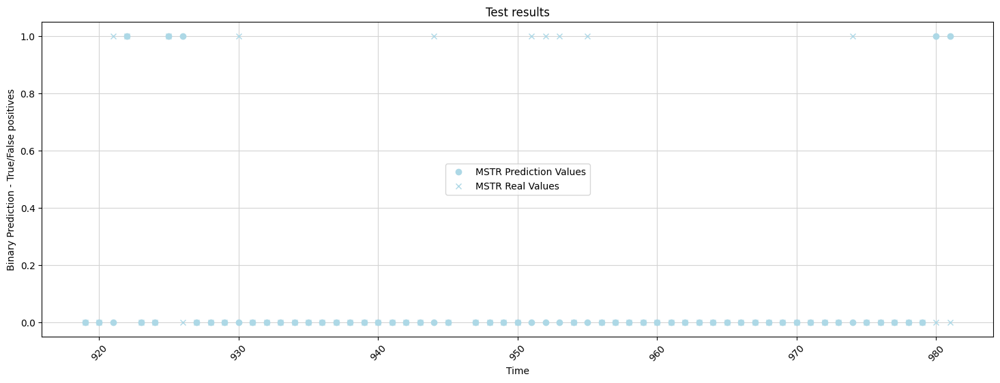

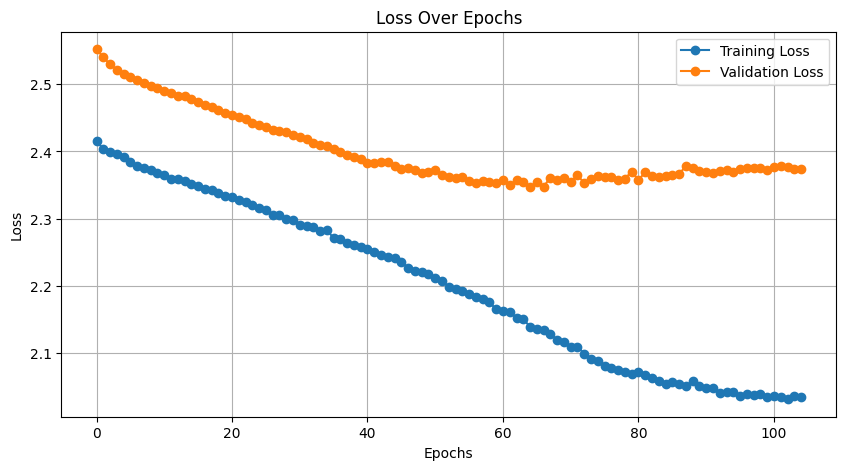

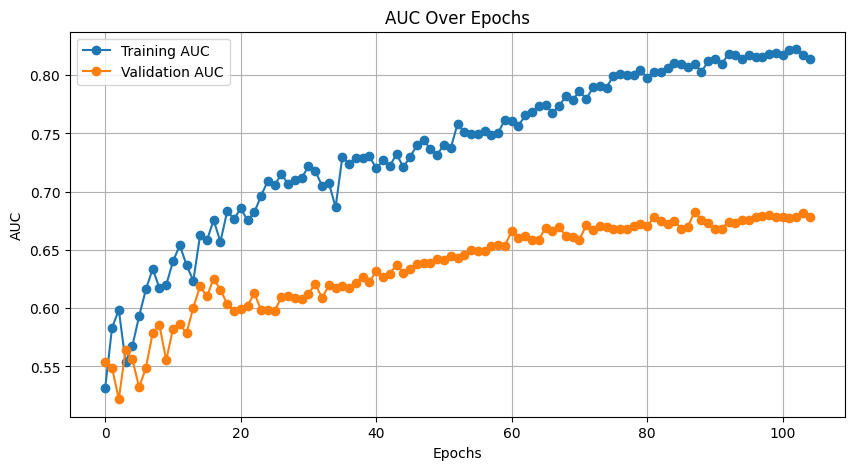



print_and_save_for
ticker data: MSFT


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
972        High-Low-Ratio  High-Open-Ratio  Close-O...   
973        High-Low-Ratio  High-Open-Ratio  Close-O...   
974        High-Low-Ratio  High-Open-Ratio  Close-O...   
975        High-Low-Ratio  High-Open-Ratio  Close-O...   
976        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2020-11-11 00:00:00-05:00       0       0        -0.000481   
1    2020-11-12 00:00:00-05:00       0       0        -0.000481   
2    2020-11-13 00:00:00-05:00       0     

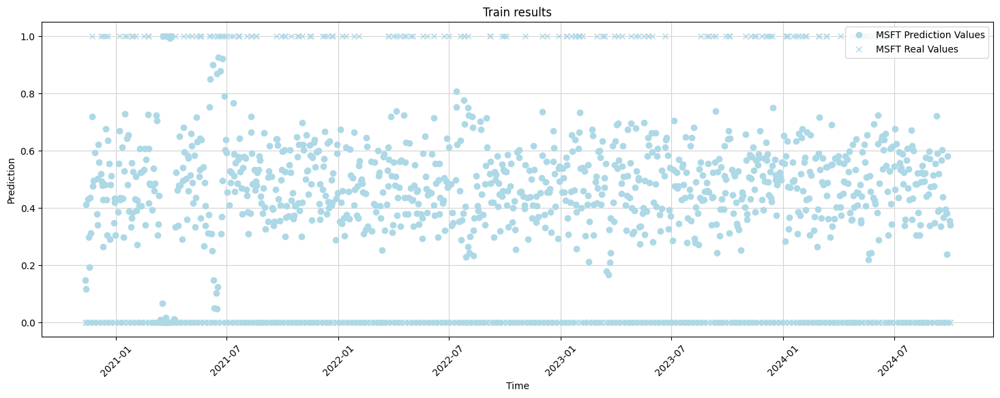

DONE PLOTTING 




print_and_save_for
ticker data: MSFT


Here is the data:                                                LstmData  \
977         High-Low-Ratio  High-Open-Ratio  Close-O...   
978         High-Low-Ratio  High-Open-Ratio  Close-O...   
979         High-Low-Ratio  High-Open-Ratio  Close-O...   
980         High-Low-Ratio  High-Open-Ratio  Close-O...   
981         High-Low-Ratio  High-Open-Ratio  Close-O...   
...                                                 ...   
1035        High-Low-Ratio  High-Open-Ratio  Close-O...   
1036        High-Low-Ratio  High-Open-Ratio  Close-O...   
1037        High-Low-Ratio  High-Open-Ratio  Close-O...   
1038        High-Low-Ratio  High-Open-Ratio  Close-O...   
1039        High-Low-Ratio  High-Open-Ratio  Close-O...   

                           Date  Ticker  Sector  Target-20D-Mean  \
977   2024-10-02 00:00:00-04:00       0       0        -0.000481   
978   2024-10-03 00:00:00-04:00       0       0        -0.000481   
979   2024-

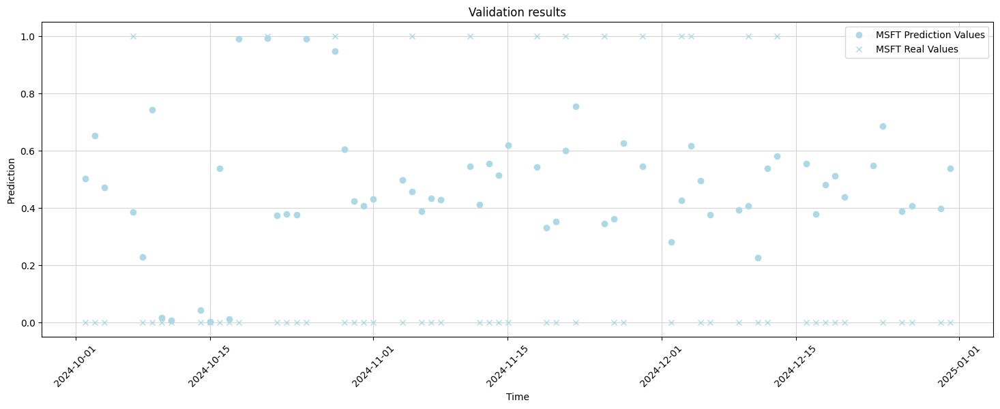

DONE PLOTTING 




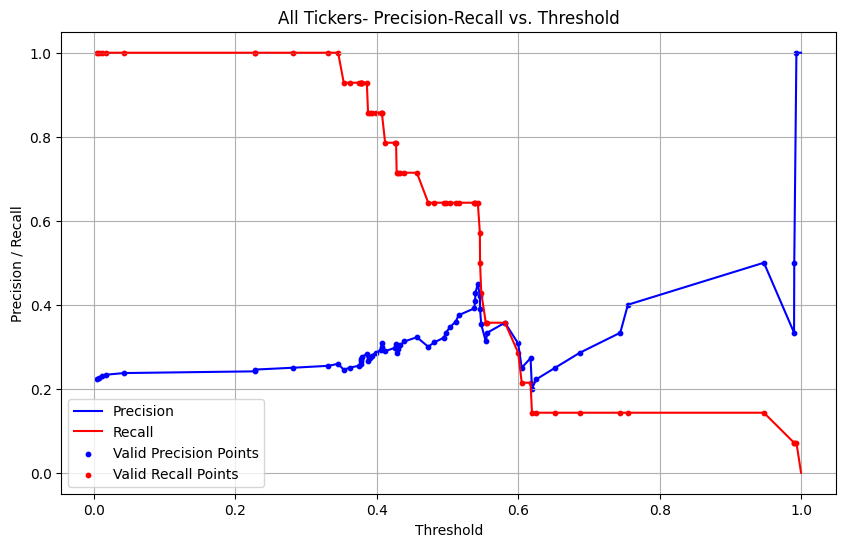

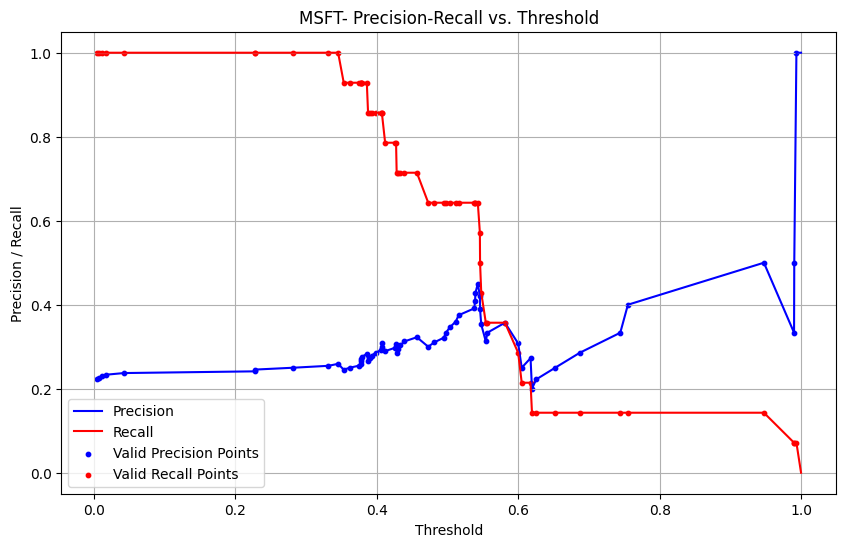

[0.         0.         0.         0.00126904 0.00126904 0.00253807
 0.00253807 0.00380711 0.00380711 0.00507614 0.00507614 0.00634518
 0.00634518 0.00888325 0.00888325 0.01395939 0.01395939 0.01522843
 0.01522843 0.0177665  0.0177665  0.02030457 0.02030457 0.02664975
 0.02664975 0.02918782 0.02918782 0.03045685 0.03045685 0.03680203
 0.03680203 0.03807107 0.03807107 0.04187817 0.04187817 0.04441624
 0.04441624 0.05456853 0.05456853 0.05583756 0.05583756 0.05964467
 0.05964467 0.06345178 0.06345178 0.06598985 0.06598985 0.06852792
 0.06852792 0.07360406 0.07360406 0.07614213 0.07614213 0.07741117
 0.07741117 0.0786802  0.0786802  0.08629442 0.08629442 0.08756345
 0.08756345 0.08883249 0.08883249 0.09010152 0.09010152 0.09137056
 0.09137056 0.09517766 0.09517766 0.0964467  0.0964467  0.10279188
 0.10279188 0.11167513 0.11167513 0.1180203  0.1180203  0.12182741
 0.12182741 0.12436548 0.12436548 0.12563452 0.12563452 0.14213198
 0.14213198 0.15228426 0.15228426 0.1535533  0.1535533  0.1573

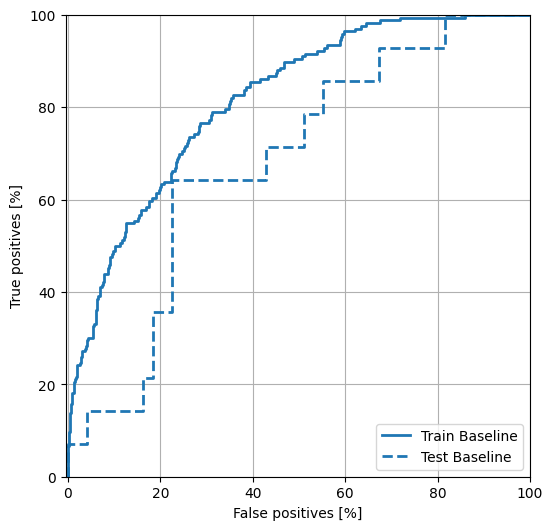

Best threshold: 0.5428255796432495
Number of true positives for the given ticker: 8
Number of false positives for the given ticker: 11
Precision score: 0.42105263157894735
Recall score: 0.5714285714285714
Random guess score: 0.2222222222222222
true-positive per ticker: Orig_Ticker
MSFT    8
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
MSFT    11
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
MSFT    6
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
MSFT    0.421053
dtype: float64
recall per ticker: Orig_Ticker
MSFT    0.571429
dtype: float64
rand guess per ticker: Orig_Ticker
MSFT    0.222222
dtype: float64
Some true positives
                           Date Orig_Ticker  y-predict-original  \
995   2024-10-28 00:00:00-04:00        MSFT            0.947449   
1021  2024-12-04 00:00:00-05:00        MSFT            0.617422   
990   2024-10-21 00:00:00-04:00        MSFT            0.993443   
1034  2024-12-23 00:0

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 1 0 0 0 1 0 0 0 0 0 0 1 1 0 0 0 1 1 1 0 0 0 0 0 0 0 0 1 0 1 0 1 0 0 0 1
 1 0 0 1 1 0 0 1 0 0 0 0 0 0 1 1 0 0 0 0 1 1 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 1 0 0 0 1 0 0 0 0 1 0 0 1
 0 1 0 0 1 0 1 1 0 0 0 1 0 0 1 0 0 0 0 0 1 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = v

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['MSFT'] UNDERLYING_TARGET: Next-Day-Close-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:33 mode: medium LR_RATE: 0.0005 STARTING_LR: 0.0001
fetch_finance_data_for_tickers: just returning file name: MSFT for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode medium is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode medium is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, b

{'MSFT': 0}
{'Tech': 0}
size before sigma app: 1025 for ticker: MSFT mean: -0.0004805842976568784, sigma: 0.01063043295339908 upper_bound: 0.03141071456254037 lower_bound: -0.03237188315785412
size after sigma app: 1002 for ticker: MSFT
0      0.0
1      1.0
2      0.0
3      0.0
4      1.0
      ... 
956    0.0
957    0.0
958    0.0
959    0.0
960    0.0
Name: y-value, Length: 938, dtype: float64
0      0.0
1      1.0
2      0.0
3      0.0
4      1.0
      ... 
956    0.0
957    0.0
958    0.0
959    0.0
960    0.0
Name: y-value-original, Length: 938, dtype: float64
High-Low-Ratio                               0.600427
High-Open-Ratio                              0.536376
Close-Open-Ratio                             0.473355
Close-Prev-Close                             0.510037
MACD-Prev-MACD                               0.263661
200D-Ratio                                   0.430369
MACD_SIG                                     0.962874
MFI3                                         0.3

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 33, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_124 (Conv1D) │ (None, 31, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_190 (PReLU) │ (None, 31, 256)   │        256 │ conv1d_124[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_125 (Conv1D) │ (None, 15, 256)   │    196,864 │ p_re_lu_190[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_191 (PReLU) │ (None, 15, 256)   │        256 │ conv1d_125[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_126 (Conv1D) │ (None, 7, 512)    │    393,728 │ p_re_lu_191[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_192 (PReLU) │ (None, 7, 512)    │        512 │ conv1d_126[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_127 (Conv1D) │ (None, 3, 512)    │    786,944 │ p_re_lu_192[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_193 (PReLU) │ (None, 3, 512)    │        512 │ conv1d_127[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_128 (Conv1D) │ (None, 1, 1024)   │  1,573,888 │ p_re_lu_193[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_194 (PReLU) │ (None, 1, 1024)   │      1,024 │ conv1d_128[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_50          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_50          │ (None, 1024)      │          0 │ p_re_lu_194[0][0] │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_50[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_51          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_50      │ (None, 1536)      │          0 │ flatten_50[0][0], │
│ (Concatenate)       │                   │            │ stock_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 7,696,364 (29.36 MB)

 Trainable params: 7,696,364 (29.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - AUC: 0.4289 - Precision: 0.1713 - Recall: 0.9600 - all_positives: 22.0831 - f1_score_metric: 37.3264 - loss: 2.1829 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2770.5566 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2770.5566 - val_AUC: 0.5051 - val_Precision: 0.2222 - val_Recall: 1.0000 - val_all_positives: 14.0000 - val_f1_score_metric: 22.9091 - val_loss: 2.2718 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 882.0001 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 882.0000 - learning_rate: 1.0000e-04
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 7s 779ms/step - AUC: 0.5746 - Precision: 0.1585 - Recall: 1.0000 - all_positives: 19.6389 - f1_score_metric: 33.6341 - loss: 2.0854 - precision_with_threshold_fixed: 10.2151 - recall_mul_prediction: 2462.7676 - recall_with_threshold_fixed: 0.6045 - true_positives: 2462.7676 - val_AUC: 0.4074 - val_Precision: 0.

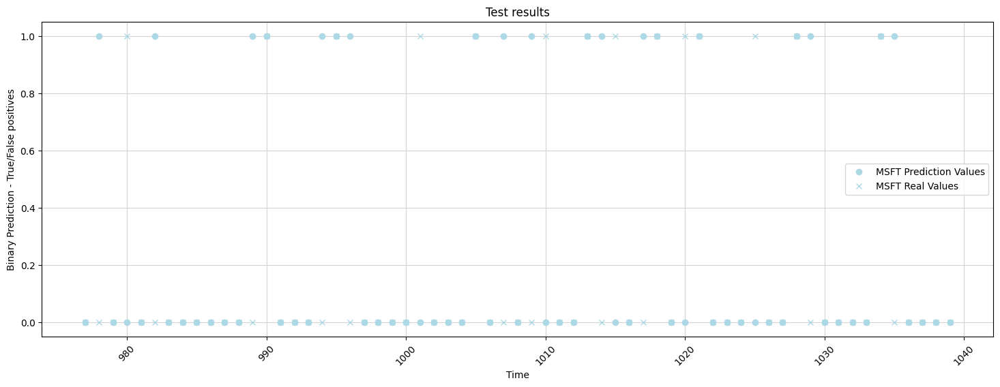

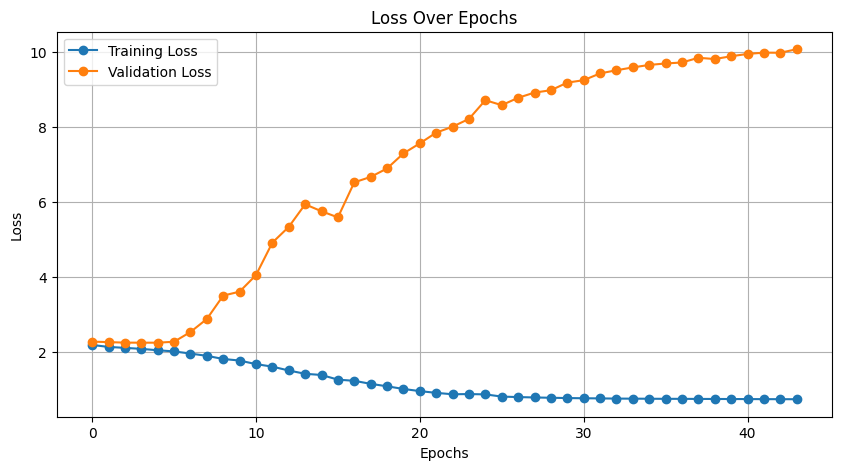

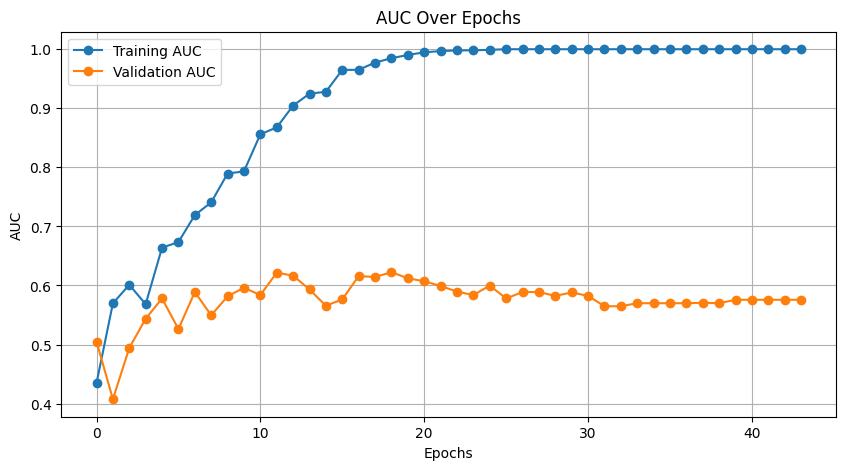



print_and_save_for
ticker data: MSFT


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
956        High-Low-Ratio  High-Open-Ratio  Close-O...   
957        High-Low-Ratio  High-Open-Ratio  Close-O...   
958        High-Low-Ratio  High-Open-Ratio  Close-O...   
959        High-Low-Ratio  High-Open-Ratio  Close-O...   
960        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2020-12-04 00:00:00-05:00       0       0        -0.000481   
1    2020-12-07 00:00:00-05:00       0       0        -0.000481   
2    2020-12-08 00:00:00-05:00       0     

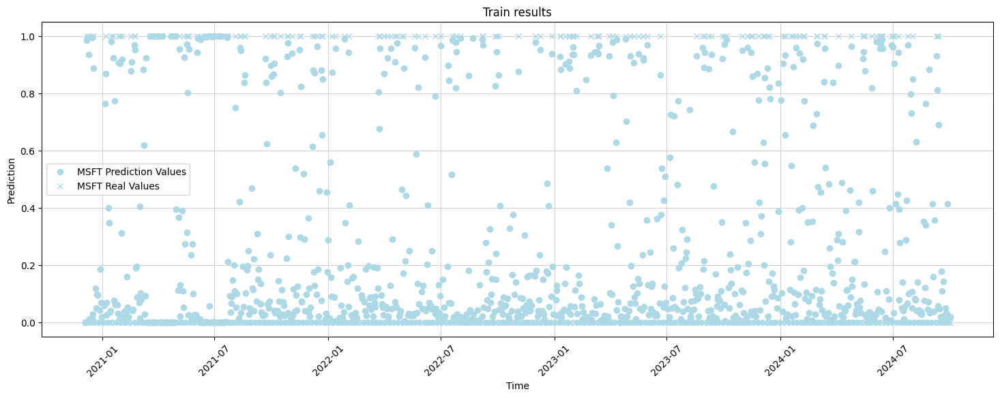

DONE PLOTTING 




print_and_save_for
ticker data: MSFT


Here is the data:                                                LstmData  \
961         High-Low-Ratio  High-Open-Ratio  Close-O...   
962         High-Low-Ratio  High-Open-Ratio  Close-O...   
963         High-Low-Ratio  High-Open-Ratio  Close-O...   
964         High-Low-Ratio  High-Open-Ratio  Close-O...   
965         High-Low-Ratio  High-Open-Ratio  Close-O...   
...                                                 ...   
1019        High-Low-Ratio  High-Open-Ratio  Close-O...   
1020        High-Low-Ratio  High-Open-Ratio  Close-O...   
1021        High-Low-Ratio  High-Open-Ratio  Close-O...   
1022        High-Low-Ratio  High-Open-Ratio  Close-O...   
1023        High-Low-Ratio  High-Open-Ratio  Close-O...   

                           Date  Ticker  Sector  Target-20D-Mean  \
961   2024-10-02 00:00:00-04:00       0       0        -0.000481   
962   2024-10-03 00:00:00-04:00       0       0        -0.000481   
963   2024-

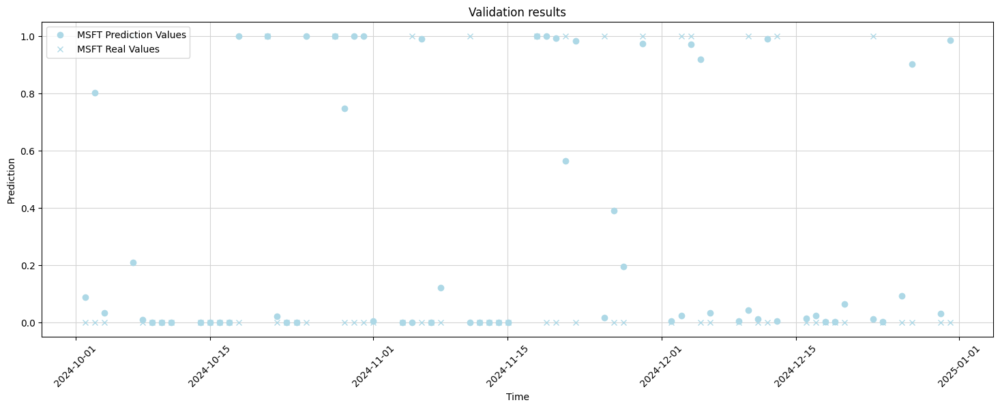

DONE PLOTTING 




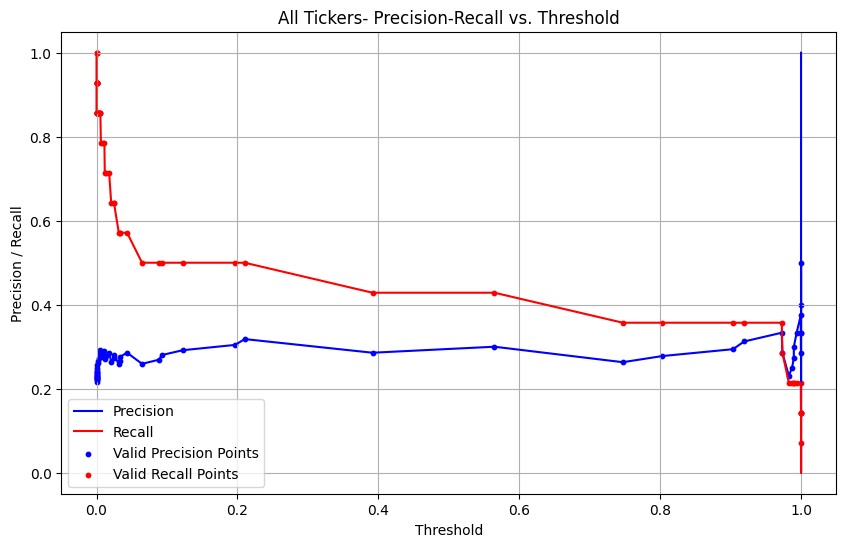

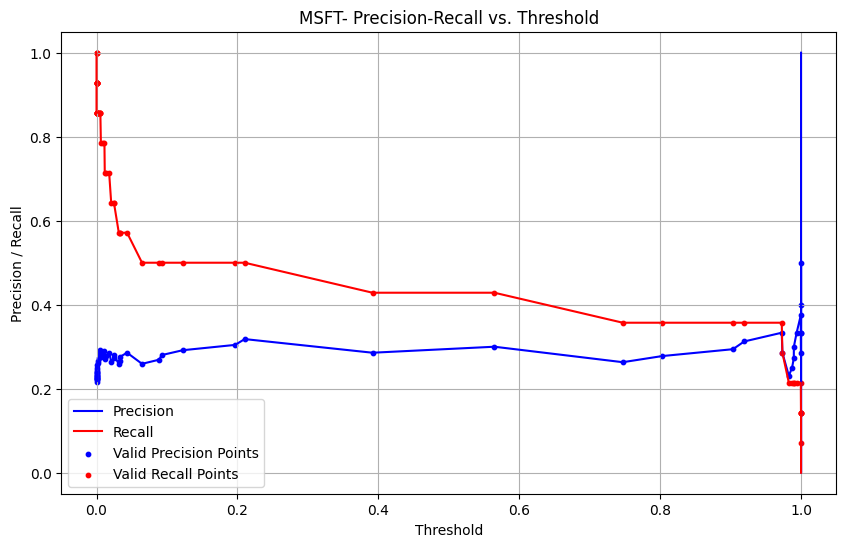

[0.         0.         0.         0.00129366 0.00129366 0.00258732
 0.00258732 0.00388098 0.00388098 0.00517464 0.00517464 0.00646831
 0.00646831 0.00776197 0.00776197 0.00905563 0.00905563 0.01293661
 0.01293661 0.01423027 0.01423027 0.01552393 0.01552393 0.01681759
 0.01681759 0.01940492 0.01940492 0.02069858 0.02069858 0.0232859
 0.0232859  0.02457956 0.02457956 0.02716688 0.02716688 0.02846054
 0.02846054 0.03104787 0.03104787 0.03492885 0.03492885 0.03751617
 0.03751617 0.04139715 0.04139715 0.04527814 0.04527814 0.04786546
 0.04786546 0.05174644 0.05174644 0.05821475 0.05821475 0.076326
 0.076326   1.        ]
[0.         0.04848485 0.10909091 0.10909091 0.13333333 0.13333333
 0.44242424 0.44242424 0.61212121 0.61212121 0.66060606 0.66060606
 0.70909091 0.70909091 0.72727273 0.72727273 0.76363636 0.76363636
 0.81212121 0.81212121 0.83636364 0.83636364 0.84242424 0.84242424
 0.86060606 0.86060606 0.86666667 0.86666667 0.87272727 0.87272727
 0.8969697  0.8969697  0.93333333 0.93333

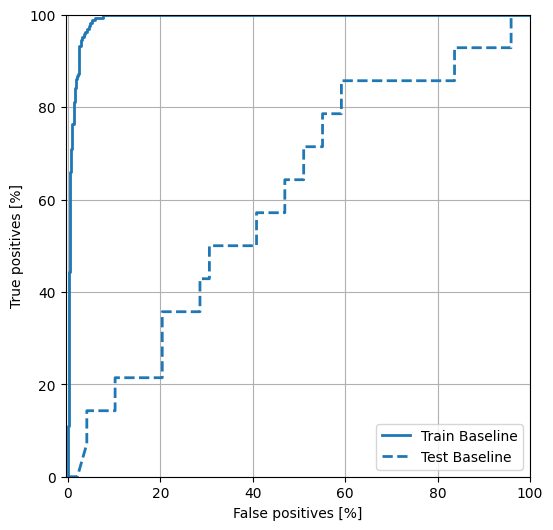

Best threshold: 0.21034684777259827
Number of true positives for the given ticker: 6
Number of false positives for the given ticker: 15
Precision score: 0.2857142857142857
Recall score: 0.42857142857142855
Random guess score: 0.2222222222222222
true-positive per ticker: Orig_Ticker
MSFT    6
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
MSFT    15
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
MSFT    8
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
MSFT    0.285714
dtype: float64
recall per ticker: Orig_Ticker
MSFT    0.428571
dtype: float64
rand guess per ticker: Orig_Ticker
MSFT    0.222222
dtype: float64
Some true positives
                           Date Orig_Ticker  y-predict-original  \
974   2024-10-21 00:00:00-04:00        MSFT            1.000000   
979   2024-10-28 00:00:00-04:00        MSFT            0.999998   
1005  2024-12-04 00:00:00-05:00        MSFT            0.972604   
994   2024-11-18 00:

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 1 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 1 1 1 1 1 0 0 0 1 0 0 0 0 0 0 0 1 1 1 1
 1 0 1 0 1 0 0 1 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 1]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 1 0 0 0 1 0 0 0 0 1 0 0 1
 0 1 0 0 1 0 1 1 0 0 0 1 0 0 1 0 0 0 0 0 1 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = v

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['MSFT'] UNDERLYING_TARGET: Next-Day-Close-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:65 mode: complex LR_RATE: 0.0001 STARTING_LR: 0.001
fetch_finance_data_for_tickers: just returning file name: MSFT for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode complex is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode complex is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names,

{'MSFT': 0}
{'Tech': 0}
size before sigma app: 993 for ticker: MSFT mean: -0.0004805842976568784, sigma: 0.010630432953399077 upper_bound: 0.031410714562540354 lower_bound: -0.03237188315785411
size after sigma app: 970 for ticker: MSFT
0      0.0
1      0.0
2      0.0
3      1.0
4      0.0
      ... 
924    0.0
925    0.0
926    0.0
927    0.0
928    0.0
Name: y-value, Length: 906, dtype: float64
0      0.0
1      0.0
2      0.0
3      1.0
4      0.0
      ... 
924    0.0
925    0.0
926    0.0
927    0.0
928    0.0
Name: y-value-original, Length: 906, dtype: float64
High-Low-Ratio                               0.600427
High-Open-Ratio                              0.536376
Close-Open-Ratio                             0.473355
Close-Prev-Close                             0.510037
MACD-Prev-MACD                               0.263661
200D-Ratio                                   0.430369
MACD_SIG                                     0.962874
MFI3                                         0.3

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 65, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_129 (Conv1D) │ (None, 63, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_198 (PReLU) │ (None, 63, 256)   │        256 │ conv1d_129[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_130 (Conv1D) │ (None, 31, 256)   │    196,864 │ p_re_lu_198[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_199 (PReLU) │ (None, 31, 256)   │        256 │ conv1d_130[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_131 (Conv1D) │ (None, 15, 512)   │    393,728 │ p_re_lu_199[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_200 (PReLU) │ (None, 15, 512)   │        512 │ conv1d_131[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_132 (Conv1D) │ (None, 7, 512)    │    786,944 │ p_re_lu_200[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_201 (PReLU) │ (None, 7, 512)    │        512 │ conv1d_132[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_133 (Conv1D) │ (None, 3, 1024)   │  1,573,888 │ p_re_lu_201[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_202 (PReLU) │ (None, 3, 1024)   │      1,024 │ conv1d_133[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_134 (Conv1D) │ (None, 1, 1024)   │  3,146,752 │ p_re_lu_202[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_203 (PReLU) │ (None, 1, 1024)   │      1,024 │ conv1d_134[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_52          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_52          │ (None, 1024)      │          0 │ p_re_lu_203[0][0] │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_52[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_53          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                 

 Total params: 10,844,140 (41.37 MB)

 Trainable params: 10,844,140 (41.37 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - AUC: 0.4654 - Precision: 0.1705 - Recall: 0.6111 - all_positives: 22.2235 - f1_score_metric: 26.2054 - loss: 1.6616 - precision_with_threshold_fixed: 3.4810 - recall_mul_prediction: 1676.6353 - recall_with_threshold_fixed: 26.2095 - true_positives: 1676.6353 - val_AUC: 0.5845 - val_Precision: 0.2222 - val_Recall: 1.0000 - val_all_positives: 14.0000 - val_f1_score_metric: 22.9091 - val_loss: 1.6459 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 882.0001 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 882.0000 - learning_rate: 0.0010
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 7s 841ms/step - AUC: 0.4584 - Precision: 0.1611 - Recall: 0.9294 - all_positives: 20.5929 - f1_score_metric: 34.8171 - loss: 1.4954 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2480.5955 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2480.5955 - val_AUC: 0.6224 - val_Precision: 0.2222

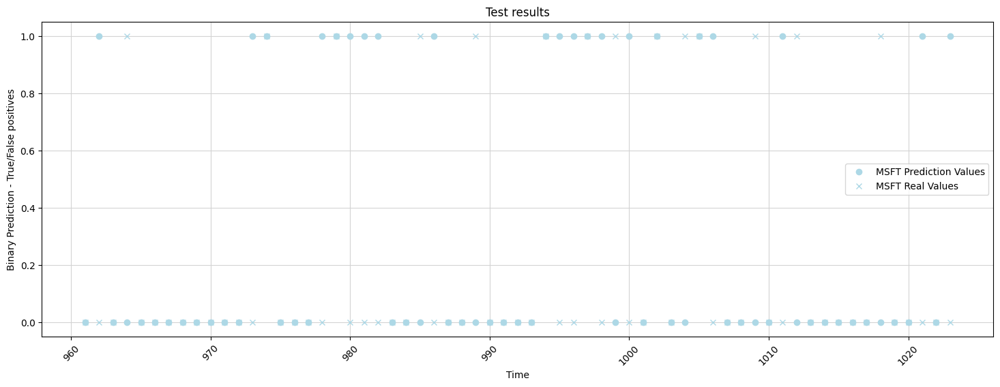

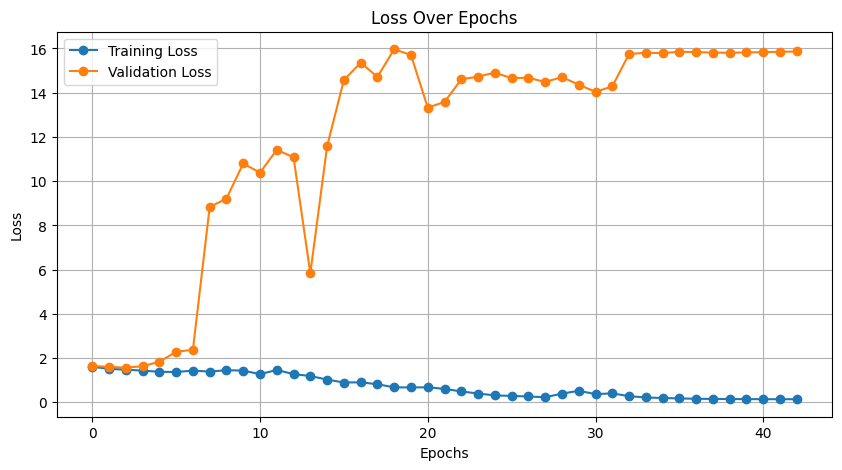

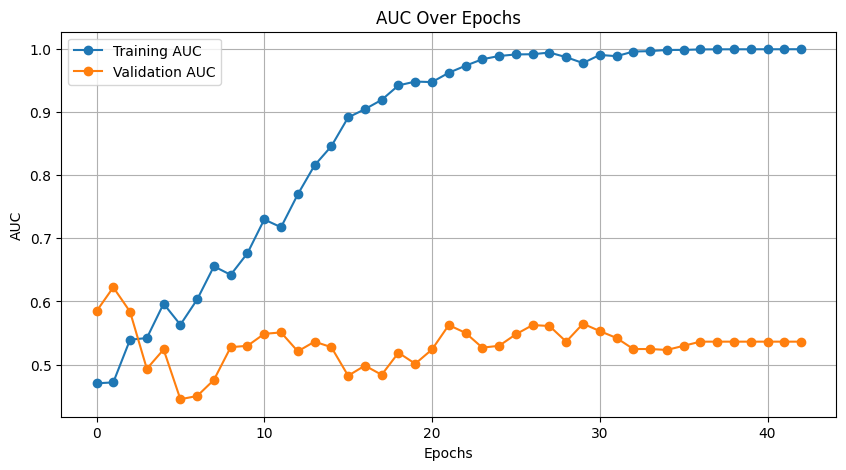



print_and_save_for
ticker data: MSFT


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
924        High-Low-Ratio  High-Open-Ratio  Close-O...   
925        High-Low-Ratio  High-Open-Ratio  Close-O...   
926        High-Low-Ratio  High-Open-Ratio  Close-O...   
927        High-Low-Ratio  High-Open-Ratio  Close-O...   
928        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2021-01-22 00:00:00-05:00       0       0        -0.000481   
1    2021-01-25 00:00:00-05:00       0       0        -0.000481   
2    2021-01-26 00:00:00-05:00       0     

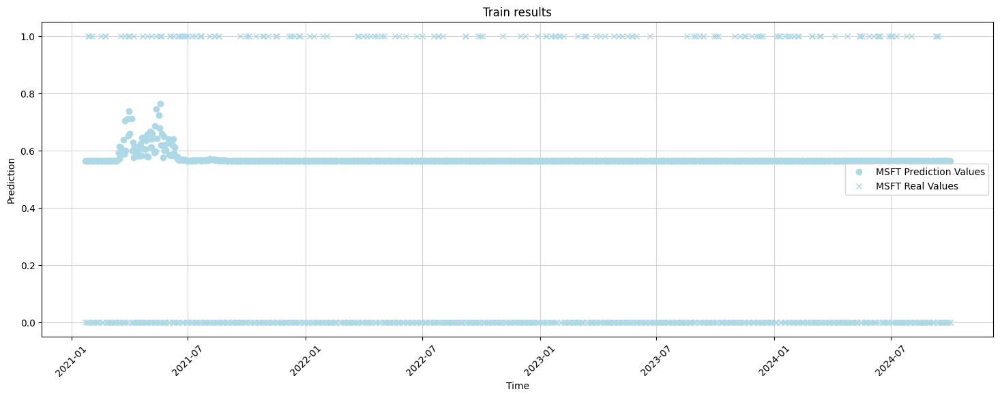

DONE PLOTTING 




print_and_save_for
ticker data: MSFT


Here is the data:                                               LstmData  \
929        High-Low-Ratio  High-Open-Ratio  Close-O...   
930        High-Low-Ratio  High-Open-Ratio  Close-O...   
931        High-Low-Ratio  High-Open-Ratio  Close-O...   
932        High-Low-Ratio  High-Open-Ratio  Close-O...   
933        High-Low-Ratio  High-Open-Ratio  Close-O...   
..                                                 ...   
987        High-Low-Ratio  High-Open-Ratio  Close-O...   
988        High-Low-Ratio  High-Open-Ratio  Close-O...   
989        High-Low-Ratio  High-Open-Ratio  Close-O...   
990        High-Low-Ratio  High-Open-Ratio  Close-O...   
991        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
929  2024-10-02 00:00:00-04:00       0       0        -0.000481   
930  2024-10-03 00:00:00-04:00       0       0        -0.000481   
931  2024-10-04 00:00:00-0

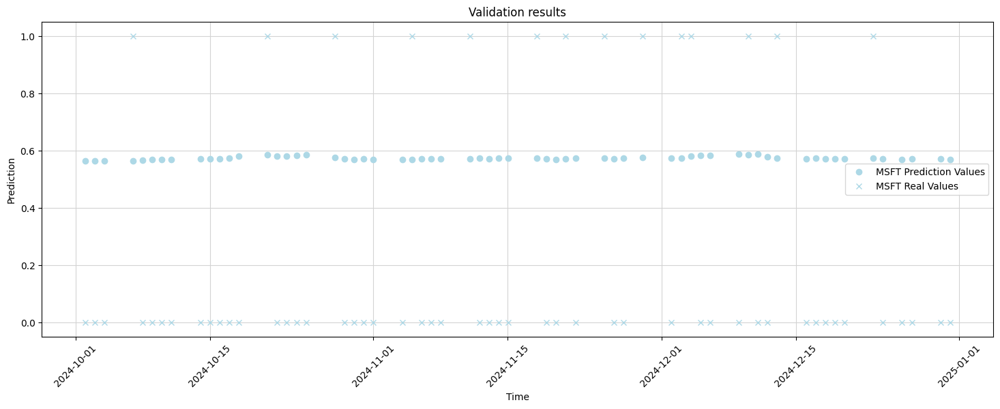

DONE PLOTTING 




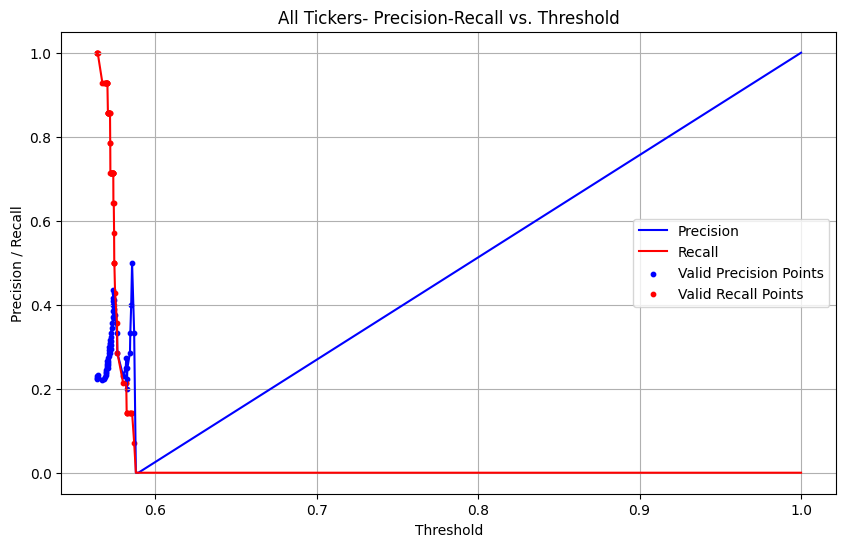

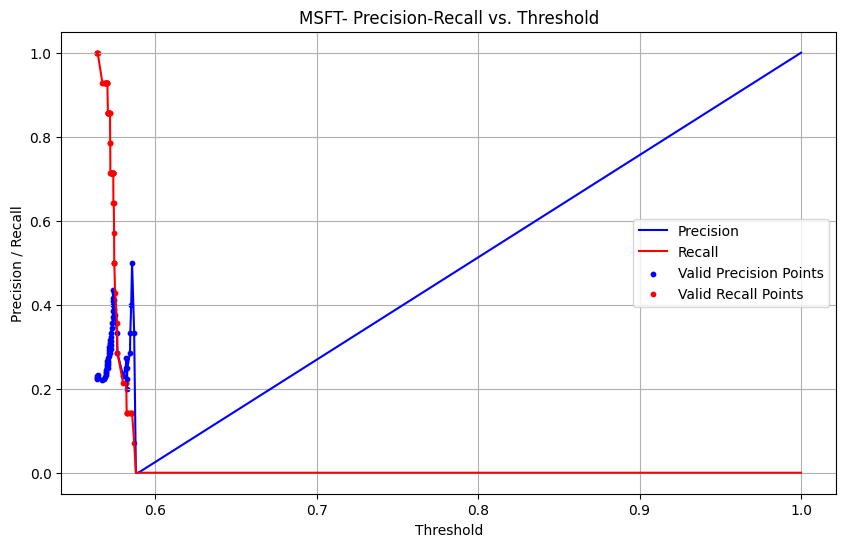

[0.         0.         0.         0.0040107  0.0040107  0.00534759
 0.00534759 0.00802139 0.00802139 0.01336898 0.01336898 0.01871658
 0.01871658 0.02807487 0.02807487 0.03342246 0.03342246 0.05614973
 0.05614973 0.06417112 0.06417112 0.06550802 0.06550802 0.06951872
 0.06951872 0.07219251 0.07219251 0.07352941 0.07352941 0.07754011
 0.07754011 0.08823529 0.08823529 0.09625668 0.09625668 0.10026738
 0.10026738 0.10294118 0.10294118 0.10561497 0.10561497 0.10695187
 0.10695187 0.11363636 0.11363636 0.12566845 0.12566845 0.12834225
 0.12834225 0.12967914 0.12967914 0.14304813 0.14304813 0.15775401
 0.15775401 0.15909091 0.15909091 0.1684492  0.1684492  0.17112299
 0.17112299 0.18983957 0.18983957 0.20588235 0.20588235 0.22192513
 0.22192513 0.22727273 0.22727273 0.22994652 0.22994652 0.23796791
 0.23796791 0.23930481 0.23930481 0.24064171 0.24064171 0.2486631
 0.2486631  0.25534759 0.25534759 0.25668449 0.25668449 0.26203209
 0.26203209 0.26336898 0.26336898 0.26470588 0.26470588 0.27139

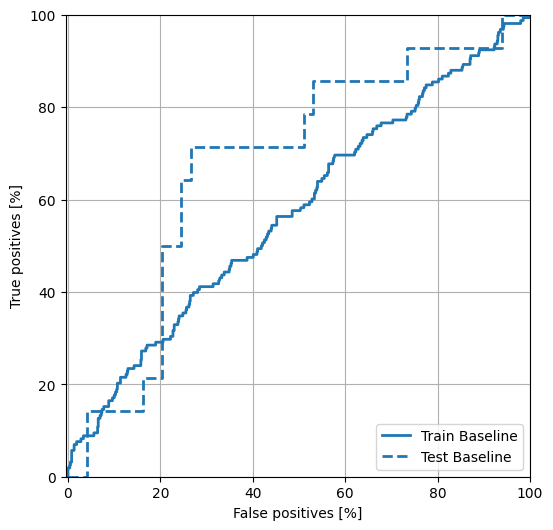

Best threshold: 0.5740151405334473
Number of true positives for the given ticker: 9
Number of false positives for the given ticker: 13
Precision score: 0.4090909090909091
Recall score: 0.6428571428571429
Random guess score: 0.2222222222222222
true-positive per ticker: Orig_Ticker
MSFT    9
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
MSFT    13
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
MSFT    5
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
MSFT    0.409091
dtype: float64
recall per ticker: Orig_Ticker
MSFT    0.642857
dtype: float64
rand guess per ticker: Orig_Ticker
MSFT    0.222222
dtype: float64
Some true positives
                          Date Orig_Ticker  y-predict-original  \
980  2024-12-13 00:00:00-05:00        MSFT            0.574678   
947  2024-10-28 00:00:00-04:00        MSFT            0.576532   
973  2024-12-04 00:00:00-05:00        MSFT            0.582044   
942  2024-10-21 00:00:00-0

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0
 1 0 0 0 1 0 1 1 1 1 1 1 1 1 1 0 0 0 0 0 1 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 1 0 0 0 1 0 0 0 0 1 0 0 1
 0 1 0 0 1 0 1 1 0 0 0 1 0 0 1 0 0 0 0 0 1 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = v

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['MSFT'] UNDERLYING_TARGET: Next-Day-High-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:17 mode: simple LR_RATE: 0.001 STARTING_LR: 1e-05
fetch_finance_data_for_tickers: just returning file name: MSFT for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode simple is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode simple is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, b

{'MSFT': 0}
{'Tech': 0}
size before sigma app: 1041 for ticker: MSFT mean: 0.007663059582669172, sigma: 0.0063979407067922085 upper_bound: 0.026856881703045798 lower_bound: -0.011530762537707451
size after sigma app: 999 for ticker: MSFT
0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
972    0.0
973    0.0
974    0.0
975    0.0
976    0.0
Name: y-value, Length: 937, dtype: float64
0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
972    0.0
973    0.0
974    0.0
975    0.0
976    0.0
Name: y-value-original, Length: 937, dtype: float64
High-Low-Ratio                               0.600427
High-Open-Ratio                              0.536376
Close-Open-Ratio                             0.473355
Close-Prev-Close                             0.510037
MACD-Prev-MACD                               0.263661
200D-Ratio                                   0.430369
MACD_SIG                                     0.962874
MFI3                                         0.

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 17, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_135 (Conv1D) │ (None, 15, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_207 (PReLU) │ (None, 15, 256)   │        256 │ conv1d_135[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_136 (Conv1D) │ (None, 7, 256)    │    196,864 │ p_re_lu_207[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_208 (PReLU) │ (None, 7, 256)    │        256 │ conv1d_136[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_137 (Conv1D) │ (None, 3, 512)    │    393,728 │ p_re_lu_208[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_209 (PReLU) │ (None, 3, 512)    │        512 │ conv1d_137[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_138 (Conv1D) │ (None, 1, 512)    │    786,944 │ p_re_lu_209[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_210 (PReLU) │ (None, 1, 512)    │        512 │ conv1d_138[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_54          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_54          │ (None, 512)       │          0 │ p_re_lu_210[0][0] │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_54[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_55          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_54      │ (None, 1024)      │          0 │ flatten_54[0][0], │
│ (Concatenate)       │                   │            │ stock_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_dense        │ (None, 256)       │     33,024 │ reshape_55[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_55      │ (None, 1280)      │          0 │ concatenate_54[0

 Total params: 2,247,451 (8.57 MB)

 Trainable params: 2,247,451 (8.57 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - AUC: 0.5441 - Precision: 0.1989 - Recall: 0.1557 - all_positives: 22.5857 - f1_score_metric: 18.1759 - loss: 2.4025 - precision_with_threshold_fixed: 8.8442 - recall_mul_prediction: 382.0500 - recall_with_threshold_fixed: 0.5376 - true_positives: 382.0500 - val_AUC: 0.3265 - val_Precision: 0.1818 - val_Recall: 0.5000 - val_all_positives: 12.0000 - val_f1_score_metric: 17.6000 - val_loss: 2.4773 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 396.0000 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 396.0000 - learning_rate: 1.0000e-05
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 555ms/step - AUC: 0.5472 - Precision: 0.1980 - Recall: 0.6569 - all_positives: 24.0857 - f1_score_metric: 36.5989 - loss: 2.4367 - precision_with_threshold_fixed: 6.4317 - recall_mul_prediction: 1941.2174 - recall_with_threshold_fixed: 0.3357 - true_positives: 1941.2174 - val_AUC: 0.3571 - val_Precision: 0.1754 - val_

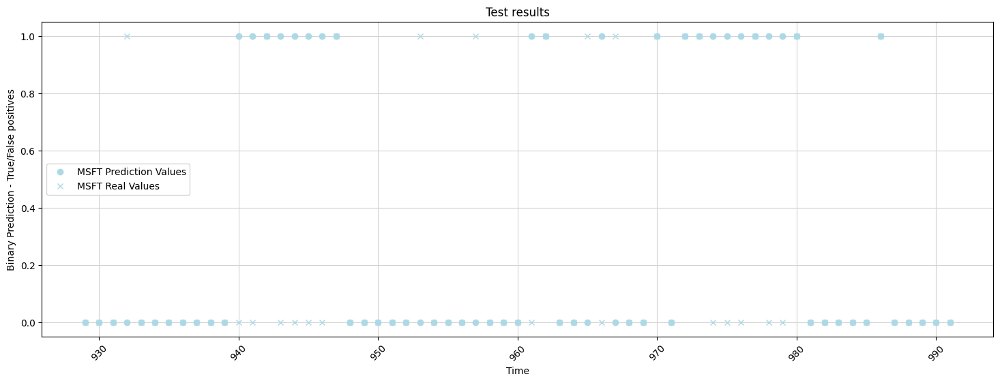

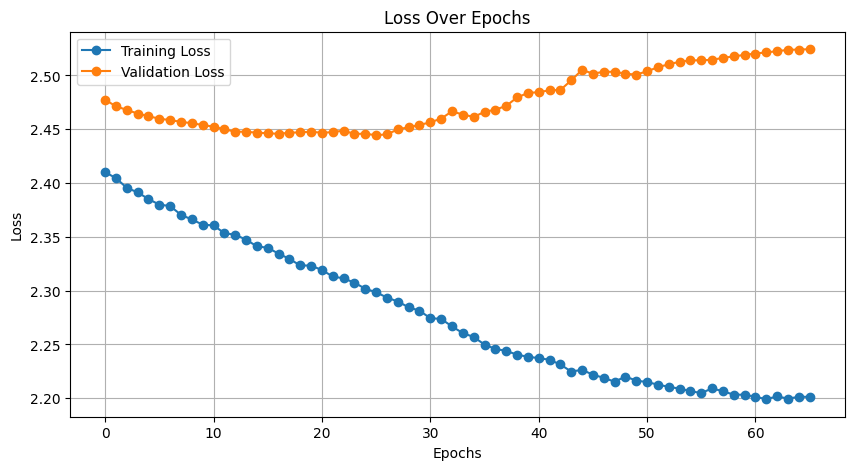

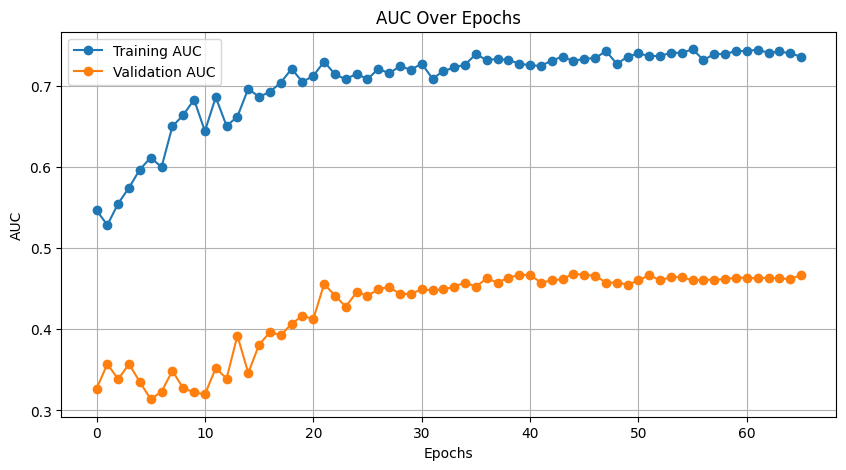



print_and_save_for
ticker data: MSFT


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
972        High-Low-Ratio  High-Open-Ratio  Close-O...   
973        High-Low-Ratio  High-Open-Ratio  Close-O...   
974        High-Low-Ratio  High-Open-Ratio  Close-O...   
975        High-Low-Ratio  High-Open-Ratio  Close-O...   
976        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2020-11-11 00:00:00-05:00       0       0         0.007663   
1    2020-11-12 00:00:00-05:00       0       0         0.007663   
2    2020-11-13 00:00:00-05:00       0     

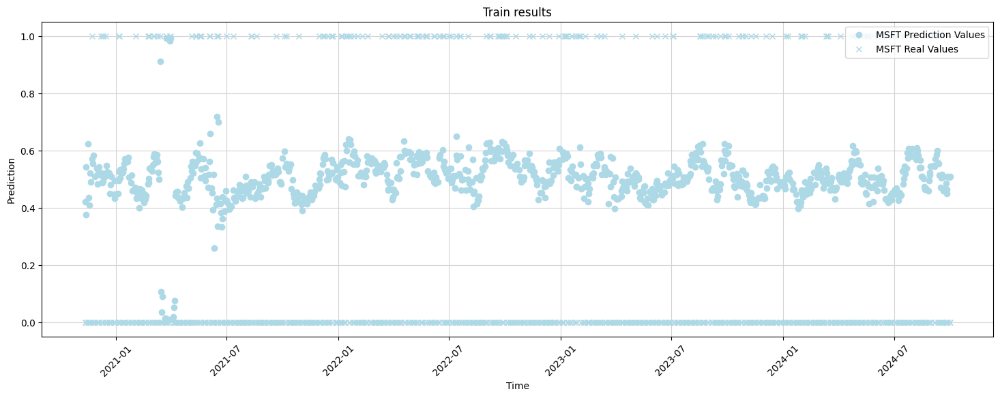

DONE PLOTTING 




print_and_save_for
ticker data: MSFT


Here is the data:                                                LstmData  \
977         High-Low-Ratio  High-Open-Ratio  Close-O...   
978         High-Low-Ratio  High-Open-Ratio  Close-O...   
979         High-Low-Ratio  High-Open-Ratio  Close-O...   
980         High-Low-Ratio  High-Open-Ratio  Close-O...   
981         High-Low-Ratio  High-Open-Ratio  Close-O...   
...                                                 ...   
1035        High-Low-Ratio  High-Open-Ratio  Close-O...   
1036        High-Low-Ratio  High-Open-Ratio  Close-O...   
1037        High-Low-Ratio  High-Open-Ratio  Close-O...   
1038        High-Low-Ratio  High-Open-Ratio  Close-O...   
1039        High-Low-Ratio  High-Open-Ratio  Close-O...   

                           Date  Ticker  Sector  Target-20D-Mean  \
977   2024-10-02 00:00:00-04:00       0       0         0.007663   
978   2024-10-03 00:00:00-04:00       0       0         0.007663   
979   2024-

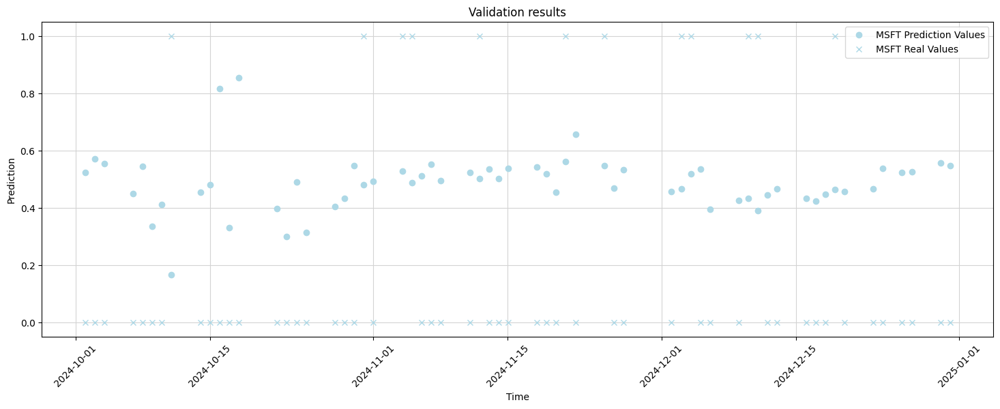

DONE PLOTTING 




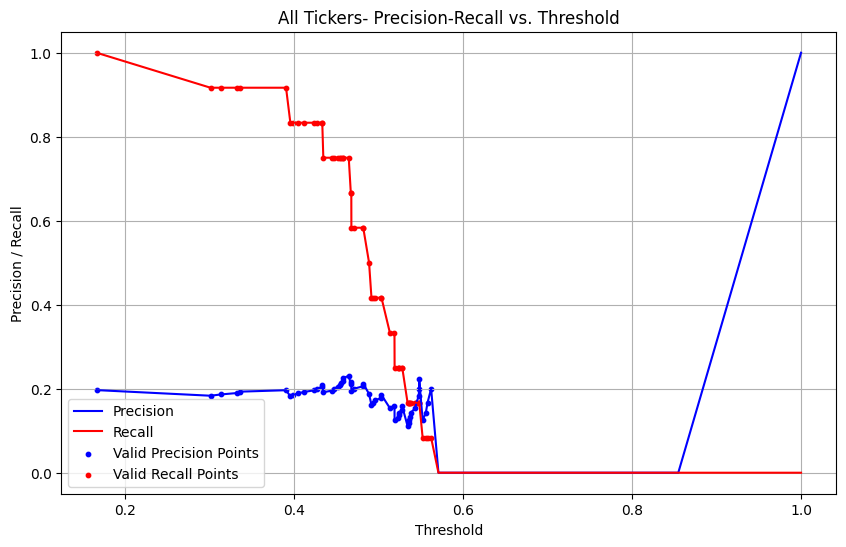

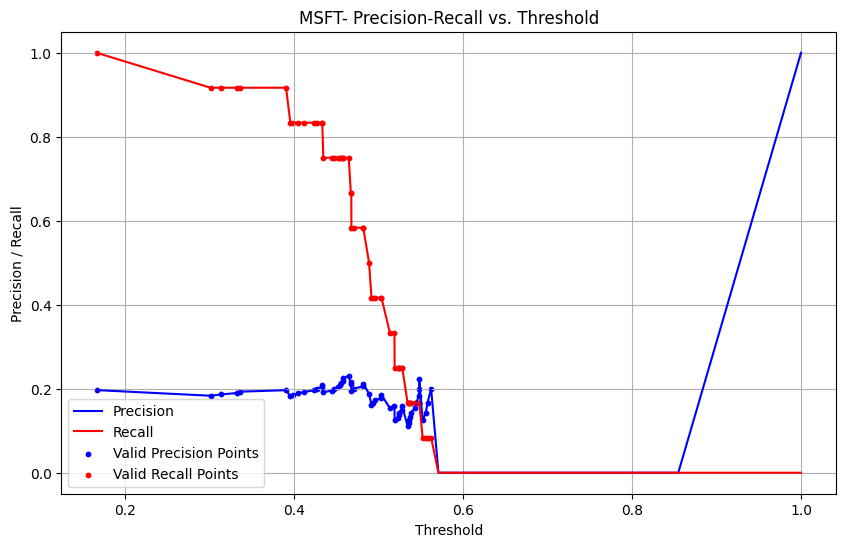

[0.         0.         0.         0.00130548 0.00130548 0.00522193
 0.00522193 0.00652742 0.00652742 0.0078329  0.0078329  0.01044386
 0.01044386 0.01305483 0.01305483 0.01436031 0.01436031 0.0156658
 0.0156658  0.02088773 0.02088773 0.02349869 0.02349869 0.02872063
 0.02872063 0.03002611 0.03002611 0.03133159 0.03133159 0.03524804
 0.03524804 0.03785901 0.03785901 0.04046997 0.04046997 0.04177546
 0.04177546 0.04308094 0.04308094 0.04960836 0.04960836 0.05221932
 0.05221932 0.0535248  0.0535248  0.05874674 0.05874674 0.06396867
 0.06396867 0.06527415 0.06527415 0.07180157 0.07180157 0.0770235
 0.0770235  0.07963446 0.07963446 0.08093995 0.08093995 0.09138381
 0.09138381 0.09399478 0.09399478 0.10182768 0.10182768 0.12010444
 0.12010444 0.13446475 0.13446475 0.13577023 0.13577023 0.13707572
 0.13707572 0.1383812  0.1383812  0.14751958 0.14751958 0.15143603
 0.15143603 0.15274151 0.15274151 0.16318538 0.16318538 0.16710183
 0.16710183 0.18668407 0.18668407 0.19190601 0.19190601 0.195822

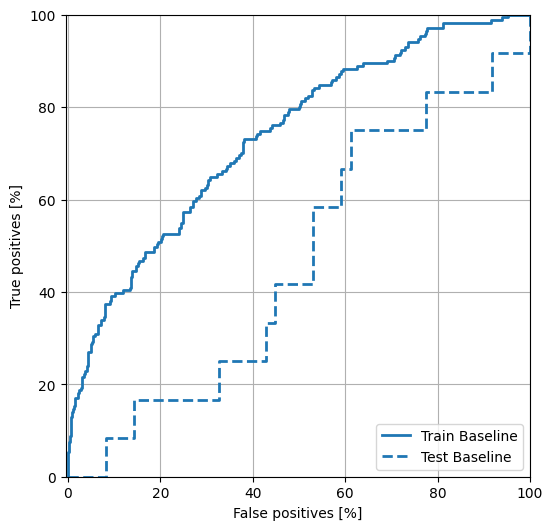

Best threshold: 0.46460095047950745
Number of true positives for the given ticker: 8
Number of false positives for the given ticker: 30
Precision score: 0.21052631578947367
Recall score: 0.6666666666666666
Random guess score: 0.19672131147540983
true-positive per ticker: Orig_Ticker
MSFT    8
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
MSFT    30
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
MSFT    4
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
MSFT    0.210526
dtype: float64
recall per ticker: Orig_Ticker
MSFT    0.666667
dtype: float64
rand guess per ticker: Orig_Ticker
MSFT    0.196721
dtype: float64
Some true positives
                           Date Orig_Ticker  y-predict-original  \
1000  2024-11-04 00:00:00-05:00        MSFT            0.527960   
1015  2024-11-25 00:00:00-05:00        MSFT            0.548080   
998   2024-10-31 00:00:00-04:00        MSFT            0.481784   
1021  2024-12-04 00

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[1 1 1 0 1 0 0 0 0 1 1 0 1 0 0 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1
 1 1 1 0 1 1 1 0 0 0 0 0 1 0 0 0 0 0 1 1 1 1 1 1]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 0 0 0 0 1 0 0 0 0 0 0 1 0
 1 0 0 0 1 1 0 0 0 1 1 0 0 0 0 0 1 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = validatio

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['MSFT'] UNDERLYING_TARGET: Next-Day-High-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:33 mode: medium LR_RATE: 0.0005 STARTING_LR: 0.0001
fetch_finance_data_for_tickers: just returning file name: MSFT for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode medium is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode medium is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, b

{'MSFT': 0}
{'Tech': 0}
size before sigma app: 1025 for ticker: MSFT mean: 0.007663059582669172, sigma: 0.006397940706792209 upper_bound: 0.0268568817030458 lower_bound: -0.011530762537707455
size after sigma app: 983 for ticker: MSFT
0      0.0
1      1.0
2      0.0
3      0.0
4      1.0
      ... 
956    0.0
957    0.0
958    0.0
959    0.0
960    0.0
Name: y-value, Length: 921, dtype: float64
0      0.0
1      1.0
2      0.0
3      0.0
4      1.0
      ... 
956    0.0
957    0.0
958    0.0
959    0.0
960    0.0
Name: y-value-original, Length: 921, dtype: float64
High-Low-Ratio                               0.600427
High-Open-Ratio                              0.536376
Close-Open-Ratio                             0.473355
Close-Prev-Close                             0.510037
MACD-Prev-MACD                               0.263661
200D-Ratio                                   0.430369
MACD_SIG                                     0.962874
MFI3                                         0.345

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 33, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_139 (Conv1D) │ (None, 31, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_213 (PReLU) │ (None, 31, 256)   │        256 │ conv1d_139[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_140 (Conv1D) │ (None, 15, 256)   │    196,864 │ p_re_lu_213[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_214 (PReLU) │ (None, 15, 256)   │        256 │ conv1d_140[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_141 (Conv1D) │ (None, 7, 512)    │    393,728 │ p_re_lu_214[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_215 (PReLU) │ (None, 7, 512)    │        512 │ conv1d_141[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_142 (Conv1D) │ (None, 3, 512)    │    786,944 │ p_re_lu_215[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_216 (PReLU) │ (None, 3, 512)    │        512 │ conv1d_142[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_143 (Conv1D) │ (None, 1, 1024)   │  1,573,888 │ p_re_lu_216[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_217 (PReLU) │ (None, 1, 1024)   │      1,024 │ conv1d_143[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_56          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_56          │ (None, 1024)      │          0 │ p_re_lu_217[0][0] │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_56[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_57          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_56      │ (None, 1536)      │          0 │ flatten_56[0][0], │
│ (Concatenate)       │                   │            │ stock_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 7,696,364 (29.36 MB)

 Trainable params: 7,696,364 (29.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - AUC: 0.4668 - Precision: 0.1865 - Recall: 0.6859 - all_positives: 24.6646 - f1_score_metric: 32.4277 - loss: 2.2107 - precision_with_threshold_fixed: 5.3728 - recall_mul_prediction: 2103.0889 - recall_with_threshold_fixed: 0.2336 - true_positives: 2103.0889 - val_AUC: 0.4753 - val_Precision: 0.1778 - val_Recall: 0.6667 - val_all_positives: 12.0000 - val_f1_score_metric: 18.9474 - val_loss: 2.2185 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 540.0000 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 540.0000 - learning_rate: 1.0000e-04
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 7s 907ms/step - AUC: 0.5756 - Precision: 0.1906 - Recall: 0.9775 - all_positives: 23.1516 - f1_score_metric: 38.6340 - loss: 2.1261 - precision_with_threshold_fixed: 0.1111 - recall_mul_prediction: 2798.0491 - recall_with_threshold_fixed: 0.0278 - true_positives: 2798.0486 - val_AUC: 0.4660 - val_Precision: 0.1892 - va

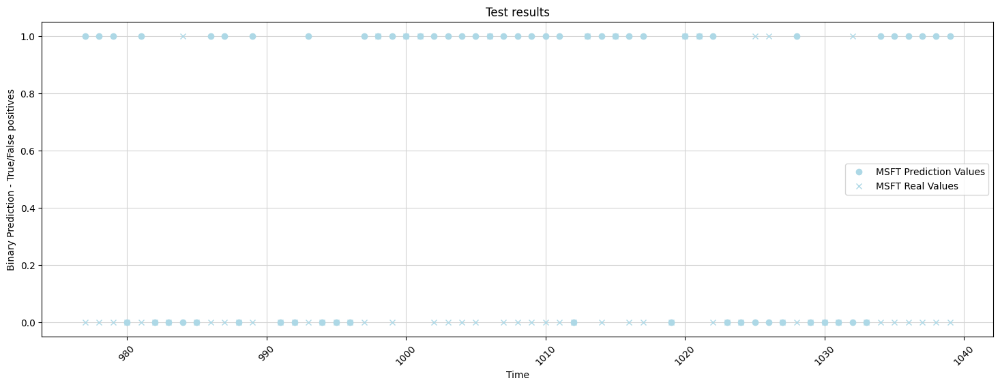

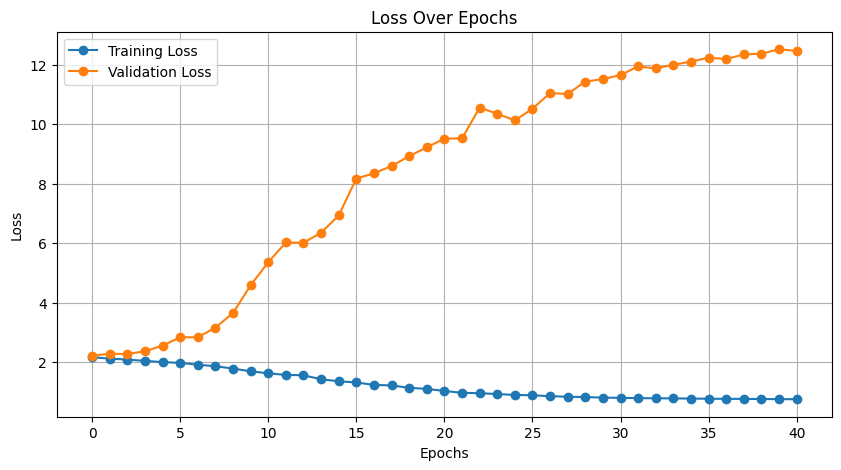

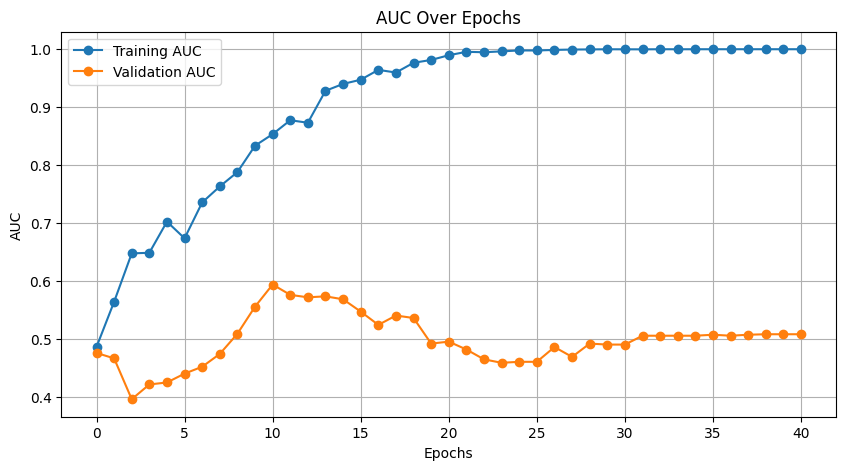



print_and_save_for
ticker data: MSFT


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
3         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
956        High-Low-Ratio  High-Open-Ratio  Close-O...   
957        High-Low-Ratio  High-Open-Ratio  Close-O...   
958        High-Low-Ratio  High-Open-Ratio  Close-O...   
959        High-Low-Ratio  High-Open-Ratio  Close-O...   
960        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2020-12-04 00:00:00-05:00       0       0         0.007663   
1    2020-12-07 00:00:00-05:00       0       0         0.007663   
2    2020-12-08 00:00:00-05:00       0     

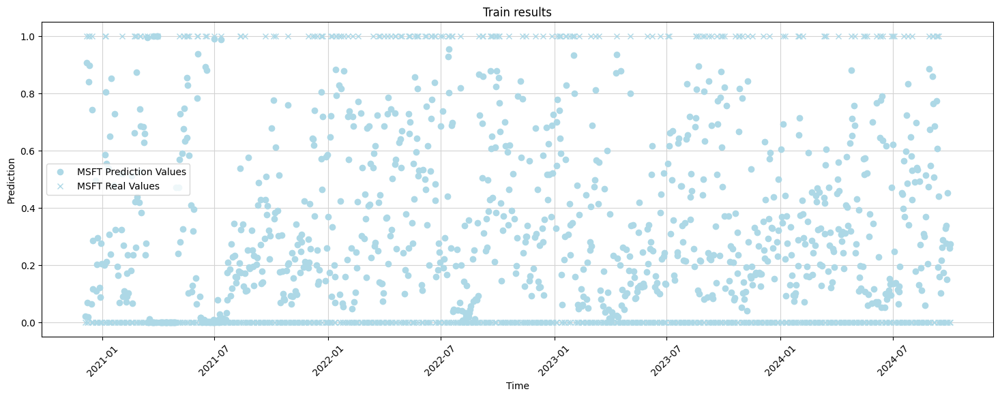

DONE PLOTTING 




print_and_save_for
ticker data: MSFT


Here is the data:                                                LstmData  \
961         High-Low-Ratio  High-Open-Ratio  Close-O...   
962         High-Low-Ratio  High-Open-Ratio  Close-O...   
963         High-Low-Ratio  High-Open-Ratio  Close-O...   
964         High-Low-Ratio  High-Open-Ratio  Close-O...   
965         High-Low-Ratio  High-Open-Ratio  Close-O...   
...                                                 ...   
1019        High-Low-Ratio  High-Open-Ratio  Close-O...   
1020        High-Low-Ratio  High-Open-Ratio  Close-O...   
1021        High-Low-Ratio  High-Open-Ratio  Close-O...   
1022        High-Low-Ratio  High-Open-Ratio  Close-O...   
1023        High-Low-Ratio  High-Open-Ratio  Close-O...   

                           Date  Ticker  Sector  Target-20D-Mean  \
961   2024-10-02 00:00:00-04:00       0       0         0.007663   
962   2024-10-03 00:00:00-04:00       0       0         0.007663   
963   2024-

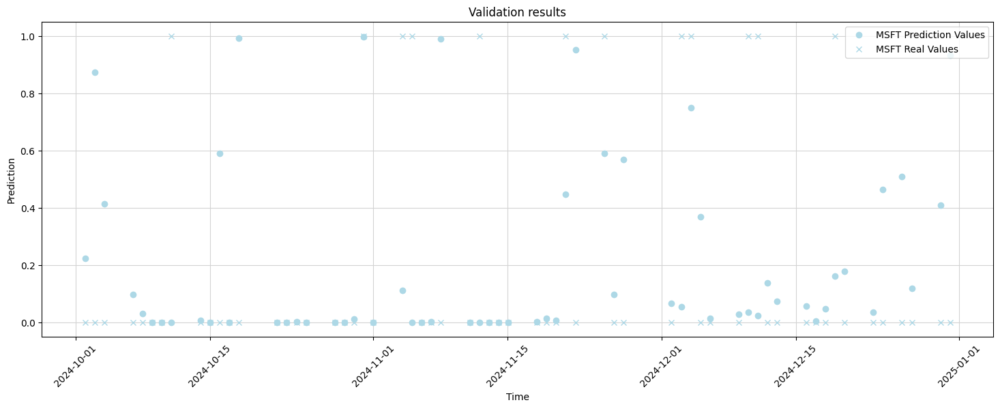

DONE PLOTTING 




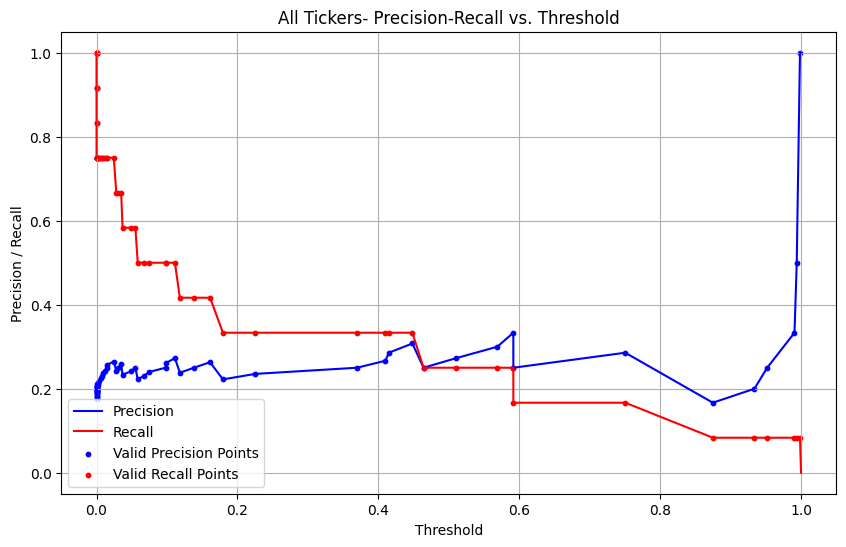

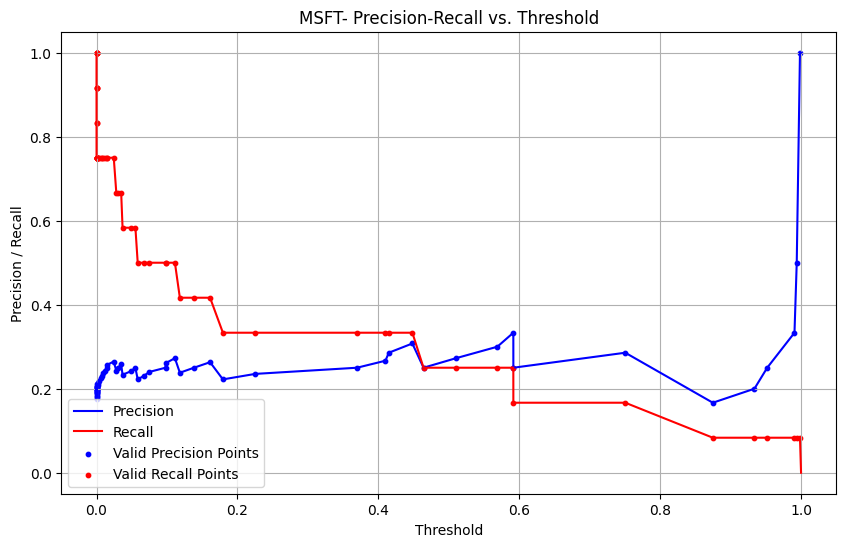

[0.         0.         0.         0.00133156 0.00133156 0.00266312
 0.00266312 0.00399467 0.00399467 0.00532623 0.00532623 0.00665779
 0.00665779 0.00798935 0.00798935 0.00932091 0.00932091 0.01065246
 0.01065246 0.0159787  0.0159787  0.01731025 0.01731025 0.01997337
 0.01997337 0.02263648 0.02263648 0.0252996  0.0252996  0.03062583
 0.03062583 0.03195739 0.03195739 0.03328895 0.03328895 0.03595206
 0.03595206 0.03861518 0.03861518 0.03994674 0.03994674 0.04260985
 0.04260985 0.04394141 0.04394141 0.05193076 0.05193076 0.05459387
 0.05459387 0.05592543 0.05592543 0.05725699 0.05725699 0.05858855
 0.05858855 0.06524634 0.06524634 0.0665779  0.0665779  0.06790945
 0.06790945 0.07057257 0.07057257 0.07989348 0.07989348 0.08255659
 0.08255659 0.08521971 0.08521971 0.08788282 0.08788282 0.08921438
 0.08921438 0.09054594 0.09054594 0.09853529 0.09853529 0.10252996
 0.10252996 0.10918775 0.10918775 0.11051931 0.11051931 0.11185087
 0.11185087 0.11318242 0.11318242 0.11451398 0.11451398 0.1225

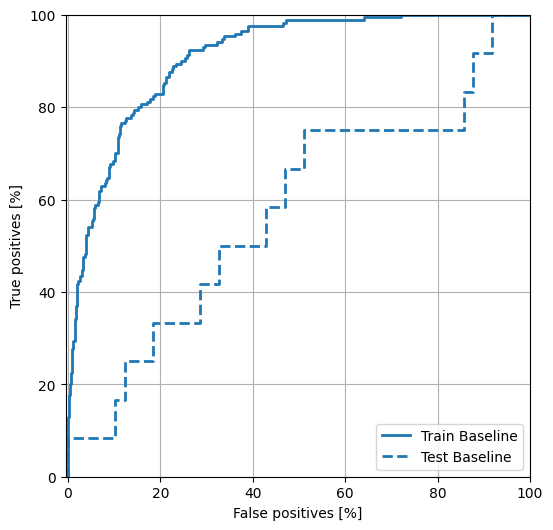

Best threshold: 0.4483148753643036
Number of true positives for the given ticker: 3
Number of false positives for the given ticker: 9
Precision score: 0.25
Recall score: 0.25
Random guess score: 0.19672131147540983
true-positive per ticker: Orig_Ticker
MSFT    3
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
MSFT    9
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
MSFT    9
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
MSFT    0.25
dtype: float64
recall per ticker: Orig_Ticker
MSFT    0.25
dtype: float64
rand guess per ticker: Orig_Ticker
MSFT    0.196721
dtype: float64
Some true positives
                           Date Orig_Ticker  y-predict-original  \
982   2024-10-31 00:00:00-04:00        MSFT            0.998472   
999   2024-11-25 00:00:00-05:00        MSFT            0.591623   
1005  2024-12-04 00:00:00-05:00        MSFT            0.750527   

      y-value-original  Target-20D-Mean  Target-20D-Sigma 

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1
 1 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 1]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 0 0 0 0 1 0 0 0 0 0 0 1 0
 1 0 0 0 1 1 0 0 0 1 1 0 0 0 0 0 1 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = validatio

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['MSFT'] UNDERLYING_TARGET: Next-Day-High-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:65 mode: complex LR_RATE: 0.0001 STARTING_LR: 0.001
fetch_finance_data_for_tickers: just returning file name: MSFT for interval: 5y
object


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode complex is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode complex is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(
/Users/rifatordulu/Developer/lstm-stock-price-prediction/helpers/data_manipulator.py:135: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  data["Date"] = pd.to_datetime(data["Date"], errors="raise")
/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names,

{'MSFT': 0}
{'Tech': 0}
size before sigma app: 993 for ticker: MSFT mean: 0.007663059582669173, sigma: 0.0063979407067922085 upper_bound: 0.026856881703045798 lower_bound: -0.011530762537707451
size after sigma app: 953 for ticker: MSFT
0      0.0
1      0.0
2      0.0
4      0.0
6      0.0
      ... 
924    0.0
925    0.0
926    0.0
927    0.0
928    0.0
Name: y-value, Length: 891, dtype: float64
0      0.0
1      0.0
2      0.0
4      0.0
6      0.0
      ... 
924    0.0
925    0.0
926    0.0
927    0.0
928    0.0
Name: y-value-original, Length: 891, dtype: float64
High-Low-Ratio                               0.600427
High-Open-Ratio                              0.536376
Close-Open-Ratio                             0.473355
Close-Prev-Close                             0.510037
MACD-Prev-MACD                               0.263661
200D-Ratio                                   0.430369
MACD_SIG                                     0.962874
MFI3                                         0.3

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 65, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_144 (Conv1D) │ (None, 63, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_221 (PReLU) │ (None, 63, 256)   │        256 │ conv1d_144[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_145 (Conv1D) │ (None, 31, 256)   │    196,864 │ p_re_lu_221[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_222 (PReLU) │ (None, 31, 256)   │        256 │ conv1d_145[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_146 (Conv1D) │ (None, 15, 512)   │    393,728 │ p_re_lu_222[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_223 (PReLU) │ (None, 15, 512)   │        512 │ conv1d_146[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_147 (Conv1D) │ (None, 7, 512)    │    786,944 │ p_re_lu_223[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_224 (PReLU) │ (None, 7, 512)    │        512 │ conv1d_147[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_148 (Conv1D) │ (None, 3, 1024)   │  1,573,888 │ p_re_lu_224[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_225 (PReLU) │ (None, 3, 1024)   │      1,024 │ conv1d_148[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_149 (Conv1D) │ (None, 1, 1024)   │  3,146,752 │ p_re_lu_225[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_226 (PReLU) │ (None, 1, 1024)   │      1,024 │ conv1d_149[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_58          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_58          │ (None, 1024)      │          0 │ p_re_lu_226[0][0] │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_58[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_59          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                 

 Total params: 10,844,140 (41.37 MB)

 Trainable params: 10,844,140 (41.37 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
7/7 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - AUC: 0.4618 - Precision: 0.1899 - Recall: 0.8764 - all_positives: 23.8821 - f1_score_metric: 36.3197 - loss: 1.7368 - precision_with_threshold_fixed: 3.0893 - recall_mul_prediction: 2622.4255 - recall_with_threshold_fixed: 19.7714 - true_positives: 2622.4253 - val_AUC: 0.4218 - val_Precision: 0.2000 - val_Recall: 0.4167 - val_all_positives: 12.0000 - val_f1_score_metric: 16.2162 - val_loss: 1.5743 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 300.0000 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 300.0000 - learning_rate: 0.0010
Epoch 2/400
7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - AUC: 0.4789 - Precision: 0.1834 - Recall: 0.9251 - all_positives: 23.5321 - f1_score_metric: 39.0451 - loss: 1.5078 - precision_with_threshold_fixed: 1.2143 - recall_mul_prediction: 2770.9819 - recall_with_threshold_fixed: 0.0357 - true_positives: 2770.9819 - val_AUC: 0.4855 - val_Precision: 0.1667 - val_Reca

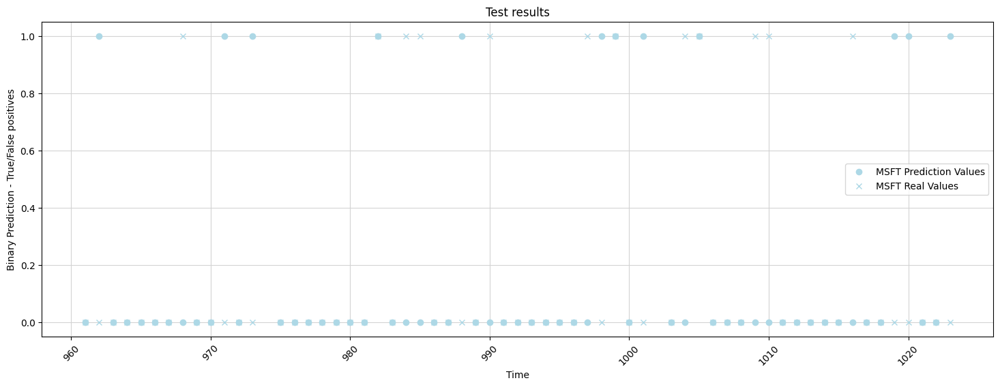

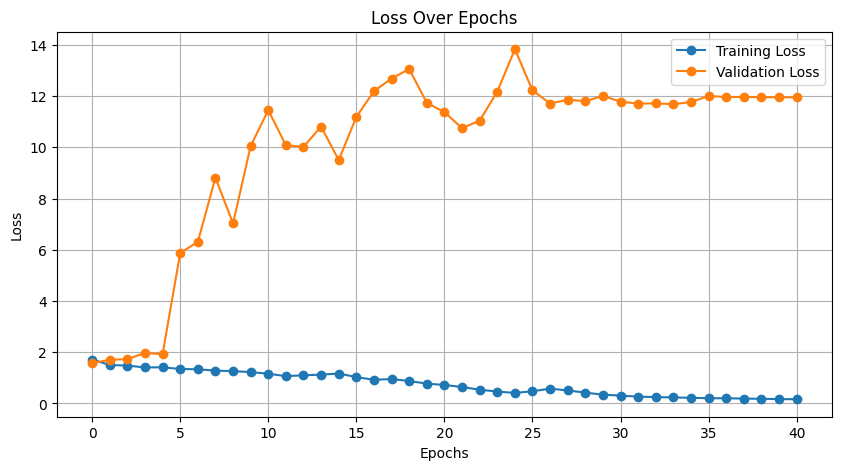

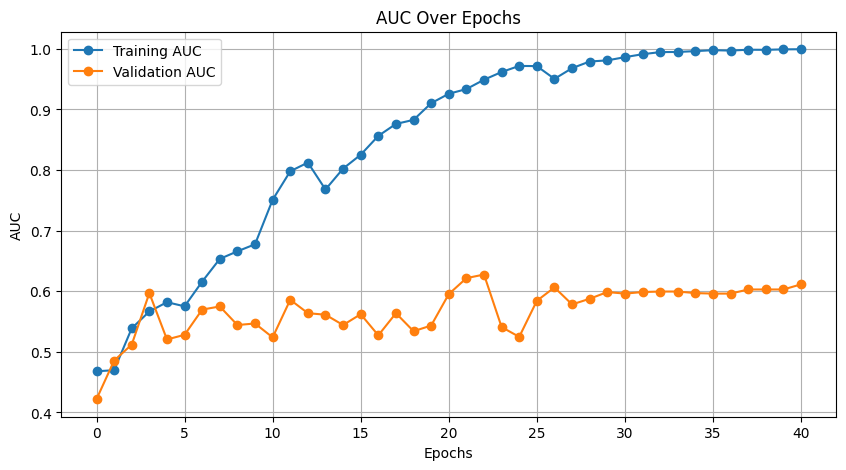



print_and_save_for
ticker data: MSFT


Here is the data:                                               LstmData  \
0         High-Low-Ratio  High-Open-Ratio  Close-Op...   
1         High-Low-Ratio  High-Open-Ratio  Close-Op...   
2         High-Low-Ratio  High-Open-Ratio  Close-Op...   
4         High-Low-Ratio  High-Open-Ratio  Close-Op...   
6         High-Low-Ratio  High-Open-Ratio  Close-Op...   
..                                                 ...   
924        High-Low-Ratio  High-Open-Ratio  Close-O...   
925        High-Low-Ratio  High-Open-Ratio  Close-O...   
926        High-Low-Ratio  High-Open-Ratio  Close-O...   
927        High-Low-Ratio  High-Open-Ratio  Close-O...   
928        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
0    2021-01-22 00:00:00-05:00       0       0         0.007663   
1    2021-01-25 00:00:00-05:00       0       0         0.007663   
2    2021-01-26 00:00:00-05:00       0     

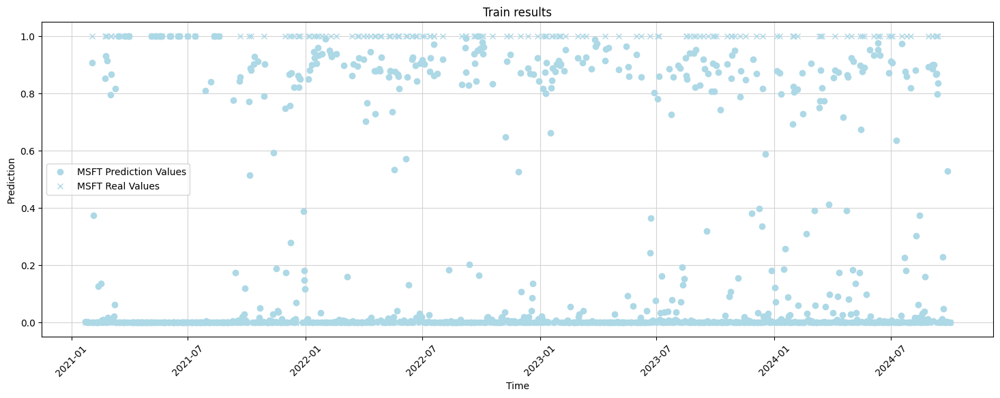

DONE PLOTTING 




print_and_save_for
ticker data: MSFT


Here is the data:                                               LstmData  \
929        High-Low-Ratio  High-Open-Ratio  Close-O...   
930        High-Low-Ratio  High-Open-Ratio  Close-O...   
931        High-Low-Ratio  High-Open-Ratio  Close-O...   
932        High-Low-Ratio  High-Open-Ratio  Close-O...   
933        High-Low-Ratio  High-Open-Ratio  Close-O...   
..                                                 ...   
987        High-Low-Ratio  High-Open-Ratio  Close-O...   
988        High-Low-Ratio  High-Open-Ratio  Close-O...   
989        High-Low-Ratio  High-Open-Ratio  Close-O...   
990        High-Low-Ratio  High-Open-Ratio  Close-O...   
991        High-Low-Ratio  High-Open-Ratio  Close-O...   

                          Date  Ticker  Sector  Target-20D-Mean  \
929  2024-10-02 00:00:00-04:00       0       0         0.007663   
930  2024-10-03 00:00:00-04:00       0       0         0.007663   
931  2024-10-04 00:00:00-0

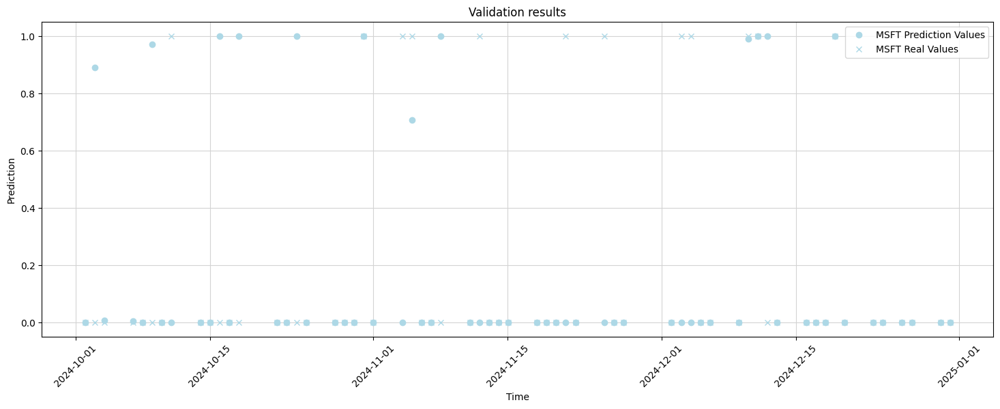

DONE PLOTTING 




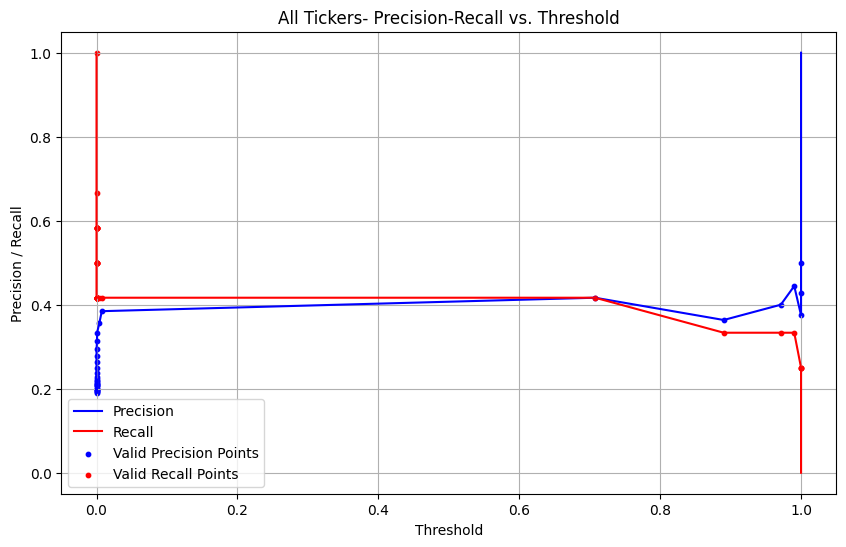

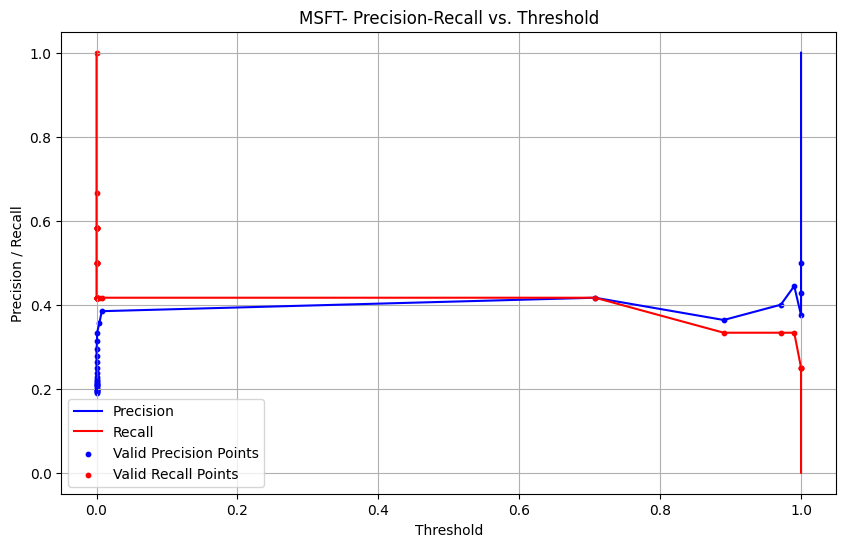

[0.         0.         0.         0.00137552 0.00137552 0.00275103
 0.00275103 0.00412655 0.00412655 0.00825309 0.00825309 0.01100413
 0.01100413 0.01237964 0.01237964 0.01513067 0.01513067 0.01650619
 0.01650619 0.01925722 0.01925722 0.02063274 0.02063274 0.02200825
 0.02200825 0.02338377 0.02338377 0.02475928 0.02475928 0.0261348
 0.0261348  0.03026135 0.03026135 0.03301238 0.03301238 0.0343879
 0.0343879  0.03576341 0.03576341 0.03713893 0.03713893 0.03851444
 0.03851444 0.03988996 0.03988996 0.04126547 0.04126547 0.04676754
 0.04676754 0.04814305 0.04814305 0.04951857 0.04951857 0.0522696
 0.0522696  0.05639615 0.05639615 0.05777166 0.05777166 0.0605227
 0.0605227  0.06189821 0.06189821 0.06327373 0.06327373 0.06464924
 0.06464924 0.06877579 0.06877579 0.07290234 0.07290234 0.07427785
 0.07427785 0.07565337 0.07565337 0.07702889 0.07702889 0.0784044
 0.0784044  0.07977992 0.07977992 0.08115543 0.08115543 0.08390646
 0.08390646 0.08803301 0.08803301 0.08940853 0.08940853 0.09903714


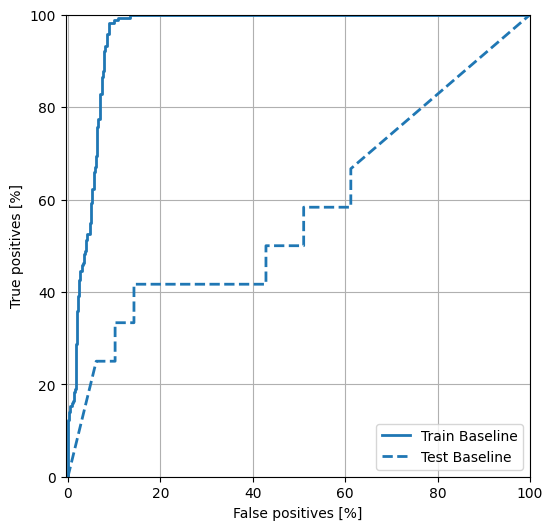

Best threshold: 0.7077199220657349
Number of true positives for the given ticker: 4
Number of false positives for the given ticker: 7
Precision score: 0.36363636363636365
Recall score: 0.3333333333333333
Random guess score: 0.19672131147540983
true-positive per ticker: Orig_Ticker
MSFT    4
Name: true-positive, dtype: int64
false-positive per ticker: Orig_Ticker
MSFT    7
Name: false-positive, dtype: int64
false-negative per ticker: Orig_Ticker
MSFT    8
Name: false-negative, dtype: int64
precision per ticker: Orig_Ticker
MSFT    0.363636
dtype: float64
recall per ticker: Orig_Ticker
MSFT    0.333333
dtype: float64
rand guess per ticker: Orig_Ticker
MSFT    0.196721
dtype: float64
Some true positives
                          Date Orig_Ticker  y-predict-original  \
977  2024-12-10 00:00:00-05:00        MSFT             0.99033   
984  2024-12-19 00:00:00-05:00        MSFT             1.00000   
950  2024-10-31 00:00:00-04:00        MSFT             1.00000   
978  2024-12-11 00:00:00-0

/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 1 0 0 0 1 0 0 0 0 1 0 1 0 0 1 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 1 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-predict-binary'] = validation_data['y-predict-original'].apply(lambda x: 1 if x > val else 0)
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/2636062565.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 0 0 0 0 1 0 0 0 0 0 0 1 0
 1 0 0 0 1 1 0 0 0 1 1 0 0 0 0 0 1 0 0 0 0 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  validation_data.loc[:,'y-value-binary'] = validatio

Executing Eagerly?: True




 OPTUNA WILL EXECUTE FOR STOCKS: ['AVGO'] UNDERLYING_TARGET: Next-Day-Close-To-Next-Day-Open-Ratio NETWORK:cnn SEQ_LEN:17 mode: simple LR_RATE: 0.001 STARTING_LR: 1e-05
fetch_finance_data_for_tickers: just returning file name: AVGO for interval: 5y


/Users/rifatordulu/python_3_11/lib/python3.11/site-packages/keras/src/callbacks/reduce_lr_on_plateau.py:80: UserWarning: Learning rate reduction mode simple is unknown, fallback to auto mode.
  self._reset()
/var/folders/1n/8vt634f15059yz_p3_whxnk80000gn/T/ipykernel_18213/1120554037.py:43: UserWarning: EarlyStopping mode simple is unknown, fallback to auto mode.
  early_stopping = EarlyStopping(


object


...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm-values         │ (None, 17, 25)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_150 (Conv1D) │ (None, 15, 256)   │     19,456 │ lstm-values[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_230 (PReLU) │ (None, 15, 256)   │        256 │ conv1d_150[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_151 (Conv1D) │ (None, 7, 256)    │    196,864 │ p_re_lu_230[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_231 (PReLU) │ (None, 7, 256)    │        256 │ conv1d_151[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_152 (Conv1D) │ (None, 3, 512)    │    393,728 │ p_re_lu_231[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_232 (PReLU) │ (None, 3, 512)    │        512 │ conv1d_152[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_153 (Conv1D) │ (None, 1, 512)    │    786,944 │ p_re_lu_232[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_embedding     │ (None, 1, 512)    │        512 │ stock_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_233 (PReLU) │ (None, 1, 512)    │        512 │ conv1d_153[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_60          │ (None, 512)       │          0 │ stock_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_embedding    │ (None, 1, 128)    │        128 │ sector_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_60          │ (None, 512)       │          0 │ p_re_lu_233[0][0] │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stock_dense (Dense) │ (None, 512)       │    262,656 │ reshape_60[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_61          │ (None, 128)       │          0 │ sector_embedding… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_60      │ (None, 1024)      │          0 │ flatten_60[0][0], │
│ (Concatenate)       │                   │            │ stock_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sector_dense        │ (None, 256)       │     33,024 │ reshape_61[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_61      │ (None, 1280)      │          0 │ concatenate_60[0

 Total params: 2,247,451 (8.57 MB)

 Trainable params: 2,247,451 (8.57 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - AUC: 0.4613 - Precision: 0.1758 - Recall: 0.8256 - all_positives: 21.8870 - f1_score_metric: 35.9545 - loss: 2.4274 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2254.6543 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2254.6543 - val_AUC: 0.4182 - val_Precision: 0.1452 - val_Recall: 1.0000 - val_all_positives: 9.0000 - val_f1_score_metric: 15.7183 - val_loss: 2.3362 - val_precision_with_threshold_fixed: 0.0000e+00 - val_recall_mul_prediction: 558.0000 - val_recall_with_threshold_fixed: 0.0000e+00 - val_true_positives: 558.0000 - learning_rate: 1.0000e-05
Epoch 2/400
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 546ms/step - AUC: 0.5126 - Precision: 0.1672 - Recall: 0.9104 - all_positives: 22.0389 - f1_score_metric: 37.0604 - loss: 2.4271 - precision_with_threshold_fixed: 0.0000e+00 - recall_mul_prediction: 2651.8484 - recall_with_threshold_fixed: 0.0000e+00 - true_positives: 2651.8481 - val_AUC: 0.4214 - val_Precisi

In [ ]:
import itertools

study = optuna.create_study(direction="maximize")

# if do_stock_by_stock:
#     for ss, uu in itertools.product(stocks, target_options):
#         study.optimize(lambda trial: objective(trial, ss, uu), n_trials=20)
#         print(f"Stock: {ss}, Target: {uu}, best parameters: {study.best_params}, val_AUC: {study.best_value}")
#         for trial in study.trials:
#             print(f"Trial {trial.number}: {trial.params}, {save_best_metric}: {trial.value}")
# else:
#     # Run trials for every possible combination
#     for uu in target_options:
#         study.optimize(lambda trial: objective(trial, None, uu), n_trials=20)
#         print(f"Best parameters: {study.best_params}, val_loss: {study.best_value}")
#         for trial in study.trials:
#             print(f"Trial {trial.number}: {trial.params}, {save_best_metric}: {trial.value}")

if do_stock_by_stock:
    # Run trials for every possible combination
    for ss, uu, mode in itertools.product(stocks, target_options, modes):
        study.enqueue_trial({"Stock": ss, "Underlying_target": uu, "mode": mode})
    
    study.optimize(objective, n_trials=len(stocks) * len(target_options) * len(modes))
else:
    # Run trials for every possible combination
    for uu, mode in itertools.product(target_options, modes):
        study.enqueue_trial({"Underlying_target": uu, "mode": mode})
    
    study.optimize(objective, len(target_options))

trial = study.best_trial

print("Accuracy: {}".format(trial.value))
print("Best hyperparameters: {}".format(trial.params))

In [ ]:
study.storage = optuna.storages.RDBStorage("sqlite:///optuna-results.db")

#### Performance Evaluation

### LET'S TRY THIS ON THE TEST DATA NOW

### SANITATION: